In [1]:
# ============================================================
# CELLULE 1 — CONFIGURATION DU PROJET ViTOutdoorLoc
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import torch

# ------------------------------------------------------------
# 1. Reproductibilité des expériences
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# 2. Chemin racine du dataset UAVLoc-M3
# ------------------------------------------------------------

DATASET_ROOT = (
    "/kaggle/input/datasets/maissawahbi/"
    "uavloc-m3-dataset/UAVLoc-M3_dataset"
)

# ------------------------------------------------------------
# 3. Définition des trois régions
# ------------------------------------------------------------

REGIONS = [
    "AnYangRiver",
    "Chongmingdao",
    "CuiJiaQiao"
]

# ------------------------------------------------------------
# 4. Configuration de l'expérience
# ------------------------------------------------------------

DATA_FRACTION = 0.30  # Utiliser 30 % de chaque région
TRAIN_FRACTION = 0.70 # 70 % du sous-ensemble pour l'entraînement
VAL_FRACTION = 0.15   # 15 % pour la validation
TEST_FRACTION = 0.15  # 15 % pour le test

EPOCHS = 5            # Première expérience courte
BATCH_SIZE = 8        # Départ prudent pour une GPU Kaggle
IMAGE_SIZE = 224      # Taille attendue par le ViT
NUM_TARGETS = 7       # Position et orientation du drone

# ------------------------------------------------------------
# 5. Choisir le périphérique de calcul
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 65)
print("CONFIGURATION ViTOutdoorLoc")
print("=" * 65)

print("Racine du dataset :", DATASET_ROOT)
print("GPU disponible :", torch.cuda.is_available())
print("Périphérique :", DEVICE)

if torch.cuda.is_available():
    print("GPU utilisé :", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# 6. Vérifier les fichiers des trois régions
# ------------------------------------------------------------

if not os.path.isdir(DATASET_ROOT):
    raise FileNotFoundError(
        f"Dataset introuvable : {DATASET_ROOT}"
    )

for region in REGIONS:

    region_path = os.path.join(DATASET_ROOT, region)

    print(f"\n--- {region} ---")

    if not os.path.isdir(region_path):
        print("ERREUR : dossier de région absent.")
        continue

    # Fichier Excel principal contenant les annotations.
    excel_path = os.path.join(
        region_path, f"{region}.xlsx"
    )

    print("Excel principal présent :", os.path.isfile(excel_path))

    # Dossier des images drone.
    drone_dir = os.path.join(region_path, "drone")
    print("Dossier drone présent :", os.path.isdir(drone_dir))

    # Dossier des images satellite.
    satellite_dir = os.path.join(region_path, "satellite")
    print(
        "Dossier satellite présent :",
        os.path.isdir(satellite_dir)
    )

    # Dossier contenant les données de relief.
    dem_dir = os.path.join(region_path, "dem")
    print("Dossier DEM présent :", os.path.isdir(dem_dir))

    # Fichiers auxiliaires éventuels.
    for filename in [
        "location_with_dem.xlsx",
        "pxGT_dem.xlsx"
    ]:
        path = os.path.join(region_path, filename)
        print(f"{filename} présent :", os.path.isfile(path))

print("\nConfiguration terminée.")
print("Aucun entraînement lancé.")

CONFIGURATION ViTOutdoorLoc
Racine du dataset : /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset
GPU disponible : True
Périphérique : cuda
GPU utilisé : Tesla T4

--- AnYangRiver ---
Excel principal présent : True
Dossier drone présent : True
Dossier satellite présent : True
Dossier DEM présent : True
location_with_dem.xlsx présent : True
pxGT_dem.xlsx présent : True

--- Chongmingdao ---
Excel principal présent : True
Dossier drone présent : True
Dossier satellite présent : True
Dossier DEM présent : True
location_with_dem.xlsx présent : True
pxGT_dem.xlsx présent : True

--- CuiJiaQiao ---
Excel principal présent : True
Dossier drone présent : True
Dossier satellite présent : True
Dossier DEM présent : True
location_with_dem.xlsx présent : True
pxGT_dem.xlsx présent : True

Configuration terminée.
Aucun entraînement lancé.


In [2]:
# ============================================================
# CELLULE 2 — AUDIT DES ANNOTATIONS PAR RÉGION
# ============================================================

import os
import pandas as pd

for region in REGIONS:
    print("\n" + "=" * 75)
    print(f"RÉGION : {region}")
    print("=" * 75)

    region_path = os.path.join(DATASET_ROOT, region)

    # Lire les fichiers Excel disponibles
    excel_files = {
        "principal": os.path.join(region_path, f"{region}.xlsx"),
        "location_with_dem": os.path.join(region_path, "location_with_dem.xlsx"),
        "pxGT_dem": os.path.join(region_path, "pxGT_dem.xlsx"),
    }

    for nom, chemin in excel_files.items():
        if not os.path.isfile(chemin):
            print(f"\n{nom} : fichier absent")
            continue

        try:
            df = pd.read_excel(chemin)

            print(f"\n--- {nom} ---")
            print("Dimensions :", df.shape)
            print("Colonnes :", df.columns.tolist())
            print("\nPremières lignes :")
            display(df.head(3))

        except Exception as e:
            print(f"Erreur de lecture de {nom} : {e}")


RÉGION : AnYangRiver

--- principal ---
Dimensions : (645, 7)
Colonnes : ['id', 'lon', 'lat', 'GPS_Alt', 'roll', 'pitch', 'yaw']

Premières lignes :


,id,lon,lat,GPS_Alt,roll,pitch,yaw
0,DSC07012,113.905815,36.057264,884.1,3.2,-1.3,-177.3
1,DSC07013,113.905607,36.056112,881.8,-29.1,-0.8,142.4
2,DSC07014,113.906665,36.055315,884.5,2.9,-3.1,102.4



--- location_with_dem ---
Dimensions : (645, 4)
Colonnes : ['id', 'target_lon', 'target_lat', 'relative_altitude']

Premières lignes :


,id,target_lon,target_lat,relative_altitude
0,DSC07012,113.906128,36.057354,613.1
1,DSC07013,113.903145,36.054657,609.8
2,DSC07014,113.906434,36.055587,612.5



--- pxGT_dem ---
Dimensions : (645, 3)
Colonnes : ['id', 'pixel_x', 'pixel_y']

Premières lignes :


,id,pixel_x,pixel_y
0,DSC07012,9716,10821
1,DSC07013,9438,11132
2,DSC07014,9744,11025


... (8 outputs left out)


--- location_with_dem ---
Dimensions : (607, 4)
Colonnes : ['id', 'target_lon', 'target_lat', 'relative_altitude']

Premières lignes :


,id,target_lon,target_lat,relative_altitude
0,DSC00472,114.431137,36.105028,801
1,DSC00473,114.434665,36.104992,800
2,DSC00474,114.437547,36.105033,803



--- pxGT_dem ---
Dimensions : (607, 3)
Colonnes : ['id', 'pixel_x', 'pixel_y']

Premières lignes :


,id,pixel_x,pixel_y
0,DSC00472,1818,7372
1,DSC00473,2147,7376
2,DSC00474,2416,7371


In [3]:
# ============================================================
# CELLULE 3 — COMPARAISON DES FICHIERS EXCEL
# ============================================================

import os
import pandas as pd

fichiers = [
    ("principal", lambda r: os.path.join(DATASET_ROOT, r, f"{r}.xlsx")),
    ("location_with_dem", lambda r: os.path.join(DATASET_ROOT, r, "location_with_dem.xlsx")),
    ("pxGT_dem", lambda r: os.path.join(DATASET_ROOT, r, "pxGT_dem.xlsx")),
]

for region in REGIONS:
    print("\n" + "=" * 80)
    print(f"RÉGION : {region}")
    print("=" * 80)

    for nom, chemin_fn in fichiers:
        chemin = chemin_fn(region)

        if not os.path.isfile(chemin):
            print(f"\n{nom} : fichier introuvable")
            continue

        try:
            df = pd.read_excel(chemin)

            print(f"\n[{nom}]")
            print(f"Dimensions : {df.shape}")
            print("Colonnes :", df.columns.tolist())
            print("Exemples :")
            display(df.head(2))

        except Exception as e:
            print(f"Erreur de lecture : {e}")


RÉGION : AnYangRiver

[principal]
Dimensions : (645, 7)
Colonnes : ['id', 'lon', 'lat', 'GPS_Alt', 'roll', 'pitch', 'yaw']
Exemples :


,id,lon,lat,GPS_Alt,roll,pitch,yaw
0,DSC07012,113.905815,36.057264,884.1,3.2,-1.3,-177.3
1,DSC07013,113.905607,36.056112,881.8,-29.1,-0.8,142.4



[location_with_dem]
Dimensions : (645, 4)
Colonnes : ['id', 'target_lon', 'target_lat', 'relative_altitude']
Exemples :


,id,target_lon,target_lat,relative_altitude
0,DSC07012,113.906128,36.057354,613.1
1,DSC07013,113.903145,36.054657,609.8



[pxGT_dem]
Dimensions : (645, 3)
Colonnes : ['id', 'pixel_x', 'pixel_y']
Exemples :


,id,pixel_x,pixel_y
0,DSC07012,9716,10821
1,DSC07013,9438,11132


... (8 outputs left out)


[location_with_dem]
Dimensions : (607, 4)
Colonnes : ['id', 'target_lon', 'target_lat', 'relative_altitude']
Exemples :


,id,target_lon,target_lat,relative_altitude
0,DSC00472,114.431137,36.105028,801
1,DSC00473,114.434665,36.104992,800



[pxGT_dem]
Dimensions : (607, 3)
Colonnes : ['id', 'pixel_x', 'pixel_y']
Exemples :


,id,pixel_x,pixel_y
0,DSC00472,1818,7372
1,DSC00473,2147,7376


In [4]:
# ============================================================
# CELLULE 4 — CONTRÔLE DES DONNÉES ET DES IDENTIFIANTS
# ============================================================

import os
import numpy as np
import pandas as pd

for region in REGIONS:
    print("\n" + "=" * 75)
    print(f"RÉGION : {region}")
    print("=" * 75)

    base = os.path.join(DATASET_ROOT, region)

    df_main = pd.read_excel(os.path.join(base, f"{region}.xlsx"))
    df_loc  = pd.read_excel(os.path.join(base, "location_with_dem.xlsx"))
    df_px   = pd.read_excel(os.path.join(base, "pxGT_dem.xlsx"))

    # Nettoyer uniquement les espaces éventuels dans les identifiants
    for df in (df_main, df_loc, df_px):
        df["id"] = df["id"].astype("string").str.strip()

    # 1. Contrôle des identifiants
    ids_main = set(df_main["id"].dropna())
    ids_loc  = set(df_loc["id"].dropna())
    ids_px   = set(df_px["id"].dropna())

    print("\n[Identifiants]")
    print("Principal : lignes =", len(df_main),
          "| identifiants uniques =", df_main["id"].nunique())
    print("Location  : lignes =", len(df_loc),
          "| identifiants uniques =", df_loc["id"].nunique())
    print("Pixels    : lignes =", len(df_px),
          "| identifiants uniques =", df_px["id"].nunique())
    print("IDs communs aux 3 fichiers :", len(ids_main & ids_loc & ids_px))
    print("IDs absents de location :", len(ids_main - ids_loc))
    print("IDs absents de pxGT_dem :", len(ids_main - ids_px))

    # 2. Fusion par identifiant, sans supposer l'ordre des lignes
    df = (
        df_main.merge(df_loc, on="id", how="left",
                      validate="one_to_one")
               .merge(df_px, on="id", how="left",
                      validate="one_to_one")
    )

    # 3. Vérifier les valeurs numériques
    colonnes = [
        "lon", "lat", "GPS_Alt", "roll", "pitch", "yaw",
        "target_lon", "target_lat", "relative_altitude",
        "pixel_x", "pixel_y"
    ]

    print("\n[Valeurs manquantes]")
    for col in colonnes:
        if col in df.columns:
            vals = pd.to_numeric(df[col], errors="coerce")
            print(f"{col:20s}: {vals.isna().sum()} manquantes")

    # 4. Résumé des plages numériques
    print("\n[Plages numériques]")
    for col in colonnes:
        if col in df.columns:
            vals = pd.to_numeric(df[col], errors="coerce")
            print(
                f"{col:20s}: min={vals.min():.6f} | "
                f"max={vals.max():.6f}"
                if vals.notna().any()
                else f"{col:20s}: aucune valeur numérique valide"
            )

    # 5. Différence horizontale entre position GPS et cible
    # Approximation locale en mètres, suffisante pour un diagnostic.
    lat_mid = np.deg2rad(
        (pd.to_numeric(df["lat"], errors="coerce") +
         pd.to_numeric(df["target_lat"], errors="coerce")) / 2
    )
    dlat = (
        pd.to_numeric(df["target_lat"], errors="coerce") -
        pd.to_numeric(df["lat"], errors="coerce")
    )
    dlon = (
        pd.to_numeric(df["target_lon"], errors="coerce") -
        pd.to_numeric(df["lon"], errors="coerce")
    )

    dx = 111320 * np.cos(lat_mid) * dlon
    dy = 111320 * dlat
    distance = np.sqrt(dx**2 + dy**2)

    print("\n[Distance GPS ↔ cible]")
    print(distance.describe(percentiles=[0.5, 0.9]).round(2))

    print("\nFusion terminée :", df.shape)


RÉGION : AnYangRiver

[Identifiants]
Principal : lignes = 645 | identifiants uniques = 645
Location  : lignes = 645 | identifiants uniques = 645
Pixels    : lignes = 645 | identifiants uniques = 645
IDs communs aux 3 fichiers : 645
IDs absents de location : 0
IDs absents de pxGT_dem : 0

[Valeurs manquantes]
lon                 : 0 manquantes
lat                 : 0 manquantes
GPS_Alt             : 0 manquantes
roll                : 0 manquantes
pitch               : 0 manquantes
yaw                 : 0 manquantes
target_lon          : 0 manquantes
target_lat          : 0 manquantes
relative_altitude   : 0 manquantes
pixel_x             : 0 manquantes
pixel_y             : 0 manquantes

[Plages numériques]
lon                 : min=113.818282 | max=113.920369
lat                 : min=36.050214 | max=36.138165
GPS_Alt             : min=879.200000 | max=886.900000
roll                : min=-32.500000 | max=35.600000
pitch               : min=-9.000000 | max=4.900000
yaw                

In [5]:
# ============================================================
# CELLULE 5 — AUDIT DES CARTES SATELLITE ET DES PIXELS
# ============================================================

import os
import numpy as np
import pandas as pd
from PIL import Image

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".tif", ".tiff")

for region in REGIONS:
    print("\n" + "=" * 75)
    print(f"RÉGION : {region}")
    print("=" * 75)

    base = os.path.join(DATASET_ROOT, region)
    satellite_dir = os.path.join(base, "satellite")

    df_px = pd.read_excel(os.path.join(base, "pxGT_dem.xlsx"))
    df_px["pixel_x"] = pd.to_numeric(df_px["pixel_x"], errors="coerce")
    df_px["pixel_y"] = pd.to_numeric(df_px["pixel_y"], errors="coerce")

    # Images satellite candidates
    image_paths = []
    for root, _, files in os.walk(satellite_dir):
        for filename in files:
            if filename.lower().endswith(IMAGE_EXTENSIONS):
                image_paths.append(os.path.join(root, filename))

    print("Nombre de fichiers image satellite :", len(image_paths))

    dimensions = []
    for path in sorted(image_paths):
        try:
            with Image.open(path) as im:
                width, height = im.size
            dimensions.append({
                "fichier": os.path.relpath(path, satellite_dir),
                "largeur": width,
                "hauteur": height
            })
        except Exception as e:
            print("Image illisible :", os.path.basename(path), "|", str(e)[:120])

    if not dimensions:
        print("Aucune image satellite lisible.")
        continue

    dims_df = pd.DataFrame(dimensions)
    display(dims_df)

    # Compter les pixels valides pour chaque image individuellement.
    # Un pixel dans les limites d'une image ne prouve pas que
    # cette image est la bonne tuile pour l'annotation.
    x = df_px["pixel_x"]
    y = df_px["pixel_y"]

    print("\nContrôle des limites pour chaque image :")
    for _, imrow in dims_df.iterrows():
        w, h = int(imrow["largeur"]), int(imrow["hauteur"])
        valid = (
            x.notna() & y.notna() &
            (x >= 0) & (x < w) &
            (y >= 0) & (y < h)
        )
        print(
            f"{imrow['fichier']}: "
            f"{valid.sum()}/{len(df_px)} pixels dans les limites "
            f"(dimensions {w}x{h})"
        )

    print("\nCoordonnées pixel hors valeurs non négatives :")
    print("pixel_x < 0 :", int((x < 0).sum()))
    print("pixel_y < 0 :", int((y < 0).sum()))


RÉGION : AnYangRiver
Nombre de fichiers image satellite : 1


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (160563200 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


,fichier,largeur,hauteur
0,AnYangRiver.jpg,12800,12544



Contrôle des limites pour chaque image :
AnYangRiver.jpg: 645/645 pixels dans les limites (dimensions 12800x12544)

Coordonnées pixel hors valeurs non négatives :
pixel_x < 0 : 0
pixel_y < 0 : 0

RÉGION : Chongmingdao
Nombre de fichiers image satellite : 11


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (125989255 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (154375034 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (110207740 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


,fichier,largeur,hauteur
0,"1497~1517,3459~3515,4986~5191.jpg",6955,7114
1,"1517~1653,3310~3459.jpg",10592,6836
2,"1653~1868,3094~3310.jpg",13283,9485
3,"1868~2091,2871~3094.jpg",14927,10342
4,"2090~2244,2714~2872.jpg",7628,10552
5,2244~2714.jpg,6515,16916
6,"3509~3664,4841~4993.jpg",10856,6552
7,"3663~3817,4692~4842.jpg",11261,5719
8,"3815~3972,4542~4694.jpg",12062,4663
9,"3972~4111,4406~4542.jpg",10379,5013



Contrôle des limites pour chaque image :
1497~1517,3459~3515,4986~5191.jpg: 2285/3695 pixels dans les limites (dimensions 6955x7114)
1517~1653,3310~3459.jpg: 2993/3695 pixels dans les limites (dimensions 10592x6836)
1653~1868,3094~3310.jpg: 3418/3695 pixels dans les limites (dimensions 13283x9485)
1868~2091,2871~3094.jpg: 3524/3695 pixels dans les limites (dimensions 14927x10342)
2090~2244,2714~2872.jpg: 2626/3695 pixels dans les limites (dimensions 7628x10552)
2244~2714.jpg: 2526/3695 pixels dans les limites (dimensions 6515x16916)
3509~3664,4841~4993.jpg: 2943/3695 pixels dans les limites (dimensions 10856x6552)
3663~3817,4692~4842.jpg: 2678/3695 pixels dans les limites (dimensions 11261x5719)
3815~3972,4542~4694.jpg: 2297/3695 pixels dans les limites (dimensions 12062x4663)
3972~4111,4406~4542.jpg: 2387/3695 pixels dans les limites (dimensions 10379x5013)
4111~4407.jpg: 3040/3695 pixels dans les limites (dimensions 10824x6984)

Coordonnées pixel hors valeurs non négatives :
pixel_x

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (132120576 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


,fichier,largeur,hauteur
0,CuiJiaQiao.jpg,16128,8192



Contrôle des limites pour chaque image :
CuiJiaQiao.jpg: 607/607 pixels dans les limites (dimensions 16128x8192)

Coordonnées pixel hors valeurs non négatives :
pixel_x < 0 : 0
pixel_y < 0 : 0


In [6]:
# ============================================================
# CELLULE 6 — AUDIT DES TUILES SATELLITE CHONGMINGDAO
# ============================================================

import os
import re
import pandas as pd

region = "Chongmingdao"
base = os.path.join(DATASET_ROOT, region)
satellite_dir = os.path.join(base, "satellite")

df_main = pd.read_excel(os.path.join(base, f"{region}.xlsx"))
df_px = pd.read_excel(os.path.join(base, "pxGT_dem.xlsx"))

df_main["id_num"] = (
    df_main["id"].astype(str)
    .str.extract(r"(\d+)$")[0]
)
df_main["id_num"] = pd.to_numeric(df_main["id_num"], errors="coerce")

print("Nombre d'annotations :", len(df_main))
print("Exemples d'identifiants :", df_main["id"].head(10).tolist())

print("\nFichiers satellite et plages d'identifiants reconnues :")

tile_info = []

for filename in sorted(os.listdir(satellite_dir)):
    if not filename.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff")):
        continue

    # Extraire toutes les plages numériques du nom du fichier.
    ranges = re.findall(r"(\d+)\s*~\s*(\d+)", filename)
    intervals = [(int(a), int(b)) for a, b in ranges]

    # Le nom peut contenir une ou plusieurs plages.
    if intervals:
        matched = df_main["id_num"].apply(
            lambda n: any(a <= n <= b for a, b in intervals)
            if pd.notna(n) else False
        )
        count = int(matched.sum())
    else:
        count = 0

    tile_info.append({
        "fichier": filename,
        "plages": intervals,
        "annotations_dans_plages": count
    })

display(pd.DataFrame(tile_info))

print("\nIdentifiants non couverts par les plages des noms :")
all_ranges = [
    interval
    for item in tile_info
    for interval in item["plages"]
]

def covered(n):
    return any(a <= n <= b for a, b in all_ranges) if pd.notna(n) else False

uncovered = df_main.loc[
    ~df_main["id_num"].apply(covered), "id"
]

print("Nombre :", len(uncovered))
print("Exemples :", uncovered.head(20).tolist())

Nombre d'annotations : 3695
Exemples d'identifiants : ['DSC01497', 'DSC01498', 'DSC01499', 'DSC01500', 'DSC01501', 'DSC01502', 'DSC01503', 'DSC01504', 'DSC01505', 'DSC01506']

Fichiers satellite et plages d'identifiants reconnues :


,fichier,plages,annotations_dans_plages
0,"1497~1517,3459~3515,4986~5191.jpg","[(1497, 1517), (3459, 3515), (4986, 5191)]",284
1,"1517~1653,3310~3459.jpg","[(1517, 1653), (3310, 3459)]",287
2,"1653~1868,3094~3310.jpg","[(1653, 1868), (3094, 3310)]",433
3,"1868~2091,2871~3094.jpg","[(1868, 2091), (2871, 3094)]",448
4,"2090~2244,2714~2872.jpg","[(2090, 2244), (2714, 2872)]",314
5,2244~2714.jpg,"[(2244, 2714)]",471
6,"3509~3664,4841~4993.jpg","[(3509, 3664), (4841, 4993)]",309
7,"3663~3817,4692~4842.jpg","[(3663, 3817), (4692, 4842)]",306
8,"3815~3972,4542~4694.jpg","[(3815, 3972), (4542, 4694)]",311
9,"3972~4111,4406~4542.jpg","[(3972, 4111), (4406, 4542)]",277



Identifiants non couverts par les plages des noms :
Nombre : 0
Exemples : []


In [7]:
# ============================================================
# CELLULE 7 — AMBIGUÏTÉS D'ASSOCIATION DES TUILES
# ============================================================

import os
import re
import pandas as pd

region = "Chongmingdao"
base = os.path.join(DATASET_ROOT, region)
satellite_dir = os.path.join(base, "satellite")

df_main = pd.read_excel(os.path.join(base, f"{region}.xlsx"))
df_main["id_num"] = pd.to_numeric(
    df_main["id"].astype(str).str.extract(r"(\d+)$")[0],
    errors="coerce"
)

tiles = []

for filename in sorted(os.listdir(satellite_dir)):
    if not filename.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff")):
        continue

    intervals = [
        (int(a), int(b))
        for a, b in re.findall(r"(\d+)\s*~\s*(\d+)", filename)
    ]

    for _, row in df_main.iterrows():
        n = row["id_num"]
        if pd.notna(n) and any(a <= n <= b for a, b in intervals):
            tiles.append({
                "id": row["id"],
                "id_num": int(n),
                "tuile": filename
            })

associations = pd.DataFrame(tiles)

counts = (
    associations.groupby("id")
    .agg(
        nombre_tuiles=("tuile", "nunique"),
        tuiles=("tuile", lambda s: list(s))
    )
    .reset_index()
)

print("Nombre total d'identifiants :", len(df_main))
print("Identifiants associés à au moins une tuile :",
      counts["id"].nunique())

print("\nRépartition du nombre de tuiles candidates :")
display(
    counts["nombre_tuiles"]
    .value_counts()
    .sort_index()
    .rename_axis("nombre_tuiles")
    .to_frame("nombre_identifiants")
)

ambigus = counts[counts["nombre_tuiles"] > 1]

print("\nIdentifiants candidats à plusieurs tuiles :", len(ambigus))
display(ambigus.head(20))

sans_tuile = df_main.loc[
    ~df_main["id"].isin(counts["id"]), ["id"]
]
print("\nIdentifiants sans tuile candidate :", len(sans_tuile))
display(sans_tuile.head(10))

Nombre total d'identifiants : 3695
Identifiants associés à au moins une tuile : 3695

Répartition du nombre de tuiles candidates :


,nombre_identifiants
nombre_tuiles,
1,3653
2,42



Identifiants candidats à plusieurs tuiles : 42


,id,nombre_tuiles,tuiles
20,DSC01517,2,"[1497~1517,3459~3515,4986~5191.jpg, 1517~1653,..."
156,DSC01653,2,"[1517~1653,3310~3459.jpg, 1653~1868,3094~3310...."
371,DSC01868,2,"[1653~1868,3094~3310.jpg, 1868~2091,2871~3094...."
593,DSC02090,2,"[1868~2091,2871~3094.jpg, 2090~2244,2714~2872...."
594,DSC02091,2,"[1868~2091,2871~3094.jpg, 2090~2244,2714~2872...."
747,DSC02244,2,"[2090~2244,2714~2872.jpg, 2244~2714.jpg]"
1217,DSC02714,2,"[2090~2244,2714~2872.jpg, 2244~2714.jpg]"
1374,DSC02871,2,"[1868~2091,2871~3094.jpg, 2090~2244,2714~2872...."
1375,DSC02872,2,"[1868~2091,2871~3094.jpg, 2090~2244,2714~2872...."
1597,DSC03094,2,"[1653~1868,3094~3310.jpg, 1868~2091,2871~3094...."



Identifiants sans tuile candidate : 0


,id


In [8]:
# ============================================================
# CELLULE 8 CORRIGÉE — EXAMEN DES CAS AMBIGUS
# ============================================================

import os
import re
import pandas as pd

region = "Chongmingdao"
base = os.path.join(DATASET_ROOT, region)
satellite_dir = os.path.join(base, "satellite")

df_main = pd.read_excel(os.path.join(base, f"{region}.xlsx"))
df_loc = pd.read_excel(os.path.join(base, "location_with_dem.xlsx"))
df_px = pd.read_excel(os.path.join(base, "pxGT_dem.xlsx"))

df = (
    df_main[["id", "lon", "lat", "GPS_Alt"]]
    .merge(df_loc, on="id", validate="one_to_one")
    .merge(df_px, on="id", validate="one_to_one")
)

df["id_num"] = pd.to_numeric(
    df["id"].astype(str).str.extract(r"(\d+)$")[0],
    errors="coerce"
)

tile_ranges = {}

for filename in os.listdir(satellite_dir):
    if not filename.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff")):
        continue

    tile_ranges[filename] = [
        (int(a), int(b))
        for a, b in re.findall(r"(\d+)\s*~\s*(\d+)", filename)
    ]

def get_candidate_tiles(n):
    if pd.isna(n):
        return []
    return [
        filename
        for filename, ranges in tile_ranges.items()
        if any(a <= n <= b for a, b in ranges)
    ]

df["tuiles_candidates"] = df["id_num"].apply(get_candidate_tiles)
ambigus = df[df["tuiles_candidates"].apply(len) > 1].copy()

print("Nombre de cas ambigus :", len(ambigus))

colonnes_affichage = [
    "id_num", "id", "lon", "lat",
    "target_lon", "target_lat",
    "pixel_x", "pixel_y", "tuiles_candidates"
]

display(ambigus[colonnes_affichage].sort_values("id_num"))

Nombre de cas ambigus : 42


,id_num,id,lon,lat,target_lon,target_lat,pixel_x,pixel_y,tuiles_candidates
20,1517,DSC01517,121.485516,31.621133,121.485499,31.621469,9933,6756,"[1497~1517,3459~3515,4986~5191.jpg, 1517~1653,..."
156,1653,DSC01653,121.432629,31.646314,121.432425,31.646648,13218,9289,"[1517~1653,3310~3459.jpg, 1653~1868,3094~3310...."
371,1868,DSC01868,121.361441,31.686169,121.361273,31.686174,14854,9804,"[1653~1868,3094~3310.jpg, 1868~2091,2871~3094...."
593,2090,DSC02090,121.282280,31.730569,121.282250,31.730701,6414,10467,"[1868~2091,2871~3094.jpg, 2090~2244,2714~2872...."
594,2091,DSC02091,121.282033,31.730871,121.281967,31.730998,6361,10402,"[1868~2091,2871~3094.jpg, 2090~2244,2714~2872...."
747,2244,DSC02244,121.248277,31.778452,121.248517,31.778470,1916,16878,"[2090~2244,2714~2872.jpg, 2244~2714.jpg]"
1217,2714,DSC02714,121.249479,31.778489,121.249612,31.778365,333,41,"[2090~2244,2714~2872.jpg, 2244~2714.jpg]"
1374,2871,DSC02871,121.283540,31.730827,121.283645,31.730764,393,42,"[1868~2091,2871~3094.jpg, 2090~2244,2714~2872...."
1375,2872,DSC02872,121.283790,31.730533,121.283942,31.730526,449,94,"[1868~2091,2871~3094.jpg, 2090~2244,2714~2872...."
1597,3094,DSC03094,121.361457,31.687941,121.361626,31.687829,41,274,"[1653~1868,3094~3310.jpg, 1868~2091,2871~3094...."


In [9]:
# ============================================================
# CELLULE 9 — AUDIT DES IMAGES DRONE
# ============================================================

import os
from PIL import Image
import pandas as pd

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".tif", ".tiff")

for region in REGIONS:
    print("\n" + "=" * 75)
    print(f"RÉGION : {region}")
    print("=" * 75)

    base = os.path.join(DATASET_ROOT, region)
    drone_dir = os.path.join(base, "drone")
    excel_path = os.path.join(base, f"{region}.xlsx")

    df = pd.read_excel(excel_path)
    ids = set(df["id"].astype(str).str.strip())

    # Indexer les images par nom de fichier sans extension
    image_index = {}

    for root, _, files in os.walk(drone_dir):
        for filename in files:
            if filename.lower().endswith(IMAGE_EXTENSIONS):
                stem = os.path.splitext(filename)[0].strip()
                image_index.setdefault(stem, []).append(
                    os.path.join(root, filename)
                )

    print("Annotations :", len(ids))
    print("Fichiers image trouvés :", sum(len(v) for v in image_index.values()))

    missing = sorted(i for i in ids if i not in image_index)
    ambiguous = {
        i: image_index[i] for i in ids
        if i in image_index and len(image_index[i]) > 1
    }

    print("Identifiants sans image correspondante :", len(missing))
    print("Identifiants avec plusieurs images candidates :", len(ambiguous))

    if missing:
        print("Exemples manquants :", missing[:15])

    if ambiguous:
        print("Exemples ambigus :")
        for key, paths in list(ambiguous.items())[:5]:
            print(key, paths)

    # Vérifier un maximum de 30 images par région, sans charger
    # les pixels en mémoire : verify() vérifie la structure du fichier.
    candidates = [
        (i, image_index[i][0])
        for i in sorted(ids)
        if i in image_index and len(image_index[i]) == 1
    ]

    sample = candidates[:30]
    corrupt = []

    for image_id, path in sample:
        try:
            with Image.open(path) as im:
                im.verify()
        except Exception as e:
            corrupt.append((image_id, path, str(e)[:150]))

    print(f"Images vérifiées : {len(sample)}")
    print("Images illisibles dans cet échantillon :", len(corrupt))

    for item in corrupt[:10]:
        print("ERREUR :", item)


RÉGION : AnYangRiver
Annotations : 645
Fichiers image trouvés : 645
Identifiants sans image correspondante : 0
Identifiants avec plusieurs images candidates : 0
Images vérifiées : 30
Images illisibles dans cet échantillon : 0

RÉGION : Chongmingdao
Annotations : 3695
Fichiers image trouvés : 3695
Identifiants sans image correspondante : 0
Identifiants avec plusieurs images candidates : 0
Images vérifiées : 30
Images illisibles dans cet échantillon : 3
ERREUR : ('DSC01518', '/kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/Chongmingdao/drone/1517~1652,3310~3458/DSC01518.jpg', "cannot identify image file '/kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/Chongmingdao/drone/1517~1652,3310~3458/DSC01518.jpg")
ERREUR : ('DSC01524', '/kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/Chongmingdao/drone/1517~1652,3310~3458/DSC01524.jpg', "cannot identify image file '/kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_d

In [10]:
# CELLULE 10A — DIAGNOSTIC RAPIDE, SANS ENTRAÎNEMENT

import os
import time
from PIL import Image

region = "AnYangRiver"
drone_dir = os.path.join(DATASET_ROOT, region, "drone")
extensions = (".jpg", ".jpeg", ".png", ".tif", ".tiff")

files = []
for root, _, names in os.walk(drone_dir):
    for name in names:
        if name.lower().endswith(extensions):
            files.append(os.path.join(root, name))

files = sorted(files)[:100]

print(f"Images à tester : {len(files)}", flush=True)

valides = 0
erreurs = []

for i, path in enumerate(files, start=1):
    try:
        with Image.open(path) as im:
            im.verify()
        valides += 1
    except Exception as e:
        erreurs.append((path, str(e)[:150]))

    if i % 10 == 0 or i == len(files):
        print(
            f"Progression : {i}/{len(files)} | "
            f"valides : {valides} | erreurs : {len(erreurs)}",
            flush=True
        )

print("\nDiagnostic terminé.")
print("Erreurs :", erreurs[:10])

Images à tester : 100
Progression : 10/100 | valides : 10 | erreurs : 0
Progression : 20/100 | valides : 20 | erreurs : 0
Progression : 30/100 | valides : 30 | erreurs : 0
Progression : 40/100 | valides : 40 | erreurs : 0
Progression : 50/100 | valides : 50 | erreurs : 0
Progression : 60/100 | valides : 60 | erreurs : 0
Progression : 70/100 | valides : 70 | erreurs : 0
Progression : 80/100 | valides : 80 | erreurs : 0
Progression : 90/100 | valides : 90 | erreurs : 0
Progression : 100/100 | valides : 100 | erreurs : 0

Diagnostic terminé.
Erreurs : []


In [11]:
# ============================================================
# CELLULE 10B — AUDIT COMPLET AVEC PROGRESSION
# ============================================================

import os
import pandas as pd
from PIL import Image

extensions = (".jpg", ".jpeg", ".png", ".tif", ".tiff")

output_dir = "/kaggle/working/ViTOutdoorLoc_outputs"
os.makedirs(output_dir, exist_ok=True)

csv_path = os.path.join(output_dir, "images_drone_illisibles.csv")
erreurs = []

for region in REGIONS:
    drone_dir = os.path.join(DATASET_ROOT, region, "drone")

    # Lister les chemins une seule fois
    fichiers = []
    for root, _, names in os.walk(drone_dir):
        for name in names:
            if name.lower().endswith(extensions):
                fichiers.append(os.path.join(root, name))

    fichiers.sort()
    total = len(fichiers)
    nb_erreurs = 0

    print(f"\n{region} : {total} images à vérifier", flush=True)

    for i, path in enumerate(fichiers, start=1):
        try:
            with Image.open(path) as im:
                im.verify()
        except Exception as e:
            nb_erreurs += 1
            erreurs.append({
                "region": region,
                "image_id": os.path.splitext(os.path.basename(path))[0],
                "path": path,
                "error": str(e)[:300]
            })

        if i % 100 == 0 or i == total:
            print(
                f"{region} : {i}/{total} | "
                f"erreurs dans cette région : {nb_erreurs}",
                flush=True
            )

            # Sauvegarde intermédiaire pour ne pas perdre le rapport
            pd.DataFrame(erreurs).to_csv(
                csv_path, index=False, encoding="utf-8"
            )

print("\n" + "=" * 65)
print("BILAN FINAL")
print("=" * 65)
print("Images illisibles détectées :", len(erreurs))
print("Rapport :", csv_path)

if erreurs:
    display(pd.DataFrame(erreurs))
else:
    print("Aucune image illisible détectée.")


AnYangRiver : 645 images à vérifier
AnYangRiver : 100/645 | erreurs dans cette région : 0
AnYangRiver : 200/645 | erreurs dans cette région : 0
AnYangRiver : 300/645 | erreurs dans cette région : 0
AnYangRiver : 400/645 | erreurs dans cette région : 0
AnYangRiver : 500/645 | erreurs dans cette région : 0
AnYangRiver : 600/645 | erreurs dans cette région : 0
AnYangRiver : 645/645 | erreurs dans cette région : 0

Chongmingdao : 3695 images à vérifier
Chongmingdao : 100/3695 | erreurs dans cette région : 10
Chongmingdao : 200/3695 | erreurs dans cette région : 25
Chongmingdao : 300/3695 | erreurs dans cette région : 35
Chongmingdao : 400/3695 | erreurs dans cette région : 35
Chongmingdao : 500/3695 | erreurs dans cette région : 35
Chongmingdao : 600/3695 | erreurs dans cette région : 35
Chongmingdao : 700/3695 | erreurs dans cette région : 35
Chongmingdao : 800/3695 | erreurs dans cette région : 35
Chongmingdao : 900/3695 | erreurs dans cette région : 35
Chongmingdao : 1000/3695 | erreur

,region,image_id,path,error
0,Chongmingdao,DSC03495,/kaggle/input/datasets/maissawahbi/uavloc-m3-d...,Truncated File Read
1,Chongmingdao,DSC03496,/kaggle/input/datasets/maissawahbi/uavloc-m3-d...,cannot identify image file '/kaggle/input/data...
2,Chongmingdao,DSC03498,/kaggle/input/datasets/maissawahbi/uavloc-m3-d...,cannot identify image file '/kaggle/input/data...
3,Chongmingdao,DSC03500,/kaggle/input/datasets/maissawahbi/uavloc-m3-d...,cannot identify image file '/kaggle/input/data...
4,Chongmingdao,DSC03501,/kaggle/input/datasets/maissawahbi/uavloc-m3-d...,cannot identify image file '/kaggle/input/data...
5,Chongmingdao,DSC03503,/kaggle/input/datasets/maissawahbi/uavloc-m3-d...,cannot identify image file '/kaggle/input/data...
6,Chongmingdao,DSC04989,/kaggle/input/datasets/maissawahbi/uavloc-m3-d...,cannot identify image file '/kaggle/input/data...
7,Chongmingdao,DSC04992,/kaggle/input/datasets/maissawahbi/uavloc-m3-d...,cannot identify image file '/kaggle/input/data...
8,Chongmingdao,DSC04994,/kaggle/input/datasets/maissawahbi/uavloc-m3-d...,cannot identify image file '/kaggle/input/data...
9,Chongmingdao,DSC05009,/kaggle/input/datasets/maissawahbi/uavloc-m3-d...,cannot identify image file '/kaggle/input/data...


In [12]:
# ============================================================
# CELLULE 11 — MANIFESTE DES IMAGES ET ANNOTATIONS
# ============================================================

import os
import pandas as pd

OUTPUT_DIR = "/kaggle/working/ViTOutdoorLoc_outputs"
BAD_IMAGES_CSV = os.path.join(
    OUTPUT_DIR, "images_drone_illisibles.csv"
)

bad_df = pd.read_csv(BAD_IMAGES_CSV)
bad_keys = set(
    zip(
        bad_df["region"].astype(str),
        bad_df["image_id"].astype(str)
    )
)

records = []
extensions = (".jpg", ".jpeg", ".png", ".tif", ".tiff")

for region in REGIONS:
    base = os.path.join(DATASET_ROOT, region)
    drone_dir = os.path.join(base, "drone")

    main_path = os.path.join(base, f"{region}.xlsx")
    loc_path = os.path.join(base, "location_with_dem.xlsx")
    px_path = os.path.join(base, "pxGT_dem.xlsx")

    df_main = pd.read_excel(main_path)
    df_loc = pd.read_excel(loc_path)
    df_px = pd.read_excel(px_path)

    # Vérifier les identifiants avant la fusion
    for name, df in [
        ("principal", df_main),
        ("location_with_dem", df_loc),
        ("pxGT_dem", df_px)
    ]:
        if "id" not in df.columns:
            raise ValueError(f"{region}: colonne id absente de {name}")
        if df["id"].astype(str).duplicated().any():
            raise ValueError(f"{region}: IDs dupliqués dans {name}")

    df = (
        df_main[["id", "lon", "lat", "GPS_Alt", "roll", "pitch", "yaw"]]
        .merge(df_loc, on="id", how="left", validate="one_to_one")
        .merge(df_px, on="id", how="left", validate="one_to_one")
    )

    # Index des images par identifiant
    image_index = {}
    for root, _, files in os.walk(drone_dir):
        for filename in files:
            if filename.lower().endswith(extensions):
                stem = os.path.splitext(filename)[0]
                image_index.setdefault(stem, []).append(
                    os.path.join(root, filename)
                )

    for _, row in df.iterrows():
        image_id = str(row["id"]).strip()
        candidates = image_index.get(image_id, [])

        if len(candidates) != 1:
            image_path = None
            status = "IMAGE_ABSENTE_OU_AMBIGUE"
        else:
            image_path = candidates[0]
            status = (
                "IMAGE_ILLISIBLE"
                if (region, image_id) in bad_keys
                else "OK"
            )

        record = {
            "region": region,
            "id": image_id,
            "image_path": image_path,
            "image_status": status,
        }
        record.update(row.to_dict())
        records.append(record)

manifest = pd.DataFrame(records)

manifest_path = os.path.join(OUTPUT_DIR, "manifest_dataset.csv")
manifest.to_csv(manifest_path, index=False, encoding="utf-8")

print("Manifeste sauvegardé :", manifest_path)
print("\nStatuts des images :")
display(
    manifest.groupby(["region", "image_status"])
    .size()
    .rename("nombre")
    .reset_index()
)

print("\nNombre total d'annotations :", len(manifest))
print("Images OK :", int((manifest["image_status"] == "OK").sum()))
print(
    "Images à exclure :",
    int((manifest["image_status"] != "OK").sum())
)

Manifeste sauvegardé : /kaggle/working/ViTOutdoorLoc_outputs/manifest_dataset.csv

Statuts des images :


,region,image_status,nombre
0,AnYangRiver,OK,645
1,Chongmingdao,IMAGE_ILLISIBLE,36
2,Chongmingdao,OK,3659
3,CuiJiaQiao,OK,607



Nombre total d'annotations : 4947
Images OK : 4911
Images à exclure : 36


In [13]:
# ============================================================
# CELLULE 12 — COMPARAISON GPS ET COORDONNÉES CIBLES
# ============================================================

import os
import numpy as np
import pandas as pd

manifest_path = (
    "/kaggle/working/ViTOutdoorLoc_outputs/manifest_dataset.csv"
)
df = pd.read_csv(manifest_path)

df = df[df["image_status"] == "OK"].copy()

coord_cols = ["lon", "lat", "target_lon", "target_lat"]
for col in coord_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Échantillons avec image valide :", len(df))
print("\nValeurs manquantes :")
display(df[coord_cols].isna().sum().rename("valeurs_manquantes"))

# Distance de Haversine en mètres
def haversine_m(lon1, lat1, lon2, lat2):
    R = 6_371_000.0
    lon1, lat1, lon2, lat2 = np.radians(
        [lon1, lat1, lon2, lat2]
    )
    dlon = lon2 - lon1
    dlat = lat2 - lat1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )
    return 2 * R * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

df["distance_lonlat_vs_target_m"] = haversine_m(
    df["lon"].to_numpy(),
    df["lat"].to_numpy(),
    df["target_lon"].to_numpy(),
    df["target_lat"].to_numpy()
)

resume = (
    df.groupby("region")["distance_lonlat_vs_target_m"]
    .agg(
        nombre="count",
        moyenne_m="mean",
        mediane_m="median",
        maximum_m="max"
    )
    .round(2)
)

print("\nDistance entre (lon, lat) et (target_lon, target_lat) :")
display(resume)

print("\nExemples les plus éloignés :")
display(
    df.nlargest(10, "distance_lonlat_vs_target_m")[
        [
            "region", "id", "lon", "lat",
            "target_lon", "target_lat",
            "GPS_Alt", "relative_altitude",
            "distance_lonlat_vs_target_m"
        ]
    ]
)

Échantillons avec image valide : 4911

Valeurs manquantes :


lon           0
lat           0
target_lon    0
target_lat    0
Name: valeurs_manquantes, dtype: int64


Distance entre (lon, lat) et (target_lon, target_lat) :


,nombre,moyenne_m,mediane_m,maximum_m
region,,,,
AnYangRiver,645,43.02,25.58,358.52
Chongmingdao,3659,20.90,17.36,181.65
CuiJiaQiao,607,30.02,26.09,401.47



Exemples les plus éloignés :


,region,id,lon,lat,target_lon,target_lat,GPS_Alt,relative_altitude,distance_lonlat_vs_target_m
4382,CuiJiaQiao,DSC00515,114.562341,36.107210,114.563909,36.103829,871.0,808.0,401.468378
22,AnYangRiver,DSC07034,113.906432,36.057827,113.903024,36.056152,883.7,610.7,358.520154
12,AnYangRiver,DSC07024,113.918401,36.051295,113.921939,36.051835,879.6,624.6,323.684074
124,AnYangRiver,DSC07138,113.900608,36.078899,113.897550,36.077455,882.2,622.2,318.243189
549,AnYangRiver,DSC07571,113.848698,36.129153,113.845547,36.127998,881.4,604.4,310.792556
34,AnYangRiver,DSC07047,113.920369,36.054276,113.923617,36.053489,880.4,613.4,304.776209
165,AnYangRiver,DSC07179,113.914202,36.080168,113.917585,36.080098,880.3,617.3,304.118957
355,AnYangRiver,DSC07377,113.911742,36.088501,113.910715,36.085907,882.9,611.9,302.935980
97,AnYangRiver,DSC07111,113.902354,36.073486,113.899692,36.071944,882.9,622.9,294.349016
278,AnYangRiver,DSC07300,113.818944,36.138165,113.817990,36.140683,882.1,607.1,292.793453


In [14]:
# ============================================================
# CELLULE 13 — RECHERCHE DE DOCUMENTATION ET MÉTADONNÉES
# ============================================================

import os

extensions_doc = (
    ".txt", ".md", ".json", ".yaml", ".yml",
    ".csv", ".xml", ".pdf"
)

keywords = (
    "readme", "metadata", "annotation", "description",
    "ground_truth", "groundtruth", "coordinate", "说明", "数据"
)

print("Recherche dans :", DATASET_ROOT)
print("=" * 70)

found = []

for root, dirs, files in os.walk(DATASET_ROOT):
    # Éviter de parcourir les gros dossiers d'images
    dirs[:] = [
        d for d in dirs
        if d.lower() not in {"drone", "satellite", "dem"}
    ]

    for filename in files:
        lower = filename.lower()
        if lower.endswith(extensions_doc) and any(
            key in lower for key in keywords
        ):
            found.append(os.path.join(root, filename))

if found:
    for path in found:
        print(path)
else:
    print("Aucun fichier de documentation correspondant trouvé.")

Recherche dans : /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset
Aucun fichier de documentation correspondant trouvé.


In [15]:
# ============================================================
# CELLULE 14 — INVENTAIRE SATELLITE / DEM
# ============================================================

import os
from PIL import Image

for region in REGIONS:
    base = os.path.join(DATASET_ROOT, region)

    print("\n" + "=" * 70)
    print("RÉGION :", region)
    print("=" * 70)

    for subfolder in ["satellite", "dem"]:
        folder = os.path.join(base, subfolder)
        print(f"\nDossier {subfolder} :")

        if not os.path.isdir(folder):
            print("Dossier absent :", folder)
            continue

        files_found = []
        for root, _, files in os.walk(folder):
            for name in files:
                path = os.path.join(root, name)
                if os.path.isfile(path):
                    files_found.append(path)

        print("Nombre de fichiers :", len(files_found))

        for path in sorted(files_found)[:20]:
            size_mb = os.path.getsize(path) / (1024 ** 2)
            print(f"  {os.path.relpath(path, folder)} — {size_mb:.2f} MiB")

            if path.lower().endswith(
                (".jpg", ".jpeg", ".png", ".tif", ".tiff")
            ):
                try:
                    with Image.open(path) as im:
                        print(
                            f"      Format={im.format}, "
                            f"dimensions={im.size}, mode={im.mode}"
                        )
                except Exception as e:
                    print("      Image illisible :", str(e)[:120])


RÉGION : AnYangRiver

Dossier satellite :
Nombre de fichiers : 1
  AnYangRiver.jpg — 33.83 MiB
      Format=JPEG, dimensions=(12800, 12544), mode=RGB

Dossier dem :
Nombre de fichiers : 4
  N36E113.hgt — 24.73 MiB
  N36E114.hgt — 24.73 MiB
  N37E113.hgt — 24.73 MiB
  N37E114.hgt — 24.73 MiB

RÉGION : Chongmingdao

Dossier satellite :
Nombre de fichiers : 11
  1497~1517,3459~3515,4986~5191.jpg — 15.64 MiB
      Format=JPEG, dimensions=(6955, 7114), mode=RGB
  1517~1653,3310~3459.jpg — 18.36 MiB
      Format=JPEG, dimensions=(10592, 6836), mode=RGB
  1653~1868,3094~3310.jpg — 31.32 MiB
      Format=JPEG, dimensions=(13283, 9485), mode=RGB
  1868~2091,2871~3094.jpg — 34.30 MiB
      Format=JPEG, dimensions=(14927, 10342), mode=RGB
  2090~2244,2714~2872.jpg — 18.71 MiB
      Format=JPEG, dimensions=(7628, 10552), mode=RGB
  2244~2714.jpg — 26.54 MiB
      Format=JPEG, dimensions=(6515, 16916), mode=RGB
  3509~3664,4841~4993.jpg — 20.78 MiB
      Format=JPEG, dimensions=(10856, 6552), mode

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (160563200 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (125989255 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (154375034 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (110207740 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (132120576 pixels) exceeds limit of 89478485 pixels, could be decompression bomb

In [16]:
# ============================================================
# CELLULE 15 — CONTRÔLE STRUCTUREL DES FICHIERS DEM HGT
# ============================================================

import os
import math

for region in REGIONS:
    dem_dir = os.path.join(DATASET_ROOT, region, "dem")

    print("\n" + "=" * 65)
    print("RÉGION :", region)
    print("=" * 65)

    if not os.path.isdir(dem_dir):
        print("Dossier DEM absent.")
        continue

    for filename in sorted(os.listdir(dem_dir)):
        path = os.path.join(dem_dir, filename)

        if not filename.lower().endswith(".hgt"):
            continue

        size_bytes = os.path.getsize(path)
        nb_samples = size_bytes // 2  # HGT : entiers signés 16 bits
        side = math.isqrt(nb_samples)

        square_grid = side * side == nb_samples
        even_size = size_bytes % 2 == 0

        print(f"\nFichier : {filename}")
        print(f"Taille : {size_bytes:,} octets")
        print(f"Nombre de valeurs 16 bits possible : {nb_samples:,}")
        print(f"Grille carrée : {square_grid}")
        print(f"Taille de grille déduite : {side} x {side}" if square_grid
              else "Taille de grille carrée non confirmée")
        print(f"Taille en octets paire : {even_size}")

        if not even_size or not square_grid:
            print("ATTENTION : structure à examiner.")
        else:
            print("Structure binaire compatible avec une grille HGT carrée.")


RÉGION : AnYangRiver

Fichier : N36E113.hgt
Taille : 25,934,402 octets
Nombre de valeurs 16 bits possible : 12,967,201
Grille carrée : True
Taille de grille déduite : 3601 x 3601
Taille en octets paire : True
Structure binaire compatible avec une grille HGT carrée.

Fichier : N36E114.hgt
Taille : 25,934,402 octets
Nombre de valeurs 16 bits possible : 12,967,201
Grille carrée : True
Taille de grille déduite : 3601 x 3601
Taille en octets paire : True
Structure binaire compatible avec une grille HGT carrée.

Fichier : N37E113.hgt
Taille : 25,934,402 octets
Nombre de valeurs 16 bits possible : 12,967,201
Grille carrée : True
Taille de grille déduite : 3601 x 3601
Taille en octets paire : True
Structure binaire compatible avec une grille HGT carrée.

Fichier : N37E114.hgt
Taille : 25,934,402 octets
Nombre de valeurs 16 bits possible : 12,967,201
Grille carrée : True
Taille de grille déduite : 3601 x 3601
Taille en octets paire : True
Structure binaire compatible avec une grille HGT carrée

In [17]:
# ============================================================
# CELLULE 16 — COORDONNÉES PIXEL ET TUILES SATELLITES
# ============================================================

import os
import re
import pandas as pd
from PIL import Image

extensions = (".jpg", ".jpeg", ".png", ".tif", ".tiff")

for region in REGIONS:
    base = os.path.join(DATASET_ROOT, region)
    satellite_dir = os.path.join(base, "satellite")
    px_path = os.path.join(base, "pxGT_dem.xlsx")

    df_px = pd.read_excel(px_path)
    df_px["id_num"] = pd.to_numeric(
        df_px["id"].astype(str).str.extract(r"(\d+)$")[0],
        errors="coerce"
    )

    print("\n" + "=" * 70)
    print("RÉGION :", region)
    print("=" * 70)

    tiles = []

    for filename in sorted(os.listdir(satellite_dir)):
        if not filename.lower().endswith(extensions):
            continue

        path = os.path.join(satellite_dir, filename)

        with Image.open(path) as im:
            width, height = im.size

        ranges = [
            (int(a), int(b))
            for a, b in re.findall(r"(\d+)\s*~\s*(\d+)", filename)
        ]

        # Une image unique portant le nom de la région est considérée
        # comme une tuile unique pour cet audit.
        if not ranges:
            ranges = [(float("-inf"), float("inf"))]

        tiles.append({
            "filename": filename,
            "path": path,
            "width": width,
            "height": height,
            "ranges": ranges
        })

    print("Nombre de tuiles :", len(tiles))

    if not {"pixel_x", "pixel_y", "id"}.issubset(df_px.columns):
        raise ValueError(f"{region}: colonnes pixel_x/pixel_y/id manquantes")

    df_px["pixel_x"] = pd.to_numeric(df_px["pixel_x"], errors="coerce")
    df_px["pixel_y"] = pd.to_numeric(df_px["pixel_y"], errors="coerce")

    no_candidate = []
    no_tile_contains_pixel = []
    multiple_possible = []

    for _, row in df_px.iterrows():
        n = row["id_num"]
        x, y = row["pixel_x"], row["pixel_y"]

        if pd.isna(n) or pd.isna(x) or pd.isna(y):
            no_candidate.append(row["id"])
            continue

        candidates = [
            t for t in tiles
            if any(a <= n <= b for a, b in t["ranges"])
        ]

        if len(candidates) == 0:
            no_candidate.append(row["id"])
            continue

        # Vérification géométrique basique : pixel dans les dimensions
        # d'au moins une tuile candidate.
        inside = [
            t for t in candidates
            if 0 <= x < t["width"] and 0 <= y < t["height"]
        ]

        if len(inside) == 0:
            no_tile_contains_pixel.append({
                "id": row["id"],
                "pixel_x": x,
                "pixel_y": y,
                "candidate_tiles": [t["filename"] for t in candidates]
            })
        elif len(inside) > 1:
            multiple_possible.append({
                "id": row["id"],
                "pixel_x": x,
                "pixel_y": y,
                "tiles_containing_pixel": [t["filename"] for t in inside]
            })

    print("IDs sans tuile candidate selon le nom :", len(no_candidate))
    print("Pixels hors dimensions de toutes les tuiles candidates :",
          len(no_tile_contains_pixel))
    print("Pixels compatibles avec plusieurs tuiles :", len(multiple_possible))

    if no_tile_contains_pixel:
        display(pd.DataFrame(no_tile_contains_pixel).head(15))

    if multiple_possible:
        display(pd.DataFrame(multiple_possible).head(15))


RÉGION : AnYangRiver
Nombre de tuiles : 1
IDs sans tuile candidate selon le nom : 0
Pixels hors dimensions de toutes les tuiles candidates : 0
Pixels compatibles avec plusieurs tuiles : 0


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (160563200 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(



RÉGION : Chongmingdao
Nombre de tuiles : 11


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (125989255 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (154375034 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (110207740 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


IDs sans tuile candidate selon le nom : 0
Pixels hors dimensions de toutes les tuiles candidates : 1
Pixels compatibles avec plusieurs tuiles : 30


,id,pixel_x,pixel_y,candidate_tiles
0,DSC01516,2636,-10,"[1497~1517,3459~3515,4986~5191.jpg]"


,id,pixel_x,pixel_y,tiles_containing_pixel
0,DSC02714,333,41,"[2090~2244,2714~2872.jpg, 2244~2714.jpg]"
1,DSC02871,393,42,"[1868~2091,2871~3094.jpg, 2090~2244,2714~2872...."
2,DSC02872,449,94,"[1868~2091,2871~3094.jpg, 2090~2244,2714~2872...."
3,DSC03094,41,274,"[1653~1868,3094~3310.jpg, 1868~2091,2871~3094...."
4,DSC03310,79,1063,"[1517~1653,3310~3459.jpg, 1653~1868,3094~3310...."
5,DSC03459,3022,2,"[1497~1517,3459~3515,4986~5191.jpg, 1517~1653,..."
6,DSC03509,96,595,"[1497~1517,3459~3515,4986~5191.jpg, 3509~3664,..."
7,DSC03510,155,639,"[1497~1517,3459~3515,4986~5191.jpg, 3509~3664,..."
8,DSC03511,215,682,"[1497~1517,3459~3515,4986~5191.jpg, 3509~3664,..."
9,DSC03512,264,772,"[1497~1517,3459~3515,4986~5191.jpg, 3509~3664,..."



RÉGION : CuiJiaQiao
Nombre de tuiles : 1
IDs sans tuile candidate selon le nom : 0
Pixels hors dimensions de toutes les tuiles candidates : 0
Pixels compatibles avec plusieurs tuiles : 0


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (132120576 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


In [18]:
# ============================================================
# CELLULE 17 — EXAMEN DES IDS AMBIGUS DE CHONGMINGDAO
# ============================================================

import os
import re
import pandas as pd
from PIL import Image

region = "Chongmingdao"
base = os.path.join(DATASET_ROOT, region)
satellite_dir = os.path.join(base, "satellite")

df_main = pd.read_excel(os.path.join(base, f"{region}.xlsx"))
df_loc = pd.read_excel(os.path.join(base, "location_with_dem.xlsx"))
df_px = pd.read_excel(os.path.join(base, "pxGT_dem.xlsx"))

df = (
    df_main[["id", "lon", "lat", "GPS_Alt", "roll", "pitch", "yaw"]]
    .merge(df_loc, on="id", validate="one_to_one")
    .merge(df_px, on="id", validate="one_to_one")
)

df["id_num"] = pd.to_numeric(
    df["id"].astype(str).str.extract(r"(\d+)$")[0],
    errors="coerce"
)

# Lire les noms et dimensions des tuiles, sans charger les images en mémoire
tiles = []

for filename in sorted(os.listdir(satellite_dir)):
    if not filename.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff")):
        continue

    path = os.path.join(satellite_dir, filename)

    with Image.open(path) as im:
        width, height = im.size

    ranges = [
        (int(a), int(b))
        for a, b in re.findall(r"(\d+)\s*~\s*(\d+)", filename)
    ]

    tiles.append({
        "filename": filename,
        "width": width,
        "height": height,
        "ranges": ranges
    })

def candidates_for_id(n):
    return [
        t for t in tiles
        if any(a <= n <= b for a, b in t["ranges"])
    ]

df["candidate_tiles"] = df["id_num"].apply(candidates_for_id)
ambigus = df[df["candidate_tiles"].apply(len) > 1].copy()

print("Nombre d'IDs ambigus :", len(ambigus))

for _, row in ambigus.iterrows():
    print("\n" + "-" * 65)
    print(
        f"{row['id']} | pixel=({row['pixel_x']}, {row['pixel_y']})"
    )
    print(
        f"GPS=({row['lon']:.6f}, {row['lat']:.6f}) | "
        f"cible=({row['target_lon']:.6f}, {row['target_lat']:.6f})"
    )

    for tile in row["candidate_tiles"]:
        print(
            f"  - {tile['filename']} | "
            f"{tile['width']} x {tile['height']} pixels"
        )

Nombre d'IDs ambigus : 42

-----------------------------------------------------------------
DSC01517 | pixel=(9933, 6756)
GPS=(121.485516, 31.621133) | cible=(121.485499, 31.621469)
  - 1497~1517,3459~3515,4986~5191.jpg | 6955 x 7114 pixels
  - 1517~1653,3310~3459.jpg | 10592 x 6836 pixels

-----------------------------------------------------------------
DSC01653 | pixel=(13218, 9289)
GPS=(121.432629, 31.646314) | cible=(121.432425, 31.646648)
  - 1517~1653,3310~3459.jpg | 10592 x 6836 pixels
  - 1653~1868,3094~3310.jpg | 13283 x 9485 pixels

-----------------------------------------------------------------
DSC01868 | pixel=(14854, 9804)
GPS=(121.361441, 31.686169) | cible=(121.361273, 31.686174)
  - 1653~1868,3094~3310.jpg | 13283 x 9485 pixels
  - 1868~2091,2871~3094.jpg | 14927 x 10342 pixels

-----------------------------------------------------------------
DSC02090 | pixel=(6414, 10467)
GPS=(121.282280, 31.730569) | cible=(121.282250, 31.730701)
  - 1868~2091,2871~3094.jpg | 149

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (125989255 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (154375034 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (110207740 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


In [19]:
# ============================================================
# CELLULE 18 — DIAGNOSTIC DU RÉFÉRENTIEL DES COORDONNÉES PIXEL
# ============================================================

import os
import re
import pandas as pd
from PIL import Image

region = "Chongmingdao"
base = os.path.join(DATASET_ROOT, region)
satellite_dir = os.path.join(base, "satellite")

df_main = pd.read_excel(os.path.join(base, f"{region}.xlsx"))
df_loc = pd.read_excel(os.path.join(base, "location_with_dem.xlsx"))
df_px = pd.read_excel(os.path.join(base, "pxGT_dem.xlsx"))

df = (
    df_main[["id", "lon", "lat", "GPS_Alt"]]
    .merge(df_loc, on="id", validate="one_to_one")
    .merge(df_px, on="id", validate="one_to_one")
)

df["id_num"] = pd.to_numeric(
    df["id"].astype(str).str.extract(r"(\d+)$")[0],
    errors="coerce"
)

tiles = []

for filename in sorted(os.listdir(satellite_dir)):
    if not filename.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff")):
        continue

    ranges = [
        (int(a), int(b))
        for a, b in re.findall(r"(\d+)\s*~\s*(\d+)", filename)
    ]

    with Image.open(os.path.join(satellite_dir, filename)) as im:
        width, height = im.size

    tiles.append({
        "filename": filename,
        "width": width,
        "height": height,
        "ranges": ranges
    })

records = []

for _, row in df.iterrows():
    if pd.isna(row["id_num"]) or pd.isna(row["pixel_x"]) or pd.isna(row["pixel_y"]):
        continue

    n = int(row["id_num"])
    x = float(row["pixel_x"])
    y = float(row["pixel_y"])

    candidates = [
        t for t in tiles
        if any(a <= n <= b for a, b in t["ranges"])
    ]

    for t in candidates:
        inside = 0 <= x < t["width"] and 0 <= y < t["height"]

        records.append({
            "id": row["id"],
            "pixel_x": x,
            "pixel_y": y,
            "tile": t["filename"],
            "tile_width": t["width"],
            "tile_height": t["height"],
            "pixel_inside_tile": inside,
            "GPS_lon": row["lon"],
            "GPS_lat": row["lat"],
            "target_lon": row["target_lon"],
            "target_lat": row["target_lat"]
        })

audit = pd.DataFrame(records)

print("Nombre de couples ID-tuile examinés :", len(audit))
print("Nombre d'IDs :", audit["id"].nunique())
print("\nRépartition des pixels selon les dimensions :")
print(audit["pixel_inside_tile"].value_counts(dropna=False))

print("\nExemples où le pixel est hors des dimensions de la tuile :")
display(audit.loc[~audit["pixel_inside_tile"]].head(20))

out_path = os.path.join(
    "/kaggle/working/ViTOutdoorLoc_outputs",
    "audit_referentiel_pixels_chongmingdao.csv"
)
audit.to_csv(out_path, index=False)
print("\nAudit sauvegardé :", out_path)

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (125989255 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (154375034 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (110207740 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


Nombre de couples ID-tuile examinés : 3737
Nombre d'IDs : 3695

Répartition des pixels selon les dimensions :
pixel_inside_tile
True     3724
False      13
Name: count, dtype: int64

Exemples où le pixel est hors des dimensions de la tuile :


,id,pixel_x,pixel_y,tile,tile_width,tile_height,pixel_inside_tile,GPS_lon,GPS_lat,target_lon,target_lat
19,DSC01516,2636.0,-10.0,"1497~1517,3459~3515,4986~5191.jpg",6955,7114,False,121.485872,31.620932,121.486031,31.621306
20,DSC01517,9933.0,6756.0,"1497~1517,3459~3515,4986~5191.jpg",6955,7114,False,121.485516,31.621133,121.485499,31.621469
157,DSC01653,13218.0,9289.0,"1517~1653,3310~3459.jpg",10592,6836,False,121.432629,31.646314,121.432425,31.646648
373,DSC01868,14854.0,9804.0,"1653~1868,3094~3310.jpg",13283,9485,False,121.361441,31.686169,121.361273,31.686174
596,DSC02090,6414.0,10467.0,"1868~2091,2871~3094.jpg",14927,10342,False,121.282280,31.730569,121.282250,31.730701
598,DSC02091,6361.0,10402.0,"1868~2091,2871~3094.jpg",14927,10342,False,121.282033,31.730871,121.281967,31.730998
752,DSC02244,1916.0,16878.0,"2090~2244,2714~2872.jpg",7628,10552,False,121.248277,31.778452,121.248517,31.778470
3074,DSC04542,12003.0,4445.0,"3972~4111,4406~4542.jpg",10379,5013,False,121.687887,31.549608,121.687726,31.549639
3225,DSC04692,11207.0,5614.0,"3815~3972,4542~4694.jpg",12062,4663,False,121.624611,31.565517,121.624437,31.565469
3227,DSC04693,11133.0,5561.0,"3815~3972,4542~4694.jpg",12062,4663,False,121.624190,31.565625,121.624039,31.565713



Audit sauvegardé : /kaggle/working/ViTOutdoorLoc_outputs/audit_referentiel_pixels_chongmingdao.csv


In [20]:
# ============================================================
# CELLULE 19 — RECHERCHE DE MÉTADONNÉES ET DOCUMENTATION
# ============================================================

import os

extensions_recherchees = (
    ".txt", ".md", ".json", ".yaml", ".yml",
    ".xml", ".csv", ".geojson", ".tfw", ".jgw",
    ".wld", ".prj", ".tif", ".tiff"
)

mots_cles = (
    "readme", "metadata", "meta", "pixel", "satellite",
    "mapping", "coordinate", "annotation", "guide",
    "document", "projection", "georef", "geo"
)

print("=" * 75)
print("RECHERCHE DE DOCUMENTATION ET DE FICHIERS GÉOGRAPHIQUES")
print("=" * 75)

for region in ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]:
    region_dir = os.path.join(DATASET_ROOT, region)
    print(f"\n--- {region} ---")

    trouves = []

    for root, dirs, files in os.walk(region_dir):
        # Éviter les répertoires volumineux d'images drone
        dirs[:] = [
            d for d in dirs
            if d.lower() not in {"drone", "drone_images", "images"}
        ]

        for filename in files:
            lower = filename.lower()
            ext = os.path.splitext(lower)[1]

            if (
                ext in extensions_recherchees
                and any(mot in lower for mot in mots_cles)
            ):
                trouves.append(os.path.join(root, filename))

    if trouves:
        for path in trouves[:100]:
            print(path)
        if len(trouves) > 100:
            print(f"... {len(trouves) - 100} autres fichiers non affichés")
    else:
        print("Aucun fichier correspondant aux critères dans cette région.")

print("\nRecherche terminée. Aucun fichier n'a été modifié.")

RECHERCHE DE DOCUMENTATION ET DE FICHIERS GÉOGRAPHIQUES

--- AnYangRiver ---
Aucun fichier correspondant aux critères dans cette région.

--- Chongmingdao ---
Aucun fichier correspondant aux critères dans cette région.

--- CuiJiaQiao ---
Aucun fichier correspondant aux critères dans cette région.

Recherche terminée. Aucun fichier n'a été modifié.


In [21]:
# ============================================================
# CELLULE 20 — COHÉRENCE DES COORDONNÉES GPS ET CIBLES
# ============================================================

import os
import numpy as np
import pandas as pd

def haversine_m(lon1, lat1, lon2, lat2):
    """Distance géodésique approximative en mètres."""
    R = 6371000.0

    lon1, lat1, lon2, lat2 = map(
        np.radians, [lon1, lat1, lon2, lat2]
    )

    dlon = lon2 - lon1
    dlat = lat2 - lat1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )

    return 2 * R * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


for region in ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]:
    region_dir = os.path.join(DATASET_ROOT, region)

    main = pd.read_excel(
        os.path.join(region_dir, f"{region}.xlsx")
    )
    loc = pd.read_excel(
        os.path.join(region_dir, "location_with_dem.xlsx")
    )
    px = pd.read_excel(
        os.path.join(region_dir, "pxGT_dem.xlsx")
    )

    df = (
        main[["id", "lon", "lat", "GPS_Alt"]]
        .merge(loc, on="id", validate="one_to_one")
        .merge(px, on="id", validate="one_to_one")
    )

    numeric_cols = [
        "lon", "lat", "GPS_Alt",
        "target_lon", "target_lat", "relative_altitude",
        "pixel_x", "pixel_y"
    ]

    for col in numeric_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    valid = df[numeric_cols].notna().all(axis=1)
    df = df.loc[valid].copy()

    df["distance_gps_target_m"] = haversine_m(
        df["lon"].to_numpy(),
        df["lat"].to_numpy(),
        df["target_lon"].to_numpy(),
        df["target_lat"].to_numpy()
    )

    df["altitude_difference_m"] = (
        df["GPS_Alt"] - df["relative_altitude"]
    ).abs()

    print("\n" + "=" * 70)
    print(f"RÉGION : {region}")
    print("=" * 70)
    print("Nombre de lignes analysées :", len(df))

    print("\nDistance GPS ↔ cible (mètres) :")
    print(df["distance_gps_target_m"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    ).round(2))

    print("\nDifférence absolue GPS_Alt ↔ relative_altitude :")
    print(df["altitude_difference_m"].describe(
        percentiles=[0.50, 0.90, 0.95]
    ).round(2))

    print("\nExemples des 5 plus grandes distances GPS ↔ cible :")
    display(
        df.nlargest(5, "distance_gps_target_m")[
            [
                "id", "lon", "lat", "GPS_Alt",
                "target_lon", "target_lat", "relative_altitude",
                "pixel_x", "pixel_y", "distance_gps_target_m"
            ]
        ].round(6)
    )


RÉGION : AnYangRiver
Nombre de lignes analysées : 645

Distance GPS ↔ cible (mètres) :
count    645.00
mean      43.02
std       61.05
min        2.42
25%       18.94
50%       25.58
75%       33.39
90%       55.85
95%      223.58
max      358.52
Name: distance_gps_target_m, dtype: float64

Différence absolue GPS_Alt ↔ relative_altitude :
count    645.00
mean     276.89
std       16.82
min      242.00
50%      273.00
90%      301.60
95%      309.00
max      354.00
Name: altitude_difference_m, dtype: float64

Exemples des 5 plus grandes distances GPS ↔ cible :


,id,lon,lat,GPS_Alt,target_lon,target_lat,relative_altitude,pixel_x,pixel_y,distance_gps_target_m
22,DSC07034,113.906432,36.057827,883.7,113.903024,36.056152,610.7,9426,10960,358.520154
12,DSC07024,113.918401,36.051295,879.6,113.921939,36.051835,624.6,11189,11457,323.684074
124,DSC07138,113.900608,36.078899,882.2,113.897550,36.077455,622.2,8916,8503,318.243189
549,DSC07571,113.848698,36.129153,881.4,113.845547,36.127998,604.4,4069,2673,310.792556
34,DSC07047,113.920369,36.054276,880.4,113.923617,36.053489,613.4,11346,11267,304.776209



RÉGION : Chongmingdao
Nombre de lignes analysées : 3695

Distance GPS ↔ cible (mètres) :
count    3695.00
mean       21.06
std        22.12
min         0.00
25%        12.39
50%        17.33
75%        22.55
90%        28.31
95%        36.03
max       181.65
Name: distance_gps_target_m, dtype: float64

Différence absolue GPS_Alt ↔ relative_altitude :
count    3695.00
mean        3.67
std         1.61
min         0.00
50%         4.00
90%         6.00
95%         6.00
max        11.00
Name: altitude_difference_m, dtype: float64

Exemples des 5 plus grandes distances GPS ↔ cible :


,id,lon,lat,GPS_Alt,target_lon,target_lat,relative_altitude,pixel_x,pixel_y,distance_gps_target_m
241,DSC01738,121.400487,31.657766,299,121.400949,31.656180,294,7360,7202,181.652386
3689,DSC05186,121.495131,31.616676,301,121.496859,31.617336,296,4647,857,179.297827
340,DSC01837,121.364406,31.676654,303,121.362603,31.677121,299,223,2618,178.346417
240,DSC01737,121.400843,31.657991,295,121.401752,31.656596,290,7509,7111,177.411805
3605,DSC05102,121.477910,31.591287,304,121.477632,31.589720,300,1075,6896,176.235115



RÉGION : CuiJiaQiao
Nombre de lignes analysées : 607

Distance GPS ↔ cible (mètres) :
count    607.00
mean      30.02
std       22.68
min        4.68
25%       20.70
50%       26.09
75%       34.27
90%       44.28
95%       48.51
max      401.47
Name: distance_gps_target_m, dtype: float64

Différence absolue GPS_Alt ↔ relative_altitude :
count    607.00
mean      66.41
std        2.61
min       58.00
50%       66.00
90%       69.40
95%       71.00
max       86.00
Name: altitude_difference_m, dtype: float64

Exemples des 5 plus grandes distances GPS ↔ cible :


,id,lon,lat,GPS_Alt,target_lon,target_lat,relative_altitude,pixel_x,pixel_y,distance_gps_target_m
42,DSC00515,114.562341,36.107210,871,114.563909,36.103829,808,14195,7510,401.468378
288,DSC00761,114.425625,36.130822,867,114.426328,36.129322,797,1370,4568,178.301026
550,DSC01034,114.421281,36.156663,872,114.421100,36.155090,797,882,1593,175.693921
384,DSC00857,114.418825,36.139380,860,114.418680,36.137835,787,657,3585,172.332699
183,DSC00656,114.430383,36.122250,870,114.430656,36.121068,798,1773,5520,133.732710


In [22]:
# ============================================================
# CELLULE 21 — ANALYSE DU SENS DES ÉCARTS D'ALTITUDE
# ============================================================

import os
import numpy as np
import pandas as pd

for region in ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]:

    region_dir = os.path.join(DATASET_ROOT, region)

    main = pd.read_excel(
        os.path.join(region_dir, f"{region}.xlsx")
    )

    loc = pd.read_excel(
        os.path.join(region_dir, "location_with_dem.xlsx")
    )

    df = main[["id", "GPS_Alt"]].merge(
        loc[["id", "relative_altitude"]],
        on="id",
        validate="one_to_one"
    )

    df["GPS_Alt"] = pd.to_numeric(df["GPS_Alt"], errors="coerce")
    df["relative_altitude"] = pd.to_numeric(
        df["relative_altitude"], errors="coerce"
    )

    df = df.dropna(subset=["GPS_Alt", "relative_altitude"]).copy()

    # Différence signée : GPS_Alt moins relative_altitude
    df["altitude_diff_signed"] = (
        df["GPS_Alt"] - df["relative_altitude"]
    )

    print("\n" + "=" * 70)
    print(f"RÉGION : {region}")
    print("=" * 70)

    print("\nStatistiques de GPS_Alt :")
    print(df["GPS_Alt"].describe().round(2))

    print("\nStatistiques de relative_altitude :")
    print(df["relative_altitude"].describe().round(2))

    print("\nDifférence signée GPS_Alt - relative_altitude :")
    print(df["altitude_diff_signed"].describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    ).round(2))

    print("\nExemples des 5 plus petites différences signées :")
    display(
        df.nsmallest(5, "altitude_diff_signed").round(2)
    )

    print("\nExemples des 5 plus grandes différences signées :")
    display(
        df.nlargest(5, "altitude_diff_signed").round(2)
    )


RÉGION : AnYangRiver

Statistiques de GPS_Alt :
count    645.00
mean     883.17
std        0.83
min      879.20
25%      882.90
50%      883.20
75%      883.50
max      886.90
Name: GPS_Alt, dtype: float64

Statistiques de relative_altitude :
count    645.00
mean     606.29
std       16.88
min      529.30
25%      599.00
50%      610.30
75%      617.40
max      641.80
Name: relative_altitude, dtype: float64

Différence signée GPS_Alt - relative_altitude :
count    645.00
mean     276.89
std       16.82
min      242.00
10%      259.00
25%      266.00
50%      273.00
75%      284.00
90%      301.60
max      354.00
Name: altitude_diff_signed, dtype: float64

Exemples des 5 plus petites différences signées :


,id,GPS_Alt,relative_altitude,altitude_diff_signed
8,DSC07020,883.8,641.8,242.0
9,DSC07021,884.3,637.3,247.0
6,DSC07018,883.1,634.1,249.0
17,DSC07029,884.7,635.7,249.0
7,DSC07019,883.5,633.5,250.0



Exemples des 5 plus grandes différences signées :


,id,GPS_Alt,relative_altitude,altitude_diff_signed
593,DSC07615,883.3,529.3,354.0
594,DSC07616,883.0,535.0,348.0
505,DSC07527,883.9,544.9,339.0
395,DSC07417,883.2,546.2,337.0
595,DSC07617,883.1,549.1,334.0



RÉGION : Chongmingdao

Statistiques de GPS_Alt :
count    3695.00
mean      299.56
std         1.52
min       294.00
25%       299.00
50%       299.00
75%       300.00
max       307.00
Name: GPS_Alt, dtype: float64

Statistiques de relative_altitude :
count    3695.00
mean      295.91
std         2.20
min       288.00
25%       294.00
50%       296.00
75%       297.00
max       305.00
Name: relative_altitude, dtype: float64

Différence signée GPS_Alt - relative_altitude :
count    3695.00
mean        3.66
std         1.64
min        -3.00
10%         2.00
25%         3.00
50%         4.00
75%         5.00
90%         6.00
max        11.00
Name: altitude_diff_signed, dtype: float64

Exemples des 5 plus petites différences signées :


,id,GPS_Alt,relative_altitude,altitude_diff_signed
2991,DSC04488,299,302,-3
2857,DSC04354,300,302,-2
285,DSC01782,300,301,-1
779,DSC02276,299,300,-1
1796,DSC03293,298,299,-1


... (2 outputs left out)


RÉGION : CuiJiaQiao

Statistiques de GPS_Alt :
count    607.00
mean     871.57
std        2.14
min      859.00
25%      871.00
50%      872.00
75%      872.00
max      900.00
Name: GPS_Alt, dtype: float64

Statistiques de relative_altitude :
count    607.00
mean     805.16
std        3.48
min      784.00
25%      804.00
50%      805.00
75%      807.00
max      833.00
Name: relative_altitude, dtype: float64

Différence signée GPS_Alt - relative_altitude :
count    607.00
mean      66.41
std        2.61
min       58.00
10%       64.00
25%       65.00
50%       66.00
75%       68.00
90%       69.40
max       86.00
Name: altitude_diff_signed, dtype: float64

Exemples des 5 plus petites différences signées :


,id,GPS_Alt,relative_altitude,altitude_diff_signed
136,DSC00609,872,814,58
41,DSC00514,872,812,60
53,DSC00526,871,811,60
335,DSC00808,871,810,61
30,DSC00503,872,810,62



Exemples des 5 plus grandes différences signées :


,id,GPS_Alt,relative_altitude,altitude_diff_signed
473,DSC00952,870,784,86
549,DSC01033,871,787,84
474,DSC00953,872,793,79
550,DSC01034,872,797,75
85,DSC00558,872,798,74


In [23]:
# ============================================================
# CELLULE 22 — INVENTAIRE DES COLONNES D'ANNOTATION
# ============================================================

import os
import pandas as pd

for region in ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]:

    region_dir = os.path.join(DATASET_ROOT, region)

    print("\n" + "=" * 80)
    print(f"RÉGION : {region}")
    print("=" * 80)

    # Fichier principal
    main_path = os.path.join(region_dir, f"{region}.xlsx")
    main = pd.read_excel(main_path)

    print("\n[Fichier principal]")
    print("Dimensions :", main.shape)
    print("Colonnes :")
    for col in main.columns:
        print(" -", repr(col))

    cols_utiles = [
        c for c in [
            "id", "lon", "lat", "GPS_Alt",
            "roll", "pitch", "yaw"
        ] if c in main.columns
    ]

    print("\nExemples des 5 premières lignes :")
    display(main[cols_utiles].head())

    # Fichier location_with_dem
    loc_path = os.path.join(region_dir, "location_with_dem.xlsx")
    loc = pd.read_excel(loc_path)

    print("\n[Fichier location_with_dem.xlsx]")
    print("Dimensions :", loc.shape)
    print("Colonnes :", loc.columns.tolist())
    display(loc.head(3))

    # Fichier pxGT_dem
    px_path = os.path.join(region_dir, "pxGT_dem.xlsx")
    px = pd.read_excel(px_path)

    print("\n[Fichier pxGT_dem.xlsx]")
    print("Dimensions :", px.shape)
    print("Colonnes :", px.columns.tolist())
    display(px.head(3))


RÉGION : AnYangRiver

[Fichier principal]
Dimensions : (645, 7)
Colonnes :
 - 'id'
 - 'lon'
 - 'lat'
 - 'GPS_Alt'
 - 'roll'
 - 'pitch'
 - 'yaw'

Exemples des 5 premières lignes :


,id,lon,lat,GPS_Alt,roll,pitch,yaw
0,DSC07012,113.905815,36.057264,884.1,3.2,-1.3,-177.3
1,DSC07013,113.905607,36.056112,881.8,-29.1,-0.8,142.4
2,DSC07014,113.906665,36.055315,884.5,2.9,-3.1,102.4
3,DSC07015,113.907873,36.054677,884.1,-2.1,0.5,112.0
4,DSC07016,113.909103,36.054060,885.1,4.2,-4.8,111.1



[Fichier location_with_dem.xlsx]
Dimensions : (645, 4)
Colonnes : ['id', 'target_lon', 'target_lat', 'relative_altitude']


,id,target_lon,target_lat,relative_altitude
0,DSC07012,113.906128,36.057354,613.1
1,DSC07013,113.903145,36.054657,609.8
2,DSC07014,113.906434,36.055587,612.5



[Fichier pxGT_dem.xlsx]
Dimensions : (645, 3)
Colonnes : ['id', 'pixel_x', 'pixel_y']


,id,pixel_x,pixel_y
0,DSC07012,9716,10821
1,DSC07013,9438,11132
2,DSC07014,9744,11025


... (8 outputs left out)


[Fichier location_with_dem.xlsx]
Dimensions : (607, 4)
Colonnes : ['id', 'target_lon', 'target_lat', 'relative_altitude']


,id,target_lon,target_lat,relative_altitude
0,DSC00472,114.431137,36.105028,801
1,DSC00473,114.434665,36.104992,800
2,DSC00474,114.437547,36.105033,803



[Fichier pxGT_dem.xlsx]
Dimensions : (607, 3)
Colonnes : ['id', 'pixel_x', 'pixel_y']


,id,pixel_x,pixel_y
0,DSC00472,1818,7372
1,DSC00473,2147,7376
2,DSC00474,2416,7371


In [24]:
# ============================================================
# CELLULE 23 — ANALYSE DE LA TÉLÉMÉTRIE CUIJIAQIAO
# ============================================================

import os
import pandas as pd
import numpy as np

region = "CuiJiaQiao"
region_dir = os.path.join(DATASET_ROOT, region)

main = pd.read_excel(
    os.path.join(region_dir, f"{region}.xlsx")
)
loc = pd.read_excel(
    os.path.join(region_dir, "location_with_dem.xlsx")
)

df = main.merge(
    loc[["id", "target_lon", "target_lat", "relative_altitude"]],
    on="id",
    validate="one_to_one"
)

colonnes_candidates = [
    "GPS_Alt",
    "对地高度(m)",
    "目标高度(m)",
    "原点距离(m)",
    "目标距离(m)/纵向距离(m)",
    "侧偏距(m)/横向距离(m)",
    "升降速度(m/s)",
]

print("Nombre de lignes :", len(df))
print("\nStatistiques des colonnes candidates :")

for col in colonnes_candidates:
    if col not in df.columns:
        print(f"\n{col} : colonne absente")
        continue

    valeurs = pd.to_numeric(df[col], errors="coerce")

    print(f"\n--- {col} ---")
    print("Valeurs numériques :", int(valeurs.notna().sum()))
    print(valeurs.describe().round(3))

print("\nComparaison des premières lignes :")

colonnes_affichage = [
    c for c in [
        "id",
        "GPS_Alt",
        "对地高度(m)",
        "目标高度(m)",
        "原点距离(m)",
        "目标距离(m)/纵向距离(m)",
        "侧偏距(m)/横向距离(m)",
        "relative_altitude",
    ]
    if c in df.columns
]

display(df[colonnes_affichage].head(15))

print("\nCorrélations avec relative_altitude :")

for col in colonnes_candidates:
    if col not in df.columns or col == "GPS_Alt":
        continue

    a = pd.to_numeric(df[col], errors="coerce")
    b = pd.to_numeric(df["relative_altitude"], errors="coerce")
    valide = a.notna() & b.notna()

    if valide.sum() >= 3 and a[valide].nunique() > 1 and b[valide].nunique() > 1:
        print(
            f"{col}: r = "
            f"{a[valide].corr(b[valide]):.4f} "
            f"(n={valide.sum()})"
        )

Nombre de lignes : 607

Statistiques des colonnes candidates :

--- GPS_Alt ---
Valeurs numériques : 607
count    607.000
mean     871.570
std        2.143
min      859.000
25%      871.000
50%      872.000
75%      872.000
max      900.000
Name: GPS_Alt, dtype: float64

--- 对地高度(m) ---
Valeurs numériques : 0
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: 对地高度(m), dtype: float64

--- 目标高度(m) ---
Valeurs numériques : 0
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: 目标高度(m), dtype: float64

--- 原点距离(m) ---
Valeurs numériques : 0
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: 原点距离(m), dtype: float64

--- 目标距离(m)/纵向距离(m) ---
Valeurs numériques : 0
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: 目标距离(m)/纵向距离(m), dtype: float64

--- 侧偏距(m)/横向距离(

,id,GPS_Alt,对地高度(m),目标高度(m),原点距离(m),目标距离(m)/纵向距离(m),侧偏距(m)/横向距离(m),relative_altitude
0,DSC00472,870,NaN,NaN,NaN,NaN,NaN,801
1,DSC00473,870,NaN,NaN,NaN,NaN,NaN,800
2,DSC00474,872,NaN,NaN,NaN,NaN,NaN,803
3,DSC00475,863,NaN,NaN,NaN,NaN,NaN,792
4,DSC00476,870,NaN,NaN,NaN,NaN,NaN,798
5,DSC00477,871,NaN,NaN,NaN,NaN,NaN,800
6,DSC00478,875,NaN,NaN,NaN,NaN,NaN,806
7,DSC00479,869,NaN,NaN,NaN,NaN,NaN,802
8,DSC00480,870,NaN,NaN,NaN,NaN,NaN,801
9,DSC00481,871,NaN,NaN,NaN,NaN,NaN,806



Corrélations avec relative_altitude :


In [25]:
# ============================================================
# CELLULE 24 — DIAGNOSTIC DES VALEURS BRUTES CUIJIAQIAO
# ============================================================

import os
import pandas as pd

region = "CuiJiaQiao"
file_path = os.path.join(DATASET_ROOT, region, f"{region}.xlsx")

# Lire le fichier sans modifier les valeurs
df_raw = pd.read_excel(file_path, dtype=object)

colonnes = [
    "对地高度(m)",
    "目标高度(m)",
    "原点距离(m)",
    "目标距离(m)/纵向距离(m)",
    "侧偏距(m)/横向距离(m)",
    "升降速度(m/s)",
]

print("Dimensions du fichier :", df_raw.shape)

for col in colonnes:
    print("\n" + "=" * 65)
    print("Colonne :", col)

    if col not in df_raw.columns:
        print("Colonne absente.")
        continue

    s = df_raw[col]

    print("Valeurs non vides :", int(s.notna().sum()))
    print("Valeurs vides :", int(s.isna().sum()))
    print("Types rencontrés :")
    print(s.dropna().map(lambda x: type(x).__name__).value_counts().to_dict())

    print("Valeurs brutes distinctes (10 premières) :")
    print(s.dropna().astype(str).drop_duplicates().head(10).tolist())

    print("Premières valeurs avec leur représentation exacte :")
    for value in s.head(8).tolist():
        print(repr(value))

Dimensions du fichier : (607, 103)

Colonne : 对地高度(m)
Valeurs non vides : 0
Valeurs vides : 607
Types rencontrés :
{}
Valeurs brutes distinctes (10 premières) :
[]
Premières valeurs avec leur représentation exacte :
nan
nan
nan
nan
nan
nan
nan
nan

Colonne : 目标高度(m)
Valeurs non vides : 0
Valeurs vides : 607
Types rencontrés :
{}
Valeurs brutes distinctes (10 premières) :
[]
Premières valeurs avec leur représentation exacte :
nan
nan
nan
nan
nan
nan
nan
nan

Colonne : 原点距离(m)
Valeurs non vides : 0
Valeurs vides : 607
Types rencontrés :
{}
Valeurs brutes distinctes (10 premières) :
[]
Premières valeurs avec leur représentation exacte :
nan
nan
nan
nan
nan
nan
nan
nan

Colonne : 目标距离(m)/纵向距离(m)
Valeurs non vides : 0
Valeurs vides : 607
Types rencontrés :
{}
Valeurs brutes distinctes (10 premières) :
[]
Premières valeurs avec leur représentation exacte :
nan
nan
nan
nan
nan
nan
nan
nan

Colonne : 侧偏距(m)/横向距离(m)
Valeurs non vides : 0
Valeurs vides : 607
Types rencontrés :
{}
Valeurs brutes 

In [26]:
# ============================================================
# CELLULE 25 — STRUCTURE DES ÉCARTS D'ALTITUDE PAR RÉGION
# ============================================================

import os
import numpy as np
import pandas as pd

for region in ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]:

    region_dir = os.path.join(DATASET_ROOT, region)

    main = pd.read_excel(
        os.path.join(region_dir, f"{region}.xlsx")
    )
    loc = pd.read_excel(
        os.path.join(region_dir, "location_with_dem.xlsx")
    )

    df = main[["id", "lon", "lat", "GPS_Alt"]].merge(
        loc[["id", "target_lon", "target_lat", "relative_altitude"]],
        on="id",
        validate="one_to_one"
    )

    cols = [
        "lon", "lat", "GPS_Alt",
        "target_lon", "target_lat", "relative_altitude"
    ]

    for col in cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df = df.dropna(subset=cols).copy()
    df["alt_diff"] = df["GPS_Alt"] - df["relative_altitude"]

    print("\n" + "=" * 70)
    print(region)
    print("=" * 70)

    print("Écart d'altitude :")
    print(df["alt_diff"].describe().round(2))

    print("\nCorrélations de l'écart avec les variables disponibles :")
    corr_cols = [
        "lon", "lat", "GPS_Alt",
        "target_lon", "target_lat", "relative_altitude"
    ]

    print(df[["alt_diff"] + corr_cols].corr()["alt_diff"].drop("alt_diff").round(3))

    print("\nÉcart d'altitude moyen par quartile de latitude GPS :")
    df["latitude_group"] = pd.qcut(
        df["lat"], q=4, duplicates="drop"
    )
    print(
        df.groupby("latitude_group", observed=True)["alt_diff"]
        .agg(["count", "mean", "std", "min", "max"])
        .round(2)
    )


AnYangRiver
Écart d'altitude :
count    645.00
mean     276.89
std       16.82
min      242.00
25%      266.00
50%      273.00
75%      284.00
max      354.00
Name: alt_diff, dtype: float64

Corrélations de l'écart avec les variables disponibles :
lon                 -0.186
lat                  0.344
GPS_Alt             -0.048
target_lon          -0.186
target_lat           0.343
relative_altitude   -0.999
Name: alt_diff, dtype: float64

Écart d'altitude moyen par quartile de latitude GPS :
                  count    mean    std    min    max
latitude_group                                      
(36.049, 36.083]    162  265.16  11.30  242.0  317.0
(36.083, 36.104]    161  276.65  19.81  254.0  354.0
(36.104, 36.119]    161  291.93  14.81  261.0  337.0
(36.119, 36.138]    161  273.87   4.79  266.0  299.0

Chongmingdao
Écart d'altitude :
count    3695.00
mean        3.66
std         1.64
min        -3.00
25%         3.00
50%         4.00
75%         5.00
max        11.00
Name: alt_diff, 

In [27]:
# ============================================================
# CELLULE 26 — COMPARAISON DES ALTITUDES ET DES COORDONNÉES
# ============================================================

import os
import numpy as np
import pandas as pd

for region in ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]:

    region_dir = os.path.join(DATASET_ROOT, region)

    main_path = os.path.join(region_dir, f"{region}.xlsx")
    loc_path = os.path.join(region_dir, "location_with_dem.xlsx")
    px_path = os.path.join(region_dir, "pxGT_dem.xlsx")

    main = pd.read_excel(main_path)
    loc = pd.read_excel(loc_path)
    px = pd.read_excel(px_path)

    # Vérifier l'unicité et l'alignement des identifiants
    print("\n" + "=" * 72)
    print("RÉGION :", region)
    print("=" * 72)

    for name, df in [
        ("Fichier principal", main),
        ("location_with_dem", loc),
        ("pxGT_dem", px),
    ]:
        print(
            f"{name}: lignes={len(df)}, "
            f"IDs uniques={df['id'].nunique()}, "
            f"IDs manquants={df['id'].isna().sum()}"
        )

    ids_main = set(main["id"].dropna())
    ids_loc = set(loc["id"].dropna())
    ids_px = set(px["id"].dropna())

    print("IDs communs aux 3 fichiers :",
          len(ids_main & ids_loc & ids_px))
    print("IDs absents de location_with_dem :",
          len(ids_main - ids_loc))
    print("IDs absents de pxGT_dem :",
          len(ids_main - ids_px))

    # Fusion explicite par ID, jamais par ordre des lignes
    df = main[["id", "lon", "lat", "GPS_Alt"]].merge(
        loc[["id", "target_lon", "target_lat", "relative_altitude"]],
        on="id",
        how="inner",
        validate="one_to_one"
    ).merge(
        px[["id", "pixel_x", "pixel_y"]],
        on="id",
        how="inner",
        validate="one_to_one"
    )

    print("\nExemples de lignes fusionnées :")
    print(df.head(5).to_string(index=False))

    print("\nStatistiques des variables :")
    cols = [
        "lon", "lat", "GPS_Alt",
        "target_lon", "target_lat", "relative_altitude",
        "pixel_x", "pixel_y"
    ]
    print(df[cols].describe().round(6).to_string())

    print("\nVérification des différences de coordonnées :")
    print("lon - target_lon :")
    print((df["lon"] - df["target_lon"]).describe().round(8))

    print("\nlat - target_lat :")
    print((df["lat"] - df["target_lat"]).describe().round(8))


RÉGION : AnYangRiver
Fichier principal: lignes=645, IDs uniques=645, IDs manquants=0
location_with_dem: lignes=645, IDs uniques=645, IDs manquants=0
pxGT_dem: lignes=645, IDs uniques=645, IDs manquants=0
IDs communs aux 3 fichiers : 645
IDs absents de location_with_dem : 0
IDs absents de pxGT_dem : 0

Exemples de lignes fusionnées :
      id        lon       lat  GPS_Alt  target_lon  target_lat  relative_altitude  pixel_x  pixel_y
DSC07012 113.905815 36.057264    884.1  113.906128   36.057354              613.1     9716    10821
DSC07013 113.905607 36.056112    881.8  113.903145   36.054657              609.8     9438    11132
DSC07014 113.906665 36.055315    884.5  113.906434   36.055587              612.5     9744    11025
DSC07015 113.907873 36.054677    884.1  113.907841   36.054510              617.1     9875    11149
DSC07016 113.909103 36.054060    885.1  113.908814   36.054504              620.1     9966    11150

Statistiques des variables :
              lon         lat     

In [28]:
# ============================================================
# CELLULE 27 — AUDIT DES COORDONNÉES PIXEL
# Aucun entraînement, aucune modification des checkpoints
# ============================================================

import os
import re
import pandas as pd
import numpy as np
from PIL import Image

REGIONS = ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]

def get_image_size(path):
    try:
        with Image.open(path) as img:
            return img.size  # (largeur, hauteur)
    except Exception as e:
        return None

for region in REGIONS:
    region_dir = os.path.join(DATASET_ROOT, region)
    px_path = os.path.join(region_dir, "pxGT_dem.xlsx")

    px = pd.read_excel(px_path)
    px["pixel_x"] = pd.to_numeric(px["pixel_x"], errors="coerce")
    px["pixel_y"] = pd.to_numeric(px["pixel_y"], errors="coerce")

    print("\n" + "=" * 75)
    print(f"RÉGION : {region}")
    print("=" * 75)

    print("Nombre de lignes :", len(px))
    print("Coordonnées manquantes :",
          int(px[["pixel_x", "pixel_y"]].isna().any(axis=1).sum()))
    print("Coordonnées négatives :",
          int(((px["pixel_x"] < 0) | (px["pixel_y"] < 0)).sum()))

    if region != "Chongmingdao":
        # Les deux autres régions ont une carte satellite principale.
        satellite_path = os.path.join(region_dir, f"{region}.jpg")

        if not os.path.exists(satellite_path):
            print("Carte satellite principale introuvable :", satellite_path)
            continue

        size = get_image_size(satellite_path)
        if size is None:
            print("Impossible de lire la carte satellite.")
            continue

        width, height = size
        print(f"Carte satellite : {width} × {height} pixels")

        valid = (
            px["pixel_x"].notna()
            & px["pixel_y"].notna()
            & (px["pixel_x"] >= 0)
            & (px["pixel_y"] >= 0)
            & (px["pixel_x"] < width)
            & (px["pixel_y"] < height)
        )

        print("Pixels dans les limites :", int(valid.sum()), "/", len(px))
        print("Pixels hors limites :", int((~valid).sum()))

        if (~valid).any():
            print("\nExemples hors limites :")
            print(px.loc[~valid].head(15).to_string(index=False))

    else:
        # Pour Chongmingdao, les noms des tuiles contiennent
        # des plages d'identifiants. On ne suppose pas que cela
        # garantit une correspondance géographique correcte.
        tile_files = [
            f for f in os.listdir(region_dir)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
            and "~" in f
        ]

        tile_info = []
        for filename in tile_files:
            numbers = [int(n) for n in re.findall(r"\d+", filename)]
            size = get_image_size(os.path.join(region_dir, filename))

            if not numbers or size is None:
                continue

            width, height = size
            tile_info.append({
                "filename": filename,
                "numbers": numbers,
                "width": width,
                "height": height
            })

        print("Nombre de tuiles reconnues :", len(tile_info))

        ids = px["id"].astype(str).str.extract(r"DSC(\d+)")[0]
        px["id_number"] = pd.to_numeric(ids, errors="coerce")

        candidate_counts = []
        compatible_counts = []
        no_candidate = []
        no_compatible_tile = []

        for _, row in px.iterrows():
            frame_id = row["id_number"]

            candidates = []
            compatible = []

            for tile in tile_info:
                nums = tile["numbers"]

                # Plage simple : deux nombres ou davantage.
                # On utilise ici uniquement les deux premiers
                # nombres pour détecter les plages numériques.
                if frame_id is None or pd.isna(frame_id):
                    continue

                if len(nums) >= 2 and nums[0] <= frame_id <= nums[1]:
                    candidates.append(tile)

                    x, y = row["pixel_x"], row["pixel_y"]
                    if (
                        pd.notna(x) and pd.notna(y)
                        and 0 <= x < tile["width"]
                        and 0 <= y < tile["height"]
                    ):
                        compatible.append(tile)

            candidate_counts.append(len(candidates))
            compatible_counts.append(len(compatible))

            if len(candidates) == 0:
                no_candidate.append(row["id"])
            elif len(compatible) == 0:
                no_compatible_tile.append(row["id"])

        px["nb_tuiles_candidates"] = candidate_counts
        px["nb_tuiles_compatibles_dimensions"] = compatible_counts

        print("IDs sans tuile candidate :", len(no_candidate))
        print("IDs avec plusieurs tuiles candidates :",
              int((px["nb_tuiles_candidates"] > 1).sum()))
        print("IDs sans tuile compatible avec les dimensions :",
              len(no_compatible_tile))

        if no_compatible_tile:
            print("\nExemples sans tuile compatible :")
            print(
                px[px["id"].isin(no_compatible_tile)][
                    ["id", "pixel_x", "pixel_y",
                     "nb_tuiles_candidates",
                     "nb_tuiles_compatibles_dimensions"]
                ].head(20).to_string(index=False)
            )

        print("\nRésumé des tuiles candidates :")
        print(px["nb_tuiles_candidates"].value_counts().sort_index())

        print("\nRésumé des tuiles compatibles par dimensions :")
        print(
            px["nb_tuiles_compatibles_dimensions"]
            .value_counts().sort_index()
        )

print("\n" + "=" * 75)
print("FIN DE L'AUDIT PIXEL")
print("=" * 75)


RÉGION : AnYangRiver
Nombre de lignes : 645
Coordonnées manquantes : 0
Coordonnées négatives : 0
Carte satellite principale introuvable : /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/AnYangRiver/AnYangRiver.jpg

RÉGION : Chongmingdao
Nombre de lignes : 3695
Coordonnées manquantes : 0
Coordonnées négatives : 1
Nombre de tuiles reconnues : 0
IDs sans tuile candidate : 3695
IDs avec plusieurs tuiles candidates : 0
IDs sans tuile compatible avec les dimensions : 0

Résumé des tuiles candidates :
nb_tuiles_candidates
0    3695
Name: count, dtype: int64

Résumé des tuiles compatibles par dimensions :
nb_tuiles_compatibles_dimensions
0    3695
Name: count, dtype: int64

RÉGION : CuiJiaQiao
Nombre de lignes : 607
Coordonnées manquantes : 0
Coordonnées négatives : 0
Carte satellite principale introuvable : /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/CuiJiaQiao/CuiJiaQiao.jpg

FIN DE L'AUDIT PIXEL


In [29]:
# ============================================================
# CELLULE 28 — LOCALISATION DES CARTES SATELLITE
# ============================================================

import os
from PIL import Image

regions = ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]

for region in regions:
    region_dir = os.path.join(DATASET_ROOT, region)

    print("\n" + "=" * 80)
    print("RÉGION :", region)
    print("Dossier existe :", os.path.isdir(region_dir))
    print("Chemin :", region_dir)
    print("=" * 80)

    if not os.path.isdir(region_dir):
        print("DOSSIER INTROUVABLE")
        continue

    images = []

    # Recherche récursive : inclut les sous-dossiers
    for current_dir, _, filenames in os.walk(region_dir):
        for filename in filenames:
            if filename.lower().endswith(
                (".jpg", ".jpeg", ".png", ".tif", ".tiff")
            ):
                path = os.path.join(current_dir, filename)
                try:
                    with Image.open(path) as img:
                        width, height = img.size

                    images.append({
                        "name": filename,
                        "path": path,
                        "width": width,
                        "height": height
                    })
                except Exception as e:
                    print("Image illisible :", path, "|", str(e)[:120])

    print("Nombre total de fichiers image lisibles :", len(images))

    # Les grandes images sont des candidates possibles aux cartes.
    images.sort(
        key=lambda x: x["width"] * x["height"],
        reverse=True
    )

    print("\n20 plus grandes images :")
    for item in images[:20]:
        print(
            f"{item['width']} × {item['height']} | "
            f"{item['name']}\n  {item['path']}"
        )

    # Afficher aussi les noms des fichiers comportant une plage "~"
    tiles = [x for x in images if "~" in x["name"]]

    print("\nImages dont le nom contient '~' :", len(tiles))
    for item in tiles:
        print(
            f"{item['name']} | {item['width']} × {item['height']}"
        )


RÉGION : AnYangRiver
Dossier existe : True
Chemin : /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/AnYangRiver


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (160563200 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


Nombre total de fichiers image lisibles : 646

20 plus grandes images :
12800 × 12544 | AnYangRiver.jpg
  /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/AnYangRiver/satellite/AnYangRiver.jpg
320 × 320 | DSC07012.jpg
  /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/AnYangRiver/drone/DSC07012.jpg
320 × 320 | DSC07013.jpg
  /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/AnYangRiver/drone/DSC07013.jpg
320 × 320 | DSC07014.jpg
  /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/AnYangRiver/drone/DSC07014.jpg
320 × 320 | DSC07015.jpg
  /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/AnYangRiver/drone/DSC07015.jpg
320 × 320 | DSC07016.jpg
  /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/AnYangRiver/drone/DSC07016.jpg
320 × 320 | DSC07017.jpg
  /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/AnYangRiver/drone/DSC07017.jpg
320 × 320 |

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (125989255 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (154375034 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (110207740 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


Nombre total de fichiers image lisibles : 3670

20 plus grandes images :
14927 × 10342 | 1868~2091,2871~3094.jpg
  /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/Chongmingdao/satellite/1868~2091,2871~3094.jpg
13283 × 9485 | 1653~1868,3094~3310.jpg
  /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/Chongmingdao/satellite/1653~1868,3094~3310.jpg
6515 × 16916 | 2244~2714.jpg
  /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/Chongmingdao/satellite/2244~2714.jpg
7628 × 10552 | 2090~2244,2714~2872.jpg
  /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/Chongmingdao/satellite/2090~2244,2714~2872.jpg
10824 × 6984 | 4111~4407.jpg
  /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/Chongmingdao/satellite/4111~4407.jpg
10592 × 6836 | 1517~1653,3310~3459.jpg
  /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/Chongmingdao/satellite/1517~1653,3310~3459.jpg
10856 × 6552

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (132120576 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


In [30]:
# ============================================================
# CELLULE 29 — AUDIT PIXEL CORRIGÉ
# ============================================================

import os
import re
import pandas as pd
import numpy as np
from PIL import Image

REGIONS = ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]

def image_dimensions(path):
    try:
        with Image.open(path) as im:
            return im.width, im.height
    except Exception:
        return None

def frame_number(value):
    match = re.search(r"DSC(\d+)", str(value))
    return int(match.group(1)) if match else None

for region in REGIONS:
    region_dir = os.path.join(DATASET_ROOT, region)
    satellite_dir = os.path.join(region_dir, "satellite")
    px_path = os.path.join(region_dir, "pxGT_dem.xlsx")

    px = pd.read_excel(px_path)
    px["pixel_x"] = pd.to_numeric(px["pixel_x"], errors="coerce")
    px["pixel_y"] = pd.to_numeric(px["pixel_y"], errors="coerce")

    print("\n" + "=" * 75)
    print("RÉGION :", region)
    print("=" * 75)

    print("Coordonnées manquantes :",
          int(px[["pixel_x", "pixel_y"]].isna().any(axis=1).sum()))
    print("Coordonnées négatives :",
          int(((px["pixel_x"] < 0) | (px["pixel_y"] < 0)).sum()))

    if not os.path.isdir(satellite_dir):
        print("Dossier satellite introuvable :", satellite_dir)
        continue

    satellite_files = [
        os.path.join(satellite_dir, f)
        for f in os.listdir(satellite_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff"))
    ]

    satellite_info = []
    for path in satellite_files:
        size = image_dimensions(path)
        if size is None:
            continue

        width, height = size
        name = os.path.basename(path)

        satellite_info.append({
            "name": name,
            "path": path,
            "width": width,
            "height": height
        })

    print("Images satellite lisibles :", len(satellite_info))

    if region in ["AnYangRiver", "CuiJiaQiao"]:
        expected = f"{region}.jpg"
        matches = [x for x in satellite_info if x["name"] == expected]

        if len(matches) != 1:
            print("Carte principale attendue non identifiée :", expected)
            print("Fichiers disponibles :",
                  [x["name"] for x in satellite_info])
            continue

        sat = matches[0]
        width, height = sat["width"], sat["height"]

        inside = (
            px["pixel_x"].notna()
            & px["pixel_y"].notna()
            & (px["pixel_x"] >= 0)
            & (px["pixel_y"] >= 0)
            & (px["pixel_x"] < width)
            & (px["pixel_y"] < height)
        )

        print(f"Carte : {sat['name']} ({width} × {height})")
        print("Pixels dans les limites :", int(inside.sum()), "/", len(px))
        print("Pixels hors limites :", int((~inside).sum()))

        if (~inside).any():
            print(px.loc[~inside, ["id", "pixel_x", "pixel_y"]]
                  .head(20).to_string(index=False))

    else:
        tiles = []

        for sat in satellite_info:
            # Exemple : 1497~1517,3459~3515,4986~5191.jpg
            groups = re.findall(r"(\d+)~(\d+)", sat["name"])
            ranges = [(int(a), int(b)) for a, b in groups]

            if ranges:
                tiles.append({**sat, "ranges": ranges})

        print("Tuiles identifiées :", len(tiles))

        if not tiles:
            print("Aucune tuile à analyser.")
            continue

        result = []

        for _, row in px.iterrows():
            fid = frame_number(row["id"])
            x, y = row["pixel_x"], row["pixel_y"]

            candidates = [
                t for t in tiles
                if fid is not None
                and any(a <= fid <= b for a, b in t["ranges"])
            ]

            compatible = [
                t for t in candidates
                if pd.notna(x) and pd.notna(y)
                and 0 <= x < t["width"]
                and 0 <= y < t["height"]
            ]

            result.append({
                "id": row["id"],
                "pixel_x": x,
                "pixel_y": y,
                "candidates": len(candidates),
                "compatible": len(compatible),
                "candidate_tiles": [t["name"] for t in candidates],
                "compatible_tiles": [t["name"] for t in compatible]
            })

        audit = pd.DataFrame(result)

        print("IDs sans tuile candidate :", int((audit["candidates"] == 0).sum()))
        print("IDs avec plusieurs candidates :",
              int((audit["candidates"] > 1).sum()))
        print("IDs sans tuile compatible :",
              int((audit["compatible"] == 0).sum()))
        print("IDs compatibles avec plusieurs tuiles :",
              int((audit["compatible"] > 1).sum()))

        print("\nCoordonnées négatives :")
        print(
            audit[(audit["pixel_x"] < 0) | (audit["pixel_y"] < 0)][
                ["id", "pixel_x", "pixel_y", "candidate_tiles",
                 "compatible_tiles"]
            ].to_string(index=False)
        )

        print("\nPremiers cas ambigus :")
        print(
            audit[audit["compatible"] > 1][
                ["id", "pixel_x", "pixel_y", "compatible_tiles"]
            ].head(15).to_string(index=False)
        )

print("\nFIN DE L'AUDIT CORRIGÉ")

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (160563200 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(



RÉGION : AnYangRiver
Coordonnées manquantes : 0
Coordonnées négatives : 0
Images satellite lisibles : 1
Carte : AnYangRiver.jpg (12800 × 12544)
Pixels dans les limites : 645 / 645
Pixels hors limites : 0

RÉGION : Chongmingdao
Coordonnées manquantes : 0
Coordonnées négatives : 1
Images satellite lisibles : 11
Tuiles identifiées : 11


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (125989255 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (154375034 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (110207740 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


IDs sans tuile candidate : 0
IDs avec plusieurs candidates : 42
IDs sans tuile compatible : 1
IDs compatibles avec plusieurs tuiles : 30

Coordonnées négatives :
      id  pixel_x  pixel_y                     candidate_tiles compatible_tiles
DSC01516     2636      -10 [1497~1517,3459~3515,4986~5191.jpg]               []

Premiers cas ambigus :
      id  pixel_x  pixel_y                                             compatible_tiles
DSC02714      333       41                     [2090~2244,2714~2872.jpg, 2244~2714.jpg]
DSC02871      393       42           [1868~2091,2871~3094.jpg, 2090~2244,2714~2872.jpg]
DSC02872      449       94           [1868~2091,2871~3094.jpg, 2090~2244,2714~2872.jpg]
DSC03094       41      274           [1653~1868,3094~3310.jpg, 1868~2091,2871~3094.jpg]
DSC03310       79     1063           [1517~1653,3310~3459.jpg, 1653~1868,3094~3310.jpg]
DSC03459     3022        2 [1497~1517,3459~3515,4986~5191.jpg, 1517~1653,3310~3459.jpg]
DSC03509       96      595 [1497~1517,

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (132120576 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


In [31]:
# ============================================================
# CELLULE 30 — EXAMEN DES CAS AMBIGUS CHONGMINGDAO
# ============================================================

import os
import pandas as pd
import numpy as np

region = "Chongmingdao"
region_dir = os.path.join(DATASET_ROOT, region)

main = pd.read_excel(
    os.path.join(region_dir, f"{region}.xlsx")
)
loc = pd.read_excel(
    os.path.join(region_dir, "location_with_dem.xlsx")
)
px = pd.read_excel(
    os.path.join(region_dir, "pxGT_dem.xlsx")
)

df = (
    main[["id", "lon", "lat", "GPS_Alt"]]
    .merge(
        loc[["id", "target_lon", "target_lat", "relative_altitude"]],
        on="id",
        validate="one_to_one"
    )
    .merge(
        px[["id", "pixel_x", "pixel_y"]],
        on="id",
        validate="one_to_one"
    )
)

ids_a_examiner = [
    "DSC01516",
    "DSC02714",
    "DSC02871",
    "DSC03094",
    "DSC03310",
    "DSC03459",
    "DSC03509",
    "DSC03515",
    "DSC03663",
    "DSC03815",
    "DSC03972",
    "DSC04111",
]

print("Nombre d'identifiants demandés :", len(ids_a_examiner))
print("Nombre retrouvés :", df["id"].isin(ids_a_examiner).sum())

print("\nDonnées associées aux identifiants :")
display(
    df[df["id"].isin(ids_a_examiner)]
    .sort_values("id")
    .reset_index(drop=True)
)

# Écart géographique entre lon/lat et target_lon/target_lat
subset = df[df["id"].isin(ids_a_examiner)].copy()

lat1 = np.radians(subset["lat"].to_numpy())
lat2 = np.radians(subset["target_lat"].to_numpy())
dlon = np.radians(
    subset["target_lon"].to_numpy() - subset["lon"].to_numpy()
)
dlat = lat2 - lat1

a = (
    np.sin(dlat / 2) ** 2
    + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
)
subset["distance_GPS_cible_m"] = (
    2 * 6371000 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
)

print("\nDistance entre les coordonnées GPS et les coordonnées cibles :")
display(
    subset[["id", "distance_GPS_cible_m"]]
    .sort_values("id")
    .reset_index(drop=True)
    .round(2)
)

Nombre d'identifiants demandés : 12
Nombre retrouvés : 12

Données associées aux identifiants :


,id,lon,lat,GPS_Alt,target_lon,target_lat,relative_altitude,pixel_x,pixel_y
0,DSC01516,121.485872,31.620932,299,121.486031,31.621306,295,2636,-10
1,DSC02714,121.249479,31.778489,300,121.249612,31.778365,297,333,41
2,DSC02871,121.283540,31.730827,299,121.283645,31.730764,293,393,42
3,DSC03094,121.361457,31.687941,298,121.361626,31.687829,296,41,274
4,DSC03310,121.432583,31.647477,299,121.432669,31.647525,297,79,1063
5,DSC03459,121.487959,31.621165,300,121.488110,31.621248,297,3022,2
6,DSC03509,121.506907,31.612409,302,121.507045,31.612503,299,96,595
7,DSC03515,121.509110,31.611366,300,121.509214,31.611403,297,499,836
8,DSC03663,121.564507,31.586836,299,121.564579,31.586845,295,63,947
9,DSC03815,121.623640,31.566824,301,121.623775,31.566892,294,76,683



Distance entre les coordonnées GPS et les coordonnées cibles :


,id,distance_GPS_cible_m
0,DSC01516,44.27
1,DSC02714,18.70
2,DSC02871,12.11
3,DSC03094,20.28
4,DSC03310,9.68
5,DSC03459,16.98
6,DSC03509,16.75
7,DSC03515,10.62
8,DSC03663,6.84
9,DSC03815,14.83


In [32]:
# ============================================================
# CELLULE 31 — STRUCTURE DES DOSSIERS CHONGMINGDAO
# ============================================================

import os

region_dir = os.path.join(DATASET_ROOT, "Chongmingdao")

for subfolder in ["drone", "satellite"]:
    folder = os.path.join(region_dir, subfolder)

    print("\n" + "=" * 75)
    print("DOSSIER :", folder)
    print("=" * 75)

    if not os.path.isdir(folder):
        print("Dossier introuvable")
        continue

    entries = sorted(os.listdir(folder))
    print("Nombre d'éléments :", len(entries))

    print("\n30 premiers éléments :")
    for name in entries[:30]:
        path = os.path.join(folder, name)
        if os.path.isdir(path):
            print("[DOSSIER] ", name)
        else:
            print("[FICHIER] ", name)

    if subfolder == "drone":
        print("\nDossiers drone contenant des plages numériques :")
        for name in entries:
            if "~" in name and os.path.isdir(os.path.join(folder, name)):
                print(name)


DOSSIER : /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/Chongmingdao/drone
Nombre d'éléments : 11

30 premiers éléments :
[DOSSIER]  1497~1516,3459~3508,4986~5191
[DOSSIER]  1517~1652,3310~3458
[DOSSIER]  1653~1867,3094~3309
[DOSSIER]  1868~2089,2871~3093
[DOSSIER]  2090~2243,2714~2870
[DOSSIER]  2244~2713
[DOSSIER]  3509~3662,4841~4985
[DOSSIER]  3663~3814,4692~4840
[DOSSIER]  3815~3971,4542~4691
[DOSSIER]  3972~4110,4406~4541
[DOSSIER]  4111~4405

Dossiers drone contenant des plages numériques :
1497~1516,3459~3508,4986~5191
1517~1652,3310~3458
1653~1867,3094~3309
1868~2089,2871~3093
2090~2243,2714~2870
2244~2713
3509~3662,4841~4985
3663~3814,4692~4840
3815~3971,4542~4691
3972~4110,4406~4541
4111~4405

DOSSIER : /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/Chongmingdao/satellite
Nombre d'éléments : 11

30 premiers éléments :
[FICHIER]  1497~1517,3459~3515,4986~5191.jpg
[FICHIER]  1517~1653,3310~3459.jpg
[FICHIER]  1653~1868,3094~331

In [33]:
# ============================================================
# CELLULE 32 — AUDIT DES IDENTIFIANTS PAR DOSSIER DRONE
# ============================================================

import os
import re
import pandas as pd

region_dir = os.path.join(DATASET_ROOT, "Chongmingdao")
drone_dir = os.path.join(region_dir, "drone")

main = pd.read_excel(os.path.join(region_dir, "Chongmingdao.xlsx"))
excel_ids = set(main["id"].astype(str))

def parse_ranges(folder_name):
    return [
        (int(a), int(b))
        for a, b in re.findall(r"(\d+)~(\d+)", folder_name)
    ]

def get_dsc_number(filename):
    match = re.search(r"DSC(\d+)", filename)
    return int(match.group(1)) if match else None

print("Nombre de lignes Excel :", len(main))
print("Nombre d'identifiants Excel uniques :", len(excel_ids))

rows = []

for folder_name in sorted(os.listdir(drone_dir)):
    folder_path = os.path.join(drone_dir, folder_name)

    if not os.path.isdir(folder_path):
        continue

    ranges = parse_ranges(folder_name)
    image_ids = set()

    for filename in os.listdir(folder_path):
        number = get_dsc_number(filename)
        if number is not None:
            image_ids.add(f"DSC{number:05d}")

    expected_numbers = set()
    for start, end in ranges:
        expected_numbers.update(range(start, end + 1))

    expected_ids = {f"DSC{n:05d}" for n in expected_numbers}

    rows.append({
        "dossier": folder_name,
        "plages": ranges,
        "images_trouvees": len(image_ids),
        "ids_excel_correspondants": len(image_ids & excel_ids),
        "ids_absents_excel": len(image_ids - excel_ids),
        "ids_attendus_par_plages": len(expected_ids),
        "ids_attendus_absents_dossier": len(expected_ids - image_ids),
        "ids_hors_plages": len(image_ids - expected_ids),
    })

audit = pd.DataFrame(rows)

display(audit)

print("\nTotal d'images identifiées dans les dossiers :",
      audit["images_trouvees"].sum())
print("Total d'identifiants Excel :", len(excel_ids))
print("\nFin de l'audit — aucune donnée modifiée.")

Nombre de lignes Excel : 3695
Nombre d'identifiants Excel uniques : 3695


,dossier,plages,images_trouvees,ids_excel_correspondants,ids_absents_excel,ids_attendus_par_plages,ids_attendus_absents_dossier,ids_hors_plages
0,"1497~1516,3459~3508,4986~5191","[(1497, 1516), (3459, 3508), (4986, 5191)]",276,276,0,276,0,0
1,"1517~1652,3310~3458","[(1517, 1652), (3310, 3458)]",285,285,0,285,0,0
2,"1653~1867,3094~3309","[(1653, 1867), (3094, 3309)]",431,431,0,431,0,0
3,"1868~2089,2871~3093","[(1868, 2089), (2871, 3093)]",445,445,0,445,0,0
4,"2090~2243,2714~2870","[(2090, 2243), (2714, 2870)]",311,311,0,311,0,0
5,2244~2713,"[(2244, 2713)]",470,470,0,470,0,0
6,"3509~3662,4841~4985","[(3509, 3662), (4841, 4985)]",299,299,0,299,0,0
7,"3663~3814,4692~4840","[(3663, 3814), (4692, 4840)]",301,301,0,301,0,0
8,"3815~3971,4542~4691","[(3815, 3971), (4542, 4691)]",307,307,0,307,0,0
9,"3972~4110,4406~4541","[(3972, 4110), (4406, 4541)]",275,275,0,275,0,0



Total d'images identifiées dans les dossiers : 3695
Total d'identifiants Excel : 3695

Fin de l'audit — aucune donnée modifiée.


In [34]:
# ============================================================
# CELLULE 33 — COMPARAISON DES PLAGES DRONE / SATELLITE
# ============================================================

import os
import re
import pandas as pd

region_dir = os.path.join(DATASET_ROOT, "Chongmingdao")
drone_dir = os.path.join(region_dir, "drone")
satellite_dir = os.path.join(region_dir, "satellite")

def get_ranges(name):
    return [
        (int(a), int(b))
        for a, b in re.findall(r"(\d+)~(\d+)", name)
    ]

def expand_ranges(ranges):
    values = set()
    for start, end in ranges:
        values.update(range(start, end + 1))
    return values

drone_folders = sorted(
    name for name in os.listdir(drone_dir)
    if os.path.isdir(os.path.join(drone_dir, name))
)

satellite_files = sorted(
    name for name in os.listdir(satellite_dir)
    if name.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff"))
)

rows = []

for drone_name in drone_folders:
    drone_ranges = get_ranges(drone_name)
    drone_ids = expand_ranges(drone_ranges)

    # Comparer avec les tuiles dont les plages partagent au moins un ID
    for satellite_name in satellite_files:
        satellite_ranges = get_ranges(satellite_name)
        satellite_ids = expand_ranges(satellite_ranges)

        overlap = drone_ids & satellite_ids

        if overlap:
            rows.append({
                "dossier_drone": drone_name,
                "tuile_satellite": satellite_name,
                "nb_ids_drone": len(drone_ids),
                "nb_ids_satellite": len(satellite_ids),
                "nb_ids_communs": len(overlap),
                "ids_communs_min": min(overlap),
                "ids_communs_max": max(overlap),
                "plages_identiques": drone_ids == satellite_ids
            })

comparison = pd.DataFrame(rows)

print("Nombre de couples dossier-tuile qui se chevauchent :",
      len(comparison))
print("Nombre de couples avec plages identiques :",
      int(comparison["plages_identiques"].sum()))

display(comparison)

print("\nFin de la comparaison — aucune donnée modifiée.")

Nombre de couples dossier-tuile qui se chevauchent : 31
Nombre de couples avec plages identiques : 0


,dossier_drone,tuile_satellite,nb_ids_drone,nb_ids_satellite,nb_ids_communs,ids_communs_min,ids_communs_max,plages_identiques
0,"1497~1516,3459~3508,4986~5191","1497~1517,3459~3515,4986~5191.jpg",276,284,276,1497,5191,False
1,"1497~1516,3459~3508,4986~5191","1517~1653,3310~3459.jpg",276,287,1,3459,3459,False
2,"1497~1516,3459~3508,4986~5191","3509~3664,4841~4993.jpg",276,309,8,4986,4993,False
3,"1517~1652,3310~3458","1497~1517,3459~3515,4986~5191.jpg",285,284,1,1517,1517,False
4,"1517~1652,3310~3458","1517~1653,3310~3459.jpg",285,287,285,1517,3458,False
5,"1517~1652,3310~3458","1653~1868,3094~3310.jpg",285,433,1,3310,3310,False
6,"1653~1867,3094~3309","1517~1653,3310~3459.jpg",431,287,1,1653,1653,False
7,"1653~1867,3094~3309","1653~1868,3094~3310.jpg",431,433,431,1653,3309,False
8,"1653~1867,3094~3309","1868~2091,2871~3094.jpg",431,448,1,3094,3094,False
9,"1868~2089,2871~3093","1653~1868,3094~3310.jpg",445,433,1,1868,1868,False



Fin de la comparaison — aucune donnée modifiée.


In [35]:
# ============================================================
# CELLULE 34 — CORRESPONDANCE PRINCIPALE DRONE / SATELLITE
# ============================================================

import os
import re
import pandas as pd

region_dir = os.path.join(DATASET_ROOT, "Chongmingdao")
drone_dir = os.path.join(region_dir, "drone")
satellite_dir = os.path.join(region_dir, "satellite")

def parse_ranges(name):
    return [
        (int(a), int(b))
        for a, b in re.findall(r"(\d+)~(\d+)", name)
    ]

def expand_ranges(ranges):
    return {
        n
        for start, end in ranges
        for n in range(start, end + 1)
    }

drone_folders = sorted(
    name for name in os.listdir(drone_dir)
    if os.path.isdir(os.path.join(drone_dir, name))
)

satellite_files = sorted(
    name for name in os.listdir(satellite_dir)
    if name.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff"))
)

satellite_sets = {
    name: expand_ranges(parse_ranges(name))
    for name in satellite_files
}

results = []

for folder in drone_folders:
    drone_ids = expand_ranges(parse_ranges(folder))

    scores = []
    for tile_name, tile_ids in satellite_sets.items():
        overlap = len(drone_ids & tile_ids)
        if overlap > 0:
            scores.append((tile_name, overlap))

    scores.sort(key=lambda item: item[1], reverse=True)

    best_score = scores[0][1] if scores else 0
    best_tiles = [
        name for name, score in scores
        if score == best_score and score > 0
    ]

    results.append({
        "dossier_drone": folder,
        "nb_ids_dossier": len(drone_ids),
        "tuile_principale_candidate": best_tiles[0] if best_tiles else None,
        "nb_tuiles_ex_aequo": len(best_tiles),
        "nb_ids_communs_max": best_score,
        "couverture_dossier_pct": round(
            100 * best_score / len(drone_ids), 2
        ) if drone_ids else 0
    })

mapping = pd.DataFrame(results)

print("Nombre de dossiers drone :", len(mapping))
print("Dossiers avec une seule tuile principale candidate :",
      int((mapping["nb_tuiles_ex_aequo"] == 1).sum()))
print("Dossiers avec plusieurs candidates ex æquo :",
      int((mapping["nb_tuiles_ex_aequo"] > 1).sum()))

display(mapping)

print("\nFin de l'audit. Aucune annotation ni image n'a été modifiée.")

Nombre de dossiers drone : 11
Dossiers avec une seule tuile principale candidate : 11
Dossiers avec plusieurs candidates ex æquo : 0


,dossier_drone,nb_ids_dossier,tuile_principale_candidate,nb_tuiles_ex_aequo,nb_ids_communs_max,couverture_dossier_pct
0,"1497~1516,3459~3508,4986~5191",276,"1497~1517,3459~3515,4986~5191.jpg",1,276,100.0
1,"1517~1652,3310~3458",285,"1517~1653,3310~3459.jpg",1,285,100.0
2,"1653~1867,3094~3309",431,"1653~1868,3094~3310.jpg",1,431,100.0
3,"1868~2089,2871~3093",445,"1868~2091,2871~3094.jpg",1,445,100.0
4,"2090~2243,2714~2870",311,"2090~2244,2714~2872.jpg",1,311,100.0
5,2244~2713,470,2244~2714.jpg,1,470,100.0
6,"3509~3662,4841~4985",299,"3509~3664,4841~4993.jpg",1,299,100.0
7,"3663~3814,4692~4840",301,"3663~3817,4692~4842.jpg",1,301,100.0
8,"3815~3971,4542~4691",307,"3815~3972,4542~4694.jpg",1,307,100.0
9,"3972~4110,4406~4541",275,"3972~4111,4406~4542.jpg",1,275,100.0



Fin de l'audit. Aucune annotation ni image n'a été modifiée.


In [36]:
# ============================================================
# CELLULE 35 — AUDIT DES COORDONNÉES ET DES PIXELS
# ============================================================

import os
import pandas as pd
import numpy as np

REGIONS = ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]

def haversine_m(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(
        np.radians, [lon1, lat1, lon2, lat2]
    )
    dlon = lon2 - lon1
    dlat = lat2 - lat1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )
    return 2 * 6371000 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

for region in REGIONS:
    region_dir = os.path.join(DATASET_ROOT, region)

    main = pd.read_excel(os.path.join(region_dir, f"{region}.xlsx"))
    loc = pd.read_excel(os.path.join(region_dir, "location_with_dem.xlsx"))
    px = pd.read_excel(os.path.join(region_dir, "pxGT_dem.xlsx"))

    df = (
        main[["id", "lon", "lat", "GPS_Alt"]]
        .merge(
            loc[["id", "target_lon", "target_lat", "relative_altitude"]],
            on="id", validate="one_to_one"
        )
        .merge(
            px[["id", "pixel_x", "pixel_y"]],
            on="id", validate="one_to_one"
        )
    )

    df["distance_gps_cible_m"] = haversine_m(
        df["lon"], df["lat"],
        df["target_lon"], df["target_lat"]
    )

    print("\n" + "=" * 75)
    print("RÉGION :", region)
    print("=" * 75)

    print("Lignes :", len(df))
    print("Coordonnées GPS manquantes :",
          int(df[["lon", "lat"]].isna().any(axis=1).sum()))
    print("Coordonnées cibles manquantes :",
          int(df[["target_lon", "target_lat"]].isna().any(axis=1).sum()))
    print("Pixels manquants :",
          int(df[["pixel_x", "pixel_y"]].isna().any(axis=1).sum()))

    print("\nDistance GPS ↔ cible (mètres) :")
    print(df["distance_gps_cible_m"].describe(
        percentiles=[0.5, 0.9]
    ).round(2))

    if region == "Chongmingdao":
        ids = [
            "DSC01516", "DSC02714", "DSC02871",
            "DSC03094", "DSC03310", "DSC03459",
            "DSC03509", "DSC03515", "DSC03663",
            "DSC03815", "DSC03972", "DSC04111"
        ]

        print("\nCas à examiner :")
        display(
            df[df["id"].isin(ids)][[
                "id", "lon", "lat", "target_lon", "target_lat",
                "pixel_x", "pixel_y", "distance_gps_cible_m"
            ]].sort_values("id").round(7)
        )

print("\nFin de l'audit — aucune donnée modifiée.")


RÉGION : AnYangRiver
Lignes : 645
Coordonnées GPS manquantes : 0
Coordonnées cibles manquantes : 0
Pixels manquants : 0

Distance GPS ↔ cible (mètres) :
count    645.00
mean      43.02
std       61.05
min        2.42
50%       25.58
90%       55.85
max      358.52
Name: distance_gps_cible_m, dtype: float64

RÉGION : Chongmingdao
Lignes : 3695
Coordonnées GPS manquantes : 0
Coordonnées cibles manquantes : 0
Pixels manquants : 0

Distance GPS ↔ cible (mètres) :
count    3695.00
mean       21.06
std        22.12
min         0.00
50%        17.33
90%        28.31
max       181.65
Name: distance_gps_cible_m, dtype: float64

Cas à examiner :


,id,lon,lat,target_lon,target_lat,pixel_x,pixel_y,distance_gps_cible_m
19,DSC01516,121.485872,31.620932,121.486031,31.621306,2636,-10,44.271325
1217,DSC02714,121.249479,31.778489,121.249612,31.778365,333,41,18.699024
1374,DSC02871,121.283540,31.730827,121.283645,31.730764,393,42,12.109996
1597,DSC03094,121.361457,31.687941,121.361626,31.687829,41,274,20.281800
1813,DSC03310,121.432583,31.647477,121.432669,31.647525,79,1063,9.680158
1962,DSC03459,121.487959,31.621165,121.488109,31.621248,3022,2,16.978907
2012,DSC03509,121.506907,31.612409,121.507045,31.612503,96,595,16.752503
2018,DSC03515,121.509110,31.611366,121.509214,31.611403,499,836,10.622788
2166,DSC03663,121.564507,31.586836,121.564579,31.586845,63,947,6.844242
2318,DSC03815,121.623640,31.566824,121.623775,31.566892,76,683,14.831109



RÉGION : CuiJiaQiao
Lignes : 607
Coordonnées GPS manquantes : 0
Coordonnées cibles manquantes : 0
Pixels manquants : 0

Distance GPS ↔ cible (mètres) :
count    607.00
mean      30.02
std       22.68
min        4.68
50%       26.09
90%       44.28
max      401.47
Name: distance_gps_cible_m, dtype: float64

Fin de l'audit — aucune donnée modifiée.


In [37]:
# ============================================================
# CELLULE 36 — MÉTADONNÉES GÉOGRAPHIQUES DES CARTES SATELLITE
# ============================================================

import os
from PIL import Image

REGIONS = ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]

for region in REGIONS:
    satellite_dir = os.path.join(DATASET_ROOT, region, "satellite")

    print("\n" + "=" * 75)
    print("RÉGION :", region)
    print("=" * 75)

    if not os.path.isdir(satellite_dir):
        print("Dossier satellite introuvable")
        continue

    for filename in sorted(os.listdir(satellite_dir)):
        path = os.path.join(satellite_dir, filename)

        if not filename.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff")):
            continue

        try:
            with Image.open(path) as im:
                print("\nFichier :", filename)
                print("Dimensions :", im.size)
                print("Format :", im.format)
                print("Mode :", im.mode)
                print("Métadonnées EXIF disponibles :", bool(im.getexif()))

                # Afficher seulement les clés de métadonnées présentes
                if im.info:
                    print("Clés im.info :", list(im.info.keys()))
                else:
                    print("Clés im.info : aucune")
        except Exception as e:
            print("Erreur de lecture :", filename, repr(e))

print("\nFin de l'inspection — aucun fichier modifié.")


RÉGION : AnYangRiver

Fichier : AnYangRiver.jpg
Dimensions : (12800, 12544)
Format : JPEG
Mode : RGB
Métadonnées EXIF disponibles : False
Clés im.info : ['jfif', 'jfif_version', 'jfif_unit', 'jfif_density']

RÉGION : Chongmingdao

Fichier : 1497~1517,3459~3515,4986~5191.jpg
Dimensions : (6955, 7114)
Format : JPEG
Mode : RGB
Métadonnées EXIF disponibles : False
Clés im.info : ['jfif', 'jfif_version', 'dpi', 'jfif_unit', 'jfif_density']

Fichier : 1517~1653,3310~3459.jpg
Dimensions : (10592, 6836)
Format : JPEG
Mode : RGB
Métadonnées EXIF disponibles : False
Clés im.info : ['jfif', 'jfif_version', 'dpi', 'jfif_unit', 'jfif_density']

Fichier : 1653~1868,3094~3310.jpg
Dimensions : (13283, 9485)
Format : JPEG
Mode : RGB
Métadonnées EXIF disponibles : False
Clés im.info : ['jfif', 'jfif_version', 'dpi', 'jfif_unit', 'jfif_density']

Fichier : 1868~2091,2871~3094.jpg
Dimensions : (14927, 10342)
Format : JPEG
Mode : RGB
Métadonnées EXIF disponibles : False
Clés im.info : ['jfif', 'jfif_versi

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (160563200 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (125989255 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (154375034 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (110207740 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (132120576 pixels) exceeds limit of 89478485 pixels, could be decompression bomb

In [38]:
# ============================================================
# CELLULE 37 — RECHERCHE DE DOCUMENTATION ET MÉTADONNÉES
# ============================================================

import os

ROOT = DATASET_ROOT

extensions = {
    ".txt", ".md", ".json", ".yaml", ".yml", ".csv",
    ".xml", ".prj", ".tfw", ".jgw", ".wld",
    ".tif", ".tiff", ".shp", ".geojson", ".kml",
    ".py", ".ipynb", ".pdf"
}

keywords = [
    "readme", "read_me", "metadata", "meta_data",
    "document", "description", "coordinate", "projection",
    "pixel", "ground_truth", "gt", "mapping", "geo"
]

print("Racine :", ROOT)
print("=" * 75)

matches = []

for current_dir, dirs, files in os.walk(ROOT):
    # Ignorer les répertoires cachés
    dirs[:] = [d for d in dirs if not d.startswith(".")]

    for filename in files:
        path = os.path.join(current_dir, filename)
        ext = os.path.splitext(filename)[1].lower()
        lower_name = filename.lower()

        if (
            ext in extensions
            or any(k in lower_name for k in keywords)
        ):
            try:
                size = os.path.getsize(path)
            except OSError:
                size = None

            matches.append({
                "fichier": path,
                "extension": ext,
                "taille_octets": size
            })

print("Nombre de fichiers candidats :", len(matches))

for item in matches[:200]:
    print(
        f"[{item['extension'] or 'sans extension'}] "
        f"{item['fichier']} "
        f"({item['taille_octets']} octets)"
    )

if len(matches) > 200:
    print(f"... {len(matches) - 200} autres fichiers non affichés")

print("\nFin de la recherche — aucun fichier modifié.")

Racine : /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset
Nombre de fichiers candidats : 15
[.xlsx] /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/AnYangRiver/pxGT_dem.xlsx (18090 octets)
[.hgt] /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/AnYangRiver/dem/N36E113.hgt (25934402 octets)
[.hgt] /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/AnYangRiver/dem/N36E114.hgt (25934402 octets)
[.hgt] /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/AnYangRiver/dem/N37E113.hgt (25934402 octets)
[.hgt] /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/AnYangRiver/dem/N37E114.hgt (25934402 octets)
[.xlsx] /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/Chongmingdao/pxGT_dem.xlsx (106071 octets)
[.hgt] /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/Chongmingdao/dem/N31E121.hgt (25934402 octets)
[.hgt] /kaggle/input/da

In [39]:
# ============================================================
# CELLULE 38 — STRUCTURE DES ANNOTATIONS PAR RÉGION
# ============================================================

import os
import pandas as pd

REGIONS = ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]

for region in REGIONS:
    region_dir = os.path.join(DATASET_ROOT, region)

    print("\n" + "=" * 80)
    print("RÉGION :", region)
    print("=" * 80)

    for filename in [
        f"{region}.xlsx",
        "location_with_dem.xlsx",
        "pxGT_dem.xlsx"
    ]:
        path = os.path.join(region_dir, filename)

        if not os.path.isfile(path):
            print("\nFICHIER INTROUVABLE :", filename)
            continue

        df = pd.read_excel(path)

        print(f"\nFichier : {filename}")
        print("Dimensions :", df.shape)
        print("Colonnes :")
        print(df.columns.tolist())

        print("\nPremières lignes :")
        display(df.head(3))

        if filename == "pxGT_dem.xlsx":
            for col in ["pixel_x", "pixel_y"]:
                if col in df.columns:
                    print(f"\nStatistiques de {col} :")
                    print(
                        pd.to_numeric(df[col], errors="coerce")
                        .describe()
                        .round(2)
                    )

print("\nFin de l'inspection — aucune donnée modifiée.")


RÉGION : AnYangRiver

Fichier : AnYangRiver.xlsx
Dimensions : (645, 7)
Colonnes :
['id', 'lon', 'lat', 'GPS_Alt', 'roll', 'pitch', 'yaw']

Premières lignes :


,id,lon,lat,GPS_Alt,roll,pitch,yaw
0,DSC07012,113.905815,36.057264,884.1,3.2,-1.3,-177.3
1,DSC07013,113.905607,36.056112,881.8,-29.1,-0.8,142.4
2,DSC07014,113.906665,36.055315,884.5,2.9,-3.1,102.4



Fichier : location_with_dem.xlsx
Dimensions : (645, 4)
Colonnes :
['id', 'target_lon', 'target_lat', 'relative_altitude']

Premières lignes :


,id,target_lon,target_lat,relative_altitude
0,DSC07012,113.906128,36.057354,613.1
1,DSC07013,113.903145,36.054657,609.8
2,DSC07014,113.906434,36.055587,612.5



Fichier : pxGT_dem.xlsx
Dimensions : (645, 3)
Colonnes :
['id', 'pixel_x', 'pixel_y']

Premières lignes :


,id,pixel_x,pixel_y
0,DSC07012,9716,10821
1,DSC07013,9438,11132
2,DSC07014,9744,11025


... (9 outputs left out)

,id,target_lon,target_lat,relative_altitude
0,DSC00472,114.431137,36.105028,801
1,DSC00473,114.434665,36.104992,800
2,DSC00474,114.437547,36.105033,803



Fichier : pxGT_dem.xlsx
Dimensions : (607, 3)
Colonnes :
['id', 'pixel_x', 'pixel_y']

Premières lignes :


,id,pixel_x,pixel_y
0,DSC00472,1818,7372
1,DSC00473,2147,7376
2,DSC00474,2416,7371



Statistiques de pixel_x :
count      607.00
mean      7749.54
std       3829.64
min        657.00
25%       4545.00
50%       7564.00
75%      10984.50
max      15342.00
Name: pixel_x, dtype: float64

Statistiques de pixel_y :
count     607.00
mean     4296.24
std      1879.53
min       791.00
25%      2792.50
50%      4326.00
75%      5822.00
max      7510.00
Name: pixel_y, dtype: float64

Fin de l'inspection — aucune donnée modifiée.


In [40]:
# ============================================================
# CELLULE 39 — DISTRIBUTION DES PIXELS PAR GROUPE CHONGMINGDAO
# ============================================================

import os
import re
import pandas as pd
import numpy as np

region_dir = os.path.join(DATASET_ROOT, "Chongmingdao")
drone_dir = os.path.join(region_dir, "drone")

px = pd.read_excel(os.path.join(region_dir, "pxGT_dem.xlsx"))

def get_ranges(name):
    return [
        (int(a), int(b))
        for a, b in re.findall(r"(\d+)~(\d+)", name)
    ]

def get_frame_number(value):
    match = re.search(r"DSC(\d+)", str(value))
    return int(match.group(1)) if match else None

px["frame_number"] = px["id"].apply(get_frame_number)

results = []

for folder in sorted(os.listdir(drone_dir)):
    folder_path = os.path.join(drone_dir, folder)

    if not os.path.isdir(folder_path):
        continue

    ranges = get_ranges(folder)
    frame_numbers = {
        n
        for start, end in ranges
        for n in range(start, end + 1)
    }

    subset = px[px["frame_number"].isin(frame_numbers)]

    results.append({
        "dossier_drone": folder,
        "nb_lignes": len(subset),
        "x_min": subset["pixel_x"].min(),
        "x_max": subset["pixel_x"].max(),
        "x_median": subset["pixel_x"].median(),
        "y_min": subset["pixel_y"].min(),
        "y_max": subset["pixel_y"].max(),
        "y_median": subset["pixel_y"].median(),
        "pixels_x_negatifs": int((subset["pixel_x"] < 0).sum()),
        "pixels_y_negatifs": int((subset["pixel_y"] < 0).sum())
    })

summary = pd.DataFrame(results)

print("Résumé par dossier drone :")
display(summary.round(2))

print("\nNombre total de lignes analysées :", summary["nb_lignes"].sum())
print("Nombre total de pixels Y négatifs :",
      int(summary["pixels_y_negatifs"].sum()))

print("\nFin de l'audit — aucune donnée modifiée.")

Résumé par dossier drone :


,dossier_drone,nb_lignes,x_min,x_max,x_median,y_min,y_max,y_median,pixels_x_negatifs,pixels_y_negatifs
0,"1497~1516,3459~3508,4986~5191",276,549,6899,3393.0,-10,6896,2253.0,0,1
1,"1517~1652,3310~3458",285,79,10342,5188.0,1063,6811,3818.0,0,0
2,"1653~1867,3094~3309",431,41,13218,5786.0,274,9307,5862.0,0,0
3,"1868~2089,2871~3093",445,182,14884,7254.0,42,9804,5309.0,0,0
4,"2090~2243,2714~2870",311,112,6601,2993.0,41,10467,5376.0,0,0
5,2244~2713,470,1091,5884,1423.0,1469,16878,7661.5,0,0
6,"3509~3662,4841~4985",299,96,10768,5655.0,595,6493,3359.0,0,0
7,"3663~3814,4692~4840",301,63,11207,5701.0,947,5614,3077.0,0,0
8,"3815~3971,4542~4691",307,76,12003,6071.0,683,4445,2553.0,0,0
9,"3972~4110,4406~4541",275,89,10344,5320.0,482,4657,2290.0,0,0



Nombre total de lignes analysées : 3695
Nombre total de pixels Y négatifs : 1

Fin de l'audit — aucune donnée modifiée.


In [41]:
# ============================================================
# CELLULE 40 — DIAGNOSTIC GPS <-> PIXELS, SANS ENTRAÎNEMENT
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

REGIONS = ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]

for region in REGIONS:
    region_dir = os.path.join(DATASET_ROOT, region)

    gps_path = os.path.join(region_dir, "location_with_dem.xlsx")
    pixel_path = os.path.join(region_dir, "pxGT_dem.xlsx")

    gps = pd.read_excel(gps_path)
    pixels = pd.read_excel(pixel_path)

    # Jointure explicite par identifiant
    df = gps.merge(
        pixels,
        on="id",
        how="inner",
        validate="one_to_one"
    )

    cols = ["target_lon", "target_lat", "pixel_x", "pixel_y"]
    for col in cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df = df.dropna(subset=cols).copy()

    # On conserve les valeurs d'origine pour les signaler,
    # mais on exclut les pixels négatifs de cet ajustement diagnostique.
    valid = (
        (df["pixel_x"] >= 0) &
        (df["pixel_y"] >= 0)
    )
    fit_df = df.loc[valid].copy()

    X = fit_df[["target_lon", "target_lat"]].to_numpy()
    Y = fit_df[["pixel_x", "pixel_y"]].to_numpy()

    model = LinearRegression()
    model.fit(X, Y)

    pred = model.predict(X)
    residual = pred - Y

    error_x = np.abs(residual[:, 0])
    error_y = np.abs(residual[:, 1])
    error_2d = np.sqrt((residual ** 2).sum(axis=1))

    print("\n" + "=" * 75)
    print("RÉGION :", region)
    print("=" * 75)
    print("Lignes jointes :", len(df))
    print("Lignes utilisées (pixels non négatifs) :", len(fit_df))
    print("Pixels négatifs exclus de l'ajustement :", int((~valid).sum()))

    print("\nErreur d'ajustement sur les données utilisées :")
    print(f"MAE pixel_x : {mean_absolute_error(Y[:, 0], pred[:, 0]):.2f} px")
    print(f"MAE pixel_y : {mean_absolute_error(Y[:, 1], pred[:, 1]):.2f} px")
    print(f"Erreur 2D médiane : {np.median(error_2d):.2f} px")
    print(f"Erreur 2D P90 : {np.percentile(error_2d, 90):.2f} px")

    print("\nCoefficients de la transformation affine :")
    print("Entrées : target_lon, target_lat")
    print("Sorties : pixel_x, pixel_y")
    print("Coefficients :\n", model.coef_)
    print("Intercept :", model.intercept_)

print("\nFin du diagnostic. Aucun fichier ni checkpoint modifié.")


RÉGION : AnYangRiver
Lignes jointes : 645
Lignes utilisées (pixels non négatifs) : 645
Pixels négatifs exclus de l'ajustement : 0

Erreur d'ajustement sur les données utilisées :
MAE pixel_x : 0.24 px
MAE pixel_y : 0.25 px
Erreur 2D médiane : 0.40 px
Erreur 2D P90 : 0.57 px

Coefficients de la transformation affine :
Entrées : target_lon, target_lat
Sorties : pixel_x, pixel_y
Coefficients :
 [[ 9.32033516e+04  1.36253006e+00]
 [-4.97022654e-01 -1.15331336e+05]]
Intercept : [-10606766.33365117   4169420.31365803]

RÉGION : Chongmingdao
Lignes jointes : 3695
Lignes utilisées (pixels non négatifs) : 3694
Pixels négatifs exclus de l'ajustement : 1

Erreur d'ajustement sur les données utilisées :
MAE pixel_x : 2695.50 px
MAE pixel_y : 2126.24 px
Erreur 2D médiane : 3462.18 px
Erreur 2D P90 : 6321.28 px

Coefficients de la transformation affine :
Entrées : target_lon, target_lat
Sorties : pixel_x, pixel_y
Coefficients :
 [[ -6795.83532656 -23168.86401347]
 [ -5179.65738302   4459.23815583]]

In [42]:
# ============================================================
# CELLULE 41 — TRANSFORMATION GPS-PIXELS PAR GROUPE
# ============================================================

import os
import re
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

region_dir = os.path.join(DATASET_ROOT, "Chongmingdao")
drone_dir = os.path.join(region_dir, "drone")

gps = pd.read_excel(os.path.join(region_dir, "location_with_dem.xlsx"))
pixels = pd.read_excel(os.path.join(region_dir, "pxGT_dem.xlsx"))

df = gps.merge(pixels, on="id", validate="one_to_one")

df["frame_number"] = (
    df["id"].astype(str)
    .str.extract(r"DSC(\d+)", expand=False)
)
df["frame_number"] = pd.to_numeric(df["frame_number"], errors="coerce")

for col in ["target_lon", "target_lat", "pixel_x", "pixel_y"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

rows = []

for folder in sorted(os.listdir(drone_dir)):
    folder_path = os.path.join(drone_dir, folder)
    if not os.path.isdir(folder_path):
        continue

    ranges = [
        (int(a), int(b))
        for a, b in re.findall(r"(\d+)~(\d+)", folder)
    ]
    frame_numbers = {
        n for start, end in ranges for n in range(start, end + 1)
    }

    part = df[
        df["frame_number"].isin(frame_numbers)
    ].dropna(
        subset=["target_lon", "target_lat", "pixel_x", "pixel_y"]
    )

    part = part[(part["pixel_x"] >= 0) & (part["pixel_y"] >= 0)]

    if len(part) < 3:
        continue

    X = part[["target_lon", "target_lat"]].to_numpy()
    Y = part[["pixel_x", "pixel_y"]].to_numpy()

    model = LinearRegression().fit(X, Y)
    pred = model.predict(X)
    err = np.sqrt(np.sum((pred - Y) ** 2, axis=1))

    rows.append({
        "dossier": folder,
        "n": len(part),
        "erreur_mediane_px": np.median(err),
        "erreur_P90_px": np.percentile(err, 90),
        "erreur_max_px": np.max(err)
    })

result = pd.DataFrame(rows)

print("Résultats par groupe — ajustement et évaluation sur le même groupe :")
display(result.round(2))

print("\nMédiane des erreurs médianes par groupe :",
      round(result["erreur_mediane_px"].median(), 2), "px")
print("Médiane des erreurs P90 par groupe :",
      round(result["erreur_P90_px"].median(), 2), "px")

print("\nAucune annotation ni aucun checkpoint modifié.")

Résultats par groupe — ajustement et évaluation sur le même groupe :


,dossier,n,erreur_mediane_px,erreur_P90_px,erreur_max_px
0,"1497~1516,3459~3508,4986~5191",275,0.38,0.55,0.72
1,"1517~1652,3310~3458",285,0.40,0.55,0.68
2,"1653~1867,3094~3309",431,0.37,0.56,0.70
3,"1868~2089,2871~3093",445,0.39,0.56,0.70
4,"2090~2243,2714~2870",311,0.38,0.55,0.70
5,2244~2713,470,0.38,0.53,0.71
6,"3509~3662,4841~4985",299,0.40,0.55,0.69
7,"3663~3814,4692~4840",301,0.40,0.54,0.69
8,"3815~3971,4542~4691",307,0.39,0.56,0.66
9,"3972~4110,4406~4541",275,0.41,0.55,0.67



Médiane des erreurs médianes par groupe : 0.39 px
Médiane des erreurs P90 par groupe : 0.55 px

Aucune annotation ni aucun checkpoint modifié.


In [43]:
# ============================================================
# CELLULE 42 — VALIDATION INDÉPENDANTE PAR GROUPE
# ============================================================

import os
import re
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

region_dir = os.path.join(DATASET_ROOT, "Chongmingdao")
drone_dir = os.path.join(region_dir, "drone")

gps = pd.read_excel(os.path.join(region_dir, "location_with_dem.xlsx"))
pixels = pd.read_excel(os.path.join(region_dir, "pxGT_dem.xlsx"))

df = gps.merge(pixels, on="id", validate="one_to_one")
df["frame_number"] = pd.to_numeric(
    df["id"].astype(str).str.extract(r"DSC(\d+)", expand=False),
    errors="coerce"
)

for col in ["target_lon", "target_lat", "pixel_x", "pixel_y"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

results = []

for folder in sorted(os.listdir(drone_dir)):
    folder_path = os.path.join(drone_dir, folder)
    if not os.path.isdir(folder_path):
        continue

    ranges = [
        (int(a), int(b))
        for a, b in re.findall(r"(\d+)~(\d+)", folder)
    ]
    frame_numbers = {
        n for start, end in ranges for n in range(start, end + 1)
    }

    part = df[df["frame_number"].isin(frame_numbers)].dropna(
        subset=["target_lon", "target_lat", "pixel_x", "pixel_y"]
    ).copy()

    part = part[(part["pixel_x"] >= 0) & (part["pixel_y"] >= 0)]

    if len(part) < 10:
        continue

    X = part[["target_lon", "target_lat"]].to_numpy()
    Y = part[["pixel_x", "pixel_y"]].to_numpy()

    indices = np.arange(len(part))
    train_idx, test_idx = train_test_split(
        indices, test_size=0.20, random_state=42
    )

    model = LinearRegression()
    model.fit(X[train_idx], Y[train_idx])

    pred = model.predict(X[test_idx])
    err = np.sqrt(np.sum((pred - Y[test_idx]) ** 2, axis=1))

    results.append({
        "dossier": folder,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "erreur_mediane_test_px": np.median(err),
        "erreur_P90_test_px": np.percentile(err, 90),
        "erreur_max_test_px": np.max(err)
    })

result = pd.DataFrame(results)

print("VALIDATION SUR 20 % DES DONNÉES NON UTILISÉES POUR L'AJUSTEMENT")
display(result.round(2))

print("\nMédiane des erreurs médianes test :",
      round(result["erreur_mediane_test_px"].median(), 2), "px")
print("Médiane des erreurs P90 test :",
      round(result["erreur_P90_test_px"].median(), 2), "px")

print("\nAucune donnée source ni aucun checkpoint modifié.")

VALIDATION SUR 20 % DES DONNÉES NON UTILISÉES POUR L'AJUSTEMENT


,dossier,n_train,n_test,erreur_mediane_test_px,erreur_P90_test_px,erreur_max_test_px
0,"1497~1516,3459~3508,4986~5191",220,55,0.35,0.56,0.69
1,"1517~1652,3310~3458",228,57,0.40,0.56,0.69
2,"1653~1867,3094~3309",344,87,0.36,0.58,0.70
3,"1868~2089,2871~3093",356,89,0.37,0.53,0.71
4,"2090~2243,2714~2870",248,63,0.34,0.52,0.69
5,2244~2713,376,94,0.37,0.52,0.60
6,"3509~3662,4841~4985",239,60,0.40,0.53,0.61
7,"3663~3814,4692~4840",240,61,0.41,0.54,0.64
8,"3815~3971,4542~4691",245,62,0.41,0.57,0.68
9,"3972~4110,4406~4541",220,55,0.42,0.57,0.65



Médiane des erreurs médianes test : 0.4 px
Médiane des erreurs P90 test : 0.55 px

Aucune donnée source ni aucun checkpoint modifié.


In [44]:
# ============================================================
# CELLULE 43 — DIMENSIONS DES TUILES SATELLITES CHONGMINGDAO
# ============================================================

import os
from PIL import Image
import pandas as pd

region_dir = os.path.join(DATASET_ROOT, "Chongmingdao")
satellite_dir = os.path.join(region_dir, "satellite")

rows = []

for filename in sorted(os.listdir(satellite_dir)):
    path = os.path.join(satellite_dir, filename)

    if not os.path.isfile(path):
        continue

    try:
        with Image.open(path) as im:
            width, height = im.size

        rows.append({
            "tuile": filename,
            "largeur_px": width,
            "hauteur_px": height
        })

    except Exception as e:
        rows.append({
            "tuile": filename,
            "largeur_px": None,
            "hauteur_px": None,
            "erreur": str(e)
        })

tile_dimensions = pd.DataFrame(rows)

print("Dimensions des tuiles satellites :")
display(tile_dimensions)

print("\nNombre de tuiles :", len(tile_dimensions))
print("Aucune image n'a été redimensionnée.")
print("Aucune donnée ni aucun checkpoint modifié.")

Dimensions des tuiles satellites :


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (125989255 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (154375034 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (110207740 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


,tuile,largeur_px,hauteur_px
0,"1497~1517,3459~3515,4986~5191.jpg",6955,7114
1,"1517~1653,3310~3459.jpg",10592,6836
2,"1653~1868,3094~3310.jpg",13283,9485
3,"1868~2091,2871~3094.jpg",14927,10342
4,"2090~2244,2714~2872.jpg",7628,10552
5,2244~2714.jpg,6515,16916
6,"3509~3664,4841~4993.jpg",10856,6552
7,"3663~3817,4692~4842.jpg",11261,5719
8,"3815~3972,4542~4694.jpg",12062,4663
9,"3972~4111,4406~4542.jpg",10379,5013



Nombre de tuiles : 11
Aucune image n'a été redimensionnée.
Aucune donnée ni aucun checkpoint modifié.


In [45]:
# ============================================================
# CELLULE 44 — VALIDITÉ DES PIXELS DANS LEUR TUILE ASSOCIÉE
# ============================================================

import os
import re
import pandas as pd
from PIL import Image

region_dir = os.path.join(DATASET_ROOT, "Chongmingdao")
drone_dir = os.path.join(region_dir, "drone")
satellite_dir = os.path.join(region_dir, "satellite")

gps = pd.read_excel(
    os.path.join(region_dir, "location_with_dem.xlsx")
)
pixels = pd.read_excel(
    os.path.join(region_dir, "pxGT_dem.xlsx")
)

df = gps.merge(
    pixels,
    on="id",
    how="inner",
    validate="one_to_one"
)

df["frame_number"] = pd.to_numeric(
    df["id"].astype(str).str.extract(r"DSC(\d+)", expand=False),
    errors="coerce"
)

results = []

for folder in sorted(os.listdir(drone_dir)):
    folder_path = os.path.join(drone_dir, folder)

    if not os.path.isdir(folder_path):
        continue

    ranges = [
        (int(a), int(b))
        for a, b in re.findall(r"(\d+)~(\d+)", folder)
    ]

    frame_numbers = {
        n for start, end in ranges for n in range(start, end + 1)
    }

    # Chercher la tuile dont le nom correspond aux plages du dossier.
    candidates = []

    for filename in os.listdir(satellite_dir):
        if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        tile_ranges = [
            (int(a), int(b))
            for a, b in re.findall(r"(\d+)~(\d+)", filename)
        ]

        tile_frames = {
            n for start, end in tile_ranges for n in range(start, end + 1)
        }

        if frame_numbers and frame_numbers.issubset(tile_frames):
            candidates.append(filename)

    if len(candidates) != 1:
        results.append({
            "dossier_drone": folder,
            "tuile": str(candidates),
            "statut": "Association non unique",
        })
        continue

    tile_name = candidates[0]
    tile_path = os.path.join(satellite_dir, tile_name)

    with Image.open(tile_path) as im:
        width, height = im.size

    part = df[df["frame_number"].isin(frame_numbers)].copy()

    part["pixel_x"] = pd.to_numeric(part["pixel_x"], errors="coerce")
    part["pixel_y"] = pd.to_numeric(part["pixel_y"], errors="coerce")
    part = part.dropna(subset=["pixel_x", "pixel_y"])

    # Coordonnées pixel entières : x doit être dans [0, largeur-1],
    # y doit être dans [0, hauteur-1].
    inside = (
        (part["pixel_x"] >= 0) &
        (part["pixel_x"] < width) &
        (part["pixel_y"] >= 0) &
        (part["pixel_y"] < height)
    )

    results.append({
        "dossier_drone": folder,
        "tuile": tile_name,
        "largeur_px": width,
        "hauteur_px": height,
        "nb_annotations": len(part),
        "pixels_dans_tuile": int(inside.sum()),
        "pixels_hors_tuile": int((~inside).sum()),
        "pixel_y_negatifs": int((part["pixel_y"] < 0).sum()),
        "statut": "OK"
    })

result = pd.DataFrame(results)

print("Vérification des pixels dans les tuiles associées :")
display(result)

print("\nFin de l'audit — aucune annotation, image ou checkpoint modifié.")

Vérification des pixels dans les tuiles associées :


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (125989255 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (154375034 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (110207740 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


,dossier_drone,tuile,largeur_px,hauteur_px,nb_annotations,pixels_dans_tuile,pixels_hors_tuile,pixel_y_negatifs,statut
0,"1497~1516,3459~3508,4986~5191","1497~1517,3459~3515,4986~5191.jpg",6955,7114,276,275,1,1,OK
1,"1517~1652,3310~3458","1517~1653,3310~3459.jpg",10592,6836,285,285,0,0,OK
2,"1653~1867,3094~3309","1653~1868,3094~3310.jpg",13283,9485,431,431,0,0,OK
3,"1868~2089,2871~3093","1868~2091,2871~3094.jpg",14927,10342,445,445,0,0,OK
4,"2090~2243,2714~2870","2090~2244,2714~2872.jpg",7628,10552,311,311,0,0,OK
5,2244~2713,2244~2714.jpg,6515,16916,470,470,0,0,OK
6,"3509~3662,4841~4985","3509~3664,4841~4993.jpg",10856,6552,299,299,0,0,OK
7,"3663~3814,4692~4840","3663~3817,4692~4842.jpg",11261,5719,301,301,0,0,OK
8,"3815~3971,4542~4691","3815~3972,4542~4694.jpg",12062,4663,307,307,0,0,OK
9,"3972~4110,4406~4541","3972~4111,4406~4542.jpg",10379,5013,275,275,0,0,OK



Fin de l'audit — aucune annotation, image ou checkpoint modifié.


In [46]:
# ============================================================
# CELLULE 45 — INSPECTION DU POINT HORS LIMITES
# ============================================================

import os
import pandas as pd
from PIL import Image

region_dir = os.path.join(DATASET_ROOT, "Chongmingdao")

gps = pd.read_excel(
    os.path.join(region_dir, "location_with_dem.xlsx")
)
pixels = pd.read_excel(
    os.path.join(region_dir, "pxGT_dem.xlsx")
)

sample = gps.merge(
    pixels,
    on="id",
    how="inner",
    validate="one_to_one"
)

sample = sample[sample["id"].astype(str) == "DSC01516"]

if sample.empty:
    print("DSC01516 introuvable dans les fichiers Excel.")
else:
    display(sample)

    tile_path = os.path.join(
        region_dir,
        "satellite",
        "1497~1517,3459~3515,4986~5191.jpg"
    )

    with Image.open(tile_path) as im:
        width, height = im.size

    row = sample.iloc[0]
    print("\nDimensions de la tuile :", width, "x", height)
    print("pixel_x :", row["pixel_x"])
    print("pixel_y :", row["pixel_y"])
    print("Coordonnée pixel dans les limites :",
          0 <= row["pixel_x"] < width and
          0 <= row["pixel_y"] < height)

print("\nAucune donnée source modifiée.")

,id,target_lon,target_lat,relative_altitude,pixel_x,pixel_y
19,DSC01516,121.486031,31.621306,295,2636,-10



Dimensions de la tuile : 6955 x 7114
pixel_x : 2636
pixel_y : -10
Coordonnée pixel dans les limites : False

Aucune donnée source modifiée.


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (110207740 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


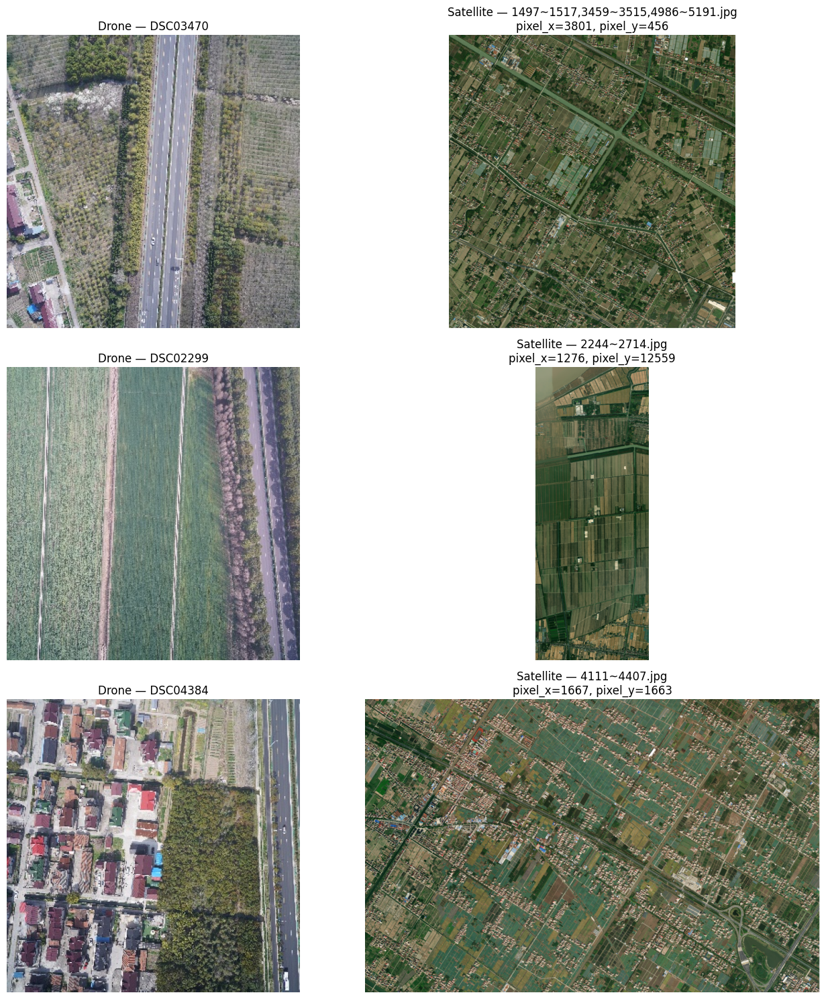

Inspection terminée — aucun fichier ni checkpoint modifié.


In [47]:
# ============================================================
# CELLULE 46 — INSPECTION VISUELLE DRONE / SATELLITE
# Chongmingdao — aucun entraînement
# ============================================================

import os
import re
import random
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

region_dir = os.path.join(DATASET_ROOT, "Chongmingdao")
drone_dir = os.path.join(region_dir, "drone")
satellite_dir = os.path.join(region_dir, "satellite")

# Charger les annotations
gps = pd.read_excel(
    os.path.join(region_dir, "location_with_dem.xlsx")
)
pixels = pd.read_excel(
    os.path.join(region_dir, "pxGT_dem.xlsx")
)
df = gps.merge(
    pixels,
    on="id",
    how="inner",
    validate="one_to_one"
)

# Construire l'association dossier drone -> tuile satellite.
tile_names = [
    f for f in os.listdir(satellite_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

def get_ranges(name):
    return [
        (int(a), int(b))
        for a, b in re.findall(r"(\d+)~(\d+)", name)
    ]

def frame_numbers(name):
    return {
        n
        for start, end in get_ranges(name)
        for n in range(start, end + 1)
    }

tiles = {
    name: frame_numbers(name)
    for name in tile_names
}

pairs = []

for folder in sorted(os.listdir(drone_dir)):
    folder_path = os.path.join(drone_dir, folder)
    if not os.path.isdir(folder_path):
        continue

    folder_frames = frame_numbers(folder)

    candidates = [
        tile for tile, nums in tiles.items()
        if folder_frames and folder_frames.issubset(nums)
    ]

    if len(candidates) != 1:
        print(f"Association non unique : {folder} -> {candidates}")
        continue

    tile = candidates[0]

    # Trouver les images de ce dossier dont l'identifiant figure
    # dans les annotations.
    subset = df[df["id"].astype(str).str.extract(
        r"DSC(\d+)", expand=False
    ).astype(float).isin(folder_frames)]

    if not subset.empty:
        pairs.append((folder, tile, subset))

# Choisir un exemple par groupe parmi les annotations disponibles.
random.seed(42)
selected = []

for folder, tile, subset in pairs:
    valid = subset[
        pd.to_numeric(subset["pixel_x"], errors="coerce").notna()
        & pd.to_numeric(subset["pixel_y"], errors="coerce").notna()
        & (pd.to_numeric(subset["pixel_x"], errors="coerce") >= 0)
        & (pd.to_numeric(subset["pixel_y"], errors="coerce") >= 0)
    ]

    if not valid.empty:
        selected.append((folder, tile, valid.sample(1, random_state=42).iloc[0]))

# Prendre trois groupes différents si possible.
if len(selected) > 3:
    selected = [selected[i] for i in
                [0, len(selected)//2, len(selected)-1]]

fig, axes = plt.subplots(len(selected), 2, figsize=(14, 5 * len(selected)))
if len(selected) == 1:
    axes = [axes]

for i, (folder, tile, row) in enumerate(selected):
    frame = re.search(r"DSC(\d+)", str(row["id"]))
    frame_id = int(frame.group(1)) if frame else None

    # Chercher le fichier image drone par identifiant DSC.
    drone_image_path = None
    for root, _, files in os.walk(drone_dir):
        for filename in files:
            match = re.search(r"DSC(\d+)", filename)
            if match and int(match.group(1)) == frame_id:
                drone_image_path = os.path.join(root, filename)
                break
        if drone_image_path:
            break

    satellite_path = os.path.join(satellite_dir, tile)

    if drone_image_path is None:
        axes[i][0].text(0.5, 0.5, f"Image drone introuvable : {row['id']}",
                        ha="center", va="center")
        axes[i][0].axis("off")
    else:
        with Image.open(drone_image_path) as im:
            axes[i][0].imshow(im.convert("RGB"))
        axes[i][0].set_title(f"Drone — {row['id']}")
        axes[i][0].axis("off")

    # Afficher une version réduite de la tuile pour éviter une
    # consommation mémoire excessive. Les coordonnées pixel sont indiquées.
    with Image.open(satellite_path) as im:
        preview = im.convert("RGB")
        preview.thumbnail((1000, 700))
        axes[i][1].imshow(preview)

    axes[i][1].set_title(
        f"Satellite — {tile}\n"
        f"pixel_x={row['pixel_x']}, pixel_y={row['pixel_y']}"
    )
    axes[i][1].axis("off")

plt.tight_layout()
plt.show()

print("Inspection terminée — aucun fichier ni checkpoint modifié.")

In [48]:
# ============================================================
# CELLULE 47 — AUDIT DES ANNOTATIONS GPS ET DES CIBLES
# Aucune modification du dataset ou des checkpoints
# ============================================================

import os
import numpy as np
import pandas as pd

REGIONS = ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]

for region in REGIONS:
    region_dir = os.path.join(DATASET_ROOT, region)

    gps_path = os.path.join(region_dir, "location_with_dem.xlsx")
    pose_path = os.path.join(region_dir, "pose.xlsx")
    px_path = os.path.join(region_dir, "pxGT_dem.xlsx")

    # Charger le fichier GPS principal
    if not os.path.exists(gps_path):
        print(f"\n[{region}] Fichier absent : {gps_path}")
        continue

    gps = pd.read_excel(gps_path)

    print("\n" + "=" * 85)
    print(f"RÉGION : {region}")
    print("=" * 85)

    print("\nDimensions :", gps.shape)
    print("Colonnes :", gps.columns.tolist())
    print("Identifiants dupliqués :", int(gps["id"].duplicated().sum())
          if "id" in gps.columns else "colonne id absente")

    # Colonnes pertinentes disponibles
    candidates = [
        "lon", "lat", "GPS_Alt",
        "target_lon", "target_lat", "relative_altitude",
        "roll", "pitch", "yaw"
    ]
    available = [c for c in candidates if c in gps.columns]

    for col in available:
        gps[col] = pd.to_numeric(gps[col], errors="coerce")

    print("\nValeurs manquantes :")
    print(gps[available].isna().sum())

    print("\nStatistiques descriptives :")
    display(gps[available].describe().T.round(6))

    # Vérifications des plages géographiques
    for lon_col, lat_col, label in [
        ("lon", "lat", "GPS original"),
        ("target_lon", "target_lat", "GPS cible")
    ]:
        if lon_col in gps.columns and lat_col in gps.columns:
            valid = gps[[lon_col, lat_col]].dropna()

            print(f"\n{label} :")
            print("Paires disponibles :", len(valid))
            print("Longitude dans [-180, 180] :",
                  int(valid[lon_col].between(-180, 180).sum()), "/", len(valid))
            print("Latitude dans [-90, 90] :",
                  int(valid[lat_col].between(-90, 90).sum()), "/", len(valid))

    # Écart entre GPS original et GPS cible
    required = {"lon", "lat", "target_lon", "target_lat"}
    if required.issubset(gps.columns):
        valid = gps.dropna(
            subset=["lon", "lat", "target_lon", "target_lat"]
        ).copy()

        if not valid.empty:
            lat_mid = np.radians(
                (valid["lat"].to_numpy() +
                 valid["target_lat"].to_numpy()) / 2
            )

            dx = (
                valid["target_lon"].to_numpy() -
                valid["lon"].to_numpy()
            ) * 111320 * np.cos(lat_mid)

            dy = (
                valid["target_lat"].to_numpy() -
                valid["lat"].to_numpy()
            ) * 111320

            distance_m = np.sqrt(dx**2 + dy**2)

            print("\nDistance approximative GPS original ↔ GPS cible :")
            print(f"Médiane : {np.median(distance_m):.2f} m")
            print(f"Moyenne : {np.mean(distance_m):.2f} m")
            print(f"P90 : {np.percentile(distance_m, 90):.2f} m")
            print(f"Maximum : {np.max(distance_m):.2f} m")

    # Audit du fichier de poses si son chemin est connu
    if os.path.exists(pose_path):
        pose = pd.read_excel(pose_path)
        print("\nFichier de poses :", pose_path)
        print("Dimensions :", pose.shape)
        print("Colonnes :", pose.columns.tolist())

print("\n" + "=" * 85)
print("FIN DE L'AUDIT — aucune donnée ni aucun checkpoint modifié.")


RÉGION : AnYangRiver

Dimensions : (645, 4)
Colonnes : ['id', 'target_lon', 'target_lat', 'relative_altitude']
Identifiants dupliqués : 0

Valeurs manquantes :
target_lon           0
target_lat           0
relative_altitude    0
dtype: int64

Statistiques descriptives :


,count,mean,std,min,25%,50%,75%,max
target_lon,645.0,113.883191,0.026869,113.815379,113.862910,113.889994,113.906659,113.923617
target_lat,645.0,36.100348,0.023284,36.049025,36.082845,36.104327,36.119227,36.140683
relative_altitude,645.0,606.287132,16.884008,529.300000,599.000000,610.300000,617.400000,641.800000



GPS cible :
Paires disponibles : 645
Longitude dans [-180, 180] : 645 / 645
Latitude dans [-90, 90] : 645 / 645

RÉGION : Chongmingdao

Dimensions : (3695, 4)
Colonnes : ['id', 'target_lon', 'target_lat', 'relative_altitude']
Identifiants dupliqués : 0

Valeurs manquantes :
target_lon           0
target_lat           0
relative_altitude    0
dtype: int64

Statistiques descriptives :


,count,mean,std,min,25%,50%,75%,max
target_lon,3695.0,121.471779,0.172309,121.244077,121.305644,121.469014,121.614974,121.798359
target_lat,3695.0,31.648422,0.093966,31.504185,31.568985,31.630139,31.714051,31.848901
relative_altitude,3695.0,295.906360,2.196468,288.000000,294.000000,296.000000,297.000000,305.000000



GPS cible :
Paires disponibles : 3695
Longitude dans [-180, 180] : 3695 / 3695
Latitude dans [-90, 90] : 3695 / 3695

RÉGION : CuiJiaQiao

Dimensions : (607, 4)
Colonnes : ['id', 'target_lon', 'target_lat', 'relative_altitude']
Identifiants dupliqués : 0

Valeurs manquantes :
target_lon           0
target_lat           0
relative_altitude    0
dtype: int64

Statistiques descriptives :


,count,mean,std,min,25%,50%,75%,max
target_lon,607.0,114.494767,0.041083,114.418680,114.460386,114.492780,114.529470,114.576213
target_lat,607.0,36.131673,0.016284,36.103829,36.118452,36.131413,36.144704,36.162042
relative_altitude,607.0,805.159802,3.477295,784.000000,804.000000,805.000000,807.000000,833.000000



GPS cible :
Paires disponibles : 607
Longitude dans [-180, 180] : 607 / 607
Latitude dans [-90, 90] : 607 / 607

FIN DE L'AUDIT — aucune donnée ni aucun checkpoint modifié.


In [49]:
# ============================================================
# CELLULE 48 — DISTRIBUTION GPS ET ALTITUDE PAR RÉGION
# Diagnostic uniquement : aucun entraînement
# ============================================================

import os
import numpy as np
import pandas as pd

REGIONS = ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]
frames = []

for region in REGIONS:
    path = os.path.join(
        DATASET_ROOT, region, "location_with_dem.xlsx"
    )

    df = pd.read_excel(path)
    df["region"] = region
    frames.append(df)

all_targets = pd.concat(frames, ignore_index=True)

target_cols = ["target_lon", "target_lat", "relative_altitude"]

print("Nombre total d'annotations :", len(all_targets))
print("Nombre de régions :", all_targets["region"].nunique())

print("\n1. Distribution globale par région")
display(
    all_targets.groupby("region")[target_cols]
    .agg(["count", "mean", "std", "min", "median", "max"])
    .round(6)
)

print("\n2. Étendue globale des cibles")
display(
    all_targets[target_cols]
    .agg(["min", "max", "mean", "std"])
    .T.round(6)
)

print("\n3. Étendue de chaque cible dans chaque région")
for col in target_cols:
    ranges = all_targets.groupby("region")[col].agg(
        minimum="min",
        maximum="max",
        moyenne="mean",
        ecart_type="std"
    )
    ranges["etendue"] = ranges["maximum"] - ranges["minimum"]

    print(f"\nCible : {col}")
    display(ranges.round(6))

print("\n4. Vérification des valeurs non finies")
for col in target_cols:
    values = pd.to_numeric(all_targets[col], errors="coerce")
    print(
        f"{col}: non finies = "
        f"{int((~np.isfinite(values)).sum())}"
    )

print("\nFin du diagnostic. Aucun fichier ni checkpoint modifié.")

Nombre total d'annotations : 4947
Nombre de régions : 3

1. Distribution globale par région


target_lon                                                \
                  count        mean       std         min      median   
region                                                                  
AnYangRiver         645  113.883191  0.026869  113.815379  113.889994   
Chongmingdao       3695  121.471779  0.172309  121.244077  121.469014   
CuiJiaQiao          607  114.494767  0.041083  114.418680  114.492780   

                         target_lat                                  \
                     max      count       mean       std        min   
region                                                                
AnYangRiver   113.923617        645  36.100348  0.023284  36.049025   
Chongmingdao  121.798359       3695  31.648422  0.093966  31.504185   
CuiJiaQiao    114.576213        607  36.131673  0.016284  36.103829   

                                   relative_altitude                         \
                 median        max             count        mean        std   
region                                                                        
AnYangRiver   36.104327  36.140683               645  606.287132  16.884008   
Chongmingdao  31.630139  31.848901              3695  295.906360   2.196468   
CuiJiaQiao    36.131413  36.162042               607  805.159802   3.477295   

                                   
                min median    max  
region                             
AnYangRiver   529.3  610.3  641.8  
Chongmingdao  288.0  296.0  305.0  
CuiJiaQiao    784.0  805.0  833.0


2. Étendue globale des cibles


,min,max,mean,std
target_lon,113.815379,121.798359,119.626279,3.178021
target_lat,31.504185,36.162042,32.778971,1.944138
relative_altitude,288.000000,833.000000,398.860158,183.932403



3. Étendue de chaque cible dans chaque région

Cible : target_lon


,minimum,maximum,moyenne,ecart_type,etendue
region,,,,,
AnYangRiver,113.815379,113.923617,113.883191,0.026869,0.108237
Chongmingdao,121.244077,121.798359,121.471779,0.172309,0.554282
CuiJiaQiao,114.418680,114.576213,114.494767,0.041083,0.157532



Cible : target_lat


,minimum,maximum,moyenne,ecart_type,etendue
region,,,,,
AnYangRiver,36.049025,36.140683,36.100348,0.023284,0.091658
Chongmingdao,31.504185,31.848901,31.648422,0.093966,0.344717
CuiJiaQiao,36.103829,36.162042,36.131673,0.016284,0.058213



Cible : relative_altitude


,minimum,maximum,moyenne,ecart_type,etendue
region,,,,,
AnYangRiver,529.3,641.8,606.287132,16.884008,112.5
Chongmingdao,288.0,305.0,295.906360,2.196468,17.0
CuiJiaQiao,784.0,833.0,805.159802,3.477295,49.0



4. Vérification des valeurs non finies
target_lon: non finies = 0
target_lat: non finies = 0
relative_altitude: non finies = 0

Fin du diagnostic. Aucun fichier ni checkpoint modifié.


In [50]:

# ============================================================
# CELLULE 49 — AUDIT DES CIBLES ET DE LEUR NORMALISATION
# Diagnostic uniquement : aucun entraînement, aucune sauvegarde
# ============================================================

import re

print("=" * 80)
print("CELLULE 49 — RECHERCHE DE LA CONSTRUCTION DES CIBLES")
print("=" * 80)

# Recherche dans les cellules déjà exécutées du notebook IPython
try:
    ip = get_ipython()
    history = ip.history_manager.input_hist_raw

    keywords = [
        "model_targets",
        "target_cols",
        "target_mean",
        "target_std",
        "StandardScaler",
        "GPS_Alt",
        "relative_altitude",
        "yaw_sin",
        "yaw_cos",
        "target_scaler",
        "inverse_transform",
        "normalize_targets",
        "normalization",
    ]

    found = 0

    for cell_num, source in enumerate(history):
        if not source or "CELLULE 49" in source:
            continue

        lines = source.splitlines()
        matching_lines = [
            i for i, line in enumerate(lines)
            if any(k.lower() in line.lower() for k in keywords)
        ]

        if not matching_lines:
            continue

        # Évite d'afficher plusieurs fois la même cellule
        found += 1
        print(f"\n{'-' * 80}")
        print(f"CELLULE HISTORIQUE : {cell_num}")
        print("-" * 80)

        # Affiche les lignes correspondantes avec leur contexte
        displayed = set()

        for idx in matching_lines:
            start = max(0, idx - 3)
            end = min(len(lines), idx + 4)

            for j in range(start, end):
                if j not in displayed:
                    print(f"{j + 1:04d}: {lines[j]}")
                    displayed.add(j)

    if found == 0:
        print(
            "Aucune cellule correspondante trouvée dans l'historique. "
            "Il faudra examiner manuellement les cellules concernées."
        )

    print("\nNombre de cellules candidates :", found)

except Exception as e:
    print("Impossible de lire l'historique du notebook :", repr(e))
    print(
        "Recherche manuelle nécessaire : model_targets, target_mean, "
        "target_std, StandardScaler et inverse_transform."
    )

print("\nFin de l'audit. Aucun entraînement lancé.")


CELLULE 49 — RECHERCHE DE LA CONSTRUCTION DES CIBLES

--------------------------------------------------------------------------------
CELLULE HISTORIQUE : 4
--------------------------------------------------------------------------------
0047: 
0048:     # 3. Vérifier les valeurs numériques
0049:     colonnes = [
0050:         "lon", "lat", "GPS_Alt", "roll", "pitch", "yaw",
0051:         "target_lon", "target_lat", "relative_altitude",
0052:         "pixel_x", "pixel_y"
0053:     ]
0054: 

--------------------------------------------------------------------------------
CELLULE HISTORIQUE : 8
--------------------------------------------------------------------------------
0015: df_px = pd.read_excel(os.path.join(base, "pxGT_dem.xlsx"))
0016: 
0017: df = (
0018:     df_main[["id", "lon", "lat", "GPS_Alt"]]
0019:     .merge(df_loc, on="id", validate="one_to_one")
0020:     .merge(df_px, on="id", validate="one_to_one")
0021: )

------------------------------------------------------------

In [51]:

# ============================================================
# CELLULE 50 — INSPECTION DES VARIABLES DU MODÈLE
# Diagnostic uniquement
# ============================================================

import numpy as np
import pandas as pd

print("=" * 75)
print("CELLULE 50 — VARIABLES DES CIBLES ET NORMALISATION")
print("=" * 75)

ip = get_ipython()
namespace = ip.user_ns

keywords = (
    "target", "scaler", "normal", "mean", "std",
    "model", "dataset", "train", "val", "yaw", "gps"
)

print("\n1. Variables pertinentes présentes en mémoire")
for name, value in sorted(namespace.items()):
    if name.startswith("_"):
        continue
    if not any(k in name.lower() for k in keywords):
        continue

    if isinstance(value, (np.ndarray, pd.Series)):
        print(f"{name}: type={type(value).__name__}, shape={value.shape}")
        if value.size <= 20:
            print("  valeurs :", value)
    elif isinstance(value, pd.DataFrame):
        print(f"{name}: DataFrame, shape={value.shape}")
        print("  colonnes :", list(value.columns))
    elif isinstance(value, (list, tuple)) and len(value) <= 20:
        print(f"{name}: {type(value).__name__}, longueur={len(value)}")
        print("  valeurs :", value)
    elif isinstance(value, (int, float, str, bool, type(None))):
        print(f"{name}: {value!r}")
    elif "scaler" in name.lower() or "model" in name.lower():
        print(f"{name}: objet de type {type(value).__name__}")

print("\n2. Fonctions pertinentes présentes en mémoire")
for name, value in sorted(namespace.items()):
    if callable(value) and any(
        k in name.lower()
        for k in ("target", "normal", "inverse", "transform", "dataset")
    ):
        print(f"{name}: {type(value).__name__}")

print("\nFin du diagnostic. Aucun entraînement lancé.")


CELLULE 50 — VARIABLES DES CIBLES ET NORMALISATION

1. Variables pertinentes présentes en mémoire
DATASET_ROOT: '/kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset'
NUM_TARGETS: 7
TRAIN_FRACTION: 0.7
VAL_FRACTION: 0.15
all_targets: DataFrame, shape=(4947, 5)
  colonnes : ['id', 'target_lon', 'target_lat', 'relative_altitude', 'region']
gps: DataFrame, shape=(607, 4)
  colonnes : ['id', 'target_lon', 'target_lat', 'relative_altitude']
gps_path: '/kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/CuiJiaQiao/location_with_dem.xlsx'
intervals: list, longueur=1
  valeurs : [(4111, 4407)]
model: objet de type LinearRegression
target_cols: list, longueur=3
  valeurs : ['target_lon', 'target_lat', 'relative_altitude']
train_idx: type=ndarray, shape=(236,)
valeurs: type=Series, shape=(607,)
valid: DataFrame, shape=(607, 2)
  colonnes : ['target_lon', 'target_lat']
valide: type=Series, shape=(607,)
valides: 100
vals: type=Series, shape=(607,)
value: nan
va

In [52]:

# ============================================================
# CELLULE 51 — RECHERCHE DU CODE DATASET / CIBLES / NORMALISATION
# Aucun entraînement, aucune modification de checkpoint
# ============================================================

ip = get_ipython()
history = ip.history_manager.input_hist_raw

patterns = [
    "class ",
    "model_targets",
    "NUM_TARGETS",
    "target_mean",
    "target_std",
    "StandardScaler",
    "MinMaxScaler",
    "inverse_transform",
    "yaw_sin",
    "yaw_cos",
    "GPS_Alt",
    "relative_altitude",
    "def __getitem__",
    "def __init__",
]

print("=" * 80)
print("CELLULE 51 — CODE SOURCE PERTINENT")
print("=" * 80)

for cell_num, source in enumerate(history):
    if not source or "CELLULE 51" in source:
        continue

    lines = source.splitlines()
    matching = [
        i for i, line in enumerate(lines)
        if any(pattern.lower() in line.lower() for pattern in patterns)
    ]

    if not matching:
        continue

    print(f"\n{'=' * 80}")
    print(f"CELLULE HISTORIQUE : {cell_num}")
    print("=" * 80)

    # Afficher la cellule entière si elle reste raisonnable.
    if len(lines) <= 100:
        print(source)
    else:
        # Sinon, afficher les lignes pertinentes avec leur contexte.
        displayed = set()
        for idx in matching:
            for j in range(max(0, idx - 5), min(len(lines), idx + 9)):
                if j not in displayed:
                    print(f"{j + 1:04d}: {lines[j]}")
                    displayed.add(j)

print("\nFin de la recherche. Aucun entraînement lancé.")


CELLULE 51 — CODE SOURCE PERTINENT

CELLULE HISTORIQUE : 1
0050: TEST_FRACTION = 0.15  # 15 % pour le test
0051: 
0052: EPOCHS = 5            # Première expérience courte
0053: BATCH_SIZE = 8        # Départ prudent pour une GPU Kaggle
0054: IMAGE_SIZE = 224      # Taille attendue par le ViT
0055: NUM_TARGETS = 7       # Position et orientation du drone
0056: 
0057: # ------------------------------------------------------------
0058: # 5. Choisir le périphérique de calcul
0059: # ------------------------------------------------------------
0060: 
0061: DEVICE = torch.device(
0062:     "cuda" if torch.cuda.is_available() else "cpu"
0063: )

CELLULE HISTORIQUE : 4
# ============================================================
# CELLULE 4 — CONTRÔLE DES DONNÉES ET DES IDENTIFIANTS
# ============================================================

import os
import numpy as np
import pandas as pd

for region in REGIONS:
    print("\n" + "=" * 75)
    print(f"RÉGION : {region}")
    print("=" *

In [53]:

# ============================================================
# CELLULE 52 — INSPECTION DU CODE DU DATASET ET DU MODÈLE
# Aucun entraînement, aucune modification de checkpoint
# ============================================================

import inspect

ip = get_ipython()
ns = ip.user_ns

candidats = []

for nom, obj in sorted(ns.items()):
    if nom.startswith("_"):
        continue

    if not (inspect.isclass(obj) or inspect.isfunction(obj)):
        continue

    try:
        source = inspect.getsource(obj)
    except (OSError, TypeError):
        continue

    texte = (nom + "\n" + source).lower()

    mots_cles = [
        "dataset", "regressor", "getitem",
        "model_targets", "target_mean", "target_std",
        "standardscaler", "inverse_transform",
        "yaw_sin", "yaw_cos", "gps_alt"
    ]

    score = sum(mot in texte for mot in mots_cles)

    if score:
        candidats.append((score, nom, obj, source))

print("=" * 80)
print("CELLULE 52 — CLASSES ET FONCTIONS RETROUVÉES")
print("=" * 80)

candidats.sort(key=lambda x: (-x[0], x[1]))

if not candidats:
    print("Aucun code source accessible en mémoire.")
    print(
        "Il faudra rechercher dans les cellules originales du notebook "
        "la définition du Dataset, du modèle et de la normalisation."
    )
else:
    for score, nom, obj, source in candidats:
        print("\n" + "=" * 80)
        print(f"NOM : {nom} | TYPE : {type(obj).__name__} | SCORE : {score}")
        print("=" * 80)
        print(source[:12000])
        if len(source) > 12000:
            print("\n[Source tronquée : plus de 12 000 caractères]")

print("\nFin de l'inspection. Aucun entraînement lancé.")


CELLULE 52 — CLASSES ET FONCTIONS RETROUVÉES

NOM : LinearRegression | TYPE : ABCMeta | SCORE : 2
class LinearRegression(MultiOutputMixin, RegressorMixin, LinearModel):
    """
    Ordinary least squares Linear Regression.

    LinearRegression fits a linear model with coefficients w = (w1, ..., wp)
    to minimize the residual sum of squares between the observed targets in
    the dataset, and the targets predicted by the linear approximation.

    Parameters
    ----------
    fit_intercept : bool, default=True
        Whether to calculate the intercept for this model. If set
        to False, no intercept will be used in calculations
        (i.e. data is expected to be centered).

    copy_X : bool, default=True
        If True, X will be copied; else, it may be overwritten.

    n_jobs : int, default=None
        The number of jobs to use for the computation. This will only provide
        speedup in case of sufficiently large problems, that is if firstly
        `n_targets > 1` a

In [54]:

# ============================================================
# CELLULE 53 — RECHERCHE CIBLÉE DU CODE D'ENTRAÎNEMENT
# Diagnostic uniquement
# ============================================================

ip = get_ipython()
history = ip.history_manager.input_hist_raw

keywords = [
    "class MultiScaleViTRegressor",
    "class ViT",
    "class UAVLoc",
    "class Drone",
    "class CustomDataset",
    "class UAVLocDataset",
    "def __getitem__",
    "model_targets",
    "yaw_sin",
    "yaw_cos",
    "target_mean",
    "target_std",
    "optimizer.step",
    "best_val_mse",
    "vitoutdoorloc_best.pth",
]

print("=" * 85)
print("CELLULE 53 — RECHERCHE CIBLÉE")
print("=" * 85)

found = 0

for cell_num, source in enumerate(history):
    if not source:
        continue

    matching = [
        (i, line)
        for i, line in enumerate(source.splitlines())
        if any(k.lower() in line.lower() for k in keywords)
    ]

    if not matching:
        continue

    found += 1
    lines = source.splitlines()

    print(f"\n{'=' * 85}")
    print(f"CELLULE HISTORIQUE : {cell_num}")
    print("Correspondances :", [line.strip() for _, line in matching])
    print("=" * 85)

    # Afficher intégralement les cellules de taille raisonnable
    if len(lines) <= 180:
        print(source)
    else:
        shown = set()
        for i, _ in matching:
            for j in range(max(0, i - 8), min(len(lines), i + 15)):
                if j not in shown:
                    print(f"{j + 1:04d}: {lines[j]}")
                    shown.add(j)

print("\nNombre de cellules candidates :", found)

if found == 0:
    print(
        "Le code recherché n'est pas disponible dans cet historique. "
        "Il faudra retrouver les cellules originales du notebook "
        "ou ouvrir le notebook qui a produit le checkpoint."
    )

print("\nAucun entraînement lancé.")


CELLULE 53 — RECHERCHE CIBLÉE

CELLULE HISTORIQUE : 50
Correspondances : ['"model_targets",', '"target_mean",', '"target_std",', '"yaw_sin",', '"yaw_cos",', '"Recherche manuelle nécessaire : model_targets, target_mean, "', '"target_std, StandardScaler et inverse_transform."']

# ============================================================
# CELLULE 49 — AUDIT DES CIBLES ET DE LEUR NORMALISATION
# Diagnostic uniquement : aucun entraînement, aucune sauvegarde
# ============================================================

import re

print("=" * 80)
print("CELLULE 49 — RECHERCHE DE LA CONSTRUCTION DES CIBLES")
print("=" * 80)

# Recherche dans les cellules déjà exécutées du notebook IPython
try:
    ip = get_ipython()
    history = ip.history_manager.input_hist_raw

    keywords = [
        "model_targets",
        "target_cols",
        "target_mean",
        "target_std",
        "StandardScaler",
        "GPS_Alt",
        "relative_altitude",
        "yaw_sin",
        "yaw_cos",
    

In [55]:

# ============================================================
# CELLULE 54 — AUDIT DES CHECKPOINTS
# Lecture uniquement : aucun entraînement, aucune sauvegarde
# ============================================================

import os
import glob
import torch

ROOTS = [
    "/kaggle/working/ViTOutdoorLoc_outputs",
    "/kaggle/working",
]

NOMS_CIBLES = [
    "vitoutdoorloc_best.pth",
    "vitoutdoorloc_last.pth",
    "best_vit_multiscale.pth",
    "best_vit_only_head.pth",
]

fichiers = []

for root in ROOTS:
    if not os.path.isdir(root):
        continue

    for nom in NOMS_CIBLES:
        fichiers.extend(
            glob.glob(os.path.join(root, "**", nom), recursive=True)
        )

fichiers = list(dict.fromkeys(fichiers))

print("=" * 80)
print("CELLULE 54 — CHECKPOINTS DISPONIBLES")
print("=" * 80)

if not fichiers:
    print("Aucun checkpoint ciblé trouvé dans les répertoires inspectés.")

for chemin in fichiers:
    print("\n" + "-" * 80)
    print("Fichier :", chemin)
    print("Taille (Mo) :", round(os.path.getsize(chemin) / 1024**2, 2))

    try:
        try:
            checkpoint = torch.load(
                chemin, map_location="cpu", weights_only=True
            )
        except Exception as e:
            print("Lecture weights_only=True impossible :", repr(e))
            print(
                "Par sécurité, aucun chargement non sécurisé automatique "
                "n'est tenté."
            )
            continue

        if isinstance(checkpoint, dict):
            print("Clés principales :", list(checkpoint.keys())[:60])

            for cle in [
                "epoch", "best_val_mse", "val_loss",
                "model_targets", "target_cols",
                "target_mean", "target_std",
            ]:
                if cle in checkpoint:
                    print(f"{cle} :", checkpoint[cle])

            # Repérer le dictionnaire contenant les poids
            for cle in [
                "model_state_dict", "state_dict", "model_state",
                "model", "net",
            ]:
                poids = checkpoint.get(cle)

                if isinstance(poids, dict):
                    print(f"\nDictionnaire de poids : {cle}")
                    print("Nombre de tenseurs :", len(poids))

                    for nom_param, tenseur in list(poids.items())[-15:]:
                        if torch.is_tensor(tenseur):
                            print(
                                f"  {nom_param}: "
                                f"shape={tuple(tenseur.shape)}"
                            )
                    break
        else:
            print("Type de checkpoint :", type(checkpoint).__name__)

        del checkpoint

    except Exception as e:
        print("Erreur de lecture :", repr(e))

print("\nFin de l'audit. Aucun entraînement lancé.")


CELLULE 54 — CHECKPOINTS DISPONIBLES
Aucun checkpoint ciblé trouvé dans les répertoires inspectés.

Fin de l'audit. Aucun entraînement lancé.


In [56]:

# ============================================================
# CELLULE 55 — LOCALISER LES CHECKPOINTS
# Recherche uniquement, aucun fichier modifié
# ============================================================

import os

RACINES = [
    "/kaggle/working",
    "/kaggle/input",
]

EXTENSIONS = (".pth", ".pt", ".ckpt")
MOTS_CLES = ("vit", "outdoor", "checkpoint", "model", "best", "resume")

resultats = []
erreurs = []

print("=" * 80)
print("CELLULE 55 — RECHERCHE GLOBALE DES CHECKPOINTS")
print("=" * 80)

for racine in RACINES:
    if not os.path.exists(racine):
        print(f"Répertoire absent : {racine}")
        continue

    print(f"\nRecherche dans : {racine}")

    for dossier, sous_dossiers, fichiers in os.walk(racine):
        # Éviter les dossiers cachés et les caches volumineux
        sous_dossiers[:] = [
            d for d in sous_dossiers
            if not d.startswith(".") and d not in {"__pycache__"}
        ]

        for nom in fichiers:
            if not nom.lower().endswith(EXTENSIONS):
                continue

            chemin = os.path.join(dossier, nom)

            try:
                taille_mo = os.path.getsize(chemin) / (1024 ** 2)
            except OSError as e:
                erreurs.append((chemin, str(e)))
                continue

            resultats.append((chemin, taille_mo))

print("\n" + "=" * 80)
print("FICHIERS TROUVÉS")
print("=" * 80)

resultats.sort(key=lambda x: x[0].lower())

if resultats:
    for chemin, taille_mo in resultats:
        nom = os.path.basename(chemin)
        pertinent = any(m in nom.lower() for m in MOTS_CLES)
        marqueur = " [NOM PERTINENT]" if pertinent else ""
        print(f"{taille_mo:9.2f} Mo | {chemin}{marqueur}")
else:
    print("Aucun fichier .pth, .pt ou .ckpt trouvé.")

print("\nNombre total :", len(resultats))
print("Erreurs d'accès :", len(erreurs))
print("Aucun entraînement lancé.")


CELLULE 55 — RECHERCHE GLOBALE DES CHECKPOINTS

Recherche dans : /kaggle/working

Recherche dans : /kaggle/input

FICHIERS TROUVÉS
Aucun fichier .pth, .pt ou .ckpt trouvé.

Nombre total : 0
Erreurs d'accès : 0
Aucun entraînement lancé.


In [57]:

# ============================================================
# CELLULE 56 — INVENTAIRE DES SORTIES ET NOTEBOOKS
# Lecture uniquement
# ============================================================

import os

RACINES = [
    "/kaggle/working",
    "/kaggle/input",
]

EXTENSIONS = (
    ".ipynb", ".csv", ".json", ".log", ".txt",
    ".xlsx", ".yaml", ".yml", ".pkl", ".joblib"
)

MOTS_CLES = (
    "vitoutdoorloc", "checkpoint", "history", "metrics",
    "manifest", "training", "train", "model", "output"
)

print("=" * 85)
print("CELLULE 56 — INVENTAIRE DES FICHIERS UTILES")
print("=" * 85)

total = 0

for racine in RACINES:
    print(f"\n--- {racine} ---")

    if not os.path.isdir(racine):
        print("Répertoire absent.")
        continue

    trouves = []

    for dossier, sous_dossiers, fichiers in os.walk(racine):
        sous_dossiers[:] = [
            d for d in sous_dossiers
            if not d.startswith(".") and d != "__pycache__"
        ]

        for nom in fichiers:
            chemin = os.path.join(dossier, nom)
            nom_bas = nom.lower()

            pertinent = (
                nom_bas.endswith(EXTENSIONS)
                and any(m in nom_bas for m in MOTS_CLES)
            )

            if pertinent:
                try:
                    taille = os.path.getsize(chemin) / 1024
                except OSError:
                    taille = float("nan")

                trouves.append((chemin, taille))

    trouves.sort()

    if not trouves:
        print("Aucun fichier correspondant.")
        continue

    for chemin, taille_ko in trouves:
        print(f"{taille_ko:10.1f} Ko | {chemin}")
        total += 1

print("\nNombre de fichiers pertinents :", total)
print("Aucun fichier modifié, aucun entraînement lancé.")


CELLULE 56 — INVENTAIRE DES FICHIERS UTILES

--- /kaggle/working ---
    1139.8 Ko | /kaggle/working/ViTOutdoorLoc_outputs/manifest_dataset.csv

--- /kaggle/input ---
Aucun fichier correspondant.

Nombre de fichiers pertinents : 1
Aucun fichier modifié, aucun entraînement lancé.


In [58]:

# ============================================================
# CELLULE 57 — AUDIT DU MANIFESTE
# Lecture uniquement : aucun entraînement ni modification
# ============================================================

import os
import pandas as pd

manifest_path = (
    "/kaggle/working/ViTOutdoorLoc_outputs/manifest_dataset.csv"
)

if not os.path.isfile(manifest_path):
    print("ERREUR : manifeste introuvable :", manifest_path)
else:
    manifest = pd.read_csv(manifest_path)

    print("=" * 80)
    print("CELLULE 57 — STRUCTURE DU MANIFESTE")
    print("=" * 80)

    print("Dimensions :", manifest.shape)
    print("\nColonnes :")
    print(manifest.columns.tolist())

    print("\nAperçu des 5 premières lignes :")
    display(manifest.head())

    print("\nValeurs manquantes par colonne :")
    print(manifest.isna().sum().sort_values(ascending=False).head(20))

    print("\nColonnes potentiellement utiles :")
    for col in manifest.columns:
        if any(
            mot in col.lower()
            for mot in [
                "image", "path", "region", "status",
                "valid", "error", "id", "file"
            ]
        ):
            print(f"\n--- {col} ---")
            print(manifest[col].value_counts(dropna=False).head(15))

    print("\nFin de l'audit. Aucun entraînement lancé.")


CELLULE 57 — STRUCTURE DU MANIFESTE
Dimensions : (4947, 15)

Colonnes :
['region', 'id', 'image_path', 'image_status', 'lon', 'lat', 'GPS_Alt', 'roll', 'pitch', 'yaw', 'target_lon', 'target_lat', 'relative_altitude', 'pixel_x', 'pixel_y']

Aperçu des 5 premières lignes :


,region,id,image_path,image_status,lon,lat,GPS_Alt,roll,pitch,yaw,target_lon,target_lat,relative_altitude,pixel_x,pixel_y
0,AnYangRiver,DSC07012,/kaggle/input/datasets/maissawahbi/uavloc-m3-d...,OK,113.905815,36.057264,884.1,3.2,-1.3,-177.3,113.906128,36.057354,613.1,9716,10821
1,AnYangRiver,DSC07013,/kaggle/input/datasets/maissawahbi/uavloc-m3-d...,OK,113.905607,36.056112,881.8,-29.1,-0.8,142.4,113.903145,36.054657,609.8,9438,11132
2,AnYangRiver,DSC07014,/kaggle/input/datasets/maissawahbi/uavloc-m3-d...,OK,113.906665,36.055315,884.5,2.9,-3.1,102.4,113.906434,36.055587,612.5,9744,11025
3,AnYangRiver,DSC07015,/kaggle/input/datasets/maissawahbi/uavloc-m3-d...,OK,113.907873,36.054677,884.1,-2.1,0.5,112.0,113.907841,36.054510,617.1,9875,11149
4,AnYangRiver,DSC07016,/kaggle/input/datasets/maissawahbi/uavloc-m3-d...,OK,113.909103,36.054060,885.1,4.2,-4.8,111.1,113.908814,36.054504,620.1,9966,11150



Valeurs manquantes par colonne :
region               0
id                   0
image_path           0
image_status         0
lon                  0
lat                  0
GPS_Alt              0
roll                 0
pitch                0
yaw                  0
target_lon           0
target_lat           0
relative_altitude    0
pixel_x              0
pixel_y              0
dtype: int64

Colonnes potentiellement utiles :

--- region ---
region
Chongmingdao    3695
AnYangRiver      645
CuiJiaQiao       607
Name: count, dtype: int64

--- id ---
id
DSC01103    1
DSC07012    1
DSC07013    1
DSC07014    1
DSC07015    1
DSC07016    1
DSC07017    1
DSC07018    1
DSC07019    1
DSC07020    1
DSC07021    1
DSC07022    1
DSC07023    1
DSC07024    1
DSC07025    1
Name: count, dtype: int64

--- image_path ---
image_path
/kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/CuiJiaQiao/drone/DSC01103.jpg     1
/kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/A

In [59]:

# ============================================================
# CELLULE 58 — VALIDATION DES DONNÉES AVANT ENTRAÎNEMENT
# Aucun entraînement, aucune modification des fichiers
# ============================================================

import os
import numpy as np
import pandas as pd

manifest_path = (
    "/kaggle/working/ViTOutdoorLoc_outputs/manifest_dataset.csv"
)
df_audit = pd.read_csv(manifest_path)

print("=" * 85)
print("CELLULE 58 — VALIDATION DES DONNÉES")
print("=" * 85)

# 1. Statut des images
print("\n1. STATUT DES IMAGES")
print(df_audit["image_status"].value_counts(dropna=False))

# 2. Vérifier l'existence des fichiers
df_audit["file_exists"] = df_audit["image_path"].map(os.path.isfile)

print("\n2. EXISTENCE DES FICHIERS")
print(pd.crosstab(df_audit["image_status"], df_audit["file_exists"]))

# 3. Doublons d'identifiants
print("\n3. DOUBLONS")
print("Lignes :", len(df_audit))
print("IDs dupliqués :", df_audit["id"].duplicated().sum())
print(
    "Paires région/ID dupliquées :",
    df_audit.duplicated(["region", "id"]).sum()
)

# 4. Vérifier les valeurs numériques
colonnes_num = [
    "lon", "lat", "GPS_Alt", "roll", "pitch", "yaw",
    "target_lon", "target_lat", "relative_altitude",
    "pixel_x", "pixel_y"
]

print("\n4. VALEURS NON FINIES")
for col in colonnes_num:
    valeurs = pd.to_numeric(df_audit[col], errors="coerce")
    print(
        f"{col:20s} | non finies ou non numériques : "
        f"{int((~np.isfinite(valeurs)).sum())}"
    )

# 5. Comparer les distributions par région
print("\n5. DISTRIBUTIONS GPS PAR RÉGION")
for col in ["lon", "lat", "target_lon", "target_lat",
            "GPS_Alt", "relative_altitude"]:
    print(f"\n--- {col} ---")
    print(
        df_audit.groupby("region")[col]
        .agg(["count", "mean", "std", "min", "median", "max"])
        .round(6)
    )

# 6. Vérifier la différence entre les deux couples GPS
# Approximation locale en mètres, suffisante pour un audit initial.
lat_ref = np.deg2rad(
    (df_audit["lat"].astype(float)
     + df_audit["target_lat"].astype(float)) / 2
)

dx = (
    df_audit["target_lon"].astype(float)
    - df_audit["lon"].astype(float)
) * 111320 * np.cos(lat_ref)

dy = (
    df_audit["target_lat"].astype(float)
    - df_audit["lat"].astype(float)
) * 110540

distance_m = np.sqrt(dx**2 + dy**2)

print("\n6. ÉCART ENTRE (lon, lat) ET (target_lon, target_lat)")
print("Distance approximative en mètres :")
print(distance_m.describe(percentiles=[0.5, 0.9, 0.95]).round(2))

print("\nPar région :")
print(
    df_audit.assign(ecart_gps_m=distance_m)
    .groupby("region")["ecart_gps_m"]
    .agg(["median", "mean", "max"])
    .round(2)
)

print("\nFin de l'audit. Aucun entraînement lancé.")


CELLULE 58 — VALIDATION DES DONNÉES

1. STATUT DES IMAGES
image_status
OK                 4911
IMAGE_ILLISIBLE      36
Name: count, dtype: int64

2. EXISTENCE DES FICHIERS
file_exists      True
image_status         
IMAGE_ILLISIBLE    36
OK               4911

3. DOUBLONS
Lignes : 4947
IDs dupliqués : 0
Paires région/ID dupliquées : 0

4. VALEURS NON FINIES
lon                  | non finies ou non numériques : 0
lat                  | non finies ou non numériques : 0
GPS_Alt              | non finies ou non numériques : 0
roll                 | non finies ou non numériques : 0
pitch                | non finies ou non numériques : 0
yaw                  | non finies ou non numériques : 0
target_lon           | non finies ou non numériques : 0
target_lat           | non finies ou non numériques : 0
relative_altitude    | non finies ou non numériques : 0
pixel_x              | non finies ou non numériques : 0
pixel_y              | non finies ou non numériques : 0

5. DISTRIBUTIONS GPS PA

In [60]:

# ============================================================
# CELLULE 59 — COMPARAISON DES CIBLES CANDIDATES
# Diagnostic uniquement : aucun entraînement
# ============================================================

import numpy as np
import pandas as pd

manifest_path = (
    "/kaggle/working/ViTOutdoorLoc_outputs/manifest_dataset.csv"
)
df59 = pd.read_csv(manifest_path)

print("=" * 85)
print("CELLULE 59 — COHÉRENCE DES CIBLES")
print("=" * 85)

# Exclure les images illisibles pour préparer le futur pipeline.
# Cette cellule ne supprime aucune ligne du fichier original.
valid59 = df59[
    (df59["image_status"] == "OK")
    & df59["image_path"].map(lambda p: __import__("os").path.isfile(p))
].copy()

print("Lignes du manifeste :", len(df59))
print("Images valides pour le pipeline :", len(valid59))

# 1. Écart entre les coordonnées GPS
lat_moy = np.deg2rad(
    (valid59["lat"].astype(float)
     + valid59["target_lat"].astype(float)) / 2
)

dx_m = (
    valid59["target_lon"].astype(float)
    - valid59["lon"].astype(float)
) * 111320 * np.cos(lat_moy)

dy_m = (
    valid59["target_lat"].astype(float)
    - valid59["lat"].astype(float)
) * 110540

valid59["gps_pair_distance_m"] = np.sqrt(dx_m**2 + dy_m**2)

print("\n1. ÉCART ENTRE LES DEUX COUPLES GPS, PAR RÉGION")
print(
    valid59.groupby("region")["gps_pair_distance_m"]
    .agg(
        effectif="count",
        mediane_m="median",
        moyenne_m="mean",
        p90_m=lambda s: s.quantile(0.90),
        maximum_m="max"
    ).round(2)
)

# 2. Comparaison des altitudes
valid59["altitude_difference"] = (
    valid59["GPS_Alt"].astype(float)
    - valid59["relative_altitude"].astype(float)
)

print("\n2. DIFFÉRENCE GPS_Alt - relative_altitude")
print(
    valid59.groupby("region")["altitude_difference"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

# 3. Corrélations par région — descriptives uniquement
print("\n3. CORRÉLATIONS PAR RÉGION")
for region, part in valid59.groupby("region"):
    print(f"\n--- {region} ---")

    for a, b in [
        ("lon", "target_lon"),
        ("lat", "target_lat"),
        ("GPS_Alt", "relative_altitude"),
    ]:
        corr = part[a].corr(part[b])
        print(f"Corrélation {a} / {b} : {corr:.6f}")

# 4. Comparer les distributions des cibles potentielles
print("\n4. DISTRIBUTIONS GLOBALES DES CIBLES")
for col in [
    "lon", "lat", "GPS_Alt",
    "target_lon", "target_lat", "relative_altitude",
    "roll", "pitch", "yaw"
]:
    print(f"\n{col}")
    print(valid59[col].describe().round(4).to_string())

print("\nFin de la cellule. Aucun entraînement ni fichier modifié.")


CELLULE 59 — COHÉRENCE DES CIBLES
Lignes du manifeste : 4947
Images valides pour le pipeline : 4911

1. ÉCART ENTRE LES DEUX COUPLES GPS, PAR RÉGION
              effectif  mediane_m  moyenne_m  p90_m  maximum_m
region                                                        
AnYangRiver        645      25.47      42.88  55.62     358.25
Chongmingdao      3659      17.33      20.86  28.18     180.66
CuiJiaQiao         607      26.11      30.02  44.29     399.45

2. DIFFÉRENCE GPS_Alt - relative_altitude
              count    mean  median    std    min    max
region                                                  
AnYangRiver     645  276.89   273.0  16.82  242.0  354.0
Chongmingdao   3659    3.65     4.0   1.64   -3.0   11.0
CuiJiaQiao      607   66.41    66.0   2.61   58.0   86.0

3. CORRÉLATIONS PAR RÉGION

--- AnYangRiver ---
Corrélation lon / target_lon : 0.999751
Corrélation lat / target_lat : 0.999806
Corrélation GPS_Alt / relative_altitude : 0.096781

--- Chongmingdao ---
Corrél

In [61]:

# ============================================================
# CELLULE 60 — AUDIT DES CIBLES ET DES SPLITS
# Aucun entraînement, aucune modification du dataset
# ============================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

manifest_path = (
    "/kaggle/working/ViTOutdoorLoc_outputs/manifest_dataset.csv"
)

df60 = pd.read_csv(manifest_path)

# Garder uniquement les images utilisables
df60 = df60[
    (df60["image_status"] == "OK")
    & df60["image_path"].map(lambda p: __import__("os").path.isfile(p))
].copy().reset_index(drop=True)

print("=" * 85)
print("CELLULE 60 — AUDIT DES CIBLES ET SPLITS")
print("=" * 85)

# 1. Split reproductible séparé pour chaque région
splits = {}

for region, group in df60.groupby("region"):
    indices = group.index.to_numpy()

    train_idx, temp_idx = train_test_split(
        indices, test_size=0.30, random_state=42
    )
    val_idx, test_idx = train_test_split(
        temp_idx, test_size=0.50, random_state=42
    )

    splits[region] = {
        "train": train_idx,
        "val": val_idx,
        "test": test_idx,
    }

    print(
        f"{region:15s} | total={len(indices):4d} | "
        f"train={len(train_idx):4d} | "
        f"val={len(val_idx):4d} | test={len(test_idx):4d}"
    )

# 2. Comparer les statistiques des cibles GPS possibles
print("\n2. STATISTIQUES PAR RÉGION")
for region, group in df60.groupby("region"):
    print(f"\n--- {region} ---")
    for col in [
        "lon", "lat", "target_lon", "target_lat",
        "GPS_Alt", "relative_altitude"
    ]:
        s = group[col].astype(float)
        print(
            f"{col:20s} moyenne={s.mean():12.6f} "
            f"écart-type={s.std():10.6f} "
            f"min={s.min():12.6f} max={s.max():12.6f}"
        )

# 3. Statistiques globales de normalisation candidates
# Ces statistiques sont diagnostiques seulement.
# Ne pas les utiliser comme normalisation finale :
# celle-ci devra être ajustée uniquement sur le train.
colonnes = [
    "lon", "lat", "GPS_Alt",
    "target_lon", "target_lat", "relative_altitude",
    "roll", "pitch", "yaw"
]

print("\n3. STATISTIQUES GLOBALES CANDIDATES")
print(df60[colonnes].agg(["mean", "std", "min", "max"]).T.round(6))

print(
    "\nATTENTION : aucun choix final de cible n'est effectué ici. "
    "Les statistiques de normalisation définitives doivent être calculées "
    "sur le train uniquement."
)
print("Fin de la cellule. Aucun entraînement lancé.")


CELLULE 60 — AUDIT DES CIBLES ET SPLITS
AnYangRiver     | total= 645 | train= 451 | val=  97 | test=  97
Chongmingdao    | total=3659 | train=2561 | val= 549 | test= 549
CuiJiaQiao      | total= 607 | train= 424 | val=  91 | test=  92

2. STATISTIQUES PAR RÉGION

--- AnYangRiver ---
lon                  moyenne=  113.883250 écart-type=  0.026798 min=  113.818282 max=  113.920369
lat                  moyenne=   36.100373 écart-type=  0.023261 min=   36.050214 max=   36.138165
target_lon           moyenne=  113.883191 écart-type=  0.026869 min=  113.815379 max=  113.923617
target_lat           moyenne=   36.100348 écart-type=  0.023284 min=   36.049025 max=   36.140683
GPS_Alt              moyenne=  883.172403 écart-type=  0.832109 min=  879.200000 max=  886.900000
relative_altitude    moyenne=  606.287132 écart-type= 16.884008 min=  529.300000 max=  641.800000

--- Chongmingdao ---
lon                  moyenne=  121.471547 écart-type=  0.173107 min=  121.244226 max=  121.798027
lat     

In [62]:

# ============================================================
# CELLULE 61 — BASELINES GPS SANS DEEP LEARNING
# Aucun entraînement ViT, aucun checkpoint modifié
# ============================================================

import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

manifest_path = (
    "/kaggle/working/ViTOutdoorLoc_outputs/manifest_dataset.csv"
)

df61 = pd.read_csv(manifest_path)

df61 = df61[
    (df61["image_status"] == "OK")
    & df61["image_path"].map(os.path.isfile)
].copy().reset_index(drop=True)

# Split indépendant par région, reproductible
df61["split"] = ""

for region, group in df61.groupby("region"):
    idx = group.index.to_numpy()

    train_idx, temp_idx = train_test_split(
        idx, test_size=0.30, random_state=42
    )
    val_idx, test_idx = train_test_split(
        temp_idx, test_size=0.50, random_state=42
    )

    df61.loc[train_idx, "split"] = "train"
    df61.loc[val_idx, "split"] = "val"
    df61.loc[test_idx, "split"] = "test"

# Coordonnées de référence retenues pour ce test uniquement
lon_col = "target_lon"
lat_col = "target_lat"

train = df61[df61["split"] == "train"]
test = df61[df61["split"] == "test"]

# Fonction d'erreur géographique approximative
def erreur_metres(lat_true, lon_true, lat_pred, lon_pred):
    lat_ref = np.deg2rad((lat_true + lat_pred) / 2.0)
    dx = (lon_pred - lon_true) * 111320.0 * np.cos(lat_ref)
    dy = (lat_pred - lat_true) * 110540.0
    return np.sqrt(dx**2 + dy**2)

# Baseline globale : moyenne du train
moy_lon = train[lon_col].mean()
moy_lat = train[lat_col].mean()

test_global = test.copy()
test_global["pred_lon"] = moy_lon
test_global["pred_lat"] = moy_lat
test_global["error_m"] = erreur_metres(
    test_global[lat_col].to_numpy(),
    test_global[lon_col].to_numpy(),
    test_global["pred_lat"].to_numpy(),
    test_global["pred_lon"].to_numpy(),
)

# Baseline par région : moyenne de la région dans le train
moyennes_region = train.groupby("region")[[lon_col, lat_col]].mean()

test_region = test.copy()
test_region["pred_lon"] = test_region["region"].map(
    moyennes_region[lon_col]
)
test_region["pred_lat"] = test_region["region"].map(
    moyennes_region[lat_col]
)
test_region["error_m"] = erreur_metres(
    test_region[lat_col].to_numpy(),
    test_region[lon_col].to_numpy(),
    test_region["pred_lat"].to_numpy(),
    test_region["pred_lon"].to_numpy(),
)

print("=" * 85)
print("CELLULE 61 — BASELINES GPS")
print("=" * 85)

for nom, data in [
    ("Moyenne globale", test_global),
    ("Moyenne par région", test_region),
]:
    print(f"\n{nom}")
    print(
        data.groupby("region")["error_m"]
        .agg(
            effectif="count",
            mediane_m="median",
            moyenne_m="mean",
            p90_m=lambda s: s.quantile(0.90)
        )
        .round(2)
    )

    print(
        "Toutes régions :",
        "médiane =", round(data["error_m"].median(), 2), "m,",
        "moyenne =", round(data["error_m"].mean(), 2), "m,",
        "P90 =", round(data["error_m"].quantile(0.90), 2), "m"
    )

print("\nCe test est une référence naïve, pas une évaluation du ViT.")
print("Aucun entraînement de réseau neuronal lancé.")


CELLULE 61 — BASELINES GPS

Moyenne globale
              effectif  mediane_m  moyenne_m      p90_m
region                                                 
AnYangRiver         97  640490.87  641003.88  646179.46
Chongmingdao       549  215688.21  214913.65  242101.55
CuiJiaQiao          92  598951.80  598898.02  602753.00
Toutes régions : médiane = 224920.19 m, moyenne = 318785.35 m, P90 = 637817.56 m

Moyenne par région
              effectif  mediane_m  moyenne_m     p90_m
region                                                
AnYangRiver         97    3169.18    3250.61   5854.04
Chongmingdao       549   16297.10   16638.52  29850.84
CuiJiaQiao          92    3970.77    3916.10   6224.76
Toutes régions : médiane = 9884.44 m, moyenne = 13292.87 m, P90 = 29018.58 m

Ce test est une référence naïve, pas une évaluation du ViT.
Aucun entraînement de réseau neuronal lancé.


In [63]:

# ============================================================
# CELLULE 62 — DISPERSION SPATIALE TRAIN / TEST
# Diagnostic uniquement
# ============================================================

import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

path = "/kaggle/working/ViTOutdoorLoc_outputs/manifest_dataset.csv"
df62 = pd.read_csv(path)

df62 = df62[
    (df62["image_status"] == "OK")
    & df62["image_path"].map(os.path.isfile)
].copy().reset_index(drop=True)

# Reproduire exactement le split utilisé en Cellule 61
df62["split"] = ""

for region, group in df62.groupby("region"):
    idx = group.index.to_numpy()

    train_idx, temp_idx = train_test_split(
        idx, test_size=0.30, random_state=42
    )
    val_idx, test_idx = train_test_split(
        temp_idx, test_size=0.50, random_state=42
    )

    df62.loc[train_idx, "split"] = "train"
    df62.loc[val_idx, "split"] = "val"
    df62.loc[test_idx, "split"] = "test"

print("=" * 85)
print("CELLULE 62 — DISPERSION SPATIALE")
print("=" * 85)

for region, group in df62.groupby("region"):
    print(f"\n{'=' * 70}")
    print("RÉGION :", region)

    for split in ["train", "val", "test"]:
        part = group[group["split"] == split]

        print(f"\n{split.upper()} — n={len(part)}")

        for col in ["target_lon", "target_lat"]:
            s = part[col].astype(float)

            print(
                f"{col:12s} "
                f"min={s.min():.6f} | "
                f"médiane={s.median():.6f} | "
                f"max={s.max():.6f} | "
                f"écart-type={s.std():.6f}"
            )

    # Comparer l'étendue du train et du test
    train = group[group["split"] == "train"]
    test = group[group["split"] == "test"]

    for col in ["target_lon", "target_lat"]:
        train_min, train_max = train[col].min(), train[col].max()
        test_min, test_max = test[col].min(), test[col].max()

        print(
            f"\n{col} — intervalles qui se chevauchent :",
            max(train_min, test_min) <= min(train_max, test_max)
        )

print("\nAucun entraînement lancé.")


CELLULE 62 — DISPERSION SPATIALE

RÉGION : AnYangRiver

TRAIN — n=451
target_lon   min=113.815379 | médiane=113.889885 | max=113.923617 | écart-type=0.026480
target_lat   min=36.050955 | médiane=36.104929 | max=36.140070 | écart-type=0.022840

VAL — n=97
target_lon   min=113.821615 | médiane=113.885355 | max=113.918959 | écart-type=0.027600
target_lat   min=36.055997 | médiane=36.106944 | max=36.136011 | écart-type=0.023940

TEST — n=97
target_lon   min=113.817990 | médiane=113.895932 | max=113.919773 | écart-type=0.027991
target_lat   min=36.049025 | médiane=36.100519 | max=36.140683 | écart-type=0.024571

target_lon — intervalles qui se chevauchent : True

target_lat — intervalles qui se chevauchent : True

RÉGION : Chongmingdao

TRAIN — n=2561
target_lon   min=121.244112 | médiane=121.473482 | max=121.798359 | écart-type=0.174067
target_lat   min=31.504185 | médiane=31.627946 | max=31.848901 | écart-type=0.094534

VAL — n=549
target_lon   min=121.244166 | médiane=121.427429 | max=12

In [64]:
# ============================================================
# CELLULE 63 — SOUS-ENSEMBLE SANS CHONGMINGDAO
# ============================================================

import os
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42

# Vérifier que le manifeste existe
assert "manifest_path" in globals(), (
    "Variable manifest_path absente. Vérifie le chemin du manifeste."
)
assert os.path.isfile(manifest_path), f"Manifeste introuvable : {manifest_path}"

df = pd.read_csv(manifest_path)

# Conserver les images déclarées lisibles et présentes
df = df[
    (df["image_status"] == "OK") &
    (df["image_path"].map(os.path.isfile))
].copy()

# Exclure Chongmingdao
regions_test = ["AnYangRiver", "CuiJiaQiao"]
df = df[df["region"].isin(regions_test)].copy()
df = df.reset_index(drop=True)

print("=" * 75)
print("CELLULE 63 — DONNÉES SANS CHONGMINGDAO")
print("=" * 75)

print("Nombre total d'images :", len(df))
print("\nRépartition par région :")
print(df["region"].value_counts())

# Vérifications essentielles
assert len(df) > 0, "Aucune image disponible."
assert set(df["region"].unique()) == set(regions_test), (
    "Une région attendue est absente."
)
assert df["image_path"].map(os.path.isfile).all(), (
    "Certaines images sont introuvables."
)

# Split indépendant pour chaque région :
# 70 % train, 15 % validation, 15 % test
splits = []

for region in regions_test:
    d = df[df["region"] == region].copy()

    train_df, temp_df = train_test_split(
        d,
        test_size=0.30,
        random_state=SEED,
        shuffle=True
    )

    val_df, test_df = train_test_split(
        temp_df,
        test_size=0.50,
        random_state=SEED,
        shuffle=True
    )

    train_df = train_df.copy()
    val_df = val_df.copy()
    test_df = test_df.copy()

    train_df["split"] = "train"
    val_df["split"] = "val"
    test_df["split"] = "test"

    splits.extend([train_df, val_df, test_df])

df_2regions = pd.concat(splits, ignore_index=True)

print("\nRépartition des splits :")
print(pd.crosstab(df_2regions["region"], df_2regions["split"]))

# Vérifier qu'aucune ligne n'est dupliquée entre les splits
assert not df_2regions.duplicated(["region", "id"]).any()

# Contrôle des valeurs cibles
target_cols = ["target_lon", "target_lat"]

assert df_2regions[target_cols].notna().all().all(), (
    "Valeurs cibles manquantes."
)
assert df_2regions[target_cols].apply(
    lambda col: col.map(lambda x: pd.notna(x) and abs(x) < float("inf"))
).all().all(), "Valeurs cibles non finies."

print("\nVérifications réussies.")
print("Aucun entraînement lancé.")

CELLULE 63 — DONNÉES SANS CHONGMINGDAO
Nombre total d'images : 1252

Répartition par région :
region
AnYangRiver    645
CuiJiaQiao     607
Name: count, dtype: int64

Répartition des splits :
split        test  train  val
region                       
AnYangRiver    97    451   97
CuiJiaQiao     92    424   91

Vérifications réussies.
Aucun entraînement lancé.


In [65]:
# ============================================================
# CELLULE 64 — AUDIT DES CIBLES GPS SUR LES DEUX RÉGIONS
# ============================================================

import numpy as np
import pandas as pd

print("=" * 75)
print("CELLULE 64 — AUDIT DES CIBLES GPS")
print("=" * 75)

target_cols = [
    "lon", "lat", "GPS_Alt",
    "target_lon", "target_lat", "relative_altitude",
    "roll", "pitch", "yaw"
]

for col in target_cols:
    if col not in df_2regions.columns:
        print(f"[ABSENTE] {col}")

available = [c for c in target_cols if c in df_2regions.columns]

for region, d in df_2regions.groupby("region"):
    print(f"\n{'-' * 65}")
    print(f"RÉGION : {region} — {len(d)} images")
    print("-" * 65)

    print("\nStatistiques des coordonnées et altitudes :")
    print(d[available].describe().T[
        ["mean", "std", "min", "50%", "max"]
    ].round(6))

    if {"lon", "lat", "target_lon", "target_lat"}.issubset(d.columns):
        # Approximation locale en mètres, suffisante pour ce diagnostic
        lat_ref = np.deg2rad(d["target_lat"].mean())

        dx = (
            (d["lon"] - d["target_lon"])
            * 111320
            * np.cos(lat_ref)
        )
        dy = (d["lat"] - d["target_lat"]) * 111320

        erreur = np.sqrt(dx**2 + dy**2)

        print("\nÉcart entre (lon, lat) et (target_lon, target_lat) :")
        print(f"Médiane : {erreur.median():.2f} m")
        print(f"Moyenne : {erreur.mean():.2f} m")
        print(f"90e percentile : {erreur.quantile(0.90):.2f} m")
        print(f"Maximum : {erreur.max():.2f} m")

print("\n" + "=" * 75)
print("Aucun entraînement lancé.")

CELLULE 64 — AUDIT DES CIBLES GPS

-----------------------------------------------------------------
RÉGION : AnYangRiver — 645 images
-----------------------------------------------------------------

Statistiques des coordonnées et altitudes :
                         mean        std         min         50%         max
lon                113.883250   0.026798  113.818282  113.890076  113.920369
lat                 36.100373   0.023261   36.050214   36.104377   36.138165
GPS_Alt            883.172403   0.832109  879.200000  883.200000  886.900000
target_lon         113.883191   0.026869  113.815379  113.889994  113.923617
target_lat          36.100348   0.023284   36.049025   36.104327   36.140683
relative_altitude  606.287132  16.884008  529.300000  610.300000  641.800000
roll                 1.802791   7.576002  -32.500000    1.900000   35.600000
pitch               -1.755504   1.396987   -9.000000   -1.800000    4.900000
yaw                 31.181395  77.330847 -177.300000  -34.100

In [66]:
# ============================================================
# CELLULE 65 — INVENTAIRE ET MÉTADONNÉES DES CHECKPOINTS
# ============================================================

import os
import torch

print("=" * 75)
print("CELLULE 65 — CHECKPOINTS DISPONIBLES")
print("=" * 75)

search_dirs = [
    "/kaggle/working",
    "/kaggle/input"
]

found = []

for root in search_dirs:
    if not os.path.isdir(root):
        continue

    for current_root, dirs, files in os.walk(root):
        # Éviter les dossiers de cache volumineux
        dirs[:] = [
            d for d in dirs
            if d not in {".cache", "__pycache__"}
        ]

        for filename in files:
            if filename.lower().endswith((".pth", ".pt", ".ckpt")):
                path = os.path.join(current_root, filename)
                found.append(path)

if not found:
    print("Aucun checkpoint trouvé dans /kaggle/working ou /kaggle/input.")

for i, path in enumerate(found, start=1):
    size_mb = os.path.getsize(path) / (1024 ** 2)

    print(f"\n{i}. {path}")
    print(f"   Taille : {size_mb:.2f} MiB")

    # Afficher seulement les métadonnées du checkpoint
    try:
        ckpt = torch.load(
            path,
            map_location="cpu",
            weights_only=True
        )

        if isinstance(ckpt, dict):
            print("   Clés principales :", list(ckpt.keys())[:30])

            for key in [
                "epoch",
                "best_val_loss",
                "best_val_mse",
                "target_columns",
                "regions",
                "projection",
                "target_mean",
                "target_std"
            ]:
                if key in ckpt:
                    value = ckpt[key]
                    if hasattr(value, "shape"):
                        value = f"Tensor shape={tuple(value.shape)}"
                    print(f"   {key} : {value}")

            for key in ["model_state_dict", "state_dict"]:
                if key in ckpt and isinstance(ckpt[key], dict):
                    print(
                        f"   {key} : {len(ckpt[key])} paramètres "
                        "(tenseurs)"
                    )

        else:
            print("   Type :", type(ckpt).__name__)

    except Exception as e:
        print(f"   Métadonnées non lisibles : {type(e).__name__}: {e}")

print("\nAucun entraînement lancé.")


CELLULE 65 — CHECKPOINTS DISPONIBLES
Aucun checkpoint trouvé dans /kaggle/working ou /kaggle/input.

Aucun entraînement lancé.


In [67]:
# ============================================================
# CELLULE 66 — CONVERSION GPS EN COORDONNÉES MÉTRIQUES
# AnYangRiver + CuiJiaQiao
# ============================================================

import numpy as np
import pandas as pd
from pyproj import Transformer

print("=" * 75)
print("CELLULE 66 — COORDONNÉES GPS EN MÈTRES")
print("=" * 75)

# Utiliser uniquement les deux régions déjà retenues
gps_df = df_2regions.copy()

# Transformer longitude/latitude WGS84 en UTM zone 50N
transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:32650",
    always_xy=True
)

gps_df["target_x_m"], gps_df["target_y_m"] = transformer.transform(
    gps_df["target_lon"].to_numpy(),
    gps_df["target_lat"].to_numpy()
)

assert np.isfinite(
    gps_df[["target_x_m", "target_y_m"]].to_numpy()
).all(), "Coordonnées projetées non finies."

print("\nNombre de lignes :", len(gps_df))

for region, d in gps_df.groupby("region"):
    print(f"\n{region}")
    print(d[["target_x_m", "target_y_m"]].describe().round(2))

print("\nVérification inverse de la transformation :")

lon_back, lat_back = transformer.transform(
    gps_df["target_x_m"].to_numpy(),
    gps_df["target_y_m"].to_numpy(),
    direction="INVERSE"
)

err_m = np.sqrt(
    ((lon_back - gps_df["target_lon"].to_numpy()) * 111320 *
     np.cos(np.deg2rad(gps_df["target_lat"].to_numpy()))) ** 2
    + ((lat_back - gps_df["target_lat"].to_numpy()) * 111320) ** 2
)

print(f"Erreur de conversion médiane : {np.median(err_m):.6f} m")
print(f"Erreur de conversion maximale : {np.max(err_m):.6f} m")

print("\nAucun entraînement lancé.")

CELLULE 66 — COORDONNÉES GPS EN MÈTRES

Nombre de lignes : 1252

AnYangRiver
       target_x_m  target_y_m
count      645.00      645.00
mean    219403.71  3999578.32
std       2346.00     2653.15
min     213429.71  3993777.84
25%     217635.70  3997559.67
50%     220022.21  4000010.14
75%     221452.01  4001743.02
max     222878.98  4004244.27

CuiJiaQiao
       target_x_m  target_y_m
count      607.00      607.00
mean    274563.28  4001461.06
std       3690.62     1823.99
min     267733.18  3998212.69
25%     271478.12  3999979.24
50%     274382.04  4001419.84
75%     277654.03  4002893.61
max     281883.23  4004893.11

Vérification inverse de la transformation :
Erreur de conversion médiane : 0.000000 m
Erreur de conversion maximale : 0.000000 m

Aucun entraînement lancé.


In [68]:
# ============================================================
# CELLULE 67 — BASELINE MÉTRIQUE PAR RÉGION
# ============================================================

import numpy as np
import pandas as pd

print("=" * 75)
print("CELLULE 67 — BASELINE DE LOCALISATION EN MÈTRES")
print("=" * 75)

rows = []

for region in ["AnYangRiver", "CuiJiaQiao"]:
    d = gps_df[gps_df["region"] == region].copy()

    train = d[d["split"] == "train"]
    test = d[d["split"] == "test"]

    # Position moyenne apprise uniquement sur le train
    mean_x = train["target_x_m"].mean()
    mean_y = train["target_y_m"].mean()

    errors = np.sqrt(
        (test["target_x_m"].to_numpy() - mean_x) ** 2
        + (test["target_y_m"].to_numpy() - mean_y) ** 2
    )

    rows.append({
        "Région": region,
        "N_train": len(train),
        "N_test": len(test),
        "Erreur médiane (m)": np.median(errors),
        "Erreur moyenne (m)": np.mean(errors),
        "P90 (m)": np.percentile(errors, 90)
    })

result = pd.DataFrame(rows)

print(result.round(2).to_string(index=False))
print("\nAucun entraînement lancé.")

CELLULE 67 — BASELINE DE LOCALISATION EN MÈTRES
     Région  N_train  N_test  Erreur médiane (m)  Erreur moyenne (m)  P90 (m)
AnYangRiver      451      97             3177.72             3260.61  5876.07
 CuiJiaQiao      424      92             3978.64             3924.35  6235.24

Aucun entraînement lancé.


In [69]:
# ============================================================
# CELLULE 68 — ENVIRONNEMENT D'ENTRAÎNEMENT
# ============================================================

import torch
import torchvision
import pandas as pd
import numpy as np

print("=" * 70)
print("CELLULE 68 — ENVIRONNEMENT")
print("=" * 70)

print("PyTorch :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("NumPy :", np.__version__)
print("Pandas :", pd.__version__)

print("\nGPU disponible :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))
    print(
        "Mémoire GPU totale :",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GiB"
    )

try:
    import timm
    print("timm :", timm.__version__)
except ImportError:
    print("timm : NON INSTALLÉ")

print("\nAucun entraînement lancé.")

CELLULE 68 — ENVIRONNEMENT
PyTorch : 2.11.0+cu128
Torchvision : 0.26.0+cu128
NumPy : 2.1.3
Pandas : 2.3.3

GPU disponible : True
GPU : Tesla T4
Mémoire GPU totale : 14.56 GiB
timm : 1.0.29

Aucun entraînement lancé.


In [70]:
# ============================================================
# CELLULE 69 — TEST DU CHARGEMENT DES IMAGES
# ============================================================

import os
import random
import pandas as pd
from PIL import Image, ImageFile
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

SEED = 42
random.seed(SEED)

# Ne pas masquer les erreurs de lecture d'images tronquées.
ImageFile.LOAD_TRUNCATED_IMAGES = False

# Prétraitement standard du ViT préentraîné sur ImageNet
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    )
])

class GPSImageDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True).copy()
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        with Image.open(row["image_path"]) as img:
            img = img.convert("RGB")
            image = self.transform(img) if self.transform else img

        return {
            "image": image,
            "target": torch.tensor(
                [row["target_x_m"], row["target_y_m"]],
                dtype=torch.float32
            ),
            "region": row["region"],
            "id": str(row["id"])
        }

print("=" * 70)
print("CELLULE 69 — TEST DU CHARGEMENT")
print("=" * 70)

for split in ["train", "val", "test"]:
    part = gps_df[gps_df["split"] == split].copy()
    print(f"\nSplit {split} : {len(part)} images")

    # Tester jusqu'à 10 images par split, réparties entre les régions
    sample = (
        part.groupby("region", group_keys=False)
        .apply(
            lambda x: x.sample(
                n=min(5, len(x)),
                random_state=SEED
            ),
            include_groups=True
        )
        .reset_index(drop=True)
    )

    errors = []

    for _, row in sample.iterrows():
        try:
            with Image.open(row["image_path"]) as img:
                img = img.convert("RGB")
                tensor = image_transform(img)

            assert tuple(tensor.shape) == (3, 224, 224)
            assert torch.isfinite(tensor).all()

        except Exception as e:
            errors.append(
                (row["region"], row["id"], row["image_path"], str(e))
            )

    print("Images testées :", len(sample))
    print("Erreurs :", len(errors))

    for region, image_id, path, error in errors:
        print(f"  Région={region}, id={image_id}")
        print(f"  Fichier={path}")
        print(f"  Erreur={error}")

print("\nAucun entraînement lancé.")

CELLULE 69 — TEST DU CHARGEMENT

Split train : 875 images


/tmp/ipykernel_24/3073916423.py:64: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


Images testées : 10
Erreurs : 0

Split val : 188 images


/tmp/ipykernel_24/3073916423.py:64: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


Images testées : 10
Erreurs : 0

Split test : 189 images


/tmp/ipykernel_24/3073916423.py:64: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


Images testées : 10
Erreurs : 0

Aucun entraînement lancé.


In [71]:
# ============================================================
# CELLULE 70 — VÉRIFIER TOUTES LES IMAGES AVANT ENTRAÎNEMENT
# ============================================================

from PIL import Image
from tqdm.auto import tqdm
import pandas as pd
import os

print("=" * 75)
print("CELLULE 70 — CONTRÔLE COMPLET DES IMAGES")
print("=" * 75)

image_audit = []

for _, row in tqdm(gps_df.iterrows(), total=len(gps_df)):
    path = row["image_path"]

    try:
        if not os.path.isfile(path):
            raise FileNotFoundError("Fichier introuvable")

        # Vérification de l'intégrité du fichier
        with Image.open(path) as img:
            img.verify()

        # Vérifier également que le décodage complet fonctionne
        with Image.open(path) as img:
            img.convert("RGB").load()

        status = "OK"
        error = ""

    except Exception as e:
        status = "ERROR"
        error = f"{type(e).__name__}: {e}"

    image_audit.append({
        "region": row["region"],
        "id": row["id"],
        "split": row["split"],
        "image_path": path,
        "status": status,
        "error": error
    })

audit_df = pd.DataFrame(image_audit)

print("\nBilan général :")
print(audit_df["status"].value_counts(dropna=False))

print("\nBilan par région :")
print(pd.crosstab(audit_df["region"], audit_df["status"]))

errors_df = audit_df[audit_df["status"] != "OK"]

if len(errors_df):
    print("\nFichiers à examiner :")
    print(errors_df[["region", "id", "split", "image_path", "error"]].to_string(index=False))
else:
    print("\nToutes les images sont lisibles.")

# Sauvegarder le rapport pour conserver la trace du contrôle
audit_path = "/kaggle/working/ViTOutdoorLoc_outputs/image_audit_2regions.csv"
os.makedirs(os.path.dirname(audit_path), exist_ok=True)
audit_df.to_csv(audit_path, index=False)

print("\nRapport enregistré :", audit_path)
print("Aucun entraînement lancé.")

CELLULE 70 — CONTRÔLE COMPLET DES IMAGES


  0%|          | 0/1252 [00:00<?, ?it/s]


Bilan général :
status
OK    1252
Name: count, dtype: int64

Bilan par région :
status        OK
region          
AnYangRiver  645
CuiJiaQiao   607

Toutes les images sont lisibles.

Rapport enregistré : /kaggle/working/ViTOutdoorLoc_outputs/image_audit_2regions.csv
Aucun entraînement lancé.


In [72]:
# ============================================================
# CELLULE 71 — NORMALISATION DES CIBLES GPS
# ============================================================

import numpy as np
import pandas as pd

print("=" * 75)
print("CELLULE 71 — NORMALISATION DES CIBLES")
print("=" * 75)

target_cols = ["target_x_m", "target_y_m"]

train_df = gps_df[gps_df["split"] == "train"].copy()
val_df   = gps_df[gps_df["split"] == "val"].copy()
test_df  = gps_df[gps_df["split"] == "test"].copy()

assert len(train_df) > 0 and len(val_df) > 0 and len(test_df) > 0

# Statistiques calculées uniquement sur train
target_mean = train_df[target_cols].mean()
target_std = train_df[target_cols].std(ddof=0)

assert np.isfinite(target_mean.to_numpy()).all()
assert np.isfinite(target_std.to_numpy()).all()
assert (target_std > 0).all()

print("\nMoyennes du train :")
print(target_mean)

print("\nÉcarts-types du train :")
print(target_std)

for name, part in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    y = part[target_cols]
    y_norm = (y - target_mean) / target_std

    print(f"\n{name} — cibles normalisées")
    print("Moyenne :")
    print(y_norm.mean().round(4))
    print("Écart-type :")
    print(y_norm.std(ddof=0).round(4))

print("\nVérification réussie : les statistiques proviennent du train.")
print("Aucun entraînement lancé.")


CELLULE 71 — NORMALISATION DES CIBLES

Moyennes du train :
target_x_m    2.462604e+05
target_y_m    4.000542e+06
dtype: float64

Écarts-types du train :
target_x_m    27884.821651
target_y_m     2429.485602
dtype: float64

TRAIN — cibles normalisées
Moyenne :
target_x_m    0.0
target_y_m    0.0
dtype: float64
Écart-type :
target_x_m    1.0
target_y_m    1.0
dtype: float64

VALIDATION — cibles normalisées
Moyenne :
target_x_m   -0.0161
target_y_m   -0.0167
dtype: float64
Écart-type :
target_x_m    0.9896
target_y_m    1.0190
dtype: float64

TEST — cibles normalisées
Moyenne :
target_x_m   -0.0110
target_y_m   -0.1235
dtype: float64
Écart-type :
target_x_m    0.9750
target_y_m    1.0906
dtype: float64

Vérification réussie : les statistiques proviennent du train.
Aucun entraînement lancé.


In [73]:
# ============================================================
# CELLULE 72 — CONSTRUCTION DU ViT DE RÉGRESSION
# ============================================================

import torch
import timm
import torch.nn as nn

print("=" * 75)
print("CELLULE 72 — CONSTRUCTION DU ViT")
print("=" * 75)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil :", device)

MODEL_NAME = "vit_base_patch16_224.augreg_in21k_ft_in1k"

# Charger le ViT préentraîné avec une tête à deux sorties
try:
    model = timm.create_model(
        MODEL_NAME,
        pretrained=True,
        num_classes=2
    )
    pretrained_loaded = True
    print("Poids préentraînés chargés.")

except Exception as e:
    print("\nImpossible de charger les poids préentraînés.")
    print("Erreur :", repr(e))
    print(
        "\nARRÊT volontaire : ne pas entraîner silencieusement "
        "un ViT initialisé aléatoirement."
    )
    raise

model = model.to(device)

# Vérifier la sortie du modèle sans charger d'image réelle
model.eval()
with torch.no_grad():
    dummy = torch.zeros(2, 3, 224, 224, device=device)
    output = model(dummy)

print("\nNom du modèle :", MODEL_NAME)
print("Type :", type(model).__name__)
print("Entrée de test :", tuple(dummy.shape))
print("Sortie :", tuple(output.shape))
print("Nombre total de paramètres :", sum(p.numel() for p in model.parameters()))
print("Nombre de paramètres entraînables :", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))

assert output.shape == (2, 2), (
    f"Sortie inattendue : {tuple(output.shape)}"
)

print("\nVérification réussie.")
print("Aucun entraînement lancé.")

CELLULE 72 — CONSTRUCTION DU ViT
Appareil : cuda


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Poids préentraînés chargés.

Nom du modèle : vit_base_patch16_224.augreg_in21k_ft_in1k
Type : VisionTransformer
Entrée de test : (2, 3, 224, 224)
Sortie : (2, 2)
Nombre total de paramètres : 85800194
Nombre de paramètres entraînables : 85800194

Vérification réussie.
Aucun entraînement lancé.


In [74]:
# ============================================================
# CELLULE 73 — DATALOADERS
# ============================================================

import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image

class NormalizedGPSDataset(Dataset):
    def __init__(self, dataframe, transform, target_mean, target_std):
        self.df = dataframe.reset_index(drop=True).copy()
        self.transform = transform
        self.target_mean = np.asarray(target_mean, dtype=np.float32)
        self.target_std = np.asarray(target_std, dtype=np.float32)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        with Image.open(row["image_path"]) as img:
            image = self.transform(img.convert("RGB"))

        target = np.array(
            [row["target_x_m"], row["target_y_m"]],
            dtype=np.float32
        )
        target = (target - self.target_mean) / self.target_std

        return (
            image,
            torch.tensor(target, dtype=torch.float32),
            row["region"]
        )

# Statistiques train uniquement
mean_np = target_mean[target_cols].to_numpy(dtype=np.float32)
std_np = target_std[target_cols].to_numpy(dtype=np.float32)

train_dataset = NormalizedGPSDataset(
    train_df, image_transform, mean_np, std_np
)
val_dataset = NormalizedGPSDataset(
    val_df, image_transform, mean_np, std_np
)
test_dataset = NormalizedGPSDataset(
    test_df, image_transform, mean_np, std_np
)

BATCH_SIZE = 16
NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("=" * 70)
print("CELLULE 73 — DATALOADERS")
print("=" * 70)
print("Train :", len(train_dataset), "images,", len(train_loader), "lots")
print("Validation :", len(val_dataset), "images,", len(val_loader), "lots")
print("Test :", len(test_dataset), "images,", len(test_loader), "lots")

# Vérifier un lot d'entraînement
images, targets, regions = next(iter(train_loader))

print("\nForme images :", tuple(images.shape))
print("Forme cibles :", tuple(targets.shape))
print("Régions du lot :", list(regions))
print("Images finies :", bool(torch.isfinite(images).all()))
print("Cibles finies :", bool(torch.isfinite(targets).all()))

assert images.shape[1:] == (3, 224, 224)
assert targets.shape[1] == 2
assert torch.isfinite(images).all()
assert torch.isfinite(targets).all()

print("\nVérification réussie. Aucun entraînement lancé.")

CELLULE 73 — DATALOADERS
Train : 875 images, 55 lots
Validation : 188 images, 12 lots
Test : 189 images, 12 lots

Forme images : (16, 3, 224, 224)
Forme cibles : (16, 2)
Régions du lot : ['AnYangRiver', 'CuiJiaQiao', 'AnYangRiver', 'CuiJiaQiao', 'AnYangRiver', 'CuiJiaQiao', 'AnYangRiver', 'CuiJiaQiao', 'CuiJiaQiao', 'AnYangRiver', 'AnYangRiver', 'CuiJiaQiao', 'CuiJiaQiao', 'AnYangRiver', 'CuiJiaQiao', 'CuiJiaQiao']
Images finies : True
Cibles finies : True

Vérification réussie. Aucun entraînement lancé.


In [75]:
# ============================================================
# CELLULE 74 — ENTRAÎNEMENT ViT-BASE
# ============================================================

import os
import time
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.optim import AdamW
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = True

OUTPUT_DIR = "/kaggle/working/ViTOutdoorLoc_outputs/vit_2regions"
os.makedirs(OUTPUT_DIR, exist_ok=True)

BEST_PATH = os.path.join(OUTPUT_DIR, "best_vit_2regions.pth")
LAST_PATH = os.path.join(OUTPUT_DIR, "last_vit_2regions.pth")
HISTORY_PATH = os.path.join(OUTPUT_DIR, "training_history.csv")

EPOCHS = 10
PATIENCE = 4
LR = 1e-5
WEIGHT_DECAY = 1e-4

criterion = nn.MSELoss()
optimizer = AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

# Utiliser l'AMP sur T4 pour réduire la mémoire
scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0
history = []

def run_epoch(loader, training):
    model.train(training)
    total_loss = 0.0
    total_samples = 0

    for images, targets, _regions in tqdm(loader, leave=False):
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):
                predictions = model(images)
                loss = criterion(predictions, targets)

            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), max_norm=1.0
                )
                scaler.step(optimizer)
                scaler.update()

        batch_size = images.size(0)
        total_loss += loss.detach().item() * batch_size
        total_samples += batch_size

    return total_loss / max(total_samples, 1)

print("=" * 75)
print("DÉBUT DE L'ENTRAÎNEMENT ViT-BASE")
print("Train :", len(train_dataset), "| Validation :", len(val_dataset))
print("Époques max :", EPOCHS, "| LR :", LR)
print("Sortie :", OUTPUT_DIR)
print("=" * 75)

for epoch in range(1, EPOCHS + 1):
    start = time.time()

    train_loss = run_epoch(train_loader, training=True)
    val_loss = run_epoch(val_loader, training=False)

    elapsed = time.time() - start
    improved = val_loss < best_val_loss

    if improved:
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "best_val_loss": best_val_loss,
            "model_name": MODEL_NAME,
            "target_columns": target_cols,
            "target_mean": mean_np,
            "target_std": std_np,
            "seed": SEED,
        }, BEST_PATH)
    else:
        epochs_without_improvement += 1

    # Sauvegarde de reprise après chaque époque
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_val_loss": best_val_loss,
        "model_name": MODEL_NAME,
        "target_columns": target_cols,
        "target_mean": mean_np,
        "target_std": std_np,
        "seed": SEED,
    }, LAST_PATH)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "lr": optimizer.param_groups[0]["lr"],
        "seconds": elapsed
    })

    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    print(
        f"Époque {epoch:02d}/{EPOCHS} | "
        f"train={train_loss:.5f} | val={val_loss:.5f} | "
        f"temps={elapsed:.1f}s | "
        f"{'MEILLEUR' if improved else 'sans amélioration'}"
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"Arrêt anticipé à l'époque {epoch}.")
        break

print("\nEntraînement terminé.")
print("Meilleure époque :", best_epoch)
print("Meilleure loss validation :", best_val_loss)
print("Checkpoint meilleur :", BEST_PATH)
print("Checkpoint dernier :", LAST_PATH)
print("Historique :", HISTORY_PATH)

DÉBUT DE L'ENTRAÎNEMENT ViT-BASE
Train : 875 | Validation : 188
Époques max : 10 | LR : 1e-05
Sortie : /kaggle/working/ViTOutdoorLoc_outputs/vit_2regions


  0%|          | 0/55 [00:00<?, ?it/s]

  0%|          | 0/12 [00:00<?, ?it/s]

Époque 01/10 | train=0.97507 | val=0.27504 | temps=10.5s | MEILLEUR


  0%|          | 0/55 [00:00<?, ?it/s]

  0%|          | 0/12 [00:00<?, ?it/s]

... (21 outputs left out)

Époque 09/10 | train=0.02488 | val=0.13110 | temps=10.5s | MEILLEUR


  0%|          | 0/55 [00:00<?, ?it/s]

  0%|          | 0/12 [00:00<?, ?it/s]

Époque 10/10 | train=0.02440 | val=0.13828 | temps=10.8s | sans amélioration

Entraînement terminé.
Meilleure époque : 9
Meilleure loss validation : 0.13109897655692507
Checkpoint meilleur : /kaggle/working/ViTOutdoorLoc_outputs/vit_2regions/best_vit_2regions.pth
Checkpoint dernier : /kaggle/working/ViTOutdoorLoc_outputs/vit_2regions/last_vit_2regions.pth
Historique : /kaggle/working/ViTOutdoorLoc_outputs/vit_2regions/training_history.csv


In [76]:
import os

base_dir = "/kaggle/working/ViTOutdoorLoc_outputs"

print("Recherche des checkpoints...")
for root, dirs, files in os.walk(base_dir):
    for file in files:
        if file.endswith(".pth"):
            print(os.path.join(root, file))

Recherche des checkpoints...
/kaggle/working/ViTOutdoorLoc_outputs/vit_2regions/best_vit_2regions.pth
/kaggle/working/ViTOutdoorLoc_outputs/vit_2regions/last_vit_2regions.pth


In [77]:
output_dir = "/kaggle/working/ViTOutdoorLoc_outputs/vit_2regions"

checkpoint_path = os.path.join(
    output_dir,
    "best_vit_2regions.pth"
)

print("Checkpoint :", checkpoint_path)
print("Existe :", os.path.isfile(checkpoint_path))

assert os.path.isfile(checkpoint_path), (
    "Le checkpoint est introuvable. Vérifie le résultat de la cellule 75A."
)

Checkpoint : /kaggle/working/ViTOutdoorLoc_outputs/vit_2regions/best_vit_2regions.pth
Existe : True


In [78]:
import os

output_dir = "/kaggle/working/ViTOutdoorLoc_outputs/vit_2regions"
checkpoint_path = os.path.join(output_dir, "best_vit_2regions.pth")

assert os.path.isfile(checkpoint_path), "Checkpoint introuvable."
print("Checkpoint confirmé :", checkpoint_path)

Checkpoint confirmé : /kaggle/working/ViTOutdoorLoc_outputs/vit_2regions/best_vit_2regions.pth


In [79]:
print("1. Modèle :", type(model).__name__)
print("2. Appareil :", next(model.parameters()).device)
print("3. Test dataset défini :", "test_dataset" in globals())
print("4. Test loader défini :", "test_loader" in globals())
print("5. Moyenne des cibles définie :", "target_mean" in globals())
print("6. Écart-type des cibles défini :", "target_std" in globals())
print("7. Colonnes cibles :", globals().get("target_cols", "ABSENTES"))
print("8. Checkpoint :", os.path.isfile(checkpoint_path))

1. Modèle : VisionTransformer
2. Appareil : cuda:0
3. Test dataset défini : True
4. Test loader défini : True
5. Moyenne des cibles définie : True
6. Écart-type des cibles défini : True
7. Colonnes cibles : ['target_x_m', 'target_y_m']
8. Checkpoint : True


In [80]:
# ============================================================
# CELLULE 75D — ÉVALUATION DU MEILLEUR ViT-BASE
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

output_dir = "/kaggle/working/ViTOutdoorLoc_outputs/vit_2regions"
checkpoint_path = os.path.join(output_dir, "best_vit_2regions.pth")

print("Début de l'évaluation...", flush=True)

# 1. Charger le meilleur checkpoint
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

print("Clés du checkpoint :", list(checkpoint.keys()), flush=True)

state_dict = checkpoint.get("model_state_dict", checkpoint.get("model"))
if state_dict is None:
    raise KeyError("Aucun état du modèle trouvé dans le checkpoint.")

model.load_state_dict(state_dict)
model.to(device)
model.eval()

print("Checkpoint chargé.", flush=True)

# 2. Préparer le DataLoader de test existant
eval_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

preds_norm = []
targets_norm = []
regions = []

# 3. Prédictions
with torch.no_grad():
    for batch_idx, batch in enumerate(eval_loader):
        images, targets, batch_regions = batch
        images = images.to(device)

        outputs = model(images)

        preds_norm.append(outputs.float().cpu().numpy())
        targets_norm.append(targets.float().cpu().numpy())

        if torch.is_tensor(batch_regions):
            regions.extend(batch_regions.cpu().tolist())
        else:
            regions.extend(list(batch_regions))

        if (batch_idx + 1) % 5 == 0:
            print(
                f"Lots traités : {batch_idx + 1}/{len(eval_loader)}",
                flush=True
            )

preds_norm = np.concatenate(preds_norm, axis=0)
targets_norm = np.concatenate(targets_norm, axis=0)

print("Prédictions calculées :", preds_norm.shape, flush=True)

# 4. Dénormaliser en coordonnées UTM (mètres)
mean_xy = np.asarray(target_mean[target_cols], dtype=np.float64)
std_xy = np.asarray(target_std[target_cols], dtype=np.float64)

pred_xy = preds_norm * std_xy + mean_xy
true_xy = targets_norm * std_xy + mean_xy

errors = np.sqrt(np.sum((pred_xy - true_xy) ** 2, axis=1))

results = pd.DataFrame({
    "region": regions,
    "true_x_m": true_xy[:, 0],
    "true_y_m": true_xy[:, 1],
    "pred_x_m": pred_xy[:, 0],
    "pred_y_m": pred_xy[:, 1],
    "error_m": errors
})

# 5. Métriques
def afficher_metriques(nom, e):
    e = np.asarray(e, dtype=float)
    print(f"\n--- {nom} (n={len(e)}) ---")
    print(f"Erreur moyenne  : {np.mean(e):.2f} m")
    print(f"Erreur médiane  : {np.median(e):.2f} m")
    print(f"Erreur P90      : {np.percentile(e, 90):.2f} m")
    print(f"Erreur maximale : {np.max(e):.2f} m")
    for seuil in [10, 25, 50, 100]:
        print(f"Erreur <= {seuil:3d} m : {np.mean(e <= seuil)*100:.2f} %")

print("\n" + "=" * 60)
print("RÉSULTATS SUR LE JEU DE TEST")
print("=" * 60)

afficher_metriques("GLOBAL", results["error_m"])

for region in sorted(results["region"].astype(str).unique()):
    subset = results[results["region"].astype(str) == region]
    afficher_metriques(region, subset["error_m"])

# 6. Sauvegarder
csv_path = os.path.join(output_dir, "test_predictions_2regions.csv")
results.to_csv(csv_path, index=False)

print("\nFichier de prédictions sauvegardé :", csv_path, flush=True)
print("\nAperçu :")
print(results.head(10).to_string(index=False))

Début de l'évaluation...
Clés du checkpoint : ['epoch', 'model_state_dict', 'optimizer_state_dict', 'scaler_state_dict', 'best_val_loss', 'model_name', 'target_columns', 'target_mean', 'target_std', 'seed']
Checkpoint chargé.
Lots traités : 5/12
Lots traités : 10/12
Prédictions calculées : (189, 2)

RÉSULTATS SUR LE JEU DE TEST

--- GLOBAL (n=189) ---
Erreur moyenne  : 4300.29 m
Erreur médiane  : 3785.27 m
Erreur P90      : 7829.02 m
Erreur maximale : 14991.09 m
Erreur <=  10 m : 0.00 %
Erreur <=  25 m : 0.00 %
Erreur <=  50 m : 0.00 %
Erreur <= 100 m : 0.00 %

--- AnYangRiver (n=97) ---
Erreur moyenne  : 4098.59 m
Erreur médiane  : 3334.91 m
Erreur P90      : 7915.66 m
Erreur maximale : 14991.09 m
Erreur <=  10 m : 0.00 %
Erreur <=  25 m : 0.00 %
Erreur <=  50 m : 0.00 %
Erreur <= 100 m : 0.00 %

--- CuiJiaQiao (n=92) ---
Erreur moyenne  : 4512.94 m
Erreur médiane  : 4239.19 m
Erreur P90      : 7793.05 m
Erreur maximale : 11330.61 m
Erreur <=  10 m : 0.00 %
Erreur <=  25 m : 0.00 %
Er

In [81]:
# ============================================================
# CELLULE 76 — AUDIT DES PRÉDICTIONS ET DE LA NORMALISATION
# Aucun entraînement, aucun checkpoint modifié
# ============================================================

import os
import numpy as np
import pandas as pd
import torch

checkpoint_path = (
    "/kaggle/working/ViTOutdoorLoc_outputs/"
    "vit_2regions/best_vit_2regions.pth"
)

ckpt = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("=" * 75)
print("1. STATISTIQUES ENREGISTRÉES DANS LE CHECKPOINT")
print("=" * 75)

print("Colonnes cibles :", ckpt.get("target_columns"))
print("Moyenne sauvegardée :", ckpt.get("target_mean"))
print("Écart-type sauvegardé :", ckpt.get("target_std"))
print("Époque :", ckpt.get("epoch"))
print("Loss de validation :", ckpt.get("best_val_loss"))

print("\nMoyenne actuelle :", target_mean.to_dict())
print("Écart-type actuel :", target_std.to_dict())

print("\n" + "=" * 75)
print("2. DISTRIBUTION DES PRÉDICTIONS ET DES VRAIES COORDONNÉES")
print("=" * 75)

for col in ["true_x_m", "pred_x_m", "true_y_m", "pred_y_m"]:
    print(
        f"{col:12s} | "
        f"min={results[col].min():.2f} | "
        f"moyenne={results[col].mean():.2f} | "
        f"écart-type={results[col].std():.2f} | "
        f"max={results[col].max():.2f}"
    )

print("\n" + "=" * 75)
print("3. COMPARAISON AVEC UNE BASELINE PAR RÉGION")
print("=" * 75)

# Les moyennes sont calculées uniquement sur le TRAIN.
# Aucune information du TEST n'est utilisée pour construire la baseline.
train_xy = train_df[
    ["region", "target_x_m", "target_y_m"]
].copy()

baseline_means = train_xy.groupby("region")[
    ["target_x_m", "target_y_m"]
].mean()

print("Positions moyennes apprises sur TRAIN :")
print(baseline_means)

baseline_errors = []

for _, row in results.iterrows():
    region = row["region"]
    if region not in baseline_means.index:
        baseline_errors.append(np.nan)
        continue

    bx, by = baseline_means.loc[region].to_numpy(dtype=float)

    baseline_errors.append(
        np.hypot(row["true_x_m"] - bx, row["true_y_m"] - by)
    )

results_audit = results.copy()
results_audit["baseline_error_m"] = baseline_errors

for region in sorted(results_audit["region"].unique()):
    sub = results_audit[results_audit["region"] == region]

    print(f"\n{region} (n={len(sub)})")
    print(
        "ViT — médiane : "
        f"{sub['error_m'].median():.2f} m | "
        f"moyenne : {sub['error_m'].mean():.2f} m"
    )
    print(
        "Baseline — médiane : "
        f"{sub['baseline_error_m'].median():.2f} m | "
        f"moyenne : {sub['baseline_error_m'].mean():.2f} m"
    )

print("\n" + "=" * 75)
print("4. COHÉRENCE DU CHECKPOINT")
print("=" * 75)

saved_cols = ckpt.get("target_columns")
if saved_cols is not None:
    print("Colonnes identiques :", list(saved_cols) == list(target_cols))

saved_mean = ckpt.get("target_mean")
saved_std = ckpt.get("target_std")

if saved_mean is not None and saved_std is not None:
    # Prend en charge les dictionnaires et les Series pandas.
    if isinstance(saved_mean, dict):
        sm = np.array([saved_mean[c] for c in target_cols], dtype=float)
        ss = np.array([saved_std[c] for c in target_cols], dtype=float)
    else:
        sm = np.asarray(saved_mean, dtype=float).reshape(-1)
        ss = np.asarray(saved_std, dtype=float).reshape(-1)

    cm = np.asarray(target_mean[target_cols], dtype=float)
    cs = np.asarray(target_std[target_cols], dtype=float)

    print("Moyennes identiques :", np.allclose(sm, cm, rtol=1e-5, atol=1e-3))
    print("Écarts-types identiques :", np.allclose(ss, cs, rtol=1e-5, atol=1e-3))

1. STATISTIQUES ENREGISTRÉES DANS LE CHECKPOINT
Colonnes cibles : ['target_x_m', 'target_y_m']
Moyenne sauvegardée : [ 246260.38 4000542.5 ]
Écart-type sauvegardé : [27884.822   2429.4856]
Époque : 9
Loss de validation : 0.13109897655692507

Moyenne actuelle : {'target_x_m': 246260.3799834191, 'target_y_m': 4000542.4850944364}
Écart-type actuel : {'target_x_m': 27884.82165116896, 'target_y_m': 2429.485602086745}

2. DISTRIBUTION DES PRÉDICTIONS ET DES VRAIES COORDONNÉES
true_x_m     | min=213678.04 | moyenne=245953.07 | écart-type=27258.71 | max=281713.54
pred_x_m     | min=213491.97 | moyenne=249370.31 | écart-type=27823.29 | max=286597.19
true_y_m     | min=3993777.74 | moyenne=4000242.41 | écart-type=2656.72 | max=4004874.74
pred_y_m     | min=3995374.81 | moyenne=4000621.38 | écart-type=1870.84 | max=4004464.01

3. COMPARAISON AVEC UNE BASELINE PAR RÉGION
Positions moyennes apprises sur TRAIN :
                target_x_m    target_y_m
region                                  
AnYang

In [82]:
# ============================================================
# CELLULE 77 — AUDIT IMAGES / ÉTIQUETTES DU JEU DE TEST
# ============================================================

import os
import numpy as np
import pandas as pd
from PIL import Image

print("=" * 75)
print("1. STRUCTURE DU DATASET DE TEST")
print("=" * 75)

print("Type :", type(test_dataset).__name__)
print("Nombre d'images :", len(test_dataset))
print("Colonnes test_df :", list(test_df.columns))

# Examiner les attributs du dataset pour identifier les données utilisées
print("\nAttributs disponibles dans test_dataset :")
print([a for a in dir(test_dataset) if not a.startswith("_")])

print("\n" + "=" * 75)
print("2. VÉRIFICATION DES CHEMINS ET DES COORDONNÉES")
print("=" * 75)

path_col = "image_path"
assert path_col in test_df.columns, "Colonne image_path absente."
assert all(c in test_df.columns for c in target_cols)

print("Images manquantes :", (~test_df[path_col].map(os.path.isfile)).sum())
print("Coordonnées manquantes :",
      test_df[target_cols].isna().any(axis=1).sum())

print("\nExemples de lignes du test :")
display(test_df[
    ["region", "image_path"] + target_cols
].head(8))

print("\n" + "=" * 75)
print("3. VÉRIFICATION DE QUELQUES IMAGES")
print("=" * 75)

for idx in test_df.index[:5]:
    row = test_df.loc[idx]
    path = row["image_path"]

    print(f"\nIndex dataframe : {idx}")
    print("Région :", row["region"])
    print("Chemin :", path)
    print("Coordonnées cibles :",
          row[target_cols].to_numpy(dtype=float))

    try:
        with Image.open(path) as im:
            print("Format :", im.format,
                  "| Taille :", im.size,
                  "| Mode :", im.mode)
            im.verify()
        print("Image lisible : oui")
    except Exception as e:
        print("ERREUR image :", repr(e))

print("\n" + "=" * 75)
print("4. COMPARAISON DES COORDONNÉES AVEC LE CSV DE PRÉDICTIONS")
print("=" * 75)

print("Lignes dans test_df :", len(test_df))
print("Lignes dans results :", len(results))
print("Régions dans test_df :")
print(test_df["region"].value_counts().to_dict())

print("\nRégions dans results :")
print(results["region"].value_counts().to_dict())

1. STRUCTURE DU DATASET DE TEST
Type : NormalizedGPSDataset
Nombre d'images : 189
Colonnes test_df : ['region', 'id', 'image_path', 'image_status', 'lon', 'lat', 'GPS_Alt', 'roll', 'pitch', 'yaw', 'target_lon', 'target_lat', 'relative_altitude', 'pixel_x', 'pixel_y', 'split', 'target_x_m', 'target_y_m']

Attributs disponibles dans test_dataset :
['df', 'target_mean', 'target_std', 'transform']

2. VÉRIFICATION DES CHEMINS ET DES COORDONNÉES
Images manquantes : 0
Coordonnées manquantes : 0

Exemples de lignes du test :


,region,image_path,target_x_m,target_y_m
548,AnYangRiver,/kaggle/input/datasets/maissawahbi/uavloc-m3-d...,218086.334518,4.001635e+06
549,AnYangRiver,/kaggle/input/datasets/maissawahbi/uavloc-m3-d...,221681.623669,3.998603e+06
550,AnYangRiver,/kaggle/input/datasets/maissawahbi/uavloc-m3-d...,218649.178422,4.001045e+06
551,AnYangRiver,/kaggle/input/datasets/maissawahbi/uavloc-m3-d...,215789.949195,4.002298e+06
552,AnYangRiver,/kaggle/input/datasets/maissawahbi/uavloc-m3-d...,220658.558014,3.998811e+06
553,AnYangRiver,/kaggle/input/datasets/maissawahbi/uavloc-m3-d...,221881.014692,3.994164e+06
554,AnYangRiver,/kaggle/input/datasets/maissawahbi/uavloc-m3-d...,214676.993564,4.003573e+06
555,AnYangRiver,/kaggle/input/datasets/maissawahbi/uavloc-m3-d...,218108.983382,4.000920e+06



3. VÉRIFICATION DE QUELQUES IMAGES

Index dataframe : 548
Région : AnYangRiver
Chemin : /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/AnYangRiver/drone/DSC07555.jpg
Coordonnées cibles : [ 218086.33451752 4001635.39894   ]
Format : JPEG | Taille : (320, 320) | Mode : RGB
Image lisible : oui

Index dataframe : 549
Région : AnYangRiver
Chemin : /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/AnYangRiver/drone/DSC07382.jpg
Coordonnées cibles : [ 221681.62366919 3998602.98564645]
Format : JPEG | Taille : (320, 320) | Mode : RGB
Image lisible : oui

Index dataframe : 550
Région : AnYangRiver
Chemin : /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset/AnYangRiver/drone/DSC07489.jpg
Coordonnées cibles : [ 218649.17842207 4001045.45376492]
Format : JPEG | Taille : (320, 320) | Mode : RGB
Image lisible : oui

Index dataframe : 551
Région : AnYangRiver
Chemin : /kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_datas

In [83]:
# ============================================================
# CELLULE 78 — COHÉRENCE ENTRE test_df ET test_dataset
# ============================================================

import numpy as np
import pandas as pd
import os

print("=" * 70)
print("1. COMPARAISON DES DATAFRAMES")
print("=" * 70)

ds_df = test_dataset.df.reset_index(drop=True).copy()
tdf = test_df.reset_index(drop=True).copy()

print("Nombre de lignes test_df       :", len(tdf))
print("Nombre de lignes test_dataset  :", len(ds_df))
print("Colonnes dataset               :", list(ds_df.columns))

assert len(tdf) == len(ds_df), "Les deux datasets n'ont pas la même taille."

# Vérifier l'ordre des images si les chemins sont présents
if "image_path" in ds_df.columns and "image_path" in tdf.columns:
    same_paths = (
        ds_df["image_path"].astype(str).to_numpy()
        == tdf["image_path"].astype(str).to_numpy()
    )
    print("Chemins identiques, même ordre :", same_paths.all())
    print("Nombre de chemins différents  :", (~same_paths).sum())
else:
    print("La colonne image_path manque dans l'un des DataFrames.")

print("\n" + "=" * 70)
print("2. COMPARAISON DES COORDONNÉES")
print("=" * 70)

for col in target_cols:
    if col in ds_df.columns and col in tdf.columns:
        a = ds_df[col].to_numpy(dtype=float)
        b = tdf[col].to_numpy(dtype=float)
        print(
            f"{col}: identiques={np.allclose(a, b, rtol=0, atol=1e-4)} | "
            f"écart max={np.max(np.abs(a-b)):.8f}"
        )
    else:
        print(f"{col}: colonne absente du dataset")

print("\n" + "=" * 70)
print("3. RÉGIONS ET STATISTIQUES DE NORMALISATION")
print("=" * 70)

if "region" in ds_df.columns and "region" in tdf.columns:
    same_regions = (
        ds_df["region"].astype(str).to_numpy()
        == tdf["region"].astype(str).to_numpy()
    )
    print("Régions identiques, même ordre :", same_regions.all())
else:
    print("Colonne region absente d'un DataFrame.")

print("Moyenne dataset :", np.asarray(test_dataset.target_mean))
print("Moyenne attendue :", np.asarray(target_mean[target_cols]))
print("Écart-type dataset :", np.asarray(test_dataset.target_std))
print("Écart-type attendu :", np.asarray(target_std[target_cols]))

print("\n" + "=" * 70)
print("4. COMPARAISON DE L'ORDRE AVEC LE CSV DE PRÉDICTIONS")
print("=" * 70)

if "id" in tdf.columns:
    print("Premiers identifiants du test :", tdf["id"].head(10).tolist())

print("\nPremiers chemins du dataset :")
print(ds_df["image_path"].head(5).tolist())

1. COMPARAISON DES DATAFRAMES
Nombre de lignes test_df       : 189
Nombre de lignes test_dataset  : 189
Colonnes dataset               : ['region', 'id', 'image_path', 'image_status', 'lon', 'lat', 'GPS_Alt', 'roll', 'pitch', 'yaw', 'target_lon', 'target_lat', 'relative_altitude', 'pixel_x', 'pixel_y', 'split', 'target_x_m', 'target_y_m']
Chemins identiques, même ordre : True
Nombre de chemins différents  : 0

2. COMPARAISON DES COORDONNÉES
target_x_m: identiques=True | écart max=0.00000000
target_y_m: identiques=True | écart max=0.00000000

3. RÉGIONS ET STATISTIQUES DE NORMALISATION
Régions identiques, même ordre : True
Moyenne dataset : [ 246260.38 4000542.5 ]
Moyenne attendue : [ 246260.37998342 4000542.48509444]
Écart-type dataset : [27884.822   2429.4856]
Écart-type attendu : [27884.82165117  2429.48560209]

4. COMPARAISON DE L'ORDRE AVEC LE CSV DE PRÉDICTIONS
Premiers identifiants du test : ['DSC07555', 'DSC07382', 'DSC07489', 'DSC07279', 'DSC07233', 'DSC07019', 'DSC07448', 'DSC

In [84]:
# ============================================================
# CELLULE 79 — DIAGNOSTIC FINAL DES PRÉDICTIONS ViT
# ============================================================

import numpy as np
import pandas as pd
import torch

print("=" * 75)
print("1. ERREUR PAR AXE, EN MÈTRES")
print("=" * 75)

for axis, true_col, pred_col in [
    ("X", "true_x_m", "pred_x_m"),
    ("Y", "true_y_m", "pred_y_m")
]:
    delta = results[pred_col].to_numpy() - results[true_col].to_numpy()
    print(
        f"{axis} : biais moyen={delta.mean():.2f} m | "
        f"MAE={np.abs(delta).mean():.2f} m | "
        f"RMSE={np.sqrt(np.mean(delta**2)):.2f} m"
    )

print("\n" + "=" * 75)
print("2. CORRÉLATION ENTRE COORDONNÉES RÉELLES ET PRÉDITES")
print("=" * 75)

for axis, true_col, pred_col in [
    ("X", "true_x_m", "pred_x_m"),
    ("Y", "true_y_m", "pred_y_m")
]:
    corr = np.corrcoef(
        results[true_col].to_numpy(),
        results[pred_col].to_numpy()
    )[0, 1]
    print(f"Corrélation {axis} : {corr:.4f}")

print("\n" + "=" * 75)
print("3. ERREUR PAR RAPPORT À LA BASELINE")
print("=" * 75)

for region in sorted(results["region"].unique()):
    sub = results[results["region"] == region]
    train_region = train_df[train_df["region"] == region]

    mean_x = train_region["target_x_m"].mean()
    mean_y = train_region["target_y_m"].mean()

    baseline_error = np.hypot(
        sub["true_x_m"].to_numpy() - mean_x,
        sub["true_y_m"].to_numpy() - mean_y
    )

    vit_error = sub["error_m"].to_numpy()

    print(f"\n{region}")
    print(f"ViT médiane       : {np.median(vit_error):.2f} m")
    print(f"Baseline médiane  : {np.median(baseline_error):.2f} m")
    print(f"ViT moyenne       : {np.mean(vit_error):.2f} m")
    print(f"Baseline moyenne  : {np.mean(baseline_error):.2f} m")

print("\n" + "=" * 75)
print("4. VÉRIFICATION DU MODÈLE")
print("=" * 75)

print("Architecture :", type(model).__name__)
print("Sortie du modèle :", model(torch.zeros(
    1, 3, 224, 224, device=next(model.parameters()).device
)).shape)

print("\nDiagnostic terminé. Aucun entraînement effectué.")

1. ERREUR PAR AXE, EN MÈTRES
X : biais moyen=3417.23 m | MAE=3982.46 m | RMSE=4934.90 m
Y : biais moyen=378.97 m | MAE=990.57 m | RMSE=1327.44 m

2. CORRÉLATION ENTRE COORDONNÉES RÉELLES ET PRÉDITES
Corrélation X : 0.9918
Corrélation Y : 0.8984

3. ERREUR PAR RAPPORT À LA BASELINE

AnYangRiver
ViT médiane       : 3334.91 m
Baseline médiane  : 3177.70 m
ViT moyenne       : 4098.59 m
Baseline moyenne  : 3260.62 m

CuiJiaQiao
ViT médiane       : 4239.19 m
Baseline médiane  : 3978.67 m
ViT moyenne       : 4512.94 m
Baseline moyenne  : 3924.35 m

4. VÉRIFICATION DU MODÈLE
Architecture : VisionTransformer
Sortie du modèle : torch.Size([1, 2])

Diagnostic terminé. Aucun entraînement effectué.


In [85]:
# ============================================================
# CELLULE 80 — DIAGNOSTIC DU BIAIS ET DE L'ÉCHELLE
# Aucun entraînement et aucune modification du checkpoint
# ============================================================

import numpy as np

print("=" * 70)
print("DIAGNOSTIC DES COORDONNÉES PRÉDITES")
print("=" * 70)

for axis, true_col, pred_col in [
    ("X", "true_x_m", "pred_x_m"),
    ("Y", "true_y_m", "pred_y_m")
]:
    y_true = results[true_col].to_numpy(dtype=float)
    y_pred = results[pred_col].to_numpy(dtype=float)

    # Ajustement descriptif : vrai = a * prédit + b
    a, b = np.polyfit(y_pred, y_true, 1)
    corr = np.corrcoef(y_true, y_pred)[0, 1]

    print(f"\nAxe {axis}")
    print(f"Corrélation               : {corr:.4f}")
    print(f"Biais moyen (prédit-réel) : {(y_pred-y_true).mean():.2f} m")
    print(f"Pente descriptive         : {a:.5f}")
    print(f"Ordonnée à l'origine      : {b:.2f} m")
    print(f"Écart-type réel           : {y_true.std():.2f} m")
    print(f"Écart-type prédit          : {y_pred.std():.2f} m")

print("\nCe diagnostic est descriptif : il ne corrige pas le modèle.")

DIAGNOSTIC DES COORDONNÉES PRÉDITES

Axe X
Corrélation               : 0.9918
Biais moyen (prédit-réel) : 3417.23 m
Pente descriptive         : 0.97168
Ordonnée à l'origine      : 3644.01 m
Écart-type réel           : 27186.50 m
Écart-type prédit          : 27749.58 m

Axe Y
Corrélation               : 0.8984
Biais moyen (prédit-réel) : 378.97 m
Pente descriptive         : 1.27586
Ordonnée à l'origine      : -1103990.07 m
Écart-type réel           : 2649.68 m
Écart-type prédit          : 1865.88 m

Ce diagnostic est descriptif : il ne corrige pas le modèle.


In [86]:
# ============================================================
# CELLULE 81 — PRÉPARATION DU NOUVEAU PIPELINE PAR RÉGION
# Aucun entraînement ici
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import timm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BASE_DIR = "/kaggle/working/ViTOutdoorLoc_outputs"
NEW_DIR = os.path.join(BASE_DIR, "vit_region_independent")
os.makedirs(NEW_DIR, exist_ok=True)

TARGET_COLS = ["target_x_m", "target_y_m"]
REGIONS = ["AnYangRiver", "CuiJiaQiao"]

# Vérification des splits existants
for name, frame in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    assert all(c in frame.columns for c in TARGET_COLS)
    assert frame["image_path"].map(os.path.isfile).all()
    assert not frame[TARGET_COLS].isna().any().any()
    print(name, frame["region"].value_counts().to_dict())

# Vérifier qu'aucun identifiant image ne se trouve dans plusieurs splits
sets = {
    name: set(frame["image_path"].astype(str))
    for name, frame in [
        ("train", train_df),
        ("val", val_df),
        ("test", test_df)
    ]
}
assert not (sets["train"] & sets["val"])
assert not (sets["train"] & sets["test"])
assert not (sets["val"] & sets["test"])

# Statistiques calculées UNIQUEMENT à partir du train de chaque région
region_stats = {}

for region in REGIONS:
    d = train_df[train_df["region"] == region]
    mean = d[TARGET_COLS].mean().to_numpy(dtype=np.float32)
    std = d[TARGET_COLS].std(ddof=0).to_numpy(dtype=np.float32)
    std = np.maximum(std, 1e-6)

    region_stats[region] = {"mean": mean, "std": std}

    print(f"\n{region}")
    print("Train :", len(d))
    print("Moyenne X/Y :", mean)
    print("Écart-type X/Y :", std)

print("\nDossier de sortie :", NEW_DIR)
print("Préparation terminée. Aucun checkpoint existant n'a été modifié.")

train {'AnYangRiver': 451, 'CuiJiaQiao': 424}
validation {'AnYangRiver': 97, 'CuiJiaQiao': 91}
test {'AnYangRiver': 97, 'CuiJiaQiao': 92}

AnYangRiver
Train : 451
Moyenne X/Y : [ 219383.08 3999632.  ]
Écart-type X/Y : [2309.943  2599.8882]

CuiJiaQiao
Train : 424
Moyenne X/Y : [ 274849.22 4001511.  ]
Écart-type X/Y : [3640.6245 1780.6503]

Dossier de sortie : /kaggle/working/ViTOutdoorLoc_outputs/vit_region_independent
Préparation terminée. Aucun checkpoint existant n'a été modifié.


In [87]:
# ============================================================
# CELLULE 82 — DATASET RGB ET MÉTRIQUES
# ============================================================

import copy
import time
import torch.nn as nn
from torchvision import transforms

IMAGE_TRANSFORM = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    )
])

class RegionGPSDataset(Dataset):
    def __init__(self, frame, mean_xy, std_xy, transform):
        self.df = frame.reset_index(drop=True).copy()
        self.mean_xy = np.asarray(mean_xy, dtype=np.float32)
        self.std_xy = np.asarray(std_xy, dtype=np.float32)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        with Image.open(row["image_path"]) as im:
            image = im.convert("RGB")

        image = self.transform(image)

        target = row[TARGET_COLS].to_numpy(dtype=np.float32)
        target = (target - self.mean_xy) / self.std_xy

        return (
            image,
            torch.tensor(target, dtype=torch.float32),
            str(row["region"])
        )


def build_region_loaders(region, batch_size=16):
    frames = {
        "train": train_df[train_df["region"] == region].copy(),
        "val": val_df[val_df["region"] == region].copy(),
        "test": test_df[test_df["region"] == region].copy()
    }

    stats = region_stats[region]

    datasets = {
        split: RegionGPSDataset(
            frame,
            stats["mean"],
            stats["std"],
            IMAGE_TRANSFORM
        )
        for split, frame in frames.items()
    }

    loaders = {
        "train": DataLoader(
            datasets["train"], batch_size=batch_size,
            shuffle=True, num_workers=2,
            pin_memory=(device.type == "cuda")
        ),
        "val": DataLoader(
            datasets["val"], batch_size=batch_size,
            shuffle=False, num_workers=2,
            pin_memory=(device.type == "cuda")
        ),
        "test": DataLoader(
            datasets["test"], batch_size=batch_size,
            shuffle=False, num_workers=2,
            pin_memory=(device.type == "cuda")
        )
    }

    return frames, datasets, loaders


for region in REGIONS:
    frames, datasets, loaders = build_region_loaders(region)
    xb, yb, rb = next(iter(loaders["train"]))
    print(
        region,
        "| train:", len(datasets["train"]),
        "| val:", len(datasets["val"]),
        "| test:", len(datasets["test"]),
        "| images:", tuple(xb.shape),
        "| cibles:", tuple(yb.shape)
    )

print("\nDataset par région vérifié.")

AnYangRiver | train: 451 | val: 97 | test: 97 | images: (16, 3, 224, 224) | cibles: (16, 2)
CuiJiaQiao | train: 424 | val: 91 | test: 92 | images: (16, 3, 224, 224) | cibles: (16, 2)

Dataset par région vérifié.


In [88]:
# ============================================================
# CELLULE 83 — ENTRAÎNEMENT ViT-BASE PAR RÉGION
# ============================================================

import json

MODEL_NAME = "vit_base_patch16_224.augreg_in21k_ft_in1k"
MAX_EPOCHS = 20
PATIENCE = 5
BATCH_SIZE = 16
LR = 1e-5
WEIGHT_DECAY = 1e-4

training_histories = {}

for region in REGIONS:
    print("\n" + "=" * 75)
    print("ENTRAÎNEMENT :", region)
    print("=" * 75, flush=True)

    frames, datasets, loaders = build_region_loaders(
        region, batch_size=BATCH_SIZE
    )

    model_region = timm.create_model(
        MODEL_NAME, pretrained=True, num_classes=2
    ).to(device)

    optimizer = torch.optim.AdamW(
        model_region.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY
    )
    criterion = nn.MSELoss()

    scaler = torch.amp.GradScaler(
        "cuda", enabled=(device.type == "cuda")
    )

    best_val = float("inf")
    best_state = None
    best_epoch = 0
    patience_count = 0
    history = []

    region_dir = os.path.join(NEW_DIR, region)
    os.makedirs(region_dir, exist_ok=True)

    best_path = os.path.join(region_dir, "best_model.pth")
    last_path = os.path.join(region_dir, "last_model.pth")

    for epoch in range(1, MAX_EPOCHS + 1):
        start = time.time()

        # Entraînement
        model_region.train()
        train_sum = 0.0
        train_count = 0

        for images, targets, _ in loaders["train"]:
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):
                outputs = model_region(images)
                loss = criterion(outputs, targets)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(
                model_region.parameters(), max_norm=1.0
            )
            scaler.step(optimizer)
            scaler.update()

            train_sum += loss.item() * len(images)
            train_count += len(images)

        train_loss = train_sum / train_count

        # Validation
        model_region.eval()
        val_sum = 0.0
        val_count = 0

        with torch.no_grad():
            for images, targets, _ in loaders["val"]:
                images = images.to(device, non_blocking=True)
                targets = targets.to(device, non_blocking=True)

                with torch.autocast(
                    device_type=device.type,
                    dtype=torch.float16,
                    enabled=(device.type == "cuda")
                ):
                    outputs = model_region(images)
                    loss = criterion(outputs, targets)

                val_sum += loss.item() * len(images)
                val_count += len(images)

        val_loss = val_sum / val_count

        record = {
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "seconds": time.time() - start
        }
        history.append(record)

        checkpoint = {
            "epoch": epoch,
            "model_state_dict": model_region.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "best_val_loss": min(best_val, val_loss),
            "model_name": MODEL_NAME,
            "region": region,
            "target_columns": TARGET_COLS,
            "target_mean": region_stats[region]["mean"],
            "target_std": region_stats[region]["std"],
            "seed": SEED
        }

        torch.save(checkpoint, last_path)

        if val_loss < best_val:
            best_val = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model_region.state_dict())
            checkpoint["best_val_loss"] = best_val
            torch.save(checkpoint, best_path)
            patience_count = 0
            status = "MEILLEUR"
        else:
            patience_count += 1
            status = f"sans amélioration ({patience_count}/{PATIENCE})"

        print(
            f"{region} | époque {epoch:02d}/{MAX_EPOCHS} "
            f"| train={train_loss:.5f} "
            f"| val={val_loss:.5f} "
            f"| {status}",
            flush=True
        )

        pd.DataFrame(history).to_csv(
            os.path.join(region_dir, "training_history.csv"),
            index=False
        )

        if patience_count >= PATIENCE:
            print("Arrêt anticipé.", flush=True)
            break

    training_histories[region] = pd.DataFrame(history)

    print(
        f"Meilleure époque : {best_epoch} | "
        f"meilleure loss validation : {best_val:.6f}",
        flush=True
    )
    print("Checkpoint :", best_path, flush=True)

    del model_region, optimizer, scaler
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nEntraînements par région terminés.")


ENTRAÎNEMENT : AnYangRiver
AnYangRiver | époque 01/20 | train=1.13790 | val=0.50674 | MEILLEUR
AnYangRiver | époque 02/20 | train=0.30806 | val=0.45282 | MEILLEUR
AnYangRiver | époque 03/20 | train=0.16816 | val=0.35880 | MEILLEUR
AnYangRiver | époque 04/20 | train=0.15223 | val=0.26625 | MEILLEUR
AnYangRiver | époque 05/20 | train=0.10317 | val=0.24464 | MEILLEUR
AnYangRiver | époque 06/20 | train=0.09770 | val=0.22339 | MEILLEUR
AnYangRiver | époque 07/20 | train=0.05155 | val=0.20316 | MEILLEUR
AnYangRiver | époque 08/20 | train=0.06276 | val=0.23963 | sans amélioration (1/5)
AnYangRiver | époque 09/20 | train=0.05304 | val=0.23477 | sans amélioration (2/5)
AnYangRiver | époque 10/20 | train=0.03080 | val=0.21114 | sans amélioration (3/5)
AnYangRiver | époque 11/20 | train=0.03132 | val=0.20946 | sans amélioration (4/5)
AnYangRiver | époque 12/20 | train=0.03420 | val=0.18245 | MEILLEUR
AnYangRiver | époque 13/20 | train=0.05327 | val=0.22444 | sans amélioration (1/5)
AnYangRiver |

In [89]:
# ============================================================
# CELLULE 84 — ÉVALUATION FINALE PAR RÉGION
# ============================================================

all_region_results = []

for region in REGIONS:
    print("\n" + "=" * 75)
    print("ÉVALUATION :", region)
    print("=" * 75)

    region_dir = os.path.join(NEW_DIR, region)
    checkpoint_path = os.path.join(region_dir, "best_model.pth")
    assert os.path.isfile(checkpoint_path), checkpoint_path

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model_eval = timm.create_model(
        checkpoint["model_name"], pretrained=False, num_classes=2
    ).to(device)
    model_eval.load_state_dict(checkpoint["model_state_dict"])
    model_eval.eval()

    frames, datasets, loaders = build_region_loaders(region)

    pred_norm_list = []
    true_norm_list = []

    with torch.no_grad():
        for images, targets, _ in loaders["test"]:
            images = images.to(device)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):
                outputs = model_eval(images)

            pred_norm_list.append(outputs.float().cpu().numpy())
            true_norm_list.append(targets.numpy())

    pred_norm = np.concatenate(pred_norm_list)
    true_norm = np.concatenate(true_norm_list)

    mean_xy = region_stats[region]["mean"]
    std_xy = region_stats[region]["std"]

    pred_xy = pred_norm * std_xy + mean_xy
    true_xy = true_norm * std_xy + mean_xy
    errors_m = np.linalg.norm(pred_xy - true_xy, axis=1)

    region_results = pd.DataFrame({
        "region": region,
        "image_path": frames["test"]["image_path"].to_numpy(),
        "true_x_m": true_xy[:, 0],
        "true_y_m": true_xy[:, 1],
        "pred_x_m": pred_xy[:, 0],
        "pred_y_m": pred_xy[:, 1],
        "error_m": errors_m
    })
    all_region_results.append(region_results)

    print("Images test :", len(errors_m))
    print(f"Erreur moyenne : {errors_m.mean():.2f} m")
    print(f"Erreur médiane : {np.median(errors_m):.2f} m")
    print(f"P90 : {np.percentile(errors_m, 90):.2f} m")

    for threshold in [10, 25, 50, 100, 500, 1000]:
        print(
            f"Erreur <= {threshold} m : "
            f"{(errors_m <= threshold).mean() * 100:.2f} %"
        )

    del model_eval
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

final_region_results = pd.concat(
    all_region_results, ignore_index=True
)

final_csv = os.path.join(NEW_DIR, "test_predictions_by_region.csv")
final_region_results.to_csv(final_csv, index=False)

print("\nPrédictions sauvegardées :", final_csv)


ÉVALUATION : AnYangRiver
Images test : 97
Erreur moyenne : 1319.91 m
Erreur médiane : 1006.30 m
P90 : 2848.53 m
Erreur <= 10 m : 0.00 %
Erreur <= 25 m : 0.00 %
Erreur <= 50 m : 0.00 %
Erreur <= 100 m : 1.03 %
Erreur <= 500 m : 20.62 %
Erreur <= 1000 m : 49.48 %

ÉVALUATION : CuiJiaQiao
Images test : 92
Erreur moyenne : 1594.68 m
Erreur médiane : 1320.24 m
P90 : 3161.42 m
Erreur <= 10 m : 0.00 %
Erreur <= 25 m : 0.00 %
Erreur <= 50 m : 0.00 %
Erreur <= 100 m : 2.17 %
Erreur <= 500 m : 9.78 %
Erreur <= 1000 m : 35.87 %

Prédictions sauvegardées : /kaggle/working/ViTOutdoorLoc_outputs/vit_region_independent/test_predictions_by_region.csv



RÉGION : AnYangRiver

TRAIN
Fichier : DSC07531.jpg | X : 220651.29 | Y : 3999839.13 | Existe : True
Fichier : DSC07505.jpg | X : 220345.96 | Y : 3999836.73 | Existe : True
Fichier : DSC07638.jpg | X : 220346.84 | Y : 4000540.16 | Existe : True


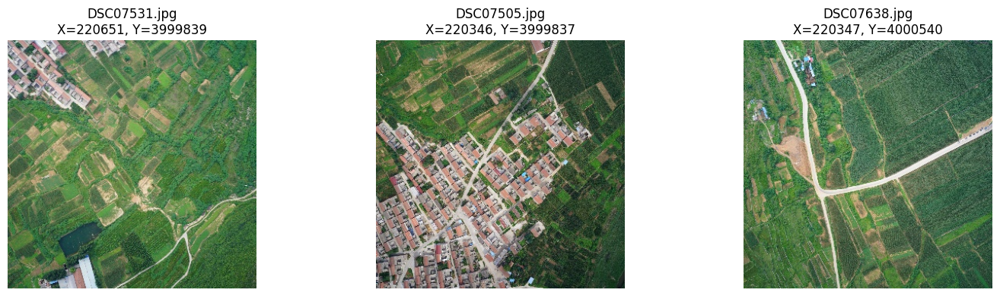


VALIDATION
Fichier : DSC07243.jpg | X : 219597.67 | Y : 3999563.74 | Existe : True
Fichier : DSC07332.jpg | X : 217155.39 | Y : 4001592.25 | Existe : True
Fichier : DSC07132.jpg | X : 221527.92 | Y : 3996667.46 | Existe : True


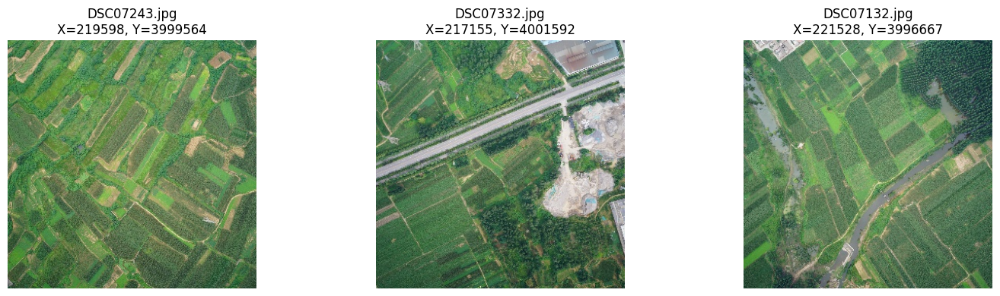


TEST
Fichier : DSC07197.jpg | X : 220225.62 | Y : 3998601.82 | Existe : True
Fichier : DSC07399.jpg | X : 219867.97 | Y : 3999879.06 | Existe : True
Fichier : DSC07518.jpg | X : 221652.26 | Y : 3998582.04 | Existe : True


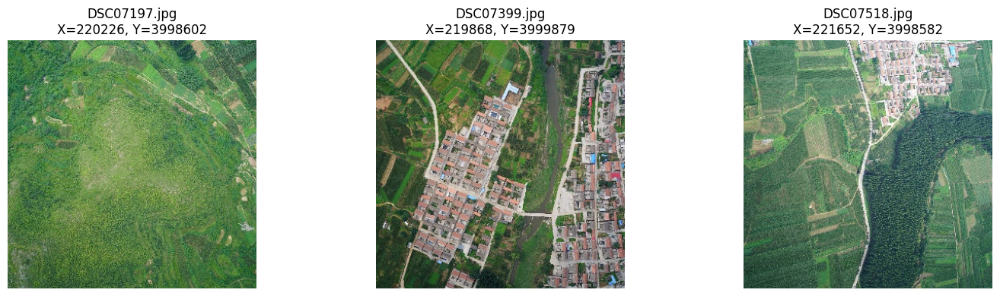


RÉGION : CuiJiaQiao

TRAIN
Fichier : DSC00822.jpg | X : 277806.57 | Y : 4001895.89 | Existe : True
Fichier : DSC00943.jpg | X : 269944.25 | Y : 4002953.35 | Existe : True
Fichier : DSC01019.jpg | X : 271917.76 | Y : 4003879.33 | Existe : True


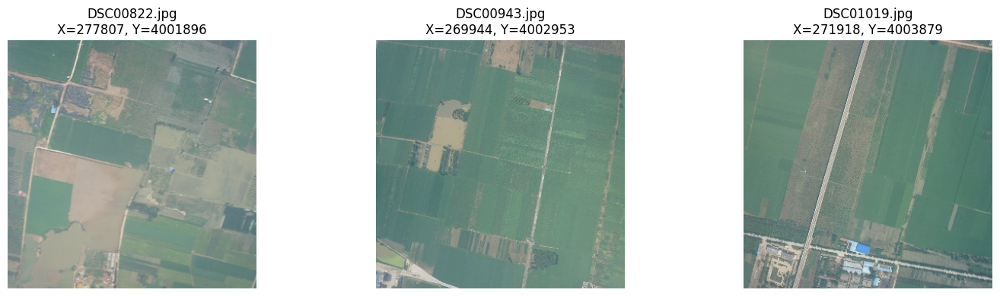


VALIDATION
Fichier : DSC00902.jpg | X : 280547.11 | Y : 4002340.16 | Existe : True
Fichier : DSC01002.jpg | X : 276751.39 | Y : 4003817.77 | Existe : True
Fichier : DSC01025.jpg | X : 270216.27 | Y : 4003904.74 | Existe : True


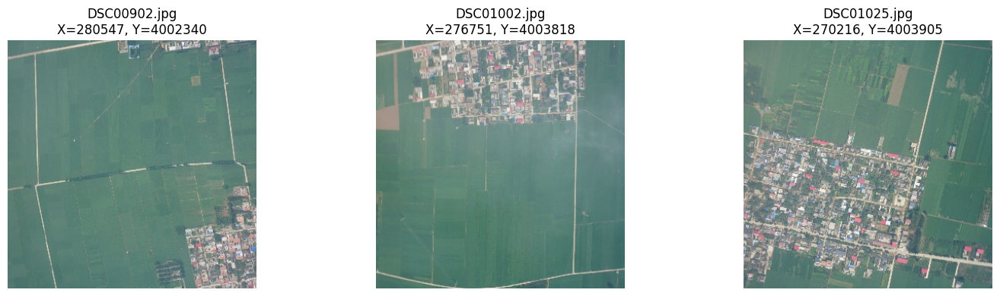


TEST
Fichier : DSC00853.jpg | X : 268979.65 | Y : 4002009.02 | Existe : True
Fichier : DSC00986.jpg | X : 277785.3 | Y : 4003327.01 | Existe : True
Fichier : DSC01000.jpg | X : 277317.15 | Y : 4003809.27 | Existe : True


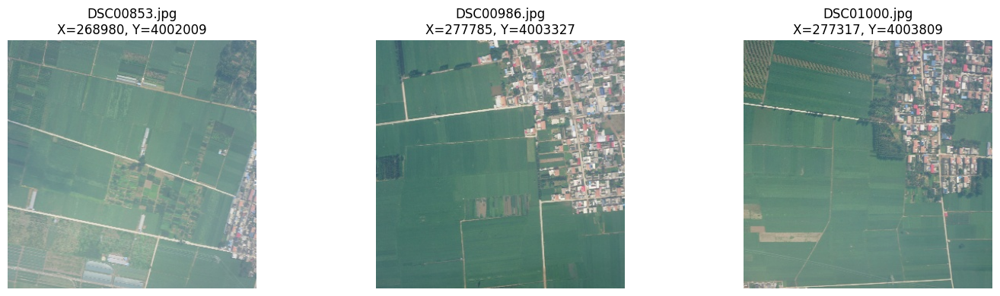

Fin de l'inspection visuelle.


In [90]:
# ============================================================
# CELLULE 86 — ÉCHANTILLON D'AUDIT IMAGE / COORDONNÉES
# ============================================================

from PIL import Image
import matplotlib.pyplot as plt
import os
import numpy as np

for region in ["AnYangRiver", "CuiJiaQiao"]:
    print("\n", "=" * 60)
    print("RÉGION :", region)
    print("=" * 60)

    for split_name, frame in [
        ("TRAIN", train_df),
        ("VALIDATION", val_df),
        ("TEST", test_df)
    ]:
        subset = (
            frame[frame["region"] == region]
            .sample(n=min(3, len(frame[frame["region"] == region])),
                    random_state=42)
        )

        print(f"\n{split_name}")
        for _, row in subset.iterrows():
            print(
                "Fichier :", os.path.basename(row["image_path"]),
                "| X :", round(float(row["target_x_m"]), 2),
                "| Y :", round(float(row["target_y_m"]), 2),
                "| Existe :", os.path.isfile(row["image_path"])
            )

        if len(subset):
            fig, axes = plt.subplots(
                1, len(subset), figsize=(5 * len(subset), 4)
            )
            axes = np.atleast_1d(axes)

            for ax, (_, row) in zip(axes, subset.iterrows()):
                with Image.open(row["image_path"]) as im:
                    ax.imshow(im.convert("RGB"))
                ax.set_title(
                    f"{os.path.basename(row['image_path'])}\n"
                    f"X={row['target_x_m']:.0f}, "
                    f"Y={row['target_y_m']:.0f}"
                )
                ax.axis("off")

            plt.tight_layout()
            plt.show()

print("Fin de l'inspection visuelle.")

In [91]:
# ============================================================
# CELLULE 87 — AUDIT DES CIBLES GPS ET DE LA DISPERSION SPATIALE
# ============================================================

import numpy as np
import pandas as pd

for region in ["AnYangRiver", "CuiJiaQiao"]:
    print("\n" + "=" * 70)
    print("RÉGION :", region)
    print("=" * 70)

    for split_name, frame in [
        ("TRAIN", train_df),
        ("VALIDATION", val_df),
        ("TEST", test_df)
    ]:
        g = frame[frame["region"] == region]
        if len(g) == 0:
            continue

        print(f"\n{split_name} — n={len(g)}")
        for col in ["target_x_m", "target_y_m"]:
            if col in g.columns:
                print(
                    f"{col}: min={g[col].min():.2f}, "
                    f"max={g[col].max():.2f}, "
                    f"moyenne={g[col].mean():.2f}, "
                    f"écart-type={g[col].std():.2f}"
                )

    # Comparaison avec les coordonnées GPS d'origine si disponibles
    g = df_2regions[df_2regions["region"] == region].copy()

    print("\nColonnes GPS d'origine disponibles :")
    print([
        c for c in [
            "lon", "lat", "target_lon", "target_lat",
            "GPS_Alt", "pixel_x", "pixel_y"
        ] if c in g.columns
    ])

    if {"lon", "lat", "target_lon", "target_lat"}.issubset(g.columns):
        print("\nÉcart entre GPS original et cible GPS :")
        print("Écart longitude moyen (degrés) :",
              (g["lon"] - g["target_lon"]).abs().mean())
        print("Écart latitude moyen (degrés) :",
              (g["lat"] - g["target_lat"]).abs().mean())

print("\nAudit terminé. Aucune modification des données.")


RÉGION : AnYangRiver

TRAIN — n=451
target_x_m: min=213429.71, max=222878.98, moyenne=219383.08, écart-type=2312.51
target_y_m: min=3994005.60, max=4004143.44, moyenne=3999631.90, écart-type=2602.78

VALIDATION — n=97
target_x_m: min=213982.56, max=222488.55, moyenne=219258.53, écart-type=2409.01
target_y_m: min=3994567.60, max=4003683.63, moyenne=3999719.73, écart-type=2728.48

TEST — n=97
target_x_m: min=213678.03, max=222516.97, moyenne=219644.80, écart-type=2442.95
target_y_m: min=3993777.84, max=4004244.27, moyenne=3999187.76, écart-type=2798.88

Colonnes GPS d'origine disponibles :
['lon', 'lat', 'target_lon', 'target_lat', 'GPS_Alt', 'pixel_x', 'pixel_y']

Écart entre GPS original et cible GPS :
Écart longitude moyen (degrés) : 0.00024175885403628203
Écart latitude moyen (degrés) : 0.0002909369618400438

RÉGION : CuiJiaQiao

TRAIN — n=424
target_x_m: min=267733.18, max=281883.23, moyenne=274849.21, écart-type=3644.93
target_y_m: min=3998212.69, max=4004893.11, moyenne=4001511.0

In [92]:
# CELLULE 88 — COMPARAISON GPS EN MÈTRES
import numpy as np
import pandas as pd
from pyproj import Transformer

gps_to_utm = Transformer.from_crs(
    "EPSG:4326", "EPSG:32650", always_xy=True
)

for region in ["AnYangRiver", "CuiJiaQiao"]:
    g = df_2regions[df_2regions["region"] == region].copy()

    required = ["lon", "lat", "target_lon", "target_lat"]
    if not all(c in g.columns for c in required):
        print(region, ": colonnes GPS manquantes")
        continue

    g = g.dropna(subset=required)

    x1, y1 = gps_to_utm.transform(
        g["lon"].to_numpy(), g["lat"].to_numpy()
    )
    x2, y2 = gps_to_utm.transform(
        g["target_lon"].to_numpy(), g["target_lat"].to_numpy()
    )

    d = np.hypot(np.asarray(x1) - np.asarray(x2),
                 np.asarray(y1) - np.asarray(y2))

    print(f"\n{region} — n={len(g)}")
    print(f"Écart GPS médian : {np.median(d):.2f} m")
    print(f"Écart GPS moyen  : {np.mean(d):.2f} m")
    print(f"Écart GPS P90    : {np.percentile(d, 90):.2f} m")
    print(f"Écart GPS maximal: {np.max(d):.2f} m")


AnYangRiver — n=645
Écart GPS médian : 25.57 m
Écart GPS moyen  : 43.02 m
Écart GPS P90    : 55.83 m
Écart GPS maximal: 359.11 m

CuiJiaQiao — n=607
Écart GPS médian : 26.15 m
Écart GPS moyen  : 30.08 m
Écart GPS P90    : 44.37 m
Écart GPS maximal: 400.92 m


In [93]:
# CELLULE 89A — DIAGNOSTIC DE L'EXECUTION

print("=== DEBUT DU DIAGNOSTIC ===", flush=True)

# 1. Vérifier que le DataFrame existe
if "df_2regions" not in globals():
    print("ERREUR : df_2regions n'existe pas.", flush=True)
else:
    print("df_2regions existe.", flush=True)
    print("Dimensions :", df_2regions.shape, flush=True)
    print("Colonnes :", list(df_2regions.columns), flush=True)

    # 2. Vérifier les régions
    if "region" in df_2regions.columns:
        print("\nNombre d'images par région :", flush=True)
        print(df_2regions["region"].value_counts(dropna=False), flush=True)
    else:
        print("ERREUR : colonne 'region' absente.", flush=True)

    # 3. Vérifier les colonnes GPS
    colonnes = ["lon", "lat", "target_lon", "target_lat"]
    absentes = [c for c in colonnes if c not in df_2regions.columns]

    if absentes:
        print("\nColonnes GPS absentes :", absentes, flush=True)
    else:
        print("\nExemples de coordonnées :", flush=True)
        print(df_2regions[colonnes].head(5).to_string(index=False), flush=True)

print("\n=== FIN DU DIAGNOSTIC ===", flush=True)

=== DEBUT DU DIAGNOSTIC ===
df_2regions existe.
Dimensions : (1252, 16)
Colonnes : ['region', 'id', 'image_path', 'image_status', 'lon', 'lat', 'GPS_Alt', 'roll', 'pitch', 'yaw', 'target_lon', 'target_lat', 'relative_altitude', 'pixel_x', 'pixel_y', 'split']

Nombre d'images par région :
region
AnYangRiver    645
CuiJiaQiao     607
Name: count, dtype: int64

Exemples de coordonnées :
       lon       lat  target_lon  target_lat
113.828574 36.137679  113.829138   36.140070
113.898492 36.093354  113.898554   36.093172
113.915203 36.050924  113.914998   36.050955
113.884767 36.109658  113.884769   36.109479
113.828705 36.130972  113.828642   36.130892

=== FIN DU DIAGNOSTIC ===


In [94]:
# CELLULE 89B — INSPECTION DES ECARTS GPS
import numpy as np
import pandas as pd
from pyproj import Transformer

print("Début de l'inspection GPS...", flush=True)

try:
    transformer = Transformer.from_crs(
        "EPSG:4326", "EPSG:32650", always_xy=True
    )

    colonnes = ["lon", "lat", "target_lon", "target_lat"]
    df_gps = df_2regions.copy()

    # Conversion numérique et suppression des coordonnées invalides
    for col in colonnes:
        df_gps[col] = pd.to_numeric(df_gps[col], errors="coerce")

    df_gps = df_gps.dropna(subset=colonnes)

    df_gps = df_gps[
        df_gps["lon"].between(-180, 180)
        & df_gps["target_lon"].between(-180, 180)
        & df_gps["lat"].between(-90, 90)
        & df_gps["target_lat"].between(-90, 90)
    ].copy()

    x1, y1 = transformer.transform(
        df_gps["lon"].to_numpy(),
        df_gps["lat"].to_numpy()
    )
    x2, y2 = transformer.transform(
        df_gps["target_lon"].to_numpy(),
        df_gps["target_lat"].to_numpy()
    )

    df_gps["ecart_m"] = np.hypot(
        np.asarray(x1) - np.asarray(x2),
        np.asarray(y1) - np.asarray(y2)
    )

    colonnes_affichage = [
        "region", "id", "lon", "lat",
        "target_lon", "target_lat", "ecart_m"
    ]

    for col in ["GPS_Alt", "relative_altitude", "pixel_x", "pixel_y"]:
        if col in df_gps.columns:
            colonnes_affichage.append(col)

    for region in ["AnYangRiver", "CuiJiaQiao"]:
        sous_df = df_gps[df_gps["region"] == region]

        print(f"\n{'=' * 75}", flush=True)
        print(f"{region} — 15 plus grands écarts", flush=True)
        print(f"Nombre de lignes : {len(sous_df)}", flush=True)

        print(
            sous_df.nlargest(15, "ecart_m")[colonnes_affichage]
            .round(6)
            .to_string(index=False),
            flush=True
        )

    print("\nInspection terminée.", flush=True)

except Exception as e:
    print(f"ERREUR : {type(e).__name__}: {e}", flush=True)
    raise

Début de l'inspection GPS...

AnYangRiver — 15 plus grands écarts
Nombre de lignes : 645
     region       id        lon       lat  target_lon  target_lat    ecart_m  GPS_Alt  relative_altitude  pixel_x  pixel_y
AnYangRiver DSC07034 113.906432 36.057827  113.903024   36.056152 359.114154    883.7              610.7     9426    10960
AnYangRiver DSC07024 113.918401 36.051295  113.921939   36.051835 324.552098    879.6              624.6    11189    11457
AnYangRiver DSC07138 113.900608 36.078899  113.897550   36.077455 318.793740    882.2              622.2     8916     8503
AnYangRiver DSC07571 113.848698 36.129153  113.845547   36.127998 311.454948    881.4              604.4     4069     2673
AnYangRiver DSC07047 113.920369 36.054276  113.923617   36.053489 305.528906    880.4              613.4    11346    11267
AnYangRiver DSC07179 113.914202 36.080168  113.917585   36.080098 304.980612    880.3              617.3    10784     8198
AnYangRiver DSC07377 113.911742 36.088502  113.910

In [95]:
# CELLULE 90 — RECHERCHE DES ANNOTATIONS ORIGINALES
from pathlib import Path

racine = Path(
    "/kaggle/input/datasets/maissawahbi/"
    "uavloc-m3-dataset/UAVLoc-M3_dataset"
)

print("Racine trouvée :", racine.exists())
print("Recherche des fichiers d'annotations...")

extensions = {".csv", ".txt", ".json", ".xlsx"}

fichiers = []
for p in racine.rglob("*"):
    if p.is_file() and p.suffix.lower() in extensions:
        fichiers.append(p)

print("Nombre de fichiers candidats :", len(fichiers))

for p in fichiers[:100]:
    print(p.relative_to(racine))

# Rechercher les identifiants qui présentent les plus grands écarts
identifiants = [
    "DSC07034", "DSC07024", "DSC00515",
    "DSC00761", "DSC01034"
]

print("\nRecherche des identifiants dans les fichiers texte...")
for p in fichiers:
    if p.suffix.lower() not in {".csv", ".txt", ".json"}:
        continue

    try:
        contenu = p.read_text(encoding="utf-8", errors="ignore")
        trouves = [identifiant for identifiant in identifiants
                   if identifiant in contenu]

        if trouves:
            print(f"\nFichier : {p.relative_to(racine)}")
            print("Identifiants trouvés :", ", ".join(trouves))
    except Exception as e:
        print("Lecture impossible :", p.name, str(e))

Racine trouvée : True
Recherche des fichiers d'annotations...
Nombre de fichiers candidats : 9
AnYangRiver/AnYangRiver.xlsx
AnYangRiver/location_with_dem.xlsx
AnYangRiver/pxGT_dem.xlsx
Chongmingdao/Chongmingdao.xlsx
Chongmingdao/location_with_dem.xlsx
Chongmingdao/pxGT_dem.xlsx
CuiJiaQiao/CuiJiaQiao.xlsx
CuiJiaQiao/location_with_dem.xlsx
CuiJiaQiao/pxGT_dem.xlsx

Recherche des identifiants dans les fichiers texte...


In [96]:
# ============================================================
# CELLULE 138 — ANALYSE RAPIDE ROLL / PITCH
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# Utiliser directement les colonnes nécessaires
d = df_check[
    ["roll", "pitch", "distance_drone_cible_m"]
].dropna()

# Valeurs absolues
abs_roll = d["roll"].abs()
abs_pitch = d["pitch"].abs()
distance = d["distance_drone_cible_m"]

print("=" * 65)
print("1. DISTANCE SELON LE PITCH")
print("=" * 65)

bins = [-np.inf, 2, 5, 10, np.inf]
labels = ["Faible", "Modérée", "Forte", "Très forte"]

pitch_cat = pd.cut(abs_pitch, bins=bins, labels=labels)

print(
    d.assign(categorie=pitch_cat)
     .groupby("categorie", observed=False)["distance_drone_cible_m"]
     .agg(["count", "median", "mean"])
     .round(2)
)

print("\n" + "=" * 65)
print("2. CORRELATIONS")
print("=" * 65)

for nom, angle in [
    ("|Roll|", abs_roll),
    ("|Pitch|", abs_pitch),
]:
    rho, p = spearmanr(angle, distance)
    print(f"{nom:10s}: rho={rho:.4f} | p={p:.2e}")

# Norme angulaire combinée
angle_combine = np.hypot(abs_roll, abs_pitch)
rho, p = spearmanr(angle_combine, distance)

print(f"{'Roll+Pitch':10s}: rho={rho:.4f} | p={p:.2e}")

print("\n" + "=" * 65)
print("3. DISTANCES > 100 m")
print("=" * 65)

suspects = d.loc[
    distance > 100,
    ["roll", "pitch", "distance_drone_cible_m"]
]

print("Nombre :", len(suspects))
print(suspects.sort_values(
    "distance_drone_cible_m",
    ascending=False
).head(10).round(2).to_string())

print("\nFIN CELLULE 138")

NameError: name 'df_check' is not defined

In [ ]:
# ============================================================
# DIAGNOSTIC — VARIABLES DISPONIBLES
# ============================================================

import pandas as pd

print("=" * 60)
print("DATAFRAMES DISPONIBLES")
print("=" * 60)

for nom, objet in list(globals().items()):
    if isinstance(objet, pd.DataFrame):
        print(f"{nom:30s} | shape = {objet.shape}")

print("\n" + "=" * 60)
print("VARIABLES IMPORTANTES")
print("=" * 60)

noms = [
    "df", "df_pose", "df_chong", "df_chong_111",
    "df_chong_metric", "df_check", "train_df",
    "val_df", "test_df"
]

for nom in noms:
    print(f"{nom:25s} : {'OUI' if nom in globals() else 'NON'}")

In [ ]:
# ============================================================
# CELLULE 140 — VERIFICATION DES FICHIERS ET CHECKPOINTS
# ============================================================

import os

paths = [
    "/kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset",
    "/kaggle/working/ViTOutdoorLoc_outputs",
]

for path in paths:
    print("\n", "=" * 65)
    print("CHEMIN :", path)

    if os.path.exists(path):
        print("STATUT : DISPONIBLE")
        print("CONTENU :")

        for name in os.listdir(path)[:15]:
            print(" -", name)
    else:
        print("STATUT : INTROUVABLE")

In [ ]:
# ============================================================
# CELLULE 141 — RECHERCHE DES CHECKPOINTS
# ============================================================

import os

roots = ["/kaggle/working", "/kaggle/input"]

extensions = (".pth", ".pt", ".ckpt")

for root in roots:
    print(f"\nRecherche dans : {root}")

    for current, dirs, files in os.walk(root):
        # Limiter la recherche aux dossiers utiles
        dirs[:] = [
            d for d in dirs
            if d not in [".cache", "node_modules"]
        ]

        for file in files:
            if file.lower().endswith(extensions):
                path = os.path.join(current, file)
                size_mb = os.path.getsize(path) / (1024**2)
                print(f"{size_mb:.2f} MB | {path}")

In [ ]:
# ============================================================
# CELLULE 142 — RECHERCHE DES ANNOTATIONS
# ============================================================

import os

ROOT = "/kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset"

extensions = (".csv", ".xlsx", ".xls", ".json", ".txt")

for region in ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]:
    region_path = os.path.join(ROOT, region)

    print("\n" + "=" * 60)
    print("REGION :", region)
    print("=" * 60)

    for current, dirs, files in os.walk(region_path):
        for file in files:
            if file.lower().endswith(extensions):
                print(os.path.join(current, file))

In [ ]:
# ============================================================
# CELLULE 143 — INSPECTION DES FICHIERS EXCEL
# ============================================================

import os
import pandas as pd

ROOT = "/kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset"

for region in ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]:

    path = os.path.join(ROOT, region, f"{region}.xlsx")

    print("\n" + "=" * 70)
    print("REGION :", region)
    print("=" * 70)

    excel = pd.ExcelFile(path)

    for sheet in excel.sheet_names:
        temp = pd.read_excel(path, sheet_name=sheet, nrows=5)

        print(f"\nFeuille : {sheet}")
        print("Colonnes :", temp.columns.tolist())
        print("Dimensions échantillon :", temp.shape)
        print(temp.head(2).to_string(index=False))

print("\nFIN CELLULE 143")

In [ ]:
# ============================================================
# CELLULE 144 — RECHARGEMENT DES ANNOTATIONS UAVLoc-M3
# ============================================================

import os
import pandas as pd
import numpy as np

ROOT = "/kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset"

regions = ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]

colonnes_pose = [
    "id", "lon", "lat", "GPS_Alt",
    "roll", "pitch", "yaw"
]

dataframes = []

for region in regions:

    path = os.path.join(ROOT, region, f"{region}.xlsx")

    df_region = pd.read_excel(
        path,
        sheet_name=0,
        usecols=colonnes_pose
    )

    df_region = df_region.copy()
    df_region["region"] = region

    for col in colonnes_pose[1:]:
        df_region[col] = pd.to_numeric(
            df_region[col], errors="coerce"
        )

    df_region = df_region.dropna(
        subset=colonnes_pose
    ).copy()

    dataframes.append(df_region)

    print(
        f"{region:15s} | "
        f"{len(df_region):5d} observations | "
        f"{df_region.shape[1]} colonnes"
    )

# Fusion des trois régions
df_pose_all = pd.concat(
    dataframes,
    ignore_index=True
)

print("\n" + "=" * 65)
print("BILAN GENERAL")
print("=" * 65)

print("Total observations :", len(df_pose_all))
print("Dimensions :", df_pose_all.shape)
print("\nRépartition par région :")
print(df_pose_all["region"].value_counts())

print("\nValeurs manquantes :")
print(df_pose_all[colonnes_pose].isna().sum())

print("\nAperçu :")
print(df_pose_all.head())

print("\nFIN CELLULE 144")

In [ ]:
# ============================================================
# CELLULE 145 — VALIDATION DES ANGLES ET ORIENTATION
# ============================================================

import numpy as np
import pandas as pd

df_pose_all["roll_rad"] = np.deg2rad(df_pose_all["roll"])
df_pose_all["pitch_rad"] = np.deg2rad(df_pose_all["pitch"])
df_pose_all["yaw_rad"] = np.deg2rad(df_pose_all["yaw"])

df_pose_all["yaw_sin"] = np.sin(df_pose_all["yaw_rad"])
df_pose_all["yaw_cos"] = np.cos(df_pose_all["yaw_rad"])

print("=" * 65)
print("1. STATISTIQUES DES ANGLES (DEGRES)")
print("=" * 65)

print(
    df_pose_all.groupby("region")[
        ["roll", "pitch", "yaw"]
    ].agg(["min", "max", "mean", "std"]).round(3)
)

print("\n" + "=" * 65)
print("2. VERIFICATION SINUS / COSINUS")
print("=" * 65)

norme = np.sqrt(
    df_pose_all["yaw_sin"]**2 +
    df_pose_all["yaw_cos"]**2
)

print("Norme minimale :", norme.min())
print("Norme maximale :", norme.max())
print("Toutes les normes proches de 1 :",
      np.allclose(norme, 1.0, atol=1e-10))

print("\n" + "=" * 65)
print("3. EXEMPLES")
print("=" * 65)

print(
    df_pose_all[
        ["id", "region", "roll", "pitch", "yaw",
         "yaw_sin", "yaw_cos"]
    ].head(8).round(5).to_string(index=False)
)

print("\nFIN CELLULE 145")

In [ ]:
# ============================================================
# CELLULE 146 — AUDIT DES COORDONNEES GPS DU DRONE
# ============================================================

import numpy as np
import pandas as pd

cols = ["lon", "lat", "GPS_Alt"]

print("=" * 70)
print("1. STATISTIQUES GPS PAR REGION")
print("=" * 70)

stats = df_pose_all.groupby("region")[cols].agg(
    ["count", "min", "max", "mean", "std"]
)

print(stats.round(6).to_string())

print("\n" + "=" * 70)
print("2. VERIFICATION DES VALEURS")
print("=" * 70)

for col in cols:
    values = df_pose_all[col].to_numpy()

    print(
        f"{col:10s} | "
        f"min={np.min(values):.6f} | "
        f"max={np.max(values):.6f} | "
        f"NaN={np.isnan(values).sum()} | "
        f"Inf={np.isinf(values).sum()}"
    )

print("\n" + "=" * 70)
print("3. CENTRES GPS DES REGIONS")
print("=" * 70)

centres = df_pose_all.groupby("region")[
    ["lon", "lat", "GPS_Alt"]
].mean()

print(centres.round(6).to_string())

print("\nFIN CELLULE 146")

In [ ]:
# ============================================================
# CELLULE 147 — INSPECTION DES FICHIERS AVEC DONNEES DEM
# ============================================================

import os
import pandas as pd

DATASET_ROOT = (
    "/kaggle/input/datasets/maissawahbi/"
    "uavloc-m3-dataset/UAVLoc-M3_dataset"
)

for region in ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]:

    print("\n" + "=" * 75)
    print("REGION :", region)
    print("=" * 75)

    for filename in ["location_with_dem.xlsx", "pxGT_dem.xlsx"]:

        path = os.path.join(DATASET_ROOT, region, filename)

        if not os.path.exists(path):
            print(f"\nFichier absent : {filename}")
            continue

        print(f"\n--- {filename} ---")

        try:
            excel = pd.ExcelFile(path)
            print("Feuilles :", excel.sheet_names)

            for sheet in excel.sheet_names:
                df_tmp = pd.read_excel(
                    path,
                    sheet_name=sheet,
                    nrows=3
                )

                print(f"\nFeuille : {sheet}")
                print("Colonnes :", df_tmp.columns.tolist())
                print(df_tmp.head(2).to_string(index=False))

        except Exception as e:
            print("Erreur de lecture :", repr(e))

print("\nFIN CELLULE 147")

In [ ]:
# ============================================================
# CELLULE 148 — FUSION DES ANNOTATIONS PAR IDENTIFIANT
# ============================================================

import os
import numpy as np
import pandas as pd

DATASET_ROOT = (
    "/kaggle/input/datasets/maissawahbi/"
    "uavloc-m3-dataset/UAVLoc-M3_dataset"
)

regions = ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]
tables = []

for region in regions:
    folder = os.path.join(DATASET_ROOT, region)

    # Annotations GPS et orientation du drone
    pose_path = os.path.join(folder, f"{region}.xlsx")
    pose = pd.read_excel(pose_path, sheet_name=0)

    pose = pose[
        ["id", "lon", "lat", "GPS_Alt", "roll", "pitch", "yaw"]
    ].copy()

    # Position de la cible et altitude relative
    loc_path = os.path.join(folder, "location_with_dem.xlsx")
    loc = pd.read_excel(loc_path, sheet_name=0)

    loc = loc[
        ["id", "target_lon", "target_lat", "relative_altitude"]
    ].copy()

    # Coordonnées pixel
    px_path = os.path.join(folder, "pxGT_dem.xlsx")
    px = pd.read_excel(px_path, sheet_name=0)

    px = px[["id", "pixel_x", "pixel_y"]].copy()

    # Normalisation des identifiants
    for table in [pose, loc, px]:
        table["id"] = table["id"].astype(str).str.strip()

    # Vérification des doublons avant fusion
    print(f"\n{region}")
    for name, table in [("pose", pose), ("location", loc), ("pixel", px)]:
        print(
            f"{name:10s}: lignes={len(table)}, "
            f"IDs uniques={table['id'].nunique()}, "
            f"doublons={table['id'].duplicated().sum()}"
        )

    if any(t["id"].duplicated().any() for t in [pose, loc, px]):
        raise ValueError(f"Identifiants dupliqués dans {region}")

    merged = pose.merge(
        loc, on="id", how="inner", validate="one_to_one"
    )

    merged = merged.merge(
        px, on="id", how="inner", validate="one_to_one"
    )

    merged["region"] = region
    tables.append(merged)

df_all = pd.concat(tables, ignore_index=True)

# Conversion numérique
numeric_cols = [
    "lon", "lat", "GPS_Alt", "roll", "pitch", "yaw",
    "target_lon", "target_lat", "relative_altitude",
    "pixel_x", "pixel_y"
]

for col in numeric_cols:
    df_all[col] = pd.to_numeric(df_all[col], errors="coerce")

print("\n" + "=" * 75)
print("BILAN DE LA FUSION")
print("=" * 75)

print("Dimensions :", df_all.shape)
print("\nNombre de lignes par région :")
print(df_all.groupby("region").size())

print("\nValeurs manquantes :")
print(df_all[numeric_cols].isna().sum())

print("\nExemples :")
print(df_all.head(5).to_string(index=False))

print("\nFIN CELLULE 148")

In [ ]:
# ============================================================
# CELLULE 149 — CONTROLE GPS_ALT / RELATIVE_ALTITUDE
# ============================================================

df_all["ground_altitude_implied"] = (
    df_all["GPS_Alt"] - df_all["relative_altitude"]
)

print("=" * 75)
print("GPS_Alt - relative_altitude : altitude de terrain implicite")
print("=" * 75)

summary = df_all.groupby("region").agg(
    n=("id", "count"),
    gps_alt_mean=("GPS_Alt", "mean"),
    relative_alt_mean=("relative_altitude", "mean"),
    ground_min=("ground_altitude_implied", "min"),
    ground_max=("ground_altitude_implied", "max"),
    ground_mean=("ground_altitude_implied", "mean"),
    ground_std=("ground_altitude_implied", "std")
)

print(summary.round(3).to_string())

print("\nContrôle de la relation GPS_Alt ≈ terrain + altitude relative :")
df_all["altitude_reconstruction_error"] = (
    df_all["GPS_Alt"]
    - (
        df_all["ground_altitude_implied"]
        + df_all["relative_altitude"]
    )
)

print(
    df_all.groupby("region")["altitude_reconstruction_error"]
    .agg(["min", "max", "mean"])
    .round(8)
)

print("\nFIN CELLULE 149")

In [ ]:
# ============================================================
# CELLULE 150 — REPERE SPATIAL COMMUN ENU (METRES)
# ============================================================

import numpy as np

try:
    from pyproj import Transformer
except ImportError:
    raise ImportError(
        "pyproj n'est pas installé. Installer pyproj avant de continuer."
    )

# Vérifier les coordonnées nécessaires
required = ["lon", "lat", "GPS_Alt"]
if df_all[required].isna().any().any():
    raise ValueError("Valeurs GPS manquantes : conversion interrompue.")

# Référence commune calculée sur les trois régions
lon0 = df_all["lon"].mean()
lat0 = df_all["lat"].mean()
h0 = df_all["GPS_Alt"].mean()

# WGS84 géographique 3D -> géocentrique ECEF
to_ecef = Transformer.from_crs(
    "EPSG:4979", "EPSG:4978", always_xy=True
)

X, Y, Z = to_ecef.transform(
    df_all["lon"].to_numpy(),
    df_all["lat"].to_numpy(),
    df_all["GPS_Alt"].to_numpy()
)

X0, Y0, Z0 = to_ecef.transform(lon0, lat0, h0)

# Différences ECEF
dX = np.asarray(X) - X0
dY = np.asarray(Y) - Y0
dZ = np.asarray(Z) - Z0

# Rotation ECEF -> ENU au point de référence
lam = np.deg2rad(lon0)
phi = np.deg2rad(lat0)

df_all["x_east_m"] = (
    -np.sin(lam) * dX + np.cos(lam) * dY
)

df_all["y_north_m"] = (
    -np.sin(phi) * np.cos(lam) * dX
    -np.sin(phi) * np.sin(lam) * dY
    +np.cos(phi) * dZ
)

df_all["z_up_m_provisional"] = (
    np.cos(phi) * np.cos(lam) * dX
    +np.cos(phi) * np.sin(lam) * dY
    +np.sin(phi) * dZ
)

print("Référence ENU commune :")
print(f"Longitude : {lon0:.6f}°")
print(f"Latitude  : {lat0:.6f}°")
print(f"Altitude  : {h0:.3f} m")

print("\nEtendue ENU par région (mètres) :")
print(
    df_all.groupby("region")[
        ["x_east_m", "y_north_m", "z_up_m_provisional"]
    ].agg(["min", "max", "mean"]).round(2)
)

print(
    "\nATTENTION : z_up_m_provisional est provisoire "
    "jusqu'à confirmation du référentiel vertical de GPS_Alt."
)

print("\nFIN CELLULE 150")

In [ ]:
# ============================================================
# CELLULE 151-A — RECHERCHE RAPIDE DES IMAGES
# ============================================================

from pathlib import Path
from collections import Counter

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

image_map = {}
duplicate_stems = []

for region in regions:
    print(f"Recherche : {region}...", flush=True)

    folder = Path(DATASET_ROOT) / region

    files = [
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    print(f"Images trouvées : {len(files)}", flush=True)

    for path in files:
        key = (region, path.stem.strip())

        if key in image_map:
            duplicate_stems.append(key)
        else:
            image_map[key] = str(path)

print("\nTotal images :", len(image_map))
print("Identifiants dupliqués :", len(duplicate_stems))

# Associer les chemins aux annotations
df_all["image_path"] = [
    image_map.get((r, str(i).strip()))
    for r, i in zip(df_all["region"], df_all["id"])
]

print("\nCorrespondances :")
print(
    df_all.groupby("region")["image_path"]
    .agg(
        total="count",
        trouvees=lambda s: s.notna().sum()
    )
)

print("\nImages absentes :", df_all["image_path"].isna().sum())
print("FIN CELLULE 151-A")

In [ ]:
# ============================================================
# CELLULE 151-B — TEST D'INTEGRITE DES IMAGES
# ============================================================

from PIL import Image
from tqdm.auto import tqdm

paths = df_all["image_path"].tolist()

image_ok = []
image_sizes = []

for path in tqdm(paths, desc="Vérification des images"):
    if not isinstance(path, str):
        image_ok.append(False)
        image_sizes.append(None)
        continue

    try:
        with Image.open(path) as im:
            im.verify()

        with Image.open(path) as im:
            image_sizes.append(im.size)

        image_ok.append(True)

    except Exception:
        image_ok.append(False)
        image_sizes.append(None)

df_all["image_ok"] = image_ok
df_all["image_size"] = image_sizes

print("\nBILAN :")
print(
    df_all.groupby("region").agg(
        annotations=("id", "count"),
        images_trouvees=("image_path", lambda s: s.notna().sum()),
        images_lisibles=("image_ok", "sum")
    )
)

print("\nImages absentes :", df_all["image_path"].isna().sum())
print(
    "Images corrompues :",
    (
        df_all["image_path"].notna() & ~df_all["image_ok"]
    ).sum()
)

print("\nDimensions des images lisibles :")
print(
    df_all.loc[df_all["image_ok"], "image_size"]
    .value_counts()
)

print("\nFIN CELLULE 151-B")

In [ ]:
# ============================================================
# DIAGNOSTIC — POURQUOI df_valid EST VIDE ?
# ============================================================

print("=" * 70)
print("1. DIMENSIONS DES DATAFRAMES")
print("=" * 70)

print("df_all :", df_all.shape)

if "image_path" in df_all.columns:
    print("Chemins d'images présents :", df_all["image_path"].notna().sum())
else:
    print("ERREUR : colonne image_path absente")

if "image_ok" in df_all.columns:
    print("\nValeurs de image_ok :")
    print(df_all["image_ok"].value_counts(dropna=False))
else:
    print("ERREUR : colonne image_ok absente")

print("\n" + "=" * 70)
print("2. REPARTITION PAR REGION")
print("=" * 70)

if "image_ok" in df_all.columns:
    print(
        df_all.groupby("region")["image_ok"]
        .value_counts(dropna=False)
        .to_string()
    )

print("\n" + "=" * 70)
print("3. EXEMPLES DE LIGNES")
print("=" * 70)

cols = [
    c for c in ["region", "id", "image_path", "image_ok"]
    if c in df_all.columns
]

print(df_all[cols].head(10).to_string(index=False))

print("\n" + "=" * 70)
print("4. NOMBRE D'OBSERVATIONS VALIDES")
print("=" * 70)

if "image_ok" in df_all.columns:
    print("Images valides :", int(df_all["image_ok"].eq(True).sum()))
    print("Images invalides :", int(df_all["image_ok"].eq(False).sum()))

print("\nFIN DIAGNOSTIC")

In [ ]:
# ============================================================
# CELLULE 151-C — LOCALISATION RECURSIVE DES IMAGES
# ============================================================

from pathlib import Path

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

for region in regions:
    folder = Path(DATASET_ROOT) / region

    print("\n" + "=" * 70)
    print("REGION :", region)
    print("=" * 70)

    # Recherche récursive, sans ouvrir les images
    files = [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    print("Nombre d'images trouvées :", len(files))

    print("\nPremiers chemins :")
    for p in files[:8]:
        print(p)

    print("\nDossiers contenant les images :")
    folders = sorted(set(str(p.parent) for p in files))
    for f in folders[:10]:
        print(f)

print("\nFIN CELLULE 151-C")

In [ ]:
# ============================================================
# CELLULE 151-D — ASSOCIATION DES IMAGES DRONE AUX ANNOTATIONS
# ============================================================

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
import pandas as pd

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

image_map = {}
duplicate_images = []

for region in regions:

    drone_dir = Path(DATASET_ROOT) / region / "drone"

    if not drone_dir.exists():
        raise FileNotFoundError(f"Dossier drone absent : {drone_dir}")

    # Recherche récursive UNIQUEMENT dans drone/
    files = [
        p for p in drone_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    print(f"{region} : {len(files)} images drone trouvées")

    for path in files:
        key = (region, path.stem.strip())

        if key in image_map:
            duplicate_images.append((region, path.stem))
        else:
            image_map[key] = str(path)

if duplicate_images:
    print("\nDoublons détectés :", duplicate_images[:20])
    raise ValueError("Des identifiants d'images sont dupliqués.")

# Association par région + identifiant
df_all["image_path"] = [
    image_map.get((region, str(image_id).strip()))
    for region, image_id in zip(df_all["region"], df_all["id"])
]

print("\n" + "=" * 70)
print("BILAN DE LA CORRESPONDANCE")
print("=" * 70)

for region in regions:
    part = df_all[df_all["region"] == region]

    print(
        f"{region:15s} | "
        f"annotations={len(part):4d} | "
        f"images associées={part['image_path'].notna().sum():4d} | "
        f"absentes={part['image_path'].isna().sum():4d}"
    )

print("\nTotal annotations :", len(df_all))
print("Total images associées :", df_all["image_path"].notna().sum())
print("Total images absentes :", df_all["image_path"].isna().sum())

print("\nExemples :")
print(
    df_all[["region", "id", "image_path"]]
    .head(8)
    .to_string(index=False)
)

print("\nFIN CELLULE 151-D")

In [ ]:
# ============================================================
# CELLULE 151-E — VERIFICATION DES IMAGES ASSOCIEES
# ============================================================

from PIL import Image
from tqdm.auto import tqdm

image_ok = []
image_sizes = []

for path in tqdm(
    df_all["image_path"],
    desc="Vérification des images drone"
):

    if not isinstance(path, str):
        image_ok.append(False)
        image_sizes.append(None)
        continue

    try:
        with Image.open(path) as im:
            im.verify()

        with Image.open(path) as im:
            image_sizes.append(im.size)

        image_ok.append(True)

    except Exception:
        image_ok.append(False)
        image_sizes.append(None)

df_all["image_ok"] = image_ok
df_all["image_size"] = image_sizes

print("\n" + "=" * 70)
print("BILAN FINAL DES IMAGES")
print("=" * 70)

print(
    df_all.groupby("region").agg(
        annotations=("id", "count"),
        images_associees=("image_path", lambda s: s.notna().sum()),
        images_lisibles=("image_ok", "sum")
    )
)

print("\nImages absentes :", df_all["image_path"].isna().sum())

print(
    "Images illisibles :",
    (
        df_all["image_path"].notna() & ~df_all["image_ok"]
    ).sum()
)

print("\nDimensions des images lisibles :")
print(
    df_all.loc[df_all["image_ok"], "image_size"]
    .value_counts()
)

print("\nExemples d'images illisibles :")
print(
    df_all[
        df_all["image_path"].notna() & ~df_all["image_ok"]
    ][["region", "id", "image_path"]]
    .head(15)
    .to_string(index=False)
)

print("\nFIN CELLULE 151-E")

In [ ]:
# ============================================================
# CELLULE 152 — DATASETS INDEPENDANTS PAR REGION
# ============================================================

import pandas as pd
from pathlib import Path

assert "df_all" in globals(), "df_all est absent."
assert "image_ok" in df_all.columns, "Colonne image_ok absente."
assert "image_path" in df_all.columns, "Colonne image_path absente."

# Ne conserver que les images lisibles
df_clean = df_all.loc[
    df_all["image_ok"].eq(True) & df_all["image_path"].notna()
].copy()

# Identifier le dossier de séquence à partir du chemin
df_clean["sequence_id"] = df_clean["image_path"].apply(
    lambda p: Path(str(p)).parent.name
)

# Préparer les trois datasets
regions = ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]
datasets_by_region = {}

print("=" * 70)
print("BILAN DES DATASETS")
print("=" * 70)

for region in regions:
    d = df_clean.loc[df_clean["region"].eq(region)].copy()

    # Ordre stable des observations
    d = d.sort_values("id").reset_index(drop=True)

    datasets_by_region[region] = d

    print(f"\n{region}")
    print("Images lisibles :", len(d))
    print("Séquences/dossiers :", d["sequence_id"].nunique())
    print("Images par dossier :")
    print(d["sequence_id"].value_counts().head(10).to_string())

print("\n" + "=" * 70)
print("TOTAL IMAGES LISIBLES :", len(df_clean))
print("TOTAL IMAGES EXCLUES :", len(df_all) - len(df_clean))
print("FIN CELLULE 152")

In [ ]:
# ============================================================
# CELLULE 153 — SPLIT INDEPENDANT DES TROIS REGIONS
# Train / Validation / Test
# ============================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

SEED = 42

splits_by_region = {}

def chronological_split(df):
    """Découpage chronologique par identifiant d'image."""
    d = df.sort_values("id").reset_index(drop=True)

    n = len(d)
    n_train = int(n * 0.70)
    n_val = int(n * 0.15)

    train = d.iloc[:n_train].copy()
    val = d.iloc[n_train:n_train + n_val].copy()
    test = d.iloc[n_train + n_val:].copy()

    return train, val, test


def sequence_split(df):
    """Sépare les groupes de séquences sans les fragmenter."""
    d = df.reset_index(drop=True)

    # Première séparation : train+val / test
    gss1 = GroupShuffleSplit(
        n_splits=1,
        test_size=0.15,
        random_state=SEED
    )

    train_val_idx, test_idx = next(
        gss1.split(d, groups=d["sequence_id"])
    )

    train_val = d.iloc[train_val_idx].copy()
    test = d.iloc[test_idx].copy()

    # Deuxième séparation : train / validation
    # 15 % du total représente environ 17.65 % du train+val.
    gss2 = GroupShuffleSplit(
        n_splits=1,
        test_size=0.1765,
        random_state=SEED + 1
    )

    train_idx, val_idx = next(
        gss2.split(
            train_val,
            groups=train_val["sequence_id"]
        )
    )

    train = train_val.iloc[train_idx].copy()
    val = train_val.iloc[val_idx].copy()

    return train, val, test


print("=" * 75)
print("SEPARATION DES DONNEES PAR REGION")
print("=" * 75)

for region, df_region in datasets_by_region.items():

    if region == "Chongmingdao":
        train, val, test = sequence_split(df_region)
        methode = "Groupes de séquences"
    else:
        train, val, test = chronological_split(df_region)
        methode = "Chronologique par identifiant"

    splits_by_region[region] = {
        "train": train.reset_index(drop=True),
        "val": val.reset_index(drop=True),
        "test": test.reset_index(drop=True)
    }

    # Vérifier qu'aucune ligne n'est partagée
    train_ids = set(train["id"])
    val_ids = set(val["id"])
    test_ids = set(test["id"])

    assert train_ids.isdisjoint(val_ids)
    assert train_ids.isdisjoint(test_ids)
    assert val_ids.isdisjoint(test_ids)

    # Pour Chongmingdao, vérifier les séquences
    if region == "Chongmingdao":
        train_groups = set(train["sequence_id"])
        val_groups = set(val["sequence_id"])
        test_groups = set(test["sequence_id"])

        assert train_groups.isdisjoint(val_groups)
        assert train_groups.isdisjoint(test_groups)
        assert val_groups.isdisjoint(test_groups)

    print(f"\n{region}")
    print("Méthode :", methode)
    print(f"Train      : {len(train):4d} ({100*len(train)/len(df_region):5.1f} %)")
    print(f"Validation : {len(val):4d} ({100*len(val)/len(df_region):5.1f} %)")
    print(f"Test       : {len(test):4d} ({100*len(test)/len(df_region):5.1f} %)")

    if region == "Chongmingdao":
        print("Séquences train :", train["sequence_id"].nunique())
        print("Séquences val   :", val["sequence_id"].nunique())
        print("Séquences test  :", test["sequence_id"].nunique())

print("\n" + "=" * 75)
print("VERIFICATION TERMINEE : AUCUN CHEVAUCHEMENT D'IDENTIFIANTS")
print("=" * 75)

In [ ]:
# ============================================================
# CELLULE 154 — AUDIT DES VARIABLES CIBLES
# AUCUN ENTRAINEMENT
# ============================================================

import numpy as np
import pandas as pd

print("=" * 75)
print("1. COLONNES DISPONIBLES")
print("=" * 75)

print(df_clean.columns.tolist())

# Colonnes attendues ou candidates
candidate_targets = [
    "x_east_m",
    "y_north_m",
    "z_up_m_provisional",
    "GPS_Alt",
    "lon",
    "lat",
    "roll_rad",
    "pitch_rad",
    "yaw_sin",
    "yaw_cos",
    "roll",
    "pitch",
    "yaw"
]

available = [c for c in candidate_targets if c in df_clean.columns]
missing = [c for c in candidate_targets if c not in df_clean.columns]

print("\nColonnes candidates disponibles :")
print(available)

print("\nColonnes candidates absentes :")
print(missing)

print("\n" + "=" * 75)
print("2. VALEURS MANQUANTES ET VALEURS INFINIES")
print("=" * 75)

for col in available:
    values = pd.to_numeric(df_clean[col], errors="coerce")
    n_nan = values.isna().sum()
    n_inf = np.isinf(values.dropna()).sum()

    print(
        f"{col:25s} | "
        f"NaN={n_nan:4d} | Inf={n_inf:4d}"
    )

print("\n" + "=" * 75)
print("3. STATISTIQUES PAR REGION")
print("=" * 75)

for region in ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]:

    d = df_clean[df_clean["region"] == region]

    print(f"\n--- {region} | n={len(d)} ---")

    for col in available:
        values = pd.to_numeric(d[col], errors="coerce")

        if values.notna().any():
            print(
                f"{col:25s} "
                f"min={values.min():12.5f} "
                f"max={values.max():12.5f} "
                f"mean={values.mean():12.5f} "
                f"std={values.std():12.5f}"
            )

print("\n" + "=" * 75)
print("4. VERIFICATION DES SPLITS")
print("=" * 75)

for region, parts in splits_by_region.items():

    print(
        f"{region:15s} | "
        f"train={len(parts['train']):4d} | "
        f"val={len(parts['val']):4d} | "
        f"test={len(parts['test']):4d}"
    )

print("\nFIN CELLULE 154")

In [ ]:
# ============================================================
# CELLULE 155 — COORDONNEES ENU LOCALES + ANGLES
# AUCUN ENTRAINEMENT
# ============================================================

import numpy as np
import pandas as pd
from pyproj import Transformer

# Vérifications
assert "df_all" in globals()
assert "splits_by_region" in globals()

regions = ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]

# Conversion géodésique -> ECEF
transformer = Transformer.from_crs(
    "EPSG:4979",
    "EPSG:4978",
    always_xy=True
)

df_geo = df_all.copy()

# Colonnes de sortie
new_cols = [
    "x_east_local_m",
    "y_north_local_m",
    "z_up_local_m",
    "roll_rad",
    "pitch_rad",
    "yaw_rad",
    "yaw_sin",
    "yaw_cos"
]

for col in new_cols:
    df_geo[col] = np.nan

print("=" * 75)
print("CONSTRUCTION DES REPERES LOCAUX")
print("=" * 75)

for region in regions:

    mask = df_geo["region"].eq(region)
    d = df_geo.loc[mask].copy()

    lon = d["lon"].to_numpy(dtype=float)
    lat = d["lat"].to_numpy(dtype=float)
    alt = d["GPS_Alt"].to_numpy(dtype=float)

    # Coordonnées ECEF
    X, Y, Z = transformer.transform(lon, lat, alt)

    ecef = np.column_stack([X, Y, Z])

    # Origine locale : moyenne des coordonnées géographiques
    lon0 = float(np.mean(lon))
    lat0 = float(np.mean(lat))
    alt0 = float(np.mean(alt))

    X0, Y0, Z0 = transformer.transform(lon0, lat0, alt0)

    # Différences ECEF
    delta = ecef - np.array([X0, Y0, Z0])

    # Rotation ECEF -> ENU
    lam = np.deg2rad(lon0)
    phi = np.deg2rad(lat0)

    east = (
        -np.sin(lam) * delta[:, 0]
        + np.cos(lam) * delta[:, 1]
    )

    north = (
        -np.sin(phi) * np.cos(lam) * delta[:, 0]
        -np.sin(phi) * np.sin(lam) * delta[:, 1]
        +np.cos(phi) * delta[:, 2]
    )

    up = (
        np.cos(phi) * np.cos(lam) * delta[:, 0]
        +np.cos(phi) * np.sin(lam) * delta[:, 1]
        +np.sin(phi) * delta[:, 2]
    )

    df_geo.loc[mask, "x_east_local_m"] = east
    df_geo.loc[mask, "y_north_local_m"] = north
    df_geo.loc[mask, "z_up_local_m"] = up

    # Attitudes : degrés -> radians
    roll_rad = np.deg2rad(d["roll"].to_numpy(dtype=float))
    pitch_rad = np.deg2rad(d["pitch"].to_numpy(dtype=float))

    # Normaliser yaw dans [0, 360[
    yaw_deg = np.mod(d["yaw"].to_numpy(dtype=float), 360.0)
    yaw_rad = np.deg2rad(yaw_deg)

    df_geo.loc[mask, "roll_rad"] = roll_rad
    df_geo.loc[mask, "pitch_rad"] = pitch_rad
    df_geo.loc[mask, "yaw_rad"] = yaw_rad
    df_geo.loc[mask, "yaw_sin"] = np.sin(yaw_rad)
    df_geo.loc[mask, "yaw_cos"] = np.cos(yaw_rad)

    print(f"\n{region}")
    print(f"Origine locale : lon={lon0:.6f}, lat={lat0:.6f}")
    print(f"Est   : min={east.min():.2f} m | max={east.max():.2f} m")
    print(f"Nord  : min={north.min():.2f} m | max={north.max():.2f} m")
    print(f"Z provisoire : min={up.min():.2f} m | max={up.max():.2f} m")

# Vérifier les valeurs calculées
assert df_geo[new_cols].notna().all().all()
assert np.isfinite(df_geo[new_cols].to_numpy()).all()

# Vérifier yaw sin/cos
yaw_norm = np.sqrt(
    df_geo["yaw_sin"]**2 + df_geo["yaw_cos"]**2
)

assert np.allclose(yaw_norm, 1.0, atol=1e-6)

# Remplacer df_all et reconstruire df_clean
df_all = df_geo

df_clean = df_all.loc[
    df_all["image_ok"].eq(True)
    & df_all["image_path"].notna()
].copy()

# Mettre à jour les datasets régionaux
datasets_by_region = {}

for region in regions:
    datasets_by_region[region] = (
        df_clean[df_clean["region"].eq(region)]
        .sort_values("id")
        .reset_index(drop=True)
    )

# Mettre à jour les splits existants sans modifier leur composition
for region in regions:
    for split_name in ["train", "val", "test"]:

        old_split = splits_by_region[region][split_name]

        keys = old_split[["region", "id"]].copy()

        updated = keys.merge(
            df_clean,
            on=["region", "id"],
            how="left",
            validate="one_to_one"
        )

        assert updated[new_cols].notna().all().all()

        splits_by_region[region][split_name] = (
            updated.reset_index(drop=True)
        )

print("\n" + "=" * 75)
print("VERIFICATION FINALE")
print("=" * 75)

for region in regions:
    print(
        region,
        "| train =", len(splits_by_region[region]["train"]),
        "| val =", len(splits_by_region[region]["val"]),
        "| test =", len(splits_by_region[region]["test"])
    )

print("\nToutes les coordonnées locales et variables angulaires sont calculées.")
print("Les compositions des splits sont conservées.")
print("FIN CELLULE 155")

In [ ]:
# ============================================================
# CELLULE 156 — AUDIT FINAL DES 7 CIBLES
# ============================================================

TARGET_COLS = [
    "x_east_local_m",
    "y_north_local_m",
    "z_up_local_m",
    "roll_rad",
    "pitch_rad",
    "yaw_sin",
    "yaw_cos"
]

for region in regions:

    print("\n", "=" * 65)
    print(region)

    for split_name in ["train", "val", "test"]:

        d = splits_by_region[region][split_name]
        y = d[TARGET_COLS].to_numpy(dtype=np.float64)

        print(
            split_name,
            "| shape =", y.shape,
            "| NaN =", np.isnan(y).sum(),
            "| Inf =", np.isinf(y).sum()
        )

        assert y.shape[1] == 7
        assert np.isfinite(y).all()

    print("\nStatistiques des cibles :")
    print(
        splits_by_region[region]["train"][TARGET_COLS]
        .describe()
        .round(4)
    )

print("\nAUDIT DES 7 CIBLES TERMINE.")

In [ ]:
# ============================================================
# CELLULE 157 — COORDONNEES UTM ET ALTITUDE RELATIVE AU TRAIN
# AUCUN ENTRAINEMENT
# ============================================================

import numpy as np
from pyproj import Transformer

UTM_EPSG = {
    "AnYangRiver": "EPSG:32649",
    "Chongmingdao": "EPSG:32651",
    "CuiJiaQiao": "EPSG:32649"
}

TARGET_COLS = [
    "x_east_local_m",
    "y_north_local_m",
    "z_up_local_m",
    "roll_rad",
    "pitch_rad",
    "yaw_sin",
    "yaw_cos"
]

normalization_origins = {}

for region, epsg in UTM_EPSG.items():

    print("\n" + "=" * 65)
    print(region, "|", epsg)

    transformer = Transformer.from_crs(
        "EPSG:4326",
        epsg,
        always_xy=True
    )

    parts = splits_by_region[region]

    # Coordonnées UTM du train
    train = parts["train"].copy()

    e_train, n_train = transformer.transform(
        train["lon"].to_numpy(dtype=float),
        train["lat"].to_numpy(dtype=float)
    )

    # Origines calculées UNIQUEMENT avec le train
    e0 = float(np.mean(e_train))
    n0 = float(np.mean(n_train))
    z0 = float(train["GPS_Alt"].mean())

    normalization_origins[region] = {
        "epsg": epsg,
        "e0": e0,
        "n0": n0,
        "z0": z0
    }

    for split_name in ["train", "val", "test"]:

        d = parts[split_name].copy()

        east, north = transformer.transform(
            d["lon"].to_numpy(dtype=float),
            d["lat"].to_numpy(dtype=float)
        )

        d["x_east_local_m"] = np.asarray(east) - e0
        d["y_north_local_m"] = np.asarray(north) - n0

        # Altitude GPS centrée sur la moyenne du train
        # Ne pas confondre avec la hauteur au-dessus du terrain.
        d["z_up_local_m"] = (
            d["GPS_Alt"].astype(float) - z0
        )

        parts[split_name] = d.reset_index(drop=True)

    # Vérifications
    for split_name in ["train", "val", "test"]:
        y = parts[split_name][TARGET_COLS].to_numpy(
            dtype=np.float64
        )
        assert y.shape[1] == 7
        assert np.isfinite(y).all()

    print("Origine Est :", round(e0, 3))
    print("Origine Nord:", round(n0, 3))
    print("Altitude train moyenne :", round(z0, 3))

    for split_name in ["train", "val", "test"]:
        d = parts[split_name]
        print(
            f"{split_name:5s} | "
            f"x=[{d.x_east_local_m.min():.1f}, "
            f"{d.x_east_local_m.max():.1f}] m | "
            f"y=[{d.y_north_local_m.min():.1f}, "
            f"{d.y_north_local_m.max():.1f}] m | "
            f"z=[{d.z_up_local_m.min():.2f}, "
            f"{d.z_up_local_m.max():.2f}] m"
        )

print("\nFIN CELLULE 157 — COORDONNEES CORRIGEES")

In [ ]:
# ============================================================
# CELLULE 158 — AUDIT DES DISTRIBUTIONS GPS PAR SPLIT
# ============================================================

import pandas as pd
import numpy as np

for region in regions:

    print("\n" + "=" * 75)
    print(region)
    print("=" * 75)

    for split_name in ["train", "val", "test"]:

        d = splits_by_region[region][split_name]

        print(f"\n--- {split_name.upper()} : {len(d)} observations ---")

        for col in [
            "lon", "lat", "GPS_Alt",
            "x_east_local_m", "y_north_local_m", "z_up_local_m"
        ]:
            print(
                f"{col:22s} "
                f"min={d[col].min():12.4f} "
                f"max={d[col].max():12.4f} "
                f"mean={d[col].mean():12.4f} "
                f"std={d[col].std():12.4f}"
            )

        print("IDs début :", d["id"].head(3).tolist())
        print("IDs fin   :", d["id"].tail(3).tolist())

print("\nFIN CELLULE 158")

In [ ]:

# ============================================================
# CELLULE 159 — VIT MULTIÉCHELLE ET MULTIMODAL
# Entrées : RGB drone + RGB satellite + DEM
# Sorties : x, y, z, roll, pitch, yaw_sin, yaw_cos
# ============================================================

import torch
import torch.nn as nn
import timm

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODEL_NAME = "vit_small_patch16_224"
IMG_SIZE = 224
VIT_DIM = 384
FUSION_DIM = 256
NUM_OUTPUTS = 7

print("Device :", DEVICE)
print("Backbone :", MODEL_NAME)


# ------------------------------------------------------------
# 2. Encodeur ViT multiéchelle
# ------------------------------------------------------------

class MultiScaleViTEncoder(nn.Module):

    def __init__(self, pretrained=True, output_dim=256):

        super().__init__()

        self.vit = timm.create_model(
            MODEL_NAME,
            pretrained=pretrained,
            num_classes=0
        )

        self.feature_layers = [2, 5, 8, 11]

        self.projections = nn.ModuleList([
            nn.Sequential(
                nn.Linear(VIT_DIM, output_dim),
                nn.LayerNorm(output_dim),
                nn.GELU()
            )
            for _ in self.feature_layers
        ])

        self.fusion = nn.Sequential(
            nn.Linear(output_dim * 4, output_dim),
            nn.LayerNorm(output_dim),
            nn.GELU()
        )

    def forward(self, x):

        vit = self.vit

        x = vit.patch_embed(x)
        x = vit._pos_embed(x)
        x = vit.patch_drop(x)
        x = vit.norm_pre(x)

        multi_features = []

        for i, block in enumerate(vit.blocks):

            x = block(x)

            if i in self.feature_layers:

                # Moyenne des tokens de patches.
                # Le token CLS est exclu s'il est présent.
                if vit.cls_token is not None:
                    patch_tokens = x[:, 1:, :]
                else:
                    patch_tokens = x

                feature = patch_tokens.mean(dim=1)

                level = self.feature_layers.index(i)
                feature = self.projections[level](feature)

                multi_features.append(feature)

        fused = torch.cat(multi_features, dim=1)

        return self.fusion(fused)


# ------------------------------------------------------------
# 3. Encodeur DEM
# ------------------------------------------------------------

class DEMEncoder(nn.Module):

    def __init__(self, output_dim=256):

        super().__init__()

        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.GELU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.GELU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.GELU(),

            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),

            nn.Linear(128, output_dim),
            nn.LayerNorm(output_dim),
            nn.GELU()
        )

    def forward(self, dem):
        return self.encoder(dem)


# ------------------------------------------------------------
# 4. Modèle multimodal complet
# ------------------------------------------------------------

class ViTMultiScaleMultimodal(nn.Module):

    def __init__(self, pretrained=True):

        super().__init__()

        # Encodeur ViT partagé entre drone et satellite
        self.rgb_encoder = MultiScaleViTEncoder(
            pretrained=pretrained,
            output_dim=FUSION_DIM
        )

        # Encodeur DEM
        self.dem_encoder = DEMEncoder(
            output_dim=FUSION_DIM
        )

        # Fusion RGB drone + satellite + DEM
        self.fusion = nn.Sequential(
            nn.Linear(FUSION_DIM * 3, 512),
            nn.LayerNorm(512),
            nn.GELU(),
            nn.Dropout(0.25),

            nn.Linear(512, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(0.15)
        )

        # Tête de régression : pose 7D
        self.regression_head = nn.Sequential(
            nn.Linear(256, 128),
            nn.GELU(),
            nn.Linear(128, NUM_OUTPUTS)
        )

    def forward(self, drone_rgb, satellite_rgb, dem):

        drone_features = self.rgb_encoder(drone_rgb)
        satellite_features = self.rgb_encoder(satellite_rgb)
        dem_features = self.dem_encoder(dem)

        multimodal_features = torch.cat(
            [
                drone_features,
                satellite_features,
                dem_features
            ],
            dim=1
        )

        fused_features = self.fusion(multimodal_features)

        return self.regression_head(fused_features)


print("Architecture définie avec succès.")


In [ ]:

# ============================================================
# CELLULE 160 — TROIS MODÈLES INDÉPENDANTS
# ============================================================

regions = [
    "AnYangRiver",
    "Chongmingdao",
    "CuiJiaQiao"
]

models_by_region = {}

for region in regions:

    model = ViTMultiScaleMultimodal(
        pretrained=True
    ).to(DEVICE)

    models_by_region[region] = model

    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    print("\n" + "=" * 65)
    print("Région :", region)
    print("Paramètres totaux :", f"{total_params:,}")
    print("Paramètres entraînables :", f"{trainable_params:,}")
    print("Modèle créé :", type(model).__name__)

print("\nTrois modèles indépendants créés.")


In [ ]:

# ============================================================
# CELLULE 161 — TEST DE FORWARD PASS
# ============================================================

BATCH_SIZE = 2

dummy_drone = torch.randn(
    BATCH_SIZE, 3, IMG_SIZE, IMG_SIZE,
    device=DEVICE
)

dummy_satellite = torch.randn(
    BATCH_SIZE, 3, IMG_SIZE, IMG_SIZE,
    device=DEVICE
)

dummy_dem = torch.randn(
    BATCH_SIZE, 1, IMG_SIZE, IMG_SIZE,
    device=DEVICE
)

for region, model in models_by_region.items():

    model.eval()

    with torch.no_grad():

        prediction = model(
            dummy_drone,
            dummy_satellite,
            dummy_dem
        )

    print(
        region,
        "| sortie :",
        tuple(prediction.shape),
        "| valeurs finies :",
        torch.isfinite(prediction).all().item()
    )

    assert prediction.shape == (BATCH_SIZE, 7)
    assert torch.isfinite(prediction).all()

print("\nTEST ARCHITECTURAL RÉUSSI.")


In [ ]:

# ============================================================
# CELLULE 162 — INVENTAIRE DES MODALITÉS DU DATASET
# ============================================================

from pathlib import Path
from collections import Counter

ROOT = Path(
    "/kaggle/input/datasets/maissawahbi/"
    "uavloc-m3-dataset/UAVLoc-M3_dataset"
)

regions = ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]

assert ROOT.exists(), f"Dataset introuvable : {ROOT}"

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"
}

KEYWORDS = [
    "satellite", "sat", "dem", "elevation",
    "height", "terrain", "drone"
]

for region in regions:

    region_dir = ROOT / region

    print("\n" + "=" * 80)
    print("RÉGION :", region)
    print("=" * 80)

    if not region_dir.exists():
        print("Dossier régional introuvable :", region_dir)
        continue

    files = [
        p for p in region_dir.rglob("*")
        if p.is_file()
    ]

    print("Nombre total de fichiers :", len(files))

    # Répartition par extension
    extensions = Counter(
        p.suffix.lower() if p.suffix else "[sans extension]"
        for p in files
    )

    print("\nExtensions :")
    for ext, count in extensions.most_common(15):
        print(f"  {ext:15s} : {count}")

    # Images par dossier parent
    image_files = [
        p for p in files
        if p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    parent_counts = Counter(
        str(p.parent.relative_to(region_dir))
        for p in image_files
    )

    print("\nPrincipaux dossiers contenant des images :")
    for folder, count in parent_counts.most_common(15):
        print(f"  {folder:45s} : {count}")

    # Recherche de mots-clés dans les chemins
    print("\nFichiers dont le chemin contient satellite / DEM :")

    matches = [
        p for p in files
        if any(k in str(p).lower() for k in KEYWORDS
               if k != "drone")
    ]

    if not matches:
        print("  Aucun chemin correspondant.")
    else:
        for p in matches[:30]:
            print(" ", p.relative_to(region_dir))

        if len(matches) > 30:
            print(f"  ... et {len(matches) - 30} autres fichiers")

    # Exemples d'images
    print("\nExemples d'images :")
    for p in image_files[:8]:
        print(" ", p.relative_to(region_dir))

print("\n" + "=" * 80)
print("INVENTAIRE TERMINÉ — AUCUN ENTRAÎNEMENT")


In [ ]:

# ============================================================
# CELLULE 163 — INVENTAIRE DES ANNOTATIONS
# ============================================================

from pathlib import Path
import pandas as pd

for region in regions:

    region_dir = ROOT / region

    print("\n" + "=" * 75)
    print(region)
    print("=" * 75)

    excel_files = list(region_dir.rglob("*.xlsx"))

    if not excel_files:
        print("Aucun fichier Excel trouvé.")
        continue

    for file in excel_files:

        print("\nFichier :", file.relative_to(region_dir))

        try:
            xls = pd.ExcelFile(file)

            for sheet in xls.sheet_names:

                preview = pd.read_excel(
                    file,
                    sheet_name=sheet,
                    nrows=3
                )

                print("  Feuille :", sheet)
                print("  Colonnes :", preview.columns.tolist())
                print("  Exemples :")
                print(preview.head(2).to_string(index=False))

        except Exception as e:
            print("  Erreur de lecture :", str(e))

print("\nFIN CELLULE 163")


In [ ]:

# ============================================================
# CELLULE 164 — DIMENSIONS SATELLITE, PIXELS ET DEM HGT
# ============================================================

from pathlib import Path
from PIL import Image
import pandas as pd
import numpy as np

try:
    import rasterio
except ImportError:
    rasterio = None

ROOT = Path(
    "/kaggle/input/datasets/maissawahbi/"
    "uavloc-m3-dataset/UAVLoc-M3_dataset"
)

REGIONS = ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]

for region in REGIONS:

    region_dir = ROOT / region

    print("\n" + "=" * 85)
    print("RÉGION :", region)
    print("=" * 85)

    # --------------------------------------------------------
    # 1. Dimensions des mosaïques satellite
    # --------------------------------------------------------

    satellite_dir = region_dir / "satellite"
    satellite_files = sorted(
        p for p in satellite_dir.rglob("*")
        if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".tif", ".tiff"]
    )

    print("\n1. MOSAÏQUES SATELLITE")

    satellite_dimensions = {}

    for path in satellite_files:

        try:
            with Image.open(path) as im:
                width, height = im.size
                satellite_dimensions[path.name] = (width, height)

            print(
                f"{path.name:45s} "
                f"width={width:6d} height={height:6d}"
            )

        except Exception as e:
            print("Image illisible :", path.name, str(e))

    # --------------------------------------------------------
    # 2. Étendue des coordonnées pixel_x / pixel_y
    # --------------------------------------------------------

    print("\n2. COORDONNÉES PIXEL DES ANNOTATIONS")

    pixel_file = region_dir / "pxGT_dem.xlsx"

    if pixel_file.exists():

        df_px = pd.read_excel(pixel_file)

        for col in ["pixel_x", "pixel_y"]:
            df_px[col] = pd.to_numeric(
                df_px[col], errors="coerce"
            )

        print("Nombre d'annotations :", len(df_px))
        print("pixel_x min/max :",
              df_px["pixel_x"].min(),
              df_px["pixel_x"].max())
        print("pixel_y min/max :",
              df_px["pixel_y"].min(),
              df_px["pixel_y"].max())

        print("Exemples :")
        print(df_px.head(5).to_string(index=False))

        # Vérification indicative des dimensions.
        # Une correspondance n'est possible que si les pixels
        # appartiennent au système de coordonnées de la mosaïque.
        for name, (width, height) in satellite_dimensions.items():

            inside = (
                df_px["pixel_x"].between(0, width - 1)
                & df_px["pixel_y"].between(0, height - 1)
            )

            print(
                f"Dans les limites de {name} : "
                f"{inside.sum()}/{len(df_px)} "
                f"({inside.mean() * 100:.1f} %)"
            )

    # --------------------------------------------------------
    # 3. Informations sur les fichiers DEM HGT
    # --------------------------------------------------------

    print("\n3. FICHIERS DEM HGT")

    dem_files = sorted((region_dir / "dem").glob("*.hgt"))

    for path in dem_files:

        print("\nFichier :", path.name)
        print("Taille :", round(path.stat().st_size / (1024**2), 2), "MiB")

        if rasterio is not None:

            try:
                with rasterio.open(path) as src:
                    print("Dimensions :", src.width, "x", src.height)
                    print("CRS :", src.crs)
                    print("Transform :", src.transform)
                    print("NoData :", src.nodata)
                    print("Type :", src.dtypes)

            except Exception as e:
                print("Lecture rasterio impossible :", str(e))

        else:
            print("Rasterio non installé : métadonnées non lues.")

    # --------------------------------------------------------
    # 4. Correspondance des séquences Chongmingdao
    # --------------------------------------------------------

    if region == "Chongmingdao":

        print("\n4. DOSSIERS DRONE ET MOSAÏQUES SATELLITE")

        drone_dirs = sorted(
            p for p in (region_dir / "drone").iterdir()
            if p.is_dir()
        )

        for d in drone_dirs:
            count = sum(
                1 for p in d.iterdir()
                if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
            )
            print(f"DRONE     : {d.name:45s} {count} images")

        for p in satellite_files:
            print("SATELLITE :", p.stem)

print("\nFIN CELLULE 164 — DIAGNOSTIC UNIQUEMENT")


In [ ]:
import os

# Chemin racine du dataset
DATA_ROOT = "/kaggle/input/datasets/maissawahbi/uavloc-m3-dataset/UAVLoc-M3_dataset"

# Vérification
if not os.path.isdir(DATA_ROOT):
    raise FileNotFoundError(
        f"Dataset introuvable : {DATA_ROOT}\n"
        "Vérifie le chemin et le montage du dataset."
    )

print("DATA_ROOT défini :", DATA_ROOT)

for region in ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]:
    path = os.path.join(DATA_ROOT, region)
    print(f"{region} : {'OK' if os.path.isdir(path) else 'ABSENT'}")

In [ ]:
print("Colonnes de df_clean :")
print(df_clean.columns.tolist())

print("\nExemple de lignes :")
print(df_clean[["id", "region"]].head())

In [ ]:
import os

# Construire une table ID -> dossier de séquence
sequence_lookup = {}

for region in ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]:

    drone_dir = os.path.join(DATA_ROOT, region, "drone")

    for root, dirs, files in os.walk(drone_dir):

        sequence_name = os.path.basename(root)

        for filename in files:

            if filename.lower().endswith((".jpg", ".jpeg", ".png")):

                image_id = os.path.splitext(filename)[0]

                sequence_lookup[(region, image_id)] = sequence_name


# Ajouter sequence_id à df_clean
df_clean["sequence_id"] = df_clean.apply(
    lambda row: sequence_lookup.get(
        (row["region"], str(row["id"]))
    ),
    axis=1
)

print("Séquences reconstruites.")

print(
    df_clean.groupby("region")["sequence_id"]
    .nunique()
)

print("\nSéquences manquantes :")
print(
    df_clean[df_clean["sequence_id"].isna()]
    [["id", "region"]]
    .head(20)
)

print(
    "\nNombre total de lignes sans séquence :",
    df_clean["sequence_id"].isna().sum()
)

In [ ]:

# ============================================================
# CELLULE 165 — VÉRIFICATION DES COORDONNÉES DRONE / SATELLITE
# ============================================================

import os
import pandas as pd
from PIL import Image

# ------------------------------------------------------------
# 1. Vérifier les variables nécessaires
# ------------------------------------------------------------

assert os.path.isdir(DATA_ROOT), f"Dataset introuvable : {DATA_ROOT}"
assert "df_clean" in globals(), "La variable df_clean est absente."

required_columns = [
    "id", "region", "sequence_id", "pixel_x", "pixel_y"
]

missing_columns = [
    col for col in required_columns
    if col not in df_clean.columns
]

if missing_columns:
    raise ValueError(
        f"Colonnes manquantes dans df_clean : {missing_columns}"
    )

# ------------------------------------------------------------
# 2. Correspondance explicite Chongmingdao
# ------------------------------------------------------------

CHONGMING_MAP = {
    "1497~1516,3459~3508,4986~5191":
        "1497~1517,3459~3515,4986~5191.jpg",

    "1517~1652,3310~3458":
        "1517~1653,3310~3459.jpg",

    "1653~1867,3094~3309":
        "1653~1868,3094~3310.jpg",

    "1868~2089,2871~3093":
        "1868~2091,2871~3094.jpg",

    "2090~2243,2714~2870":
        "2090~2244,2714~2872.jpg",

    "2244~2713":
        "2244~2714.jpg",

    "3509~3662,4841~4985":
        "3509~3664,4841~4993.jpg",

    "3663~3814,4692~4840":
        "3663~3817,4692~4842.jpg",

    "3815~3971,4542~4691":
        "3815~3972,4542~4694.jpg",

    "3972~4110,4406~4541":
        "3972~4111,4406~4542.jpg",

    "4111~4405":
        "4111~4407.jpg",
}

# ------------------------------------------------------------
# 3. Fonction de vérification des coordonnées
# ------------------------------------------------------------

def check_pixel_coordinates(group, satellite_path):

    with Image.open(satellite_path) as img:
        width, height = img.size

    # Vérification des coordonnées dans les limites de l'image
    valid = (
        group["pixel_x"].between(0, width - 1)
        & group["pixel_y"].between(0, height - 1)
    )

    valid_count = int(valid.sum())
    invalid_count = int((~valid).sum())

    return width, height, valid_count, invalid_count, valid


# ------------------------------------------------------------
# 4. Vérification région par région
# ------------------------------------------------------------

results_165 = []

for region in ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]:

    print("\n" + "=" * 85)
    print(f"RÉGION : {region}")
    print("=" * 85)

    region_path = os.path.join(DATA_ROOT, region)
    satellite_dir = os.path.join(region_path, "satellite")

    region_df = df_clean[
        df_clean["region"] == region
    ].copy()

    if region_df.empty:
        print("ATTENTION : aucune annotation trouvée.")
        continue

    # --------------------------------------------------------
    # AnYangRiver et CuiJiaQiao : une seule mosaïque
    # --------------------------------------------------------

    if region in ["AnYangRiver", "CuiJiaQiao"]:

        satellite_name = f"{region}.jpg"
        satellite_path = os.path.join(
            satellite_dir, satellite_name
        )

        if not os.path.isfile(satellite_path):
            raise FileNotFoundError(
                f"Mosaïque absente : {satellite_path}"
            )

        width, height, n_valid, n_invalid, valid = (
            check_pixel_coordinates(
                region_df, satellite_path
            )
        )

        results_165.append({
            "region": region,
            "sequence": "mosaïque unique",
            "satellite": satellite_name,
            "images": len(region_df),
            "valides": n_valid,
            "invalides": n_invalid,
            "width": width,
            "height": height
        })

        print("Mosaïque :", satellite_name)
        print(f"Dimensions : {width} x {height}")
        print(
            f"Pixels valides : {n_valid}/{len(region_df)} "
            f"({100*n_valid/len(region_df):.2f} %)"
        )

        if n_invalid > 0:
            print("\nExemples de coordonnées invalides :")
            print(
                region_df.loc[
                    ~valid, ["id", "pixel_x", "pixel_y"]
                ].head(10).to_string(index=False)
            )

    # --------------------------------------------------------
    # Chongmingdao : une mosaïque par séquence
    # --------------------------------------------------------

    else:

        print("Vérification séquence par séquence :\n")

        for sequence, group in region_df.groupby(
            "sequence_id", sort=False
        ):

            satellite_name = CHONGMING_MAP.get(sequence)

            if satellite_name is None:
                print("CORRESPONDANCE ABSENTE :", sequence)
                continue

            satellite_path = os.path.join(
                satellite_dir, satellite_name
            )

            if not os.path.isfile(satellite_path):
                print("FICHIER SATELLITE ABSENT :", satellite_name)
                continue

            width, height, n_valid, n_invalid, valid = (
                check_pixel_coordinates(
                    group, satellite_path
                )
            )

            results_165.append({
                "region": region,
                "sequence": sequence,
                "satellite": satellite_name,
                "images": len(group),
                "valides": n_valid,
                "invalides": n_invalid,
                "width": width,
                "height": height
            })

            print(
                f"{sequence}\n"
                f"  Satellite : {satellite_name}\n"
                f"  Dimensions : {width} x {height}\n"
                f"  Pixels valides : {n_valid}/{len(group)}\n"
                f"  Pixels invalides : {n_invalid}\n"
            )

            if n_invalid > 0:
                print("Exemples invalides :")
                print(
                    group.loc[
                        ~valid, ["id", "pixel_x", "pixel_y"]
                    ].head(10).to_string(index=False)
                )
                print("-" * 60)


# ------------------------------------------------------------
# 5. Bilan global
# ------------------------------------------------------------

results_165_df = pd.DataFrame(results_165)

print("\n" + "=" * 85)
print("BILAN GLOBAL — CELLULE 165")
print("=" * 85)

if not results_165_df.empty:

    print(
        results_165_df[
            [
                "region", "sequence", "images",
                "valides", "invalides"
            ]
        ].to_string(index=False)
    )

    total_images = int(results_165_df["images"].sum())
    total_valid = int(results_165_df["valides"].sum())
    total_invalid = int(results_165_df["invalides"].sum())

    print("\nTotal images vérifiées :", total_images)
    print("Total pixels valides :", total_valid)
    print("Total pixels invalides :", total_invalid)

    if total_images > 0:
        print(
            "Taux global de validité :",
            f"{100 * total_valid / total_images:.2f} %"
        )

    if total_invalid == 0:
        print("\nAucune coordonnée pixel hors limites.")
    else:
        print(
            "\nATTENTION : certaines coordonnées nécessitent "
            "une inspection."
        )

print("\nFIN CELLULE 165")


In [ ]:

# ============================================================
# CELLULE 167 — INSPECTION DE DSC01516
# ============================================================

import os
import matplotlib.pyplot as plt
from PIL import Image

region = "Chongmingdao"
image_id = "DSC01516"

region_path = os.path.join(DATA_ROOT, region)

# Récupérer l'annotation
row = df_clean[
    (df_clean["region"] == region) &
    (df_clean["id"].astype(str) == image_id)
]

if len(row) != 1:
    raise ValueError(
        f"Annotation attendue une seule fois, trouvée : {len(row)}"
    )

row = row.iloc[0]

sequence = row["sequence_id"]
satellite_name = CHONGMING_MAP[sequence]

drone_path = row["image_path"]
satellite_path = os.path.join(
    region_path, "satellite", satellite_name
)

pixel_x = int(row["pixel_x"])
pixel_y = int(row["pixel_y"])

print("ID :", image_id)
print("Séquence :", sequence)
print("Mosaïque :", satellite_name)
print("Coordonnées originales :", pixel_x, pixel_y)
print("Image drone :", drone_path)

# Charger les images
drone_img = Image.open(drone_path).convert("RGB")

with Image.open(satellite_path) as source:
    satellite_img = source.convert("RGB")

# Afficher une zone autour de la coordonnée annotée.
# Pour visualiser y=-10, on centre la fenêtre près du bord supérieur.
half_window = 300

center_x = pixel_x
center_y = max(0, pixel_y)

x1 = max(0, center_x - half_window)
y1 = max(0, center_y - half_window)
x2 = min(satellite_img.width, center_x + half_window)
y2 = min(satellite_img.height, center_y + half_window)

satellite_crop = satellite_img.crop((x1, y1, x2, y2))

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

axes[0].imshow(drone_img)
axes[0].set_title(f"Image drone : {image_id}")
axes[0].axis("off")

axes[1].imshow(satellite_crop)
axes[1].set_title(
    f"Satellite : {satellite_name}\n"
    f"Coordonnée annotée : ({pixel_x}, {pixel_y})"
)
axes[1].axis("off")

plt.tight_layout()
plt.show()

satellite_img.close()


In [ ]:
# Exclure l'image dont la coordonnée satellite est invalide
invalid_id = "DSC01516"

before = len(df_clean)

df_clean = df_clean[df_clean["id"].astype(str) != invalid_id].copy()

after = len(df_clean)

print(f"Images avant exclusion : {before}")
print(f"Images exclues : {before - after}")
print(f"Images restantes : {after}")

In [ ]:
print("EFFECTIFS PAR RÉGION")
print(df_clean.groupby("region").size())

print("\nImage DSC01516 encore présente ?")
print((df_clean["id"].astype(str) == "DSC01516").any())

In [ ]:
from pathlib import Path
import pandas as pd

region = "Chongmingdao"
pose_file = Path(DATA_ROOT) / region / f"{region}.xlsx"

df_original = pd.read_excel(pose_file)
ids_original = set(df_original["id"].astype(str))
ids_current = set(
    df_clean.loc[df_clean["region"] == region, "id"].astype(str)
)

missing_ids = sorted(ids_original - ids_current)

print("Annotations originales :", len(ids_original))
print("Images dans df_clean    :", len(ids_current))
print("Identifiants absents    :", len(missing_ids))
print("Premiers identifiants absents :", missing_ids[:20])

In [ ]:
from pathlib import Path
from PIL import Image

region = "Chongmingdao"
region_root = Path(DATA_ROOT) / region
drone_root = region_root / "drone"

missing_without_manual_exclusion = [
    x for x in missing_ids if x != "DSC01516"
]

# Indexer les images drone par nom, sans recharger les images
image_index = {
    p.stem: p
    for p in drone_root.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
}

print("DIAGNOSTIC DES 36 IDENTIFIANTS")
print("=" * 65)

results = []

for image_id in missing_without_manual_exclusion:
    path = image_index.get(image_id)

    if path is None:
        status = "FICHIER INTROUVABLE"
    else:
        try:
            with Image.open(path) as img:
                img.verify()
            status = "FICHIER LISIBLE"
        except Exception as e:
            status = f"FICHIER CORROMPU : {type(e).__name__}"

    results.append((image_id, status))

for image_id, status in results:
    print(f"{image_id:15s} | {status}")

from collections import Counter
print("\nRÉSUMÉ :")
for status, count in Counter(s for _, s in results).items():
    print(f"{status}: {count}")

In [ ]:
from PIL import Image
from collections import Counter

print("VÉRIFICATION FINALE DES IMAGES")
print("=" * 60)

errors = []
wrong_sizes = []

for _, row in df_clean.iterrows():
    image_path = row["image_path"]

    try:
        with Image.open(image_path) as img:
            img.verify()

        with Image.open(image_path) as img:
            if img.size != (320, 320):
                wrong_sizes.append((row["id"], img.size))

    except Exception as e:
        errors.append((row["id"], type(e).__name__))

print("Images vérifiées :", len(df_clean))
print("Images corrompues restantes :", len(errors))
print("Images avec taille incorrecte :", len(wrong_sizes))

if errors:
    print("\nErreurs :", errors[:10])

if wrong_sizes:
    print("\nTailles incorrectes :", wrong_sizes[:10])

In [ ]:
# ============================================================
# SÉLECTION D'UNE SEULE SÉQUENCE PAR RÉGION
# ============================================================

# 1. Vérifier les séquences disponibles
print("SÉQUENCES DISPONIBLES PAR RÉGION")
print("=" * 60)

for region, group in df_clean.groupby("region"):
    print(f"\n{region}")
    print(group["sequence_id"].value_counts(dropna=False))

# 2. Copier le dataset complet
df_one_sequence = df_clean.copy()

# 3. Identifier la séquence de Chongmingdao ayant le plus d'images
chongming = df_one_sequence[
    df_one_sequence["region"] == "Chongmingdao"
]

sequence_counts = chongming["sequence_id"].value_counts()

selected_sequence = sequence_counts.idxmax()

print("\nSéquence Chongmingdao sélectionnée :", selected_sequence)
print("Nombre d'images :", sequence_counts.loc[selected_sequence])

# 4. Conserver uniquement cette séquence pour Chongmingdao
df_one_sequence = df_one_sequence[
    (df_one_sequence["region"] != "Chongmingdao") |
    (df_one_sequence["sequence_id"] == selected_sequence)
].copy()

# 5. Vérification finale
print("\nEFFECTIFS FINAUX")
print("=" * 60)

for region, group in df_one_sequence.groupby("region"):
    print(
        f"{region}: "
        f"{len(group)} images | "
        f"{group['sequence_id'].nunique()} séquence(s)"
    )

print("\nTotal :", len(df_one_sequence), "images")

In [ ]:
# ============================================================
# CELLULE 1 — SPLIT TRAIN / VALIDATION / TEST PAR RÉGION
# ============================================================

import pandas as pd
import re

# Travailler sur le sous-ensemble d'une séquence par région
df_splits = df_one_sequence.copy()

# Extraire le numéro de l'image pour conserver l'ordre chronologique
def get_image_number(image_id):
    numbers = re.findall(r"\d+", str(image_id))
    return int(numbers[-1]) if numbers else -1

df_splits["image_number"] = df_splits["id"].apply(get_image_number)

# Initialiser la colonne des splits
df_splits["split"] = None

# Répartition chronologique indépendante pour chaque région
for region in df_splits["region"].unique():

    region_df = (
        df_splits[df_splits["region"] == region]
        .sort_values("image_number")
    )

    n = len(region_df)

    train_end = int(0.70 * n)
    val_end = int(0.85 * n)

    train_ids = region_df.iloc[:train_end].index
    val_ids = region_df.iloc[train_end:val_end].index
    test_ids = region_df.iloc[val_end:].index

    df_splits.loc[train_ids, "split"] = "train"
    df_splits.loc[val_ids, "split"] = "val"
    df_splits.loc[test_ids, "split"] = "test"

# ============================================================
# VÉRIFICATION DES EFFECTIFS
# ============================================================

print("=" * 65)
print("RÉPARTITION TRAIN / VALIDATION / TEST")
print("=" * 65)

summary = (
    df_splits.groupby(["region", "split"])
    .size()
    .unstack(fill_value=0)
)

summary["Total"] = summary.sum(axis=1)

print(summary)

print("\nTOTAL GÉNÉRAL")
print("-" * 65)
print(df_splits["split"].value_counts())
print("Total :", len(df_splits))

# Vérifications
assert df_splits["split"].notna().all()
assert len(df_splits) == len(df_one_sequence)

print("\nVérification : aucun échantillon perdu.")

In [ ]:
# ============================================================
# CELLULE 2 — CONTRÔLE DES 7 CIBLES DE RÉGRESSION
# ============================================================

import numpy as np
import pandas as pd

TARGET_COLS = [
    "x_east_local_m",
    "y_north_local_m",
    "z_up_local_m",
    "roll_rad",
    "pitch_rad",
    "yaw_sin",
    "yaw_cos"
]

print("=" * 65)
print("VÉRIFICATION DES CIBLES DE RÉGRESSION")
print("=" * 65)

# 1. Vérifier la présence des colonnes
missing_cols = [c for c in TARGET_COLS if c not in df_splits.columns]

if missing_cols:
    raise ValueError(f"Colonnes cibles absentes : {missing_cols}")

# 2. Convertir les cibles en numérique pour le contrôle
targets = df_splits[TARGET_COLS].apply(
    pd.to_numeric, errors="coerce"
)

# 3. Valeurs manquantes
print("\nValeurs manquantes par cible :")
print(targets.isna().sum())

# 4. Valeurs infinies
print("\nValeurs infinies par cible :")
print(pd.DataFrame(
    np.isinf(targets.to_numpy()),
    columns=TARGET_COLS
).sum())

# 5. Statistiques descriptives
print("\nStatistiques descriptives :")
print(targets.describe().round(4))

# 6. Vérification finale
assert targets.notna().all().all(), "Valeurs manquantes détectées."
assert np.isfinite(targets.to_numpy()).all(), "Valeurs infinies détectées."

print("\nContrôle terminé : les 7 cibles sont valides.")

In [ ]:
# ============================================================
# CELLULE 3 — NORMALISATION DES CIBLES PAR RÉGION
# ============================================================

import numpy as np
import pandas as pd

TARGET_COLS = [
    "x_east_local_m",
    "y_north_local_m",
    "z_up_local_m",
    "roll_rad",
    "pitch_rad",
    "yaw_sin",
    "yaw_cos"
]

df_splits = df_splits.copy()

target_stats_by_region = {}

for region in df_splits["region"].unique():

    train_mask = (
        (df_splits["region"] == region) &
        (df_splits["split"] == "train")
    )

    # Statistiques calculées uniquement sur Train
    train_targets = df_splits.loc[train_mask, TARGET_COLS]

    mean = train_targets.mean()
    std = train_targets.std(ddof=0)

    # Protection contre les écarts-types nuls
    std = std.replace(0, 1.0)

    target_stats_by_region[region] = {
        "mean": mean,
        "std": std
    }

    # Normalisation de tous les splits de cette région
    region_mask = df_splits["region"] == region

    df_splits.loc[region_mask, TARGET_COLS] = (
        df_splits.loc[region_mask, TARGET_COLS] - mean
    ) / std

    print(f"\n{region}")
    print("Train :", int(train_mask.sum()))
    print("Moyennes calculées sur Train :")
    print(mean.round(4))
    print("Écarts-types calculés sur Train :")
    print(std.round(4))

# Vérification des valeurs normalisées
assert np.isfinite(
    df_splits[TARGET_COLS].to_numpy(dtype=np.float64)
).all()

print("\nNormalisation terminée.")

In [ ]:
# ============================================================
# CELLULE 4 — DIAGNOSTIC DES CIBLES YAW
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("DIAGNOSTIC YAW PAR RÉGION")
print("=" * 70)

for region in df_splits["region"].unique():

    region_df = df_splits[df_splits["region"] == region]
    stats = target_stats_by_region[region]

    # Reconstituer les valeurs physiques originales
    yaw_sin = (
        region_df["yaw_sin"] * stats["std"]["yaw_sin"]
        + stats["mean"]["yaw_sin"]
    )

    yaw_cos = (
        region_df["yaw_cos"] * stats["std"]["yaw_cos"]
        + stats["mean"]["yaw_cos"]
    )

    # Norme du vecteur circulaire
    yaw_norm = np.sqrt(yaw_sin**2 + yaw_cos**2)

    # Angle reconstruit en degrés
    yaw_deg = np.degrees(np.arctan2(yaw_sin, yaw_cos))

    print(f"\n{region}")
    print("-" * 50)
    print("Écart-type yaw_sin :", round(yaw_sin.std(), 4))
    print("Écart-type yaw_cos :", round(yaw_cos.std(), 4))
    print("Norme moyenne du vecteur yaw :", round(yaw_norm.mean(), 4))
    print("Norme minimale :", round(yaw_norm.min(), 4))
    print("Norme maximale :", round(yaw_norm.max(), 4))
    print("Yaw minimum (degrés) :", round(yaw_deg.min(), 2))
    print("Yaw maximum (degrés) :", round(yaw_deg.max(), 2))
    print("Yaw moyen (degrés) :", round(yaw_deg.mean(), 2))

print("\nDiagnostic terminé. Aucune donnée modifiée.")

In [ ]:
# ============================================================
# CELLULE 5 — NORMALISATION CORRIGÉE DES 7 CIBLES
# ============================================================

import numpy as np
import pandas as pd

TARGET_COLS = [
    "x_east_local_m",
    "y_north_local_m",
    "z_up_local_m",
    "roll_rad",
    "pitch_rad",
    "yaw_sin",
    "yaw_cos"
]

STANDARD_COLS = [
    "x_east_local_m",
    "y_north_local_m",
    "z_up_local_m",
    "roll_rad",
    "pitch_rad"
]

YAW_COLS = ["yaw_sin", "yaw_cos"]

# Repartir des données physiques originales
df_splits = df_one_sequence.copy()

df_splits["image_number"] = (
    df_splits["id"].astype(str)
    .str.extract(r"(\d+)$")[0]
    .astype(int)
)

df_splits["split"] = None

# Recréer les splits chronologiques
for region in df_splits["region"].unique():

    region_df = (
        df_splits[df_splits["region"] == region]
        .sort_values("image_number")
    )

    n = len(region_df)
    train_end = int(0.70 * n)
    val_end = int(0.85 * n)

    df_splits.loc[region_df.index[:train_end], "split"] = "train"
    df_splits.loc[region_df.index[train_end:val_end], "split"] = "val"
    df_splits.loc[region_df.index[val_end:], "split"] = "test"

# Normalisation par région
target_stats_by_region = {}

for region in df_splits["region"].unique():

    train_mask = (
        (df_splits["region"] == region) &
        (df_splits["split"] == "train")
    )

    region_mask = df_splits["region"] == region

    mean = df_splits.loc[train_mask, STANDARD_COLS].mean()
    std = df_splits.loc[train_mask, STANDARD_COLS].std(ddof=0)
    std = std.replace(0, 1.0)

    target_stats_by_region[region] = {
        "mean": mean,
        "std": std
    }

    # Normaliser uniquement les 5 variables continues
    df_splits.loc[region_mask, STANDARD_COLS] = (
        df_splits.loc[region_mask, STANDARD_COLS] - mean
    ) / std

    # Laisser yaw_sin et yaw_cos dans [-1, 1]
    print(f"\n{region}")
    print("Train :", int(train_mask.sum()))
    print("Moyennes :", mean.round(4).to_dict())
    print("Écarts-types :", std.round(4).to_dict())

# Contrôles
assert df_splits["split"].notna().all()
assert np.isfinite(df_splits[TARGET_COLS].to_numpy()).all()

assert df_splits["yaw_sin"].between(-1, 1).all()
assert df_splits["yaw_cos"].between(-1, 1).all()

print("\nNormalisation corrigée terminée.")
print("Nombre total d'images :", len(df_splits))
print("Cibles :", TARGET_COLS)

In [ ]:
# ============================================================
# CELLULE 6 — CONTRÔLE DES CHEMINS DRONE / SATELLITE / DEM
# ============================================================

from pathlib import Path
import pandas as pd

DATA_ROOT_PATH = Path(DATA_ROOT)

# Correspondance explicite des séquences Chongmingdao
CHONGMING_MAP = {
    "1497~1516,3459~3508,4986~5191": "1497~1517,3459~3515,4986~5191.jpg",
    "1517~1652,3310~3458": "1517~1653,3310~3459.jpg",
    "1653~1867,3094~3309": "1653~1868,3094~3310.jpg",
    "1868~2089,2871~3093": "1868~2091,2871~3094.jpg",
    "2090~2243,2714~2870": "2090~2244,2714~2872.jpg",
    "2244~2713": "2244~2714.jpg",
    "3509~3662,4841~4985": "3509~3664,4841~4993.jpg",
    "3663~3814,4692~4840": "3663~3817,4692~4842.jpg",
    "3815~3971,4542~4691": "3815~3972,4542~4694.jpg",
    "3972~4110,4406~4541": "3972~4111,4406~4542.jpg",
    "4111~4405": "4111~4407.jpg"
}

# Pour AnYangRiver et CuiJiaQiao, chaque région possède une mosaïque unique.
SATELLITE_FILES = {
    "AnYangRiver": "AnYangRiver.jpg",
    "CuiJiaQiao": "CuiJiaQiao.jpg"
}

# Colonnes nécessaires pour le contrôle
required_cols = [
    "id", "region", "sequence_id", "image_path",
    "pixel_x", "pixel_y", "split"
]

missing_cols = [c for c in required_cols if c not in df_splits.columns]

if missing_cols:
    raise ValueError(f"Colonnes absentes de df_splits : {missing_cols}")

# Contrôler les fichiers
records = []

for _, row in df_splits.iterrows():

    region = row["region"]
    sequence = str(row["sequence_id"])
    region_root = DATA_ROOT_PATH / region

    # Image drone
    drone_path = Path(row["image_path"])

    # Image satellite correspondante
    if region == "Chongmingdao":
        satellite_name = CHONGMING_MAP.get(sequence)
        if satellite_name is None:
            raise ValueError(f"Séquence Chongmingdao non mappée : {sequence}")
    else:
        satellite_name = SATELLITE_FILES[region]

    satellite_path = region_root / "satellite" / satellite_name

    # Dossier DEM
    dem_dir = region_root / "dem"
    dem_files = list(dem_dir.glob("*.hgt"))

    records.append({
        "id": row["id"],
        "region": region,
        "split": row["split"],
        "drone_exists": drone_path.is_file(),
        "satellite_exists": satellite_path.is_file(),
        "dem_tile_count": len(dem_files),
        "satellite_path": str(satellite_path),
        "dem_dir": str(dem_dir)
    })

modalities_check = pd.DataFrame(records)

print("=" * 70)
print("VÉRIFICATION DES MODALITÉS")
print("=" * 70)

print("\nImages drone absentes :", (~modalities_check["drone_exists"]).sum())
print("Mosaïques satellite absentes :", (~modalities_check["satellite_exists"]).sum())

print("\nEffectifs par région :")
print(
    modalities_check.groupby("region").agg(
        images=("id", "count"),
        drone_absent=("drone_exists", lambda x: (~x).sum()),
        satellite_absent=("satellite_exists", lambda x: (~x).sum()),
        tuiles_dem=("dem_tile_count", "first")
    )
)

assert modalities_check["drone_exists"].all()
assert modalities_check["satellite_exists"].all()

print("\nTous les chemins drone et satellite sont valides.")

In [ ]:
# ============================================================
# CELLULE 7 — CONTRÔLE GÉOGRAPHIQUE ET DEM
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

GPS_COLS = [
    "lon", "lat", "GPS_Alt",
    "target_lon", "target_lat", "relative_altitude",
    "pixel_x", "pixel_y"
]

print("=" * 70)
print("CONTRÔLE GPS / DEM / COORDONNÉES SATELLITE")
print("=" * 70)

# Vérifier les colonnes
missing_cols = [c for c in GPS_COLS if c not in df_splits.columns]

if missing_cols:
    raise ValueError(f"Colonnes absentes : {missing_cols}")

# Vérifier les valeurs numériques
gps_values = df_splits[GPS_COLS].apply(
    pd.to_numeric, errors="coerce"
)

print("\nValeurs manquantes :")
print(gps_values.isna().sum())

print("\nValeurs infinies :")
print(
    pd.DataFrame(
        np.isinf(gps_values.to_numpy()),
        columns=GPS_COLS
    ).sum()
)

# Statistiques GPS par région
print("\nSTATISTIQUES GPS PAR RÉGION")
for region, group in df_splits.groupby("region"):
    print(f"\n{region}")
    print(
        group[["lon", "lat", "GPS_Alt",
               "target_lon", "target_lat", "relative_altitude"]]
        .describe()
        .round(5)
    )

# Vérification des coordonnées pixel
print("\nCOORDONNÉES PIXEL")
for region, group in df_splits.groupby("region"):
    print(f"\n{region}")
    print(
        group[["pixel_x", "pixel_y"]]
        .agg(["min", "max"])
        .round(2)
    )

assert gps_values.notna().all().all()
assert np.isfinite(gps_values.to_numpy()).all()

print("\nContrôle numérique terminé.")

In [ ]:
# ============================================================
# CELLULE 8 — EXTRACTION ET CONTRÔLE DES ALTITUDES HGT
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

try:
    import rasterio
except ImportError:
    raise ImportError(
        "rasterio n'est pas installé. "
        "Ne lance pas d'installation pour le moment ; indique-moi ce message."
    )

hgt_cache = {}
dem_records = []

for _, row in df_splits.iterrows():

    region = row["region"]
    dem_dir = Path(DATA_ROOT) / region / "dem"

    lon = float(row["target_lon"])
    lat = float(row["target_lat"])

    # Identifier la tuile HGT à partir des coordonnées géographiques
    tile_name = f"N{int(np.floor(lat)):02d}E{int(np.floor(lon)):03d}.hgt"
    tile_path = dem_dir / tile_name

    if not tile_path.is_file():
        dem_records.append({
            "id": row["id"],
            "region": region,
            "dem_altitude": np.nan,
            "dem_status": f"TUILE ABSENTE: {tile_name}"
        })
        continue

    try:
        if tile_path not in hgt_cache:
            hgt_cache[tile_path] = rasterio.open(tile_path)

        src = hgt_cache[tile_path]
        values = list(src.sample([(lon, lat)]))
        elevation = float(values[0][0])

        if elevation == src.nodata or not np.isfinite(elevation):
            status = "NODATA"
            elevation = np.nan
        else:
            status = "OK"

    except Exception as e:
        elevation = np.nan
        status = f"ERREUR: {type(e).__name__}"

    dem_records.append({
        "id": row["id"],
        "region": region,
        "dem_altitude": elevation,
        "dem_status": status
    })

# Fermer les fichiers HGT
for src in hgt_cache.values():
    src.close()

dem_results = pd.DataFrame(dem_records)

# Fusion par identifiant et région
df_dem_check = df_splits.merge(
    dem_results,
    on=["id", "region"],
    how="left",
    validate="one_to_one"
)

# Altitude terrain estimée à partir des annotations
df_dem_check["terrain_implied"] = (
    df_dem_check["GPS_Alt"] -
    df_dem_check["relative_altitude"]
)

df_dem_check["dem_difference"] = (
    df_dem_check["terrain_implied"] -
    df_dem_check["dem_altitude"]
)

print("=" * 70)
print("RÉSULTAT DE L'EXTRACTION DEM")
print("=" * 70)

print("\nStatut des extractions :")
print(df_dem_check["dem_status"].value_counts(dropna=False))

print("\nComparaison par région (en mètres) :")
print(
    df_dem_check.groupby("region").agg(
        samples=("id", "count"),
        dem_valid=("dem_altitude", "count"),
        terrain_mean=("terrain_implied", "mean"),
        dem_mean=("dem_altitude", "mean"),
        diff_mean=("dem_difference", "mean"),
        diff_median=("dem_difference", "median"),
        diff_std=("dem_difference", "std")
    ).round(3)
)

In [ ]:
print("Colonnes de df_dem_check :")
print(df_dem_check.columns.tolist())

print("\nColonnes de df_multimodal :")
print(df_multimodal.columns.tolist())

print("\nColonnes contenant satellite :")
print([c for c in df_multimodal.columns if "satellite" in c.lower()])

In [ ]:
# ============================================================
# CELLULE 9B — CORRECTION ET CONSTRUCTION DE df_multimodal
# ============================================================

import numpy as np
import pandas as pd

# 1. Partir du tableau contenant les extractions DEM
df_multimodal = df_dem_check.copy()

# 2. Récupérer les chemins satellite depuis modalities_check
satellite_mapping = (
    modalities_check[["id", "region", "satellite_path"]]
    .drop_duplicates(subset=["id", "region"])
)

# 3. Éviter les conflits de noms
df_multimodal = df_multimodal.drop(
    columns=[
        c for c in df_multimodal.columns
        if c.startswith("satellite_path")
    ],
    errors="ignore"
)

# 4. Fusionner les chemins satellite
df_multimodal = df_multimodal.merge(
    satellite_mapping,
    on=["id", "region"],
    how="left",
    validate="one_to_one"
)

# 5. Préparer la valeur DEM
df_multimodal["dem_value"] = df_multimodal[
    "dem_altitude"
].astype(np.float32)

# 6. Vérifications
print("=" * 70)
print("TABLE MULTIMODALE — CONTRÔLE FINAL")
print("=" * 70)

print("Nombre d'échantillons :", len(df_multimodal))
print("Images drone :", df_multimodal["image_path"].notna().sum())
print("Images satellite :", df_multimodal["satellite_path"].notna().sum())
print("Valeurs DEM :", df_multimodal["dem_value"].notna().sum())

print("\nEffectifs par région :")
print(df_multimodal.groupby("region").size())

assert len(df_multimodal) == 1722
assert df_multimodal["image_path"].notna().all()
assert df_multimodal["satellite_path"].notna().all()
assert df_multimodal["dem_value"].notna().all()
assert np.isfinite(df_multimodal["dem_value"]).all()

print("\nSUCCÈS : les trois modalités sont associées aux 1 722 échantillons.")

In [ ]:
# ============================================================
# CELLULE 10 — VALIDATION FINALE DES SPLITS
# ============================================================

import pandas as pd

print("=" * 70)
print("RÉPARTITION DES ÉCHANTILLONS")
print("=" * 70)

print(pd.crosstab(
    df_multimodal["region"],
    df_multimodal["split"],
    margins=True
))

print("\nVérification des identifiants :")
print("Nombre de lignes :", len(df_multimodal))
print("Identifiants uniques :", df_multimodal["id"].nunique())
print("Doublons id + région :",
      df_multimodal.duplicated(["id", "region"]).sum())

print("\nVérification des chemins :")
print("Drone manquant :",
      df_multimodal["image_path"].isna().sum())
print("Satellite manquant :",
      df_multimodal["satellite_path"].isna().sum())

assert df_multimodal["id"].notna().all()
assert not df_multimodal.duplicated(["id", "region"]).any()
assert df_multimodal["split"].notna().all()
assert set(df_multimodal["split"].unique()) == {
    "train", "val", "test"
}

print("\nSUCCÈS : splits et associations vérifiés.")

In [ ]:
# ============================================================
# CELLULE 11 — DATASET PYTORCH MULTIMODAL
# ============================================================

import os
import numpy as np
import pandas as pd
import torch

from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

IMG_SIZE = 224
SATELLITE_CROP_SIZE = 512

TARGET_COLS = [
    "x_east_local_m",
    "y_north_local_m",
    "z_up_local_m",
    "roll_rad",
    "pitch_rad",
    "yaw_sin",
    "yaw_cos"
]

# ------------------------------------------------------------
# 2. Transformations RGB
# ------------------------------------------------------------

rgb_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------------------------
# 3. Dataset
# ------------------------------------------------------------

class UAVLocMultimodalDataset(Dataset):

    def __init__(self, dataframe, transform=None,
                 crop_size=SATELLITE_CROP_SIZE):

        self.df = dataframe.reset_index(drop=True).copy()
        self.transform = transform
        self.crop_size = crop_size

        required_cols = [
            "image_path",
            "satellite_path",
            "pixel_x",
            "pixel_y",
            "dem_value"
        ] + TARGET_COLS

        missing = [
            col for col in required_cols
            if col not in self.df.columns
        ]

        if missing:
            raise ValueError(
                f"Colonnes manquantes : {missing}"
            )

        if self.df[required_cols].isna().any().any():
            raise ValueError(
                "Valeurs manquantes dans les données du Dataset."
            )

    def __len__(self):
        return len(self.df)

    def extract_satellite_crop(self, image, x, y):

        width, height = image.size
        half = self.crop_size // 2

        left = int(round(float(x))) - half
        top = int(round(float(y))) - half
        right = left + self.crop_size
        bottom = top + self.crop_size

        # Coordonnées limitées aux dimensions de la mosaïque.
        # Le crop conserve toujours sa taille fixe.
        crop = Image.new(
            "RGB",
            (self.crop_size, self.crop_size),
            (0, 0, 0)
        )

        src_left = max(0, left)
        src_top = max(0, top)
        src_right = min(width, right)
        src_bottom = min(height, bottom)

        if src_right > src_left and src_bottom > src_top:

            patch = image.crop((
                src_left,
                src_top,
                src_right,
                src_bottom
            ))

            dst_left = src_left - left
            dst_top = src_top - top

            crop.paste(patch, (dst_left, dst_top))

        return crop

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        # Image drone
        with Image.open(row["image_path"]) as img:
            drone = img.convert("RGB")

        # Image satellite : crop centré sur le point GPS
        with Image.open(row["satellite_path"]) as img:
            satellite = self.extract_satellite_crop(
                img.convert("RGB"),
                row["pixel_x"],
                row["pixel_y"]
            )

        if self.transform is not None:
            drone = self.transform(drone)
            satellite = self.transform(satellite)

        # DEM scalaire
        dem = torch.tensor(
            [float(row["dem_value"])],
            dtype=torch.float32
        )

        # Cibles
        target = torch.tensor(
            row[TARGET_COLS].to_numpy(dtype=np.float32),
            dtype=torch.float32
        )

        return {
            "drone": drone,
            "satellite": satellite,
            "dem": dem,
            "target": target,
            "region": row["region"],
            "id": row["id"]
        }


print("Classe UAVLocMultimodalDataset créée.")
print("Dimensions attendues :")
print("  Drone     : (3, 224, 224)")
print("  Satellite : (3, 224, 224)")
print("  DEM       : (1,)")
print("  Target    : (7,)")

In [ ]:
# ============================================================
# CELLULE 12 — INSPECTION VISUELLE DES MODALITÉS
# ============================================================

import matplotlib.pyplot as plt
import torch
import numpy as np

# Un échantillon de validation par région
samples_to_check = (
    df_multimodal[
        df_multimodal["split"] == "val"
    ]
    .groupby("region", sort=False)
    .head(1)
    .reset_index(drop=True)
)

print("Échantillons sélectionnés :")
display(
    samples_to_check[
        ["id", "region", "split",
         "pixel_x", "pixel_y", "dem_value"]
    ]
)

# Création temporaire du Dataset
visual_dataset = UAVLocMultimodalDataset(
    samples_to_check,
    transform=rgb_transform
)

# Annuler la normalisation ImageNet pour l'affichage
def denormalize_image(tensor):
    mean = torch.tensor(
        [0.485, 0.456, 0.406]
    ).view(3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225]
    ).view(3, 1, 1)

    image = tensor.cpu() * std + mean
    image = image.clamp(0, 1)

    return image.permute(1, 2, 0).numpy()


fig, axes = plt.subplots(
    len(visual_dataset), 2,
    figsize=(12, 5 * len(visual_dataset))
)

if len(visual_dataset) == 1:
    axes = np.expand_dims(axes, axis=0)

for i in range(len(visual_dataset)):

    sample = visual_dataset[i]

    drone_img = denormalize_image(sample["drone"])
    satellite_img = denormalize_image(sample["satellite"])

    region = sample["region"]
    image_id = sample["id"]
    dem_value = sample["dem"].item()

    axes[i, 0].imshow(drone_img)
    axes[i, 0].set_title(
        f"{region} — Drone RGB\nID : {image_id}"
    )
    axes[i, 0].axis("off")

    axes[i, 1].imshow(satellite_img)
    axes[i, 1].set_title(
        f"Satellite RGB — DEM : {dem_value:.2f} m"
    )
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from PIL import Image
import warnings

Image.MAX_IMAGE_PIXELS = None

warnings.filterwarnings(
    "ignore",
    category=Image.DecompressionBombWarning
)

print("Avertissement PIL désactivé pour les mosaïques du dataset.")

In [ ]:
# ============================================================
# CELLULE 13 — DATASETS TRAIN / VALIDATION / TEST
# ============================================================

train_df = df_multimodal[
    df_multimodal["split"] == "train"
].copy()

val_df = df_multimodal[
    df_multimodal["split"] == "val"
].copy()

test_df = df_multimodal[
    df_multimodal["split"] == "test"
].copy()

train_dataset = UAVLocMultimodalDataset(
    train_df,
    transform=rgb_transform
)

val_dataset = UAVLocMultimodalDataset(
    val_df,
    transform=rgb_transform
)

test_dataset = UAVLocMultimodalDataset(
    test_df,
    transform=rgb_transform
)

print("=" * 65)
print("CONTRÔLE DES DATASETS")
print("=" * 65)

print("Train      :", len(train_dataset))
print("Validation :", len(val_dataset))
print("Test       :", len(test_dataset))
print("Total      :", (
    len(train_dataset) +
    len(val_dataset) +
    len(test_dataset)
))

assert len(train_dataset) == 1204
assert len(val_dataset) == 258
assert len(test_dataset) == 260

print("\nSUCCÈS : les trois datasets sont créés.")

In [ ]:
# ============================================================
# CELLULE 14 — CONTRÔLE DES TENSEURS
# ============================================================

import torch
import numpy as np

datasets = {
    "train": train_dataset,
    "val": val_dataset,
    "test": test_dataset
}

for split_name, dataset in datasets.items():

    print("\n" + "=" * 65)
    print(f"SPLIT : {split_name.upper()}")
    print("=" * 65)

    # Premier échantillon
    sample = dataset[0]

    for modality in ["drone", "satellite", "dem", "target"]:

        tensor = sample[modality]

        print(
            f"{modality:12s} | "
            f"shape={tuple(tensor.shape)} | "
            f"dtype={tensor.dtype} | "
            f"fini={torch.isfinite(tensor).all().item()}"
        )

        assert torch.isfinite(tensor).all(), (
            f"Valeurs NaN ou infinies dans {modality}"
        )

    assert sample["drone"].shape == (3, 224, 224)
    assert sample["satellite"].shape == (3, 224, 224)
    assert sample["dem"].shape == (1,)
    assert sample["target"].shape == (7,)

    print("Région :", sample["region"])
    print("ID     :", sample["id"])

print("\nSUCCÈS : les tenseurs des trois splits sont valides.")

In [ ]:
# ============================================================
# CELLULE 15 — ENCODEUR DEM SCALAIRE
# ============================================================

import torch
import torch.nn as nn

class DEMScalarEncoder(nn.Module):

    def __init__(self, output_dim=256):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(1, 64),
            nn.GELU(),
            nn.LayerNorm(64),

            nn.Linear(64, 128),
            nn.GELU(),
            nn.LayerNorm(128),

            nn.Linear(128, output_dim),
            nn.GELU()
        )

    def forward(self, dem):
        return self.encoder(dem)


dem_encoder = DEMScalarEncoder(output_dim=256)

# Test sans entraînement
dummy_dem = torch.randn(4, 1)
dummy_features = dem_encoder(dummy_dem)

print("Entrée DEM :", tuple(dummy_dem.shape))
print("Sortie DEM :", tuple(dummy_features.shape))
print("Valeurs finies :", torch.isfinite(dummy_features).all().item())

assert dummy_features.shape == (4, 256)
assert torch.isfinite(dummy_features).all()

print("\nSUCCÈS : encodeur DEM scalaire opérationnel.")

In [ ]:
# ============================================================
# CELLULE 16 — INSPECTION DE L'ARCHITECTURE MULTIMODALE
# ============================================================

print("=" * 75)
print("ARCHITECTURE ViT MULTISCALE MULTIMODALE")
print("=" * 75)

print("\n1. Classe du modèle :")
print(type(models_by_region["AnYangRiver"]).__name__)

print("\n2. Architecture complète :")
print(models_by_region["AnYangRiver"])

print("\n3. Encodeur DEM actuel :")
print(models_by_region["AnYangRiver"].dem_encoder)

print("\n4. Dimension de sortie :")
print("NUM_OUTPUTS =", NUM_OUTPUTS)

print("\n5. Dimensions des paramètres de fusion :")
for name, param in models_by_region["AnYangRiver"].named_parameters():
    if name.startswith("fusion."):
        print(name, tuple(param.shape))

In [ ]:
# ============================================================
# CELLULE 17 — INSPECTION DU CODE SOURCE
# ============================================================

import inspect

model = models_by_region["AnYangRiver"]

print("=" * 75)
print("CODE SOURCE DE ViTMultiScaleMultimodal")
print("=" * 75)

try:
    print(inspect.getsource(type(model)))
except (OSError, TypeError) as e:
    print("Source complète indisponible :", e)

    print("\nMéthode forward :")
    try:
        print(inspect.getsource(type(model).forward))
    except (OSError, TypeError) as e2:
        print("Source forward indisponible :", e2)

In [ ]:
# ============================================================
# CELLULE 19 — TEST FORWARD MULTIMODAL COMPLET
# ============================================================

model = models_by_region["AnYangRiver"]
model.eval()

sample = train_dataset[0]

device = next(model.parameters()).device

drone = sample["drone"].unsqueeze(0).to(device)
satellite = sample["satellite"].unsqueeze(0).to(device)
dem = sample["dem"].unsqueeze(0).to(device)

with torch.no_grad():

    prediction = model(
        drone,
        satellite,
        dem
    )

print("Drone :", tuple(drone.shape))
print("Satellite :", tuple(satellite.shape))
print("DEM :", tuple(dem.shape))
print("Prédiction :", tuple(prediction.shape))
print("Prédiction finie :", torch.isfinite(prediction).all().item())

assert prediction.shape == (1, 7)
assert torch.isfinite(prediction).all()

print("\nSUCCÈS : passage avant multimodal opérationnel.")

In [ ]:
# ============================================================
# CELLULE 18 — REMPLACEMENT DE L'ENCODEUR DEM
# ============================================================

import torch
import torch.nn as nn

# Sauvegarder les anciens encodeurs pour pouvoir revenir en arrière
old_dem_encoders = {
    region: model.dem_encoder
    for region, model in models_by_region.items()
}

# Remplacer l'encodeur DEM dans chaque modèle régional
for region, model in models_by_region.items():

    device = next(model.parameters()).device

    new_encoder = DEMScalarEncoder(
        output_dim=256
    ).to(device)

    model.dem_encoder = new_encoder

    print(f"{region} : encodeur DEM remplacé sur {device}")

print("\nVérification des dimensions :")

for region, model in models_by_region.items():

    print(
        region,
        "| encodeur DEM :",
        type(model.dem_encoder).__name__,
        "| fusion entrée :",
        tuple(model.fusion[0].weight.shape)
    )

    assert isinstance(model.dem_encoder, DEMScalarEncoder)
    assert model.fusion[0].in_features == 768

print("\nSUCCÈS : les trois modèles utilisent le nouvel encodeur DEM.")

In [ ]:
print("Vérification des variables :")

variables = [
    "models_by_region",
    "MultiScaleViTRegressor",
    "ViTMultiScaleMultimodal",
    "DEMScalarEncoder",
    "train_dataset",
    "df_splits"
]

for name in variables:
    print(f"{name} :", "DISPONIBLE" if name in globals() else "ABSENT")

In [ ]:
import os

OUTPUT_DIR = "/kaggle/working/ViTOutdoorLoc_outputs"

print("=" * 65)
print("VÉRIFICATION DES CHECKPOINTS")
print("=" * 65)

if os.path.exists(OUTPUT_DIR):
    for root, dirs, files in os.walk(OUTPUT_DIR):
        for file in files:
            if file.endswith((".pth", ".pt", ".ckpt")):
                path = os.path.join(root, file)
                size_mb = os.path.getsize(path) / (1024 ** 2)
                print(f"{file} | {size_mb:.2f} MB")
else:
    print("Dossier de sortie introuvable :", OUTPUT_DIR)

In [ ]:
import os
import torch

CHECKPOINT_DIR = "/kaggle/working/ViTOutdoorLoc_outputs/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

def save_training_state(
    models_by_region,
    epoch,
    best_val_loss,
    optimizer_by_region=None,
    scheduler_by_region=None,
    target_stats_by_region=None,
    dem_stats_by_region=None
):
    state = {
        "epoch": epoch,
        "best_val_loss": best_val_loss,
        "models": {
            region: model.state_dict()
            for region, model in models_by_region.items()
        },
        "target_stats_by_region": target_stats_by_region,
        "dem_stats_by_region": dem_stats_by_region
    }

    if optimizer_by_region is not None:
        state["optimizers"] = {
            region: optimizer.state_dict()
            for region, optimizer in optimizer_by_region.items()
        }

    if scheduler_by_region is not None:
        state["schedulers"] = {
            region: scheduler.state_dict()
            for region, scheduler in scheduler_by_region.items()
        }

    path = os.path.join(CHECKPOINT_DIR, "latest_training_state.pth")
    temp_path = path + ".tmp"

    torch.save(state, temp_path)
    os.replace(temp_path, path)

    print(f"État sauvegardé : {path}", flush=True)
    print(f"Époque : {epoch} | Meilleure loss : {best_val_loss}", flush=True)

In [ ]:
import os

OUTPUT_DIR = "/kaggle/working/ViTOutdoorLoc_outputs"

print("=" * 70)
print("DIAGNOSTIC DES FICHIERS VITOUTDOORLOC")
print("=" * 70)

if not os.path.exists(OUTPUT_DIR):
    print("Dossier de sortie absent.")
else:
    for root, dirs, files in os.walk(OUTPUT_DIR):
        for filename in files:
            path = os.path.join(root, filename)
            size_mb = os.path.getsize(path) / (1024 ** 2)

            if filename.endswith((".pth", ".pt", ".ckpt")):
                print(f"[CHECKPOINT] {path} | {size_mb:.2f} MB")
            elif filename.endswith((".py", ".json", ".csv")):
                print(f"[FICHIER] {path} | {size_mb:.2f} MB")

print("\nDiagnostic terminé.")

In [ ]:
import os

SEARCH_DIRS = [
    "/kaggle/working",
    "/kaggle/input"
]

extensions = (".pth", ".pt", ".ckpt")

print("=" * 70)
print("RECHERCHE DES CHECKPOINTS")
print("=" * 70)

found = []

for base_dir in SEARCH_DIRS:

    if not os.path.exists(base_dir):
        continue

    print(f"\nRecherche dans : {base_dir}")

    for root, dirs, files in os.walk(base_dir):

        # Éviter les dossiers trop volumineux ou inutiles
        dirs[:] = [
            d for d in dirs
            if d not in [".cache", ".git", "__pycache__"]
        ]

        for filename in files:

            if filename.lower().endswith(extensions):

                path = os.path.join(root, filename)
                size_mb = os.path.getsize(path) / (1024 ** 2)

                found.append(path)

                print(f"\nFichier : {filename}")
                print(f"Chemin  : {path}")
                print(f"Taille  : {size_mb:.2f} MB")

print("\n" + "=" * 70)

if found:
    print(f"{len(found)} CHECKPOINT(S) TROUVÉ(S).")
else:
    print("AUCUN CHECKPOINT TROUVÉ DANS CES EMPLACEMENTS.")

print("=" * 70)

In [ ]:
import os

DATASET_ROOT = (
    "/kaggle/input/datasets/maissawahbi/"
    "uavloc-m3-dataset/UAVLoc-M3_dataset"
)

print("=" * 70)
print("VÉRIFICATION DU DATASET UAVLoc-M3")
print("=" * 70)

if os.path.exists(DATASET_ROOT):

    print("Dataset trouvé :", DATASET_ROOT)

    for region in ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]:

        region_path = os.path.join(DATASET_ROOT, region)

        print(f"\n{region} :")

        if os.path.isdir(region_path):
            print("Dossier disponible")

            for subfolder in ["drone", "satellite", "dem"]:
                path = os.path.join(region_path, subfolder)

                if os.path.exists(path):
                    print(f"  {subfolder} : disponible")
                else:
                    print(f"  {subfolder} : absent")

        else:
            print("Dossier absent")

else:
    print("ERREUR : dataset introuvable.")

In [ ]:
import os

DATASET_ROOT = (
    "/kaggle/input/datasets/maissawahbi/"
    "uavloc-m3-dataset/UAVLoc-M3_dataset"
)

REGIONS = [
    "AnYangRiver",
    "Chongmingdao",
    "CuiJiaQiao"
]

print("=" * 75)
print("INVENTAIRE DES FICHIERS DU DATASET")
print("=" * 75)

for region in REGIONS:

    region_path = os.path.join(DATASET_ROOT, region)

    print(f"\n{'=' * 60}")
    print("RÉGION :", region)
    print("=" * 60)

    for folder in ["", "drone", "satellite", "dem"]:

        path = os.path.join(region_path, folder)

        if not os.path.isdir(path):
            print(f"{folder or 'racine'} : ABSENT")
            continue

        files = os.listdir(path)

        print(f"\nDossier : {folder or 'racine'}")
        print("Nombre d'éléments :", len(files))

        if folder == "":
            for filename in files:
                if filename.lower().endswith((".xlsx", ".csv")):
                    print("  ", filename)

        elif folder == "satellite":
            for filename in files[:5]:
                print("  ", filename)

        elif folder == "dem":
            for filename in files[:5]:
                print("  ", filename)

print("\nINVENTAIRE TERMINÉ.")

In [ ]:
import os
import pandas as pd

DATASET_ROOT = (
    "/kaggle/input/datasets/maissawahbi/"
    "uavloc-m3-dataset/UAVLoc-M3_dataset"
)

REGIONS = ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]

print("=" * 75)
print("VÉRIFICATION DES TABLEAUX EXCEL")
print("=" * 75)

excel_data = {}

for region in REGIONS:

    region_path = os.path.join(DATASET_ROOT, region)

    files = {
        "pose": f"{region}.xlsx",
        "location": "location_with_dem.xlsx",
        "pixel": "pxGT_dem.xlsx"
    }

    print(f"\n{'=' * 65}")
    print("RÉGION :", region)
    print("=" * 65)

    for key, filename in files.items():

        path = os.path.join(region_path, filename)

        df = pd.read_excel(path)

        excel_data[(region, key)] = df

        print(f"\n{key.upper()} : {filename}")
        print("Dimensions :", df.shape)
        print("Colonnes :", list(df.columns))
        print("Premiers identifiants :",
              df["id"].head(5).tolist())

        print("Identifiants uniques :", df["id"].nunique())
        print("Identifiants dupliqués :", df["id"].duplicated().sum())

print("\n" + "=" * 75)
print("VÉRIFICATION TERMINÉE")
print("=" * 75)

In [ ]:
import os
import pandas as pd
import numpy as np

DATASET_ROOT = (
    "/kaggle/input/datasets/maissawahbi/"
    "uavloc-m3-dataset/UAVLoc-M3_dataset"
)

REGIONS = ["AnYangRiver", "Chongmingdao", "CuiJiaQiao"]

POSE_COLS = [
    "id", "lon", "lat", "GPS_Alt",
    "roll", "pitch", "yaw"
]

LOCATION_COLS = [
    "id", "target_lon", "target_lat", "relative_altitude"
]

PIXEL_COLS = ["id", "pixel_x", "pixel_y"]

region_data = {}

print("=" * 70, flush=True)
print("RECONSTRUCTION DES DATAFRAMES", flush=True)
print("=" * 70)

for region in REGIONS:

    print(f"\nTraitement : {region}", flush=True)

    region_path = os.path.join(DATASET_ROOT, region)

    # Chargement ciblé des colonnes
    pose = pd.read_excel(
        os.path.join(region_path, f"{region}.xlsx"),
        usecols=POSE_COLS
    )

    location = pd.read_excel(
        os.path.join(region_path, "location_with_dem.xlsx"),
        usecols=LOCATION_COLS
    )

    pixel = pd.read_excel(
        os.path.join(region_path, "pxGT_dem.xlsx"),
        usecols=PIXEL_COLS
    )

    # Fusion avec validation des relations
    df = pose.merge(
        location,
        on="id",
        how="inner",
        validate="one_to_one"
    )

    df = df.merge(
        pixel,
        on="id",
        how="inner",
        validate="one_to_one"
    )

    df["region"] = region

    # Sélection de la séquence précédemment retenue
    if region == "Chongmingdao":
        image_number = pd.to_numeric(
            df["id"].str.extract(r"DSC(\d+)")[0],
            errors="coerce"
        )

        df = df[
            image_number.between(2244, 2713)
        ].copy()

    # Nettoyage de l'index
    df = df.reset_index(drop=True)

    region_data[region] = df

    print("Échantillons retenus :", len(df), flush=True)
    print("Dimensions :", df.shape, flush=True)
    print("Identifiants uniques :", df["id"].nunique(), flush=True)

# Fusion des trois régions
df_one_sequence = pd.concat(
    [region_data[r] for r in REGIONS],
    ignore_index=True
)

print("\n" + "=" * 70)
print("RÉSULTAT GLOBAL")
print("=" * 70)

print("Dimensions :", df_one_sequence.shape)
print("Total :", len(df_one_sequence))
print("\nEffectifs par région :")
print(df_one_sequence.groupby("region").size())

print("\nValeurs manquantes :",
      int(df_one_sequence.isna().sum().sum()))

print("Doublons id + région :",
      int(df_one_sequence.duplicated(["id", "region"]).sum()))

assert len(df_one_sequence) == 1722, (
    f"Effectif inattendu : {len(df_one_sequence)} au lieu de 1722"
)

assert df_one_sequence.isna().sum().sum() == 0
assert not df_one_sequence.duplicated(["id", "region"]).any()

print("\nSUCCÈS : les 1722 échantillons sont reconstruits.", flush=True)

In [ ]:
import numpy as np
import pandas as pd
from pyproj import Transformer

print("=" * 70, flush=True)
print("CONSTRUCTION DES COORDONNÉES LOCALES ET DES CIBLES", flush=True)

# Vérification des colonnes
required_cols = [
    "lon", "lat", "GPS_Alt",
    "roll", "pitch", "yaw", "region"
]

assert all(col in df_one_sequence.columns for col in required_cols)

df_one_sequence = df_one_sequence.copy()

# Conversion GPS vers coordonnées UTM
def get_utm_epsg(lon, lat):
    zone = int((lon + 180) // 6) + 1
    return (32600 + zone) if lat >= 0 else (32700 + zone)

for region in REGIONS:

    mask = df_one_sequence["region"] == region
    df_region = df_one_sequence.loc[mask]

    lon0 = float(df_region["lon"].median())
    lat0 = float(df_region["lat"].median())

    epsg = get_utm_epsg(lon0, lat0)

    transformer = Transformer.from_crs(
        "EPSG:4326",
        f"EPSG:{epsg}",
        always_xy=True
    )

    x, y = transformer.transform(
        df_region["lon"].to_numpy(),
        df_region["lat"].to_numpy()
    )

    # Repère local centré sur la médiane de la région
    x0 = float(np.median(x))
    y0 = float(np.median(y))

    df_one_sequence.loc[mask, "x_east_local_m"] = x - x0
    df_one_sequence.loc[mask, "y_north_local_m"] = y - y0

    print(
        f"{region} | EPSG:{epsg} | "
        f"origine UTM : ({x0:.2f}, {y0:.2f})",
        flush=True
    )

# Altitude : GPS_Alt est conservée comme altitude de position
df_one_sequence["z_up_local_m"] = (
    df_one_sequence["GPS_Alt"].astype(np.float64)
)

# Angles en radians
df_one_sequence["roll_rad"] = np.deg2rad(
    df_one_sequence["roll"].astype(np.float64)
)

df_one_sequence["pitch_rad"] = np.deg2rad(
    df_one_sequence["pitch"].astype(np.float64)
)

yaw_rad = np.deg2rad(
    df_one_sequence["yaw"].astype(np.float64)
)

df_one_sequence["yaw_sin"] = np.sin(yaw_rad)
df_one_sequence["yaw_cos"] = np.cos(yaw_rad)

TARGET_COLS = [
    "x_east_local_m",
    "y_north_local_m",
    "z_up_local_m",
    "roll_rad",
    "pitch_rad",
    "yaw_sin",
    "yaw_cos"
]

# Vérification des cibles
targets = df_one_sequence[TARGET_COLS].to_numpy(dtype=np.float64)

assert np.isfinite(targets).all(), "Cibles NaN ou infinies détectées."

yaw_norm = np.sqrt(
    df_one_sequence["yaw_sin"]**2 +
    df_one_sequence["yaw_cos"]**2
)

print("\nStatistiques des cibles :")
print(df_one_sequence[TARGET_COLS].describe().round(4))

print("\nNorme du vecteur yaw :")
print(yaw_norm.describe().round(6))

print("\nSUCCÈS : 7 variables cibles construites.", flush=True)

In [ ]:
import re
import numpy as np
import pandas as pd

print("=" * 70, flush=True)
print("CRÉATION DES SPLITS CHRONOLOGIQUES", flush=True)

df_one_sequence = df_one_sequence.copy()

# Extraire le numéro de chaque image
df_one_sequence["image_number"] = (
    df_one_sequence["id"]
    .astype(str)
    .str.extract(r"(\d+)$")[0]
    .astype(int)
)

split_frames = []

for region in REGIONS:

    df_region = df_one_sequence[
        df_one_sequence["region"] == region
    ].copy()

    # Tri chronologique
    df_region = df_region.sort_values(
        "image_number"
    ).reset_index(drop=True)

    n = len(df_region)

    n_train = int(n * 0.70)
    n_remaining = n - n_train
    n_val = n_remaining // 2
    n_test = n - n_train - n_val

    df_region["split"] = (
        ["train"] * n_train
        + ["val"] * n_val
        + ["test"] * n_test
    )

    split_frames.append(df_region)

    print(f"\n{region}", flush=True)
    print(f"Total      : {n}", flush=True)
    print(f"Train      : {n_train}", flush=True)
    print(f"Validation : {n_val}", flush=True)
    print(f"Test       : {n_test}", flush=True)

# Fusion des splits
df_splits = pd.concat(
    split_frames,
    ignore_index=True
)

# Vérifications
print("\n" + "=" * 70)
print("VÉRIFICATION GLOBALE")
print("=" * 70)

print(pd.crosstab(df_splits["region"], df_splits["split"]))

print("\nTotal :", len(df_splits))
print("Identifiants régionaux uniques :",
      df_splits[["id", "region"]].drop_duplicates().shape[0])

print("Valeurs manquantes :",
      int(df_splits[TARGET_COLS].isna().sum().sum()))

assert len(df_splits) == 1722
assert df_splits["split"].notna().all()
assert df_splits[["id", "region"]].duplicated().sum() == 0

expected = {
    "AnYangRiver": (451, 97, 97),
    "Chongmingdao": (329, 70, 71),
    "CuiJiaQiao": (424, 91, 92)
}

for region, counts in expected.items():
    actual = tuple(
        int((df_splits[
            (df_splits["region"] == region) &
            (df_splits["split"] == split)
        ]).shape[0])
        for split in ["train", "val", "test"]
    )
    assert actual == counts, (
        f"Split incorrect pour {region}: {actual}"
    )

print("\nSUCCÈS : les trois splits sont conformes.", flush=True)

In [ ]:
import numpy as np
import pandas as pd

print("=" * 70, flush=True)
print("NORMALISATION DES VARIABLES CIBLES", flush=True)

STANDARD_COLS = [
    "x_east_local_m",
    "y_north_local_m",
    "z_up_local_m",
    "roll_rad",
    "pitch_rad"
]

YAW_COLS = ["yaw_sin", "yaw_cos"]

target_stats_by_region = {}

# Repartir des valeurs physiques non normalisées
df_splits = df_splits.copy()

for region in REGIONS:

    print(f"\nRégion : {region}", flush=True)

    train_mask = (
        (df_splits["region"] == region) &
        (df_splits["split"] == "train")
    )

    train_values = df_splits.loc[
        train_mask, STANDARD_COLS
    ].to_numpy(dtype=np.float64)

    mean_values = train_values.mean(axis=0)
    std_values = train_values.std(axis=0)

    # Protection contre un écart-type nul
    std_values = np.where(std_values < 1e-8, 1.0, std_values)

    target_stats_by_region[region] = {
        "mean": mean_values.tolist(),
        "std": std_values.tolist()
    }

    # Normalisation des cinq variables avec les stats Train
    region_mask = df_splits["region"] == region

    df_splits.loc[region_mask, STANDARD_COLS] = (
        df_splits.loc[region_mask, STANDARD_COLS]
        .to_numpy(dtype=np.float64) - mean_values
    ) / std_values

    print("Nombre Train :", int(train_mask.sum()))
    print("Moyennes :", np.round(mean_values, 4))
    print("Écarts-types :", np.round(std_values, 4))

# Vérification des sept cibles
all_targets = df_splits[TARGET_COLS].to_numpy(dtype=np.float64)

assert np.isfinite(all_targets).all()

# Vérifier que yaw est resté inchangé
assert (
    df_splits[YAW_COLS].abs().max().max() <= 1.000001
)

print("\nVérification des moyennes et écarts-types Train :")

for region in REGIONS:

    train_region = df_splits[
        (df_splits["region"] == region) &
        (df_splits["split"] == "train")
    ]

    print(
        region,
        "| moyenne normalisée :",
        np.round(train_region[STANDARD_COLS].mean().values, 4),
        "| écart-type :",
        np.round(train_region[STANDARD_COLS].std(ddof=0).values, 4)
    )

print("\nYaw conservé sans normalisation.")
print("Valeurs manquantes :", int(df_splits[TARGET_COLS].isna().sum().sum()))

print("\nSUCCÈS : normalisation des cibles terminée.", flush=True)

In [ ]:
import os
import numpy as np
import rasterio
from rasterio.transform import rowcol

print("=" * 70, flush=True)
print("EXTRACTION DES ALTITUDES DEM", flush=True)

dem_results = []

for region in REGIONS:

    print(f"\nRégion : {region}", flush=True)

    dem_dir = os.path.join(
        DATASET_ROOT, region, "dem"
    )

    hgt_files = [
        os.path.join(dem_dir, f)
        for f in os.listdir(dem_dir)
        if f.lower().endswith(".hgt")
    ]

    dem_values = []

    for _, row in df_splits[
        df_splits["region"] == region
    ].iterrows():

        lon = float(row["target_lon"])
        lat = float(row["target_lat"])

        tile_name = f"N{int(np.floor(lat)):02d}E{int(np.floor(lon)):03d}.hgt"
        tile_path = os.path.join(dem_dir, tile_name)

        if not os.path.exists(tile_path):
            raise FileNotFoundError(
                f"Tuile DEM absente : {tile_path}"
            )

        with rasterio.open(tile_path) as src:

            value = next(
                src.sample([(lon, lat)])
            )[0]

            if src.nodata is not None and value == src.nodata:
                raise ValueError(
                    f"Valeur NoData pour {row['id']}"
                )

        dem_values.append({
            "id": row["id"],
            "region": region,
            "dem_value": float(value)
        })

    dem_results.extend(dem_values)

    print(
        f"Échantillons DEM traités : {len(dem_values)}",
        flush=True
    )

dem_results = pd.DataFrame(dem_results)

assert len(dem_results) == 1722
assert np.isfinite(dem_results["dem_value"]).all()

print("\nStatistiques DEM :")
print(
    dem_results.groupby("region")["dem_value"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(3)
)

print("\nSUCCÈS : 1722 altitudes DEM extraites.", flush=True)

In [ ]:
import numpy as np
import pandas as pd

print("=" * 70, flush=True)
print("VÉRIFICATION ET NORMALISATION DEM", flush=True)

# 1. Fusionner les altitudes DEM avec les données
df_splits = df_splits.merge(
    dem_results[["id", "region", "dem_value"]],
    on=["id", "region"],
    how="left",
    validate="one_to_one"
)

assert len(df_splits) == 1722
assert df_splits["dem_value"].notna().all()
assert np.isfinite(df_splits["dem_value"]).all()

# 2. Vérifier la cohérence avec l'altitude terrain estimée
df_splits["terrain_estimated"] = (
    df_splits["GPS_Alt"] - df_splits["relative_altitude"]
)

df_splits["dem_difference"] = (
    df_splits["dem_value"] - df_splits["terrain_estimated"]
)

print("\nComparaison DEM / GPS_Alt - relative_altitude :")

print(
    df_splits.groupby("region")["dem_difference"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(3)
)

# 3. Calcul des statistiques DEM sur Train uniquement
dem_stats_by_region = {}

for region in REGIONS:

    train_mask = (
        (df_splits["region"] == region) &
        (df_splits["split"] == "train")
    )

    train_dem = df_splits.loc[
        train_mask, "dem_value"
    ].to_numpy(dtype=np.float64)

    mean_dem = float(train_dem.mean())
    std_dem = float(train_dem.std())

    if std_dem < 1e-8:
        std_dem = 1.0

    dem_stats_by_region[region] = {
        "mean": mean_dem,
        "std": std_dem
    }

    print(
        f"\n{region} | "
        f"moyenne Train = {mean_dem:.3f} m | "
        f"écart-type Train = {std_dem:.3f} m"
    )

# 4. Normalisation DEM avec les statistiques Train
df_splits["dem_normalized"] = np.nan

for region in REGIONS:

    mask = df_splits["region"] == region

    mean_dem = dem_stats_by_region[region]["mean"]
    std_dem = dem_stats_by_region[region]["std"]

    df_splits.loc[mask, "dem_normalized"] = (
        df_splits.loc[mask, "dem_value"] - mean_dem
    ) / std_dem

# 5. Vérifications finales
assert df_splits["dem_normalized"].notna().all()
assert np.isfinite(
    df_splits["dem_normalized"].to_numpy()
).all()

print("\nMoyennes DEM normalisées sur Train :")

for region in REGIONS:

    train_region = df_splits[
        (df_splits["region"] == region) &
        (df_splits["split"] == "train")
    ]

    print(
        region,
        "| moyenne =",
        round(train_region["dem_normalized"].mean(), 6),
        "| écart-type =",
        round(train_region["dem_normalized"].std(ddof=0), 6)
    )

print("\nDimensions finales :", df_splits.shape)
print("Valeurs DEM manquantes :", df_splits["dem_value"].isna().sum())
print("\nSUCCÈS : DEM fusionné et normalisé.", flush=True)

In [ ]:
import os
from pathlib import Path
from PIL import Image, ImageFile
from collections import defaultdict
import pandas as pd
import numpy as np

Image.MAX_IMAGE_PIXELS = None
ImageFile.LOAD_TRUNCATED_IMAGES = False

print("=" * 75, flush=True)
print("ASSOCIATION ET CONTRÔLE DES IMAGES DRONE / SATELLITE", flush=True)

# Mosaïques satellite
SATELLITE_FILES = {
    "AnYangRiver": "AnYangRiver.jpg",
    "Chongmingdao": "2244~2714.jpg",
    "CuiJiaQiao": "CuiJiaQiao.jpg"
}

# Dossier de la séquence drone Chongmingdao
CHONGMING_SEQUENCE = "2244~2713"

# Indexation des images drone par identifiant
drone_index = {}

for region in REGIONS:

    drone_root = Path(DATASET_ROOT) / region / "drone"

    files = [
        p for p in drone_root.rglob("*")
        if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    index = defaultdict(list)

    for path in files:
        index[path.stem].append(str(path))

    drone_index[region] = index

    print(
        f"{region} : {len(files)} fichiers image trouvés",
        flush=True
    )

# Construction des chemins
df_splits = df_splits.copy()

drone_paths = []
satellite_paths = []

for _, row in df_splits.iterrows():

    region = row["region"]
    image_id = Path(str(row["id"])).stem

    matches = drone_index[region].get(image_id, [])

    # Éviter les associations ambiguës
    if len(matches) != 1:
        drone_paths.append(None)
    else:
        drone_paths.append(matches[0])

    satellite_path = (
        Path(DATASET_ROOT)
        / region
        / "satellite"
        / SATELLITE_FILES[region]
    )

    satellite_paths.append(
        str(satellite_path) if satellite_path.exists() else None
    )

df_splits["drone_path"] = drone_paths
df_splits["satellite_path"] = satellite_paths

# Contrôle des chemins
print("\n" + "=" * 75)
print("RÉSULTATS PAR RÉGION")
print("=" * 75)

for region in REGIONS:

    part = df_splits[df_splits["region"] == region]

    drone_ok = part["drone_path"].notna().sum()
    satellite_ok = part["satellite_path"].notna().sum()

    print(
        f"{region} | "
        f"Drone : {drone_ok}/{len(part)} | "
        f"Satellite : {satellite_ok}/{len(part)}",
        flush=True
    )

# Contrôle des dimensions et de la lisibilité
print("\nVérification de la lisibilité des images...", flush=True)

bad_drone = []
bad_satellite = set()

for _, row in df_splits.iterrows():

    try:
        with Image.open(row["drone_path"]) as img:
            img.verify()
    except Exception as e:
        bad_drone.append((row["id"], str(e)))

    sat_path = row["satellite_path"]

    if sat_path not in bad_satellite:
        try:
            with Image.open(sat_path) as img:
                img.verify()
        except Exception as e:
            bad_satellite.add(sat_path)

print("\nImages drone illisibles :", len(bad_drone))
print("Mosaïques satellite illisibles :", len(bad_satellite))

if bad_drone:
    print("Exemples drone :", bad_drone[:5])

if bad_satellite:
    print("Mosaïques concernées :", list(bad_satellite))

print("\nSUCCÈS si tous les chemins existent et les images sont lisibles.")

In [ ]:
import numpy as np
import pandas as pd
from PIL import Image
from pathlib import Path
from tqdm.auto import tqdm

print("=" * 75, flush=True)
print("TEST D'EXTRACTION DES PATCHES SATELLITE", flush=True)

PATCH_SIZE = 512
HALF_PATCH = PATCH_SIZE // 2

# Vérifier les coordonnées pixel
assert df_splits["pixel_x"].notna().all()
assert df_splits["pixel_y"].notna().all()

assert np.isfinite(df_splits["pixel_x"]).all()
assert np.isfinite(df_splits["pixel_y"]).all()

# Extraire un patch centré sur les coordonnées pixel
def extract_satellite_patch(image_path, pixel_x, pixel_y, patch_size=512):

    with Image.open(image_path) as img:
        img = img.convert("RGB")

        x = int(round(float(pixel_x)))
        y = int(round(float(pixel_y)))

        half = patch_size // 2

        left = x - half
        top = y - half
        right = left + patch_size
        bottom = top + patch_size

        # Zone disponible dans la mosaïque
        crop_left = max(0, left)
        crop_top = max(0, top)
        crop_right = min(img.width, right)
        crop_bottom = min(img.height, bottom)

        patch = img.crop((
            crop_left,
            crop_top,
            crop_right,
            crop_bottom
        ))

        # Padding noir si le patch dépasse les limites
        canvas = Image.new(
            "RGB",
            (patch_size, patch_size),
            (0, 0, 0)
        )

        paste_x = crop_left - left
        paste_y = crop_top - top

        canvas.paste(patch, (paste_x, paste_y))

        return canvas

# Tester les patches sur toutes les lignes
patch_errors = []
patch_sizes = []

for _, row in tqdm(
    df_splits.iterrows(),
    total=len(df_splits)
):

    try:
        patch = extract_satellite_patch(
            row["satellite_path"],
            row["pixel_x"],
            row["pixel_y"],
            PATCH_SIZE
        )

        assert patch.size == (PATCH_SIZE, PATCH_SIZE)

        patch_sizes.append(patch.size)

    except Exception as e:
        patch_errors.append({
            "id": row["id"],
            "region": row["region"],
            "error": str(e)
        })

print("\nNombre total de patches testés :", len(patch_sizes))
print("Patches incorrects :", len(patch_errors))

if patch_errors:
    print(pd.DataFrame(patch_errors).head(10))
else:
    print("Tous les patches sont valides.")

assert len(patch_errors) == 0
assert len(patch_sizes) == len(df_splits)

print("\nSUCCÈS : extraction des 1722 patches satellite validée.")

In [ ]:
import os
from PIL import Image
import pandas as pd

print("=" * 70, flush=True)
print("DIAGNOSTIC DES MOSAÏQUES SATELLITE", flush=True)

satellite_info = []

for region in REGIONS:

    filename = SATELLITE_FILES[region]

    path = os.path.join(
        DATASET_ROOT,
        region,
        "satellite",
        filename
    )

    with Image.open(path) as img:

        width, height = img.size
        mode = img.mode
        bands = len(img.getbands())

    estimated_memory_gb = (
        width * height * bands
    ) / (1024 ** 3)

    file_size_mb = os.path.getsize(path) / (1024 ** 2)

    satellite_info.append({
        "region": region,
        "width": width,
        "height": height,
        "mode": mode,
        "file_size_MB": round(file_size_mb, 2),
        "estimated_RAM_GB": round(estimated_memory_gb, 3)
    })

satellite_info = pd.DataFrame(satellite_info)

print(satellite_info.to_string(index=False))

print(
    "\nRAM estimée pour les trois mosaïques :",
    round(satellite_info["estimated_RAM_GB"].sum(), 3),
    "GB"
)

print("\nSUCCÈS : dimensions des mosaïques vérifiées.")

In [ ]:
from PIL import Image

def extract_satellite_patch(
    image_source,
    pixel_x,
    pixel_y,
    patch_size=512
):
    # Accepter une image PIL ou un chemin de fichier
    if isinstance(image_source, Image.Image):
        img = image_source
    else:
        img = Image.open(image_source).convert("RGB")

    x = int(round(float(pixel_x)))
    y = int(round(float(pixel_y)))

    half = patch_size // 2

    left = x - half
    top = y - half
    right = left + patch_size
    bottom = top + patch_size

    crop_left = max(0, left)
    crop_top = max(0, top)
    crop_right = min(img.width, right)
    crop_bottom = min(img.height, bottom)

    patch = img.crop((
        crop_left,
        crop_top,
        crop_right,
        crop_bottom
    ))

    canvas = Image.new(
        "RGB",
        (patch_size, patch_size),
        (0, 0, 0)
    )

    canvas.paste(
        patch,
        (crop_left - left, crop_top - top)
    )

    return canvas

In [ ]:
print("=" * 70)
print("VÉRIFICATION DU CACHE SATELLITE")

for region in REGIONS:

    row = df_splits[
        df_splits["region"] == region
    ].iloc[0]

    patch = extract_satellite_patch(
        satellite_cache[region],
        row["pixel_x"],
        row["pixel_y"],
        PATCH_SIZE
    )

    assert patch.size == (512, 512)
    assert patch.mode == "RGB"

    print(
        f"{region} : patch {patch.size} | "
        f"Mode : {patch.mode} | VALIDÉ"
    )

print("\nSUCCÈS : extraction depuis le cache opérationnelle.")

In [ ]:
import numpy as np
import torch
from torch.utils.data import Dataset
from PIL import Image
from torchvision import transforms

print("=" * 70, flush=True)
print("CONSTRUCTION DU DATASET MULTIMODAL", flush=True)

REGION_TO_ID = {
    "AnYangRiver": 0,
    "Chongmingdao": 1,
    "CuiJiaQiao": 2
}

# Transformations RGB communes
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class UAVLocMultimodalDataset(Dataset):

    def __init__(self, dataframe, satellite_cache):

        self.df = dataframe.reset_index(drop=True).copy()
        self.satellite_cache = satellite_cache

        # Vérification des colonnes nécessaires
        required = [
            "id", "region", "split",
            "drone_path", "pixel_x", "pixel_y",
            "dem_normalized"
        ] + TARGET_COLS

        missing = [
            col for col in required
            if col not in self.df.columns
        ]

        if missing:
            raise ValueError(
                f"Colonnes manquantes : {missing}"
            )

        self.targets = self.df[
            TARGET_COLS
        ].to_numpy(dtype=np.float32)

        self.dem_values = self.df[
            "dem_normalized"
        ].to_numpy(dtype=np.float32)

        self.region_ids = self.df[
            "region"
        ].map(REGION_TO_ID).to_numpy(dtype=np.int64)

        assert np.isfinite(self.targets).all()
        assert np.isfinite(self.dem_values).all()

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        # 1. Image drone
        with Image.open(row["drone_path"]) as img:
            drone = image_transform(
                img.convert("RGB")
            )

        # 2. Patch satellite depuis le cache
        satellite_image = self.satellite_cache[
            row["region"]
        ]

        satellite_patch = extract_satellite_patch(
            satellite_image,
            row["pixel_x"],
            row["pixel_y"],
            PATCH_SIZE
        )

        satellite = image_transform(
            satellite_patch
        )

        # 3. DEM normalisé
        dem = torch.tensor(
            [self.dem_values[idx]],
            dtype=torch.float32
        )

        # 4. Région
        region_id = torch.tensor(
            self.region_ids[idx],
            dtype=torch.long
        )

        # 5. Pose réelle normalisée
        target = torch.tensor(
            self.targets[idx],
            dtype=torch.float32
        )

        return {
            "drone": drone,
            "satellite": satellite,
            "dem": dem,
            "region_id": region_id,
            "target": target,
            "id": str(row["id"]),
            "region": str(row["region"])
        }


# Construire les trois sous-ensembles
train_df = df_splits[
    df_splits["split"] == "train"
].copy()

val_df = df_splits[
    df_splits["split"] == "val"
].copy()

test_df = df_splits[
    df_splits["split"] == "test"
].copy()

train_dataset = UAVLocMultimodalDataset(
    train_df, satellite_cache
)

val_dataset = UAVLocMultimodalDataset(
    val_df, satellite_cache
)

test_dataset = UAVLocMultimodalDataset(
    test_df, satellite_cache
)

print("\nDimensions des datasets :")
print("Train :", len(train_dataset))
print("Validation :", len(val_dataset))
print("Test :", len(test_dataset))

assert len(train_dataset) == 1204
assert len(val_dataset) == 258
assert len(test_dataset) == 260

print("\nSUCCÈS : les trois datasets sont construits.", flush=True)

In [ ]:
print("=" * 70)
print("VÉRIFICATION D'UN ÉCHANTILLON MULTIMODAL")
print("=" * 70)

sample = train_dataset[0]

for key, value in sample.items():

    if isinstance(value, torch.Tensor):
        print(
            f"{key:12s} : shape={tuple(value.shape)}, "
            f"dtype={value.dtype}"
        )
        if torch.is_floating_point(value):
            print(
                f"{'':12s}   min={value.min().item():.4f}, "
                f"max={value.max().item():.4f}"
            )
    else:
        print(f"{key:12s} : {value}")

# Vérifications des dimensions
assert sample["drone"].shape == (3, 224, 224)
assert sample["satellite"].shape == (3, 224, 224)
assert sample["dem"].shape == (1,)
assert sample["region_id"].ndim == 0
assert sample["target"].shape == (7,)

# Vérification des valeurs
for key in ["drone", "satellite", "dem", "target"]:
    assert torch.isfinite(sample[key]).all(), (
        f"Valeurs non finies détectées dans {key}"
    )

assert sample["region_id"].item() in [0, 1, 2]

print("\nSUCCÈS : échantillon multimodal valide.")

In [ ]:
from torch.utils.data import DataLoader

BATCH_SIZE = 4
NUM_WORKERS = 0

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    drop_last=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    drop_last=False
)

print("Nombre de batches :")
print("Train :", len(train_loader))
print("Validation :", len(val_loader))
print("Test :", len(test_loader))

# Vérifier un batch réel
batch = next(iter(train_loader))

print("\nDimensions du premier batch :")
for key, value in batch.items():
    if isinstance(value, torch.Tensor):
        print(f"{key:12s} : {tuple(value.shape)}")

# Vérifications
assert batch["drone"].shape == (BATCH_SIZE, 3, 224, 224)
assert batch["satellite"].shape == (BATCH_SIZE, 3, 224, 224)
assert batch["dem"].shape == (BATCH_SIZE, 1)
assert batch["region_id"].shape == (BATCH_SIZE,)
assert batch["target"].shape == (BATCH_SIZE, 7)

print("\nSUCCÈS : DataLoaders opérationnels.")

In [ ]:
import timm

print("=" * 70)
print("RECHERCHE DES MODÈLES VIT-SMALL")
print("=" * 70)

all_models = timm.list_models(pretrained=True)

vit_small_models = [
    name for name in all_models
    if "vit_small_patch16_224" in name
]

print("Nombre de modèles trouvés :", len(vit_small_models))

for name in vit_small_models:
    print("-", name)

if len(vit_small_models) == 0:
    print("\nRecherche élargie :")
    for name in all_models:
        if "vit_small" in name and "patch16" in name:
            print("-", name)

In [ ]:
import timm
import torch

MODEL_NAME = "vit_small_patch16_224.augreg_in21k_ft_in1k"

print("=" * 70)
print("CHARGEMENT DU VIT-SMALL PRÉ-ENTRAÎNÉ")
print("=" * 70)

vit_backbone = timm.create_model(
    MODEL_NAME,
    pretrained=True,
    num_classes=0
)

vit_backbone = vit_backbone.to("cuda")

print("\nModèle :", MODEL_NAME)
print("Dimension des caractéristiques :", vit_backbone.num_features)
print("Nombre de blocs Transformer :", len(vit_backbone.blocks))
print("Dimension des patches :", vit_backbone.patch_embed.patch_size)

# Vérification des sorties intermédiaires
vit_backbone.eval()

with torch.no_grad():
    dummy = torch.randn(1, 3, 224, 224, device="cuda")
    features = vit_backbone.forward_features(dummy)

print("Sortie forward_features :", tuple(features.shape))

print(
    "\nNombre de paramètres :",
    f"{sum(p.numel() for p in vit_backbone.parameters()):,}"
)

print("\nSUCCÈS : ViT chargé et testé.")

In [ ]:
print("=" * 70)
print("TEST DE L'EXTRACTION MULTIÉCHELLE")
print("=" * 70)

vit_backbone.eval()

with torch.no_grad():
    dummy = torch.randn(1, 3, 224, 224, device="cuda")

    intermediate_features = vit_backbone.get_intermediate_layers(
        dummy,
        n=[2, 5, 8, 11],
        reshape=False,
        return_prefix_tokens=False,
        norm=True
    )

print("Nombre de niveaux extraits :", len(intermediate_features))

for i, feature in enumerate(intermediate_features):
    print(
        f"Bloc {[2, 5, 8, 11][i] + 1} : "
        f"{tuple(feature.shape)}"
    )

assert len(intermediate_features) == 4

for feature in intermediate_features:
    assert feature.shape == (1, 196, 384)
    assert torch.isfinite(feature).all()

print("\nSUCCÈS : extraction multiéchelle validée.")

In [ ]:
import torch
import torch.nn as nn

class ViTOutdoorLocMultimodal(nn.Module):

    def __init__(self, backbone, num_regions=3):
        super().__init__()

        # 1. Encodeur ViT partagé entre drone et satellite
        self.backbone = backbone

        # 2. Projection des quatre niveaux multiéchelles
        self.scale_projections = nn.ModuleList([
            nn.Sequential(
                nn.Linear(384, 256),
                nn.LayerNorm(256),
                nn.GELU()
            )
            for _ in range(4)
        ])

        self.visual_fusion = nn.Sequential(
            nn.Linear(4 * 256, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(0.2)
        )

        # 3. Encodeur DEM
        self.dem_encoder = nn.Sequential(
            nn.Linear(1, 64),
            nn.LayerNorm(64),
            nn.GELU(),
            nn.Linear(64, 64),
            nn.GELU()
        )

        # 4. Embedding de région
        self.region_embedding = nn.Embedding(
            num_regions, 32
        )

        # 5. Fusion multimodale
        self.fusion = nn.Sequential(
            nn.Linear(256 + 256 + 64 + 32, 512),
            nn.LayerNorm(512),
            nn.GELU(),
            nn.Dropout(0.3),

            nn.Linear(512, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(0.2)
        )

        # 6. Régression de la pose
        self.regression_head = nn.Sequential(
            nn.Linear(256, 128),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(128, 7)
        )

    def encode_image(self, image):

        features = self.backbone.get_intermediate_layers(
            image,
            n=[2, 5, 8, 11],
            reshape=False,
            return_prefix_tokens=False,
            norm=True
        )

        projected = []

        for feature, projection in zip(
            features, self.scale_projections
        ):
            # Moyenne des 196 tokens spatiaux
            pooled = feature.mean(dim=1)
            projected.append(projection(pooled))

        multi_scale = torch.cat(projected, dim=1)

        return self.visual_fusion(multi_scale)

    def forward(self, drone, satellite, dem, region_id):

        drone_features = self.encode_image(drone)
        satellite_features = self.encode_image(satellite)

        dem_features = self.dem_encoder(dem)
        region_features = self.region_embedding(region_id)

        combined = torch.cat([
            drone_features,
            satellite_features,
            dem_features,
            region_features
        ], dim=1)

        fused = self.fusion(combined)

        return self.regression_head(fused)


# Construction du modèle
model = ViTOutdoorLocMultimodal(
    backbone=vit_backbone,
    num_regions=len(REGION_TO_ID)
)

print("=" * 70)
print("MODÈLE VITOUTDOORLOC MULTIMODAL")
print("=" * 70)

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Encodeur ViT partagé :", MODEL_NAME)
print("Niveaux multiéchelles : blocs 3, 6, 9, 12")
print("Régions :", REGION_TO_ID)
print("Sorties de régression :", 7)
print(f"Paramètres totaux : {total_params:,}")
print(f"Paramètres entraînables : {trainable_params:,}")

assert total_params == trainable_params
assert len(model.backbone.blocks) == 12

print("\nSUCCÈS : architecture construite.")

In [ ]:
import torch

print("=" * 70)
print("TEST FORWARD / BACKWARD SUR GPU")
print("=" * 70)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)
model.train()

# Récupération d'un batch réel
batch = next(iter(train_loader))

drone = batch["drone"].to(device)
satellite = batch["satellite"].to(device)
dem = batch["dem"].to(device)
region_id = batch["region_id"].to(device)
target = batch["target"].to(device)

# Nettoyage mémoire et gradients
model.zero_grad(set_to_none=True)
torch.cuda.empty_cache()

# Forward
prediction = model(
    drone=drone,
    satellite=satellite,
    dem=dem,
    region_id=region_id
)

print("Prédiction :", prediction.shape)
print("Cible      :", target.shape)

assert prediction.shape == (4, 7)
assert torch.isfinite(prediction).all()

# Loss de test
criterion = torch.nn.MSELoss()
loss = criterion(prediction, target)

print("Loss initiale :", loss.item())

# Backward
loss.backward()

# Vérifier les gradients
grad_count = sum(
    1 for p in model.parameters()
    if p.grad is not None
)

print("Paramètres avec gradients :", grad_count)

assert grad_count > 0

print("\nSUCCÈS : forward et backward validés.")

# Mémoire GPU
print(
    "Mémoire GPU utilisée :",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "Go"
)